# Prithvi-EO-2.0 flood mapping — DIMER E2E segmentation fine-tuning tutorial (standalone)

[![GitHub](https://img.shields.io/badge/GitHub-181717?style=flat&logo=github&logoColor=white)](https://github.com/kurtvalcorza/prithvi-flood-segmentation-pipeline) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kurtvalcorza/prithvi-flood-segmentation-pipeline/blob/main/tutorials/prithvi_flood_segmentation_colab.ipynb) [![Hugging Face](https://img.shields.io/badge/%F0%9F%A4%97%20Hugging%20Face-ibm--nasa--geospatial%2FPrithvi--EO--2.0--300M--TL--Sen1Floods11-ffcc4d?style=flat)](https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11) [![Upstream](https://img.shields.io/badge/Upstream-NASA--IMPACT%2FPrithvi--EO--2.0-181717?style=flat&logo=github&logoColor=white)](https://github.com/NASA-IMPACT/Prithvi-EO-2.0) [![Paper](https://img.shields.io/badge/arXiv-2412.02732-b31b1b.svg)](https://arxiv.org/abs/2412.02732)

> **⚠️ Notice.** For research, training and evaluation only. Not validated for production,
> operational flood mapping, disaster-response decisions or other safety-critical use.
> Running this notebook downloads third-party
> model weights and datasets under their own licenses (see the model card) and uses compute
> on your own Colab or Kaggle account. Data you bring stays in your runtime, and you are
> responsible for having the right to use it. Results here are tutorial evidence, not
> benchmarks. Everything is provided "as is", without warranty of any kind. To the maximum
> extent permitted by law, the maintainers and the DIMER platform accept no liability for
> its use.

**Profile:** `E2E`  
**Kind:** `TUTORIAL`  
**Mode:** `GUIDED`  
**Notebook specification:** DIMER Notebook Specification 2.5 — **standalone** (§4)  
**Capability:** flood-extent segmentation of six-band Sentinel-2 chips with a Prithvi-EO-2.0 ViT-L encoder and UPerNet decoder, held-out IoU/F1 against a no-water baseline, and bounded fine-tuning of the decoder to labelled chips

**This notebook is standalone.** It carries the repository's package (4 modules under `src/prithvi_flood_segmentation_pipeline/`, at revision `c11c40e4421c`) verbatim in Section 2, the pinned model identity and the per-file SHA-256 manifest in Section 3, and the exact runtime pins in Section 1, so it keeps working after export even if the repository changes or disappears. Its only external dependencies are the pinned Python distributions and the Hugging Face Hub at the immutable revision `91ce9d38086a80b078a192b374df758b8855b732` (~1284 MB, digest-verified before loading). It was generated by `tools/build_notebook.py` (build_notebook.py/2.2-r70); edit the repository and regenerate rather than editing cells.

**Run all:** Selecting **Run all** in a fresh **GPU** runtime builds an isolated environment from the hash-locked pins (torch, torchvision, terratorch and its stack, tifffile, numpy, safetensors, huggingface-hub); nothing is installed into the notebook's own Python, so no restart is needed and Run all completes in one pass. It then stages and digest-verifies the pinned Prithvi flood checkpoint (1.28 GB) from the Hub, statically audits the Lightning pickle against an allow-list, converts it once into safetensors with a pinned digest, rebuilds the architecture from the installed `terratorch` package and loads it strictly, fetches 44 hand-labelled Sen1Floods11 chips (104 MB of digest-verified GeoTIFFs, no credential), validates them and assigns the official roles (24 training, 8 validation, 12 exposed development test), scores the frozen model against the no-water baseline, runs the pre-registered validation grid of three bounded fine-tunings on a GPU (deterministic kernels; on CPU the grid is off and the run is exploratory), compares the selected system with the frozen model on the exposed development test, scores the pre-registered 23-chip fresh test (53 MB more from the same bucket) only when every pre-registered setting holds on a T4, segments the three example chips shipped with the upstream repository, exports the adapter as safetensors with a manifest, and reloads that artifact into a fresh pipeline to verify prediction parity. The default path needs no repository clone, no DIMER worker or service, no credential, no upload dialog and no configuration edit (NOTEBOOK_SPEC 2.0 §5). On a T4 the whole path takes a few minutes of model time after the downloads; building the isolated environment is the slowest step. Set the environment variable `DIMER_MASK_FRESH_TEST=1` to skip fetching and scoring the fresh test (the run is then exploratory).

**Bring Your Own Data:** After the tutorial workflow completes, set `USE_BYOD = True` in Section 4 and re-run from that cell to supply your own labelled chips — as `BYOD_PATH` (a path in the runtime, which works on Colab, Kaggle and Jupyter) or, when it is empty, through the Colab upload dialog — as a zip (or folder) holding `pairs.csv` (columns `id`, `image`, `label`) beside six-band 512 × 512 GeoTIFF chips (blue, green, red, narrow NIR, SWIR 1, SWIR 2 — Sentinel-2 **L1C top-of-atmosphere** reflectance in [0, 1] or × 10 000, the model's training input; not L2A surface reflectance, not HLS) and single-band label rasters (0 = no water, 1 = water, −1 = no data); at least **seven** labelled chips, with some water among them (the seeded split keeps four for training, one for validation and two for test). An optional `group` column (the scene or event a chip was cut from) keeps each group in one role, and an optional `split` column (`train`, `validation`, `test`) sets the roles yourself; without either, chips are split one by one with a printed warning. Your chips then flow through the same contract — validation, frozen baseline, adaptation, held-out evaluation, inference, artifact export and reload parity. The expected schema, the ceilings and the privacy guidance are stated in the Prerequisites and in Section 4, and uploaded files stay inside this runtime. A BYOD run is exploratory: it never scores the pre-registered fresh test. BYOD is optional and never part of the default path.

Prithvi-EO-2.0 [1] is NASA and IBM's foundation model for Harmonized Landsat Sentinel-2 imagery: a ViT-L masked autoencoder pretrained on 4.2 M global multispectral samples, here in its `TL` variant with temporal and location embeddings. The checkpoint packaged here is the upstream authors' fine-tune for flood mapping — the 300 M-parameter encoder, a learned pyramid neck over four encoder depths, a UPerNet decoder and a two-class head — fine-tuned with TerraTorch on the 252-chip official training split of Sen1Floods11's hand-labelled Sentinel-2 L1C chips, with the 89-chip validation split used for early stopping (the 90 test chips and the 15 Bolivia chips were not trained on; inferred from the checkpoint's 630 steps = 42 × ⌊252/16⌋). Prithvi's pretraining used HLS imagery, which is derived from Sentinel-2 L1C, so the same acquisitions may appear, unlabelled, in pretraining.

Two things about this row are handled in the open. **The upstream asset is a pickle** — a PyTorch Lightning checkpoint. Section 3 downloads and digest-verifies it, statically lists every global the pickle would import (a state dict of tensors and nothing else), refuses anything outside that allow-list, unpickles it exactly once through torch's weights-only loader, and writes a safetensors file whose digest is pinned in the carried module; the model you run is rebuilt from the installed `terratorch` package and loads that file strictly. **The model is already fine-tuned on this dataset**, so the bounded adaptation in Section 6 is a demonstration of the contract on chips it has seen the distribution of, selected by validation loss with the frozen model as epoch 0; the honest number is the paired held-out comparison in Section 7, and the point of the contract is the same recipe applied to *your* labelled chips from another sensor, season or region. The grid, the fresh test and the reading rule are fixed in advance in `docs/prithvi-flood-preregistration.md`.

**Learning objectives:** install the pinned runtime; inspect the carried pipeline, dataset and metrics modules; stage and digest-verify a pickled checkpoint, read its static audit and see it converted into safetensors; fetch and validate real labelled multispectral chips with an ignore class; read pixel IoU, F1, precision and recall against a no-water baseline; run a bounded decoder fine-tuning with explicit hyperparameters and frozen BatchNorm statistics; select a configuration on validation by a pre-registered rule; tell an exposed development test from a pre-registered fresh test and read a bootstrap interval against a practical tolerance; segment unlabelled upstream example chips; and export a safetensors adapter that reloads against the pinned base with verified parity.

**This notebook does not demonstrate:** the Sentinel-1 (SAR) route of Sen1Floods11, the temporal and location embeddings (the packaged fine-tune ran without metadata, and so does this pipeline), tiling of scenes larger than 512 × 512, atmospheric correction, cloud masking, the published benchmark scores, and any claim that a 44-chip sample stands in for an operational evaluation. The repository exposes none of these.

**Who this notebook is for.** The intended audience is a learner who knows basic Python, has used Colab or Jupyter, and wants to see how a geospatial foundation model fine-tuned to map flood water in Sentinel-2 imagery is evaluated and adapted honestly: how its water masks are scored against a baseline that predicts *land* everywhere, what a bounded fine-tuning of the decoder does to a model that already trained on this dataset, and how the change is exported and reloaded. No prior experience with Prithvi, TerraTorch or remote sensing models is assumed; terms are explained where they first matter and again in the **Glossary** at the end. A GPU runtime (T4 or better) is expected.

**Input → Model → Output.**

| | Segmentation | Bounded fine-tuning |
|---|---|---|
| Input | six-band 512 × 512 Sentinel-2 L1C top-of-atmosphere reflectance chips (blue, green, red, narrow NIR, SWIR 1, SWIR 2) | hand-labelled Sen1Floods11 chips with 0 / 1 / −1 masks (24 training, 8 validation, 12 exposed development test, official splits; 23 fresh test chips) |
| Model | the Prithvi-EO-2.0 ViT-L encoder, pyramid neck, UPerNet decoder and two-class head, loaded from audited, converted safetensors | the same model; only the neck, decoder and head (15.1 M parameters) are trained, the encoder and BatchNorm statistics stay frozen |
| Output | a per-pixel water mask, softmax scores, water fraction; pixel IoU / F1 beside the no-water baseline | the adapted model's numbers beside the frozen model's on the same held-out chips, and a 60 MB safetensors adapter that reloads with parity |

**How to use this notebook.** Choose a GPU runtime (**Runtime → Change runtime type → T4 GPU**), then **Runtime → Run all**. Run all completes in one pass: Section 1 installs nothing into the notebook's own Python, so no restart is needed. Sections 1–3 are **infrastructure** — the isolated environment, the carried package and the audited model snapshot — and their cells are collapsed; you may run them without studying them. The learning path starts in Section 4. Form fields (`# @param`) are the only values meant to be edited, and the defaults reproduce the recorded run. Before each principal result the notebook asks you to **Predict**; after it come **What to notice** and a collapsible **Check your reasoning** with a worked answer from the recorded run (the evaluation of record: the hosted Colab CLI T4 run of 19 October 2026 of commit `9fd2b76`, `docs/execution-evidence/2026-10-19-9fd2b76/`). Every adaptation starts from the pinned base, so re-running Section 6 with other settings is a fresh, exploratory experiment. **Troubleshooting**, a **Glossary** and a **Conclusion** template are at the end. Writing your predictions down is optional.

**Roadmap:** 1–3 infrastructure → 4 the labelled chips, validation and refusals *(evaluation practice)* → 5 the frozen model against the no-water baseline *(core concept)* → 6 the pre-registered validation grid of bounded fine-tunings *(core concept)* → 7 the exposed development test *(evaluation practice)* → 8 the pre-registered fresh test *(evaluation practice)* → 9 upstream example chips, export and fresh reload *(engineering)* → interpretation, troubleshooting, glossary and your conclusion.

## Prerequisites

- **Runtime:** a fresh supported **GPU** runtime (Google Colab T4 or better, or a Jupyter kernel with a CUDA GPU and Python 3.12): the ViT-L encoder runs in float16 autocast and the default adaptation needs about 2.5 GB of GPU memory; on CPU one 512 × 512 chip takes tens of seconds and the adaptation would take an hour. About 3 GB of disk is needed for the checkpoint and its conversion; building the isolated environment (terratorch pulls torchgeo, lightning and their dependencies) takes several minutes the first time and is reused on a re-run.
- **Knowledge:** what a multispectral reflectance chip is (bands, scaling, no-data), what a pixel-wise segmentation mask and an ignore class are, and how IoU, precision and recall are read against a majority baseline.
- **Executable serialization handled explicitly:** the pinned checkpoint is a pickle. It is digest-verified, statically audited against an allow-list (audit digest pinned) and unpickled **once** through torch's weights-only loader to produce the safetensors the model is actually loaded from. No Hub-hosted Python module is imported; `terratorch` is installed from PyPI at a pinned version.
- **Data contract:** a record is `{id, image, label}` — a (6, 512, 512) Sentinel-2 **L1C top-of-atmosphere** reflectance array (or a GeoTIFF; 13-band L1C files are reduced to the six Prithvi bands B2, B3, B4, B8A, B11, B12) with values in [0, 1] or × 10 000, on the 10 m grid (20 m bands resampled), no-data 0 or −9999, and a (512, 512) mask with 0 / 1 / −1. This is what the packaged model was trained on. An atmospherically corrected L2A product or an HLS product is a different input distribution. L1C products from processing baseline 04.00 onwards (from 25 January 2022) carry a +1000 DN offset that must be subtracted before scaling; left in, it adds about 0.1 to every band and still passes the range check. Validation is structural: nothing checks the band order, the product level, the offset, the pixel size or CRS, or that the label belongs to the chip.
- **Privacy:** Do not upload confidential or restricted data to a hosted runtime unless you are authorized to process it there — commercial imagery under licence or unreleased disaster assessments are exactly that. The default path uploads nothing.
- **External access (data):** besides the Hub, the default path fetches 88 pinned objects (44 chips and their labels, about 104 MB) and, on a pre-registered T4 run, 46 more (the 23 fresh-test chips and labels, 53 MB) from the public Sen1Floods11 bucket `storage.googleapis.com/sen1floods11` over HTTPS, digest-verified before decoding; Sen1Floods11 is CC BY 4.0 (Cloud to Street).
- **External access:** the Hugging Face Hub only, to fetch the pinned `ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11` snapshot (~1284 MB in total) at revision `91ce9d38086a…`. No GitHub access and no credentials are required; nothing is installed from this repository. The isolated environment also needs PyPI (`pypi.org`, `files.pythonhosted.org`) for the pinned `uv` wheel and the 131 hash-locked packages, and the managed CPython 3.12.12 build (python-build-standalone) that `uv` downloads.

## 1. Install the pinned runtime (isolated environment)

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

Hosted runtimes such as Colab and Kaggle import some packages, NumPy and often PyTorch among them, before the first cell runs, and Python cannot swap a module that is already loaded. Installing the pins into the notebook's own Python would therefore leave mixed versions or require a manual restart. Instead, the next cell builds a separate environment (`dimer_isolated_env_<lock digest>/`) and leaves the kernel's packages untouched: it downloads the pinned `uv` 0.12.15 wheel and refuses it unless its size and SHA-256 match, has `uv` install the managed CPython **3.12.12** (whatever Python the kernel itself runs), and installs the 131 packages of the carried hash-locked requirements (`tutorials/requirements-colab.lock.txt`, compiled from the pins in the cell) with `--require-hashes --only-binary :all:`, so every package, direct or transitive, is the exact file that was locked. No repository code is installed. The lock holds manylinux x86_64 wheels, so the notebook supports **Linux x86_64 runtimes only** (Google Colab, Kaggle or Linux Jupyter); on any other platform the cell stops with that message.

The same cell then starts one Python process in that environment and routes **every later code cell** to it. Printed output comes back to the notebook as usual, variables persist from cell to cell, and an error stops **Run all** as it would in the kernel. It is the only cell that runs in the kernel (it is marked `# dimer: kernel cell`), and it is safe to re-run: a complete environment built from this exact lock is reused rather than rebuilt, and a live worker is kept with every variable created so far, so the cells after it keep working. To start over, restart the session and choose **Run all**. `DIMER_NOTEBOOK_CI_PREINSTALLED=1` lets an executor that has already installed exactly these pins run every cell in its own kernel instead.

In [ ]:
# @title Infrastructure: build (or reuse) the isolated environment and route later cells to it
# dimer: kernel cell (runs in the notebook kernel, not in the isolated environment)
import hashlib
import io
import os
import platform
import signal
import subprocess
import sys
import time
import urllib.error
import urllib.request
import zipfile
from multiprocessing.connection import Connection
from pathlib import Path

PINS = [
    'torch==2.14.0',
    'torchvision==0.29.0',
    'terratorch==1.2.13',
    'tifffile==2026.9.15',
    'numpy==2.5.3',
    'safetensors==0.8.0',
    'huggingface-hub==1.32.0',
]
MANAGED_PYTHON = '3.12.12'
UV_URL = 'https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl'
UV_BYTES = 20081404
UV_SHA256 = 'aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60'
LOCK_NAME = 'requirements-colab.lock.txt'
LOCK_SHA256 = '0f2c040bc50a894db19a8fcacfb407a22ad5b05ba4dc7af612e64dceddcb2315'
LOCKED_PACKAGES = 131
# The hash-locked requirements, compiled from the PINS above with `uv pip compile --generate-hashes` for manylinux x86_64.
LOCK_TEXT = r'''# This file was autogenerated by uv via the following command:
#    uv pip compile pyproject.toml --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: -o tutorials/requirements-colab.lock.txt
absl-py==2.5.0 \
    --hash=sha256:0c996f25c0490700fadabe6351630f6111534fa0ae252cc6d2014ea3b141135f \
    --hash=sha256:0f17b89f2a4eaaedc4f28c622998aa690564b3012a396a4ffad0821007fe03ba
    # via tensorboard
aenum==3.1.17 \
    --hash=sha256:0dad0421b2fbe30e3fb623b2a0a23eff823407df53829d6a72595e7f76f3d872 \
    --hash=sha256:8b883a37a04e74cc838ac442bdd28c266eae5bbf13e1342c7ef123ed25230139 \
    --hash=sha256:a969a4516b194895de72c875ece355f17c0d272146f7fda346ef74f93cf4d5ba
    # via lightly
affine==3.0.1 \
    --hash=sha256:cda3b303325e7bf2bf34817e68753a0d1c4cacbdd451fe67c4878dc2ecbaa540 \
    --hash=sha256:e1b3c38c5d4d3ef5024a182a6d1bf1e0c51ab221825781c741aeb4d0c079a7e2
    # via rasterio
aiohappyeyeballs==2.7.1 \
    --hash=sha256:065665c041c42a5938ed220bdcd7230f22527fbec085e1853d2402c8a3615d9d \
    --hash=sha256:9243213661e29250eb41368e5daa826fc017156c3b8a11440826b2e3ed376472
    # via aiohttp
aiohttp==3.14.3 \
    --hash=sha256:03cd2bde3d7f085b64e549c985f4bb928cad7e8ecf5323bfca320db548d81b39 \
    --hash=sha256:041badb8f84396357c4d3ad26de6afd7a32b112f43d3c63045c0c8278cfd2043 \
    --hash=sha256:0a5ff2dfbb9ce645fa5b8ef3e02c6c0b9cc3f6030ff863d0c51fffc50cb5541b \
    --hash=sha256:0fdea2281997af69da84c77ffa6f5938a0285f21fb3887c249d67419ca865b3d \
    --hash=sha256:11fb37ef075669eee52ab1928fbf6e1741fada40409fa309ebde9607a962aebf \
    --hash=sha256:134ac5ddcf61c6fad984b9a5727d83492ada43d63471db20fb73042c13fca62f \
    --hash=sha256:152516815ef926786a0b6ae2b8f1fd2e0c71582dee0b435636865316fd4891b7 \
    --hash=sha256:1576145bdceeb92382d899751e12743a3a5b8e460a841e3e50543859e54864dc \
    --hash=sha256:16100ad3ab8d649fdfbee87602d9d2dcdca9df0b9eda8a1b5fdc0d41f96da559 \
    --hash=sha256:16ea7e24c309fb7c0bbd505d149abe4fe4dccfb8db911db7dbec0921bc889a6f \
    --hash=sha256:18c441d0a8fca6de8d1f546849b9f0ab20d435993e2c5b59562b2fae6be2f929 \
    --hash=sha256:18cb43369747b2ae007bd2655fb8e63a099c2ff1d207962943636dac989b3147 \
    --hash=sha256:1b59533861b70a2185c8f4f350f791f39d64358ef6944ce71c5240c9ec0982c9 \
    --hash=sha256:1c5281acc88b92396f88c7e1e2748f8466689df22b80170e4f51efa712fb47a8 \
    --hash=sha256:1c5ec8fb1bcc31a8466f74aaf26c345d5c386fa4bd08a3f0eb9c7a4a3fe8b5bf \
    --hash=sha256:1caa7b0d05f3e3a36f87788c59e970a7ee1cefcfcbb924a9f138c4a6551c9cb7 \
    --hash=sha256:21c016079415ed3fd676963e9793700a566d85dbbd6bfc564b9b2d209147dcc8 \
    --hash=sha256:2498f0fe69ead802f9675beca44a7c21c62fdaa4ec5145ea1c3ad6edbee29f85 \
    --hash=sha256:25bd2708db6bdf6a6630dd37bdcdfcb47c4434d22ac69c64665b802910140b30 \
    --hash=sha256:270d3dace9ca2f10f0da5d8ebe519b7a310fc6112ed916e32df5866df0888553 \
    --hash=sha256:2e1161602f45a54de2ce0905243a95f58cb42dcd378402f3697f5e0b21e9d2e7 \
    --hash=sha256:2e9878ae68e4a5f1c0abe4dd497dbc3d51946f5837b56759e2a02e78fa90ef86 \
    --hash=sha256:30402d03a7c0ff52bce290b57e564e9079fd9d0cb545c8aba73f86a103162d2e \
    --hash=sha256:33a2d7c28d33797a2e99923dffa63f83d908a19b6bf26cfe80fa790aa5e1a75a \
    --hash=sha256:362a3fd481769cac1a824514bcd86fda51c65e8fe6e051099e008fddde6db17c \
    --hash=sha256:38901a84da3ce22249f6e860bf8f90d141bcab7da090cc398f8bb58c0e44b7da \
    --hash=sha256:39aded8c7f3b935b54aab1d8d73c70ec0ee2d3ec3b943e0e86611bc150ba47f5 \
    --hash=sha256:3a26434dafe408229ff3403458ca58de24fb51936504decac49ce6755f77e59d \
    --hash=sha256:3ae5b3a59436d089b5395d910121a390feed4d00578eb95a0fd1a329fe963100 \
    --hash=sha256:3d4f72af88ac2474bb5bca640030320e3d38a0163a1d7533500e87be458eef71 \
    --hash=sha256:3f42e9b78301f11c8f861746175d8b9c1ccef713fcad9eab396e2f6db8ed4a22 \
    --hash=sha256:42a67efc36300d052fb4508a53e8b6901b9284b599ae63945c377569c5fcc1e1 \
    --hash=sha256:48d67b87db6279c044760787eb01f6413032c2e6f3ba1cafaa492b1c8e578479 \
    --hash=sha256:498c6c623134f8e09a3c4e60bcd607a0b4590dd7dbf08dd40851b27cbb520ccb \
    --hash=sha256:49f7325beb0f85ef4aef5f48f490269575f83e6e2acad00a1d80b807eb027062 \
    --hash=sha256:4e3ac92d90e92773b2362d506068e9a948192bd553e743c5b2429e28527c8661 \
    --hash=sha256:530125ee1163c4219af35dc3aa1206e541e7b31b6efc1a3f93b70a136f65d427 \
    --hash=sha256:5373dc80ad1aa2fb9ad95c83f24eef418bbda3a61375f128e5b0192e4f3f9b32 \
    --hash=sha256:53e5179d8abb5710f8e83ba207c41c8d1261fcffd4616500e15ca2b7a33be10a \
    --hash=sha256:53e7b4ce82b54a8bcc71b3b67a5cbd177ca1d7f592cbc92cd38b7349f73482db \
    --hash=sha256:543906c127fb1d929b95076db19b83fa2d46751006ff1e23b093aa5ac4d8db42 \
    --hash=sha256:54cfcdee2770dac994417cbb0ee1f3eb0e7cb6b30c79bf44f2c02ff79ec5124a \
    --hash=sha256:55bdcc472aafe2de4a253045cc128007a64f1e0264fb675791e132ea5edaa3bd \
    --hash=sha256:56f355e79f71aef2a85c80305cc915f894b170dba76de5fe84f6351939b83c06 \
    --hash=sha256:5895ef58c4620afe02fa16044f023dc4dafec08158f9d08874a46a7dbc0341b8 \
    --hash=sha256:5bcb6ff3fdab1258a192679ff1a05d44f59626430aa05cd1a9d2447423599228 \
    --hash=sha256:5f08ec777f35ee70720233b8b9811d3bb5d728137f30ac91b7457709c3261ac0 \
    --hash=sha256:614c61d478b83953e261d02bb2df750f17227cd33ef8002945bf5aebbde21919 \
    --hash=sha256:617105e2c3018ee38d0c8ce5ee3c84f621a6d8b9f723202aacaff28449ca91ee \
    --hash=sha256:6debfa7312ff9d4c124dc71d72e9a0a4b9e0879e48ba6fcb42bef5c3300289e2 \
    --hash=sha256:7041d52c3a7fa20c9e8c182b534704abb19502c8bdcbde7ab23bfda6f642394f \
    --hash=sha256:70c987b27534f9ae1a723f47ae921571d616da21d3208282bf4c52af5164ac43 \
    --hash=sha256:74ab5b6a9fb13e873e5a90946588baecaf488745e1db1a4a5c433f971f035098 \
    --hash=sha256:78253b573e6ffab5028924fc98bc281aae05445969982a10864bc360dea2016c \
    --hash=sha256:7a75aa63cbf9b21cfaf60dc2657e19df2c2867d91707d653fee171ffeedd1371 \
    --hash=sha256:8800c996b01c2772a783e3e46f3e1abd5823029adca0df54231960de9bfefa5b \
    --hash=sha256:89176250f686cb9853c0fb7ead90e639e915b84a6f43eedc2a4e7ec21f1037f0 \
    --hash=sha256:8a5fd34f7f7410d1730d5c2ba873cacb2eed3fede366feb268a70ba22581ed8f \
    --hash=sha256:8b3b60de05f3dcb6f6a00f818bb2ec781cee4de0645f59ccaf99b1d1823b6100 \
    --hash=sha256:8f2f1c4c032c7cedd7d8da6f54c97b70266c6570c3108d3fdffee7188bb70529 \
    --hash=sha256:9491196535a88924a60afd5b5f434b5b203b6cc616250878dbdb223a8f7844bc \
    --hash=sha256:9aa6e61fdf20105c4144e755bd586008ff450791d67b1c8146fdc15959c4d51c \
    --hash=sha256:9d9edccfe496b476db5f398d97b865e9a6752bcf8aec4eef8390ce20fb64bb41 \
    --hash=sha256:9fc7b5bfec6573f3ae844f457fdde5adeb713f8b8e4a81ad64fc207b49383716 \
    --hash=sha256:a0dc483c00da8b673abbb367eb6f8d8f4bcec30eb58529ea13cb42e7fd2dfa33 \
    --hash=sha256:a3a8296e7ab5c295f53f1041487cb088e1480775aafbf7fe545d93b770a0f96f \
    --hash=sha256:a3e22975f905b89a55a488c2a08f2fdb2186175349e917d48985cc468a3d4c6e \
    --hash=sha256:a4af35c443e0b1a1bd6a8af3f3485d7fda15c142751a00f3ff8090f0b93346fa \
    --hash=sha256:a94dbaae5ae27bd849c93570669bff91e0510f33a80805738e3de72a7be0447b \
    --hash=sha256:ac74facc01463f138b0da5580329cfcc82818dea5656e83ddcd11268fc12ff80 \
    --hash=sha256:ad4c8b7488d745d2ca4838ebd8ae5ba9b56341d30b1da43640e4ce87f9f49646 \
    --hash=sha256:b014a6ed7cf912e787149fdc529166d3ceabac23f26efeea3158c9aba2354e7e \
    --hash=sha256:b20032766aedf6261c7a566585a40867d092ac03a0d81592d5370ef9b054f99b \
    --hash=sha256:b2466434105a4e03113c36ec775cc2ebe6676b62eae326fa670bb607ef788c1c \
    --hash=sha256:b304db572b4368edd8dda8a2274f73156fe15558fca4a917cb8a09fc47af5963 \
    --hash=sha256:ba59d59aba08ac02fc03b0c8983ccd5ee39a199d0552ce9e6d2b4845b34d59ae \
    --hash=sha256:bd52f811e65f6fb634b1047159657c98f52b407f8efec907bcfc09da9a4c0a25 \
    --hash=sha256:bdd0e2834dce1a26c1bbe26464861e16bbe217042cbff619247c11594472518c \
    --hash=sha256:c23ec8ee9d5ab2f5421f9c7fffce208435607af27fd46d4a44e031954352838f \
    --hash=sha256:c39846c3aad97a8530c89d7a3869a8f8e9e3762c6ac0504481e5c80948f7e807 \
    --hash=sha256:c3c200cf9757edd785051dc699c7ecbec22110dbfcb3fefc7a9f9695eda8ea7a \
    --hash=sha256:c7d3a97c678d34fc5b59da671ee9cd630096ddc643e7b5a30d54a2a6f3574d3f \
    --hash=sha256:c8653fd547c93a61aadc612007790f5555cdd18946fa48cf45e26d8ea4ea473d \
    --hash=sha256:cc7cb243a68167172f48c1fd43cee91ec4b1d40cefd190edd43369d1a6bc9c82 \
    --hash=sha256:ccd4893707b3e2a13e39c90d43cf80edf2e4d0457935bcc103bf2346214c3f15 \
    --hash=sha256:cd817772b2fcf2b8c0905795318485f9ec16eae60b29feb7f4c77085311637f0 \
    --hash=sha256:cda5fd5c95ad7a125a2e8464acc78b98b94c475a3780d6aa0aa157c93f470f4d \
    --hash=sha256:cef89a58e628c4efcac3275c2d68083f82426dcdc89c1492a6f654f9f7ea6ab9 \
    --hash=sha256:d1558173930a5a8d3069cee5c92fc91c87c4dbcb099debbb3622053717145a19 \
    --hash=sha256:d6088ec9894113802bddb3c09e974929aed2c7b3a8c456219b8aab4481f1a239 \
    --hash=sha256:d6218d92e450824e9b4881f44e8c09f1853b490f9a64130801024a4793b1b3b0 \
    --hash=sha256:d77640cc618c1d99fc4f8589c0f24a730adfa54eb1e57ef7bf0c8dfb78da898c \
    --hash=sha256:d7d2deec16eeedf55f2c7cf75b521ea3856a5177e123844f8fd0f114ce252cb5 \
    --hash=sha256:db332af25642007330fca8be5c4d194caf2bea7a7fc84415aff3497af5dfee6b \
    --hash=sha256:dd54d0e8717de95939766febac482ac0474d8ac3b048115f9f2b1d23a16e7db4 \
    --hash=sha256:ddcac3c6b382e81f1dd0499199d4136b877beb4cb5ef770bbbfba56c4b8f55d2 \
    --hash=sha256:df82f3787c940c94986b34222d59c9e38843fba85139f36e85255a82ad5355a9 \
    --hash=sha256:dfa68deb2a443bdaa3ea5297b0699c1464f08aef3812b486d1348eee61b07dc0 \
    --hash=sha256:dff9461ec275f22135650d5ba4b4931a11f3958df7dfbb8db630000d4dee0883 \
    --hash=sha256:e1e74298bab6ee0d6e749ed4fd1901c7e604bdda32c03d787a2cc71c46d0433d \
    --hash=sha256:e2667f0bbe7eb6c74eae5e9691441ad186e5845ca3cff63230fc09c4e7514f5d \
    --hash=sha256:e3be98a7c30b8c25d573dafba7171d66dfb05ee6a9070fc46535464ff97700a6 \
    --hash=sha256:e568e14940c09955aa51f4e645b6daa18a581c5dcfcd73744dcc86a856e3ced3 \
    --hash=sha256:e72ee89e28d907a18f46959b4eb0bb06701cc7f8cf4366e00029e2ccfaaf5924 \
    --hash=sha256:e92eb8acc45eb6a9f4935071a77edf5b85cc6f8dfad5cd99e97653c26593cdde \
    --hash=sha256:ea05e1f97ceea523942d9b2a7d7c0359d781d683d6b043f5943a602b14da4787 \
    --hash=sha256:eac645b09bcfdf73df7536331f0678c1086ea250981118ddb5199e17ccef72bb \
    --hash=sha256:eb0495d778817619273c108784292be161a924b9f5ae5cbbc70a2caa6838250b \
    --hash=sha256:ebe8e504f058fe91223351cecd2d9d6946c9d241bb0250d898ffbdf584cc72b0 \
    --hash=sha256:ed099d105449c4f9e84f24af203cd131349d4761d8813fa7e02c32e7128cd910 \
    --hash=sha256:f0f177d1b195b9e06376cfd7d308d8a1b920909a609d03ac82a8c73bbb16d3b9 \
    --hash=sha256:f3d2669fe7dec7fc359ecdb5984b29b50d85d5d00f8c1cb61de4f4a24ee42627 \
    --hash=sha256:f4e05329faa0ea1a404b37de4f034fd2c2defcca06a68dc6745e4e56c88e8a48 \
    --hash=sha256:f53bcd52f585e1ac3e590d61434eb61f9a88c38df041b4ea126d97144344a77b \
    --hash=sha256:f55119f7bf25f49ed210f6096090715da24f2943c62102448915fde3c62877ce \
    --hash=sha256:f631fe87a6f30df5fbe6d79640b25e4cffb38c31c7fb6f10871517b84b0f8c1a \
    --hash=sha256:f8fb78a83c9e5f741ca3a68cfb455c1f5bb83b4e7249a3848b3cd78d0a8563b0 \
    --hash=sha256:fa9467a8113aa69d3d7c55a70ef0b7c636010a40993f3df9d9d0d73b3eb7ef24 \
    --hash=sha256:fd51ebf9d3a00c074df4ede271023f4d2dba289bcc740b88191872716014e3c5
    # via fsspec
aiosignal==1.4.0 \
    --hash=sha256:053243f8b92b990551949e63930a839ff0cf0b0ebbe0597b0f3fb19e1a0fe82e \
    --hash=sha256:f47eecd9468083c2029cc99945502cb7708b082c232f9aca65da147157b251c7
    # via aiohttp
albucore==0.0.24 \
    --hash=sha256:adef6e434e50e22c2ee127b7a3e71f2e35fa088bcf54431e18970b62d97d0005 \
    --hash=sha256:f2cab5431fadf94abf87fd0c89d9f59046e49fe5de34afea8f89bc8390253746
    # via
    #   albumentations
    #   terratorch
albumentations==2.0.8 \
    --hash=sha256:4da95e658e490de3c34af8fcdffed09e36aa8a4edd06ca9f9e7e3ea0b0b16856 \
    --hash=sha256:c4c4259aaf04a7386ad85c7fdcb73c6c7146ca3057446b745cc035805acb1017
    # via terratorch
annotated-types==0.8.0 \
    --hash=sha256:13b2beaad985e05e2d6407ee4c4f35590b11f8d693a258a561055cac8f64cab7 \
    --hash=sha256:f072f4d804ea359e4eaf198b1af7a8b0943881a87f31bb764f8bf219bb9419e0
    # via pydantic
anyio==4.15.1 \
    --hash=sha256:6152fdbbf9a77fdec97731721bebf7c4c44f7c29b424b0065826173efc7ed101 \
    --hash=sha256:9f28306018cbd6d329e64a36d58256edff76dd996fe423bc957326e578b82a94
    # via httpx
attrs==26.1.0 \
    --hash=sha256:c647aa4a12dfbad9333ca4e71fe62ddc36f4e63b2d260a37a8b83d2f043ac309 \
    --hash=sha256:d03ceb89cb322a8fd706d4fb91940737b6642aa36998fe130a9bc96c985eff32
    # via
    #   affine
    #   aiohttp
    #   rasterio
certifi==2026.7.22 \
    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775 \
    --hash=sha256:741e2c3b351ddf169a738da9f2c048608ff7f2c5cc02f1ebc6b118bb090d5d55
    # via
    #   httpcore
    #   httpx
    #   lightly
    #   pyogrio
    #   pyproj
    #   rasterio
    #   requests
charset-normalizer==3.5.2 \
    --hash=sha256:01077390b03f7988f11d700a2194e69b119741a86b1a638b1db88891e3eced8e \
    --hash=sha256:01b0c0d2262a9e28e8484a278c7e1b5d650e3ac8cf2683d2967e25899f208bdf \
    --hash=sha256:04851f73ae72b8413dddadb16a49dfee95263553741fd42d546f7d66907e6be5 \
    --hash=sha256:0521c5665880b33d603717defa76c094048900010897909952397feb3039da56 \
    --hash=sha256:0774bf9bf620249fee3e0b8b9fd3065de213be30f3aa94ce2494b3b638949e26 \
    --hash=sha256:0891b9d3903c5571c03771ca669a4b0ec5618ca722a5c957d3d29cd4e5062848 \
    --hash=sha256:0c951d5e6dd9c2ff60609476752bee49da4206adde960ebc247766937f72e718 \
    --hash=sha256:0fed1d06615f022ee3b13caf5e8b180cfea32bb2c5aded8a9d44277afc040f93 \
    --hash=sha256:114e4d0c92d618409ed82a99e22b5c5e768fe995f2973f78265f4524f49d4640 \
    --hash=sha256:11912e4bb14baae7c5d8791aa55ba0a3a03ec6729073307b0f57270abaa713d3 \
    --hash=sha256:11a4d68a6ecda3292cb1e50239e111543ba5d709bb62a6b4ea1afcfa729d8875 \
    --hash=sha256:124fbf1a8ff966d87ae05bb8bd45a71f966055ed8bba320d0c7cf450bc5f4d0e \
    --hash=sha256:1461ac396c4fdb983a675f20aa555624f0ee18ac83d832b9244ffff3d8055275 \
    --hash=sha256:1503bccbeb36d5527790c3930327704c39af22de3112f1b1666a9f3ce15ee204 \
    --hash=sha256:15bb4005af6320d259dc7593ca84a38d7fe06a421dbcf7b910ae23979101e787 \
    --hash=sha256:15c44f7edfd477b06f517a5cc317fc1707edb9de2c865f43d4b6513907473234 \
    --hash=sha256:16fa0eccf81304b79c5cd87f9271c3b85dd9dd99245e4422ae9c0dd45e0f99d3 \
    --hash=sha256:183b88127acdb4fabe59d951ab424faf1af7b63cdbb5f776186c1ea2ffcaed98 \
    --hash=sha256:195c26fb65950f8fce54e26349852b7bdd7c5f120aeefbcc440b8a20faaed4a3 \
    --hash=sha256:1afb975bd5d68d5ce9f6b6d44fdf2f7e34b895a35e95708a7a91b20a3b51d187 \
    --hash=sha256:1b4cbc7c3491ccb4aa17fcd8165649d01cf39f76de1696da8631b5f71b85401d \
    --hash=sha256:1bc0baf5ef96b6ede57d47f4b8fe4d9d84019c3bfcbeb20a41edc6a6ee341f1f \
    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \
    --hash=sha256:1db38f4c5496827c1a501846d64d14c3b80c7e6714e406cd7dc36a9899fa1011 \
    --hash=sha256:211d5a3eb6af8f513b8d4ca19a8c1b7accab1b5f0d3175f9826b03c1a920dc1f \
    --hash=sha256:23851fb4e1b85ed3f6c2a27b777cdfe2e19fb5b38429a8faf38c7542b7665869 \
    --hash=sha256:254eb48b9fa5ee9898a3c445825a1f340fe53712a098904b39b0bddba8ea3cb1 \
    --hash=sha256:2625388c6c754520c37abaf3b41eb34d1cc4a373f457898f08606c8e362b891d \
    --hash=sha256:281cb91036248400f4cc957495cccd44c275c2e0c5854f7e45ac5cf7dc193847 \
    --hash=sha256:28a15fdad492a99b6eccfaaed66ef3f74050680545ea61ec8b2f4c538f1f1320 \
    --hash=sha256:28b4f0d66fb834ff90f28209ac7bce77868c45d8c93e26f906709d9b7c2e1af9 \
    --hash=sha256:2a925889534b3748302dae5dead07cc13480de1dac3aea80a941b729b471ef93 \
    --hash=sha256:2b7b3bbfb4fe8ef40600792d762fbaa9057559f9d3fad209525b7a22b99e91fd \
    --hash=sha256:2c9ad19a6cfcd5ea5c0d41161d22f9df1dcc277e9bef2751391334546a314c00 \
    --hash=sha256:2cc961b171b3f3440f410489ab3573e86aea8736134ebbb40ea1338b7f0831bc \
    --hash=sha256:2ce45c6627b22c47e390bc91a41c3d13032192e699fa0bea96e9671b373d69b0 \
    --hash=sha256:2e06a3a98f916dd41d27f3105e02e7a40181c98c94b9158733d03a6f80506c09 \
    --hash=sha256:304d5463e65a35d7bb0850550e0780395395f6fcf452f04db7d5ca7cecc425ac \
    --hash=sha256:304d8e4d493af723536393eee0c689eb7813f4a474c8b479dee63f1fdd98f621 \
    --hash=sha256:30fcd120b732aa79317f08dee04d7de0847822e4cf7ee0e9f445bb958832252c \
    --hash=sha256:31f3930700408d211f13378ccbe1c40845d8da54bd0681fac3a9b5aae81c7aa8 \
    --hash=sha256:34276fd796040bf0993ab33a369aa572e6979c7aab225a88893667ad8eac8f7a \
    --hash=sha256:355ad8011081dec5412240c087a9a0c9d4d5039f3ed11a3f13e18c2b29b56c51 \
    --hash=sha256:38a873987f3be698494da8b2e3085e29da02da7b633dce73e79c699a113d7bf0 \
    --hash=sha256:39de2a259fc954455c57274dc94c79d5842774e1247a016aff30bc0efed0f4ef \
    --hash=sha256:3d14b50de6bf4d0edf857a9386836846f982b8f524e188e2e68b96d702bcf4aa \
    --hash=sha256:3d21b8b13c7592db2ac5e544a6d83187b995257472b0c9e8351b6d507ae37ed6 \
    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \
    --hash=sha256:3ddacd27458c45bdacd6bd6db644bfb730efbf9e830310186e3045c9c5be8fb2 \
    --hash=sha256:3df041de8887954562c9b261cba85ca0e9ded74048daf125f45edcfaa4832229 \
    --hash=sha256:40ab6bffa02ae10a0581e6c198be7d2d8ca5c2a0c64e4ed3465d766df457573e \
    --hash=sha256:4275811936e2f06feff5e598fb42a1b7ae852da8e39605211892b56b81a34efd \
    --hash=sha256:443eae2bf318abeaf6f15d785138f71fd6de770e99a92158b8b814265e079115 \
    --hash=sha256:447441e76ec720b15e64418d32e092297340387053047c7c694f579efb0ee1d9 \
    --hash=sha256:4495c5002a7b28557e7e222e77e0b661183e432b7d6d2e788101e3f240e05b8c \
    --hash=sha256:44bd4fbb29dfbeba60e7d2bd000c59e4b21ddb3cc53912b14048d37092706d7c \
    --hash=sha256:4685902cf26edf013ed7a3da0f426ebba7a00ebb9541386d835afbf002c11cab \
    --hash=sha256:498dc3188ca05a68231ac3fdbfc7f57eb67e1343c30e0fea17f8218c1599b253 \
    --hash=sha256:4c2b5031f63e331e3839b40aed2dd6f191e9c07edbde303e7876846ea1946995 \
    --hash=sha256:4d48f2d08b9de5864e2c8744d4461b862fb149a18274abc8b698c45975573438 \
    --hash=sha256:4f87960d57feabfb618e4e0af6e7371645fa26a277860739d6e5d6e0012c92f0 \
    --hash=sha256:50e3adfb96fc189eb27b1cf62d3b598b89b4bb0420d93a3d3e42e137409011be \
    --hash=sha256:51cf45226a9b588d0d2b4880c62d686934b63ab0bd79ca23ab0e9762eb27441b \
    --hash=sha256:52aa6992700996af31f375de0c6bacd402b0097fe40b53c426b9f51a90ebabc7 \
    --hash=sha256:55ea99acb17b9325618de155a0cd6a2e8f5d10be008113e1d433bbb58db543b2 \
    --hash=sha256:56bc200a365efb37383b7852e4cc5898d3b2da5987289b543956cf8cad71018a \
    --hash=sha256:588461c2e8384d309bd63e5826019b6977bc66d629b99ac8737bb795d7b2cb5a \
    --hash=sha256:58ca3755ee7ff7f59b57789ec9833c9de9ea275405cdd240eda1f193112e398a \
    --hash=sha256:58f361dcbab699cf8f42db3f47c8e7fd1036f138c23a5d08de9fde5f425a730c \
    --hash=sha256:598a11a2c7ebaa5334bf698bf29568c9c390abac6a154d8170fedecd1cea38c5 \
    --hash=sha256:59f63901b0031c3136cf64704dcb21de0bbae62ce2c9529bc39d27665463de37 \
    --hash=sha256:5cde776b7cc66e4f6c99612cea4aa7269aa65863f7a15841b2c264f103822f4e \
    --hash=sha256:5e2b6b57e9733d39f0c9fd3185efa6b8e29652c4cd8fe94180272cf6ed9a78c4 \
    --hash=sha256:5fb29fb8cd1a46c27a1bf9613ad5ec2599310d46b4025d9556404a6b6a292800 \
    --hash=sha256:6045373d5a89a5ec71afde535db987ca28e76dfa276c2d4c818265b375d4b055 \
    --hash=sha256:619799369eeef6366ed3e8755a5670f4f2f0fb6b30a0fd7264dc0fdc2357058e \
    --hash=sha256:62588a277bfb59def052abd940703fa35107152bf479781a878617d60faf8fb5 \
    --hash=sha256:62603db9a7caa0802eaa28c1c46fecd7b3a263a774069c24c3c28c302448721c \
    --hash=sha256:65cd72beeeca9d3aaea1201e5923859f308f952f9c71de93f06063c79f0f7a3b \
    --hash=sha256:68eb192d85ab8e5f6ec69c2bc6ac0179fbf04a5ac1569d12fbef74883fe102d0 \
    --hash=sha256:6bd128f206a7752ae1f2ab6c61bf8a24ba28913a10df8b14c2637b973ff97a80 \
    --hash=sha256:6be488a102b8cf28d0391d8c4ba7748938ae28b78ad901f8585520fca33ead1a \
    --hash=sha256:7218e8f32b0956cfcd048fd42d9d5779809745ca1d86113ca56f66e7ae1549c4 \
    --hash=sha256:7441d755b7ab94f8d4eb3e43ec05482d760842fd263d003a99102d742cd835e2 \
    --hash=sha256:749e97e1b32313717a565abbe321bc2190bc8b35f1a67e4cdbc7c56c8d8ffe58 \
    --hash=sha256:75a3ceed0724d625d64b86ca20aba182e4df462e04c2414fc941c0f523f06aac \
    --hash=sha256:780fbe7cab297b81dad9fb8dc5eb003c0468ffb0d9e5f65068c53a34661a96bc \
    --hash=sha256:78456a747de8dc58360ffa581f30a002baf5aa28cb262536545e91f113ed7639 \
    --hash=sha256:7967d08cf06dee78443b874f98c98036f624f3a4e73e11f9f64f5be4d25393cf \
    --hash=sha256:7a881931aa470808df94a8c380eed2bbbc76cd9dc622310f99665658c821eb6d \
    --hash=sha256:7dcd882da75ef9adf94903b1e3b9419e8aa8fb4c7396822b834b9ef7fb96954f \
    --hash=sha256:7e841fb9010836c992c9f12fcbd43a831de93a5f726fc1ccd8ca1d0268c5014c \
    --hash=sha256:7fdde2c9fd9e3eca40631e024664cf2584272cc8f96308cbe5fdfc930f51d8bc \
    --hash=sha256:8024d00c3faf3fc0c16e07a69f4405e8eac7cc0ab15f65fe6cf43827c4cf72b4 \
    --hash=sha256:80d02b6f04e92601a081dd97b23d3128033098bff5d35d392ddcc0476ea11253 \
    --hash=sha256:838dcc90063569a0448120554591a1d6c4a4ffe11babf048908793154ab86ade \
    --hash=sha256:849df64e889b2e17230d58410a03dba311a65b163508fd33679b2b737d4b7858 \
    --hash=sha256:87475fabc8d9996fd9c27debb395e642e8c838d78a00b6e932227a0e06b81e26 \
    --hash=sha256:87e50a3e7cb90af586b6c5faf23e302a970415ac73bd7bd90a515a04b427ef96 \
    --hash=sha256:89b53f3cda69831909888e0494f4fa0bcd3537e3e138dabeb620bd6ad946bae8 \
    --hash=sha256:8a893cc101149f80a653f82062ebc95b34525a2614382e1da5458fe7c6997249 \
    --hash=sha256:8b2bfab86aa71ae13aa41a6a26aab338e0db2b8bc75434b05aea89e011ff35a4 \
    --hash=sha256:8d86d6fc60743dc916eb79e2eb1ec4818e21e427731543af40a3021851174a13 \
    --hash=sha256:915563965d418f986e7e145accc592eae9e1a1be3566ff98a05d7a9ec42a76e1 \
    --hash=sha256:92888bb3187c5ba50500b00b3b310c9f2c651709d28036077680cb5255450a03 \
    --hash=sha256:93223adc95033dd47133a46ccfc316a0139176fd79085762e27202ec56018f03 \
    --hash=sha256:9373ad13ef0d2c0fb761e04e55bfdee5a08b52cef2c882c8fbe9935b1517152e \
    --hash=sha256:9409a8bf35cf78353942504b24a57de3d75b708997a1e4bd8db71ac8633ce364 \
    --hash=sha256:9b7f416ff0978e2f2249330527f0ad6fa02f4932e6199692d3b52da2048c19e4 \
    --hash=sha256:9bde855991b7e362c146535e3136a50bfaffc0487d38b33ca7e5edefc6e23849 \
    --hash=sha256:9cae88599c7219005d879f98e5ed53341e9a122af585e1091200358a3003d2a0 \
    --hash=sha256:9cf9b1a857e25c4baceeb3624e92a56df3668f398c4acba74e174d81fb4d1d3a \
    --hash=sha256:9f56f72050826f63dcee7a7f55b0a77168cb3bfc553fd405e7f8f9ece75a4036 \
    --hash=sha256:a090bb2c68df85450502e3e20d665e3a5af9c65a84d6508ed477badd49166fd3 \
    --hash=sha256:a192e2c40070d92c3ccf777e3a5c4ff515573cd2bb7ed0c537fdadbbec5bbf21 \
    --hash=sha256:a19a731138fc27d5682277d3b9df22855cea1239bce7fcec5f78f42ef2d1f3c3 \
    --hash=sha256:a66c3bc5ab1f0ff2164fc9965ddd611ff0802173f4b9d24554c563f6ab7e1d6e \
    --hash=sha256:a815775b6c38d4e0ff7bcffbeba67feded90202bb6a226b8dd35f1c855217413 \
    --hash=sha256:a89012d6d5476ee112d20d998570ed58df2260a852afb1758809cd6900411d21 \
    --hash=sha256:ae4f5fea5b8b8ccff88238cc8569303e5ee95efae67fa62922a311397a71f346 \
    --hash=sha256:b6856554c4f44d79fc2307d5768854310a8f0096e501c75637542c82292b0429 \
    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685 \
    --hash=sha256:b736353c0a625bbd5fcec108576e2385db3496f4f771f785ff32e108d3c3bc45 \
    --hash=sha256:b7fd005a73d9e657273b7a10dc71a9e03c8fb9ee6999798d6918ce095b81ac7f \
    --hash=sha256:b91363207bd9dc966a691e959bb47f64b30f7ac4b072be9968b366982f7db77c \
    --hash=sha256:ba0b1d2620edf869789c3879223f52bf2afc5d31b3cb47cc57b3a12c05e2aa9d \
    --hash=sha256:bbbfc8e28816f19d7c0f1816664980c0a9875d01b27cdf8eedddb639d9e108ad \
    --hash=sha256:bd16aabe4a02a297c23417aa17ac6299dbd8c49f673bcd645b4929b11f5a4400 \
    --hash=sha256:c0afc6800ba57ccc350374c5bd6150419915d95ce93cdbab2d783d75eaf30ecb \
    --hash=sha256:c6708715abcf3c73b99508253e961a9967f02fe536532834149574eda6de0d1c \
    --hash=sha256:c7c9ab723cde841fefb34efbad91e87f00a674b1fe1cd0784fde742bf2c154dc \
    --hash=sha256:c8f3d67aeaf55f017982b73683f0e7342ba2f6635a78f69ce89ebb26aa411e5c \
    --hash=sha256:c9790464842f85f437dbbb54417eda1e0e6bfc52dd8d22d6fd1c994b73b2dc74 \
    --hash=sha256:ca403d7e4798f525fdfc78e258820419cbbd0f0ecbab9de7840e3c017cf6b8cf \
    --hash=sha256:d008d90a7f2471519aef0c90dfbe73b3e6e4d5e66ac48e19154c17e89e98b604 \
    --hash=sha256:d19fbd981a488e22cd04883659ca6b08f50b5974f9fd7c95655ef6a043e5893f \
    --hash=sha256:d1befeed746d247c81127bb14de9dc3d30edb6e5976d34f83f86ed262b1d9105 \
    --hash=sha256:d2374b62878abb00cd8309b32af6c0b715cd02dec0ca74ef12e5069bdc64144a \
    --hash=sha256:d376bbd28b3a8999db1a103b3b388aee6f1ddeb3e51bc2172993efdcd86e064d \
    --hash=sha256:d4a7319f304a774bed22115bc891618e45f85065ab44ea6acd07d274e750519a \
    --hash=sha256:d6734d2ef8a50fbf8445c139477da401f50d62a0606bf00e20ec6d87773fefb1 \
    --hash=sha256:d760fe2a4d7c3b226cb9026d6a842868d52a7901bd98420e1baf14e80da85cf5 \
    --hash=sha256:d913de495d90407cd859d263bee2e5d1a4ed3eb6573c04e70d9ec619a7cbed7f \
    --hash=sha256:db19d07e2e0129e974a0e65d0064fc222a446cd5122c2fd4184d2af9fc734a9e \
    --hash=sha256:dca9ab98072a5a54ebacebdc45f53e645336b320c667410b061be1ca588ae709 \
    --hash=sha256:ddc7dacc8ece3a182e7f15cb862d1fd616b46d076cb1ae9dd232b2c38b655874 \
    --hash=sha256:ddf19c062bea7a0cc80f519243d2c01dd091be0cf952a0750d4ad576709559f5 \
    --hash=sha256:def79fa35ef0cef8d2accec024f4fdc7ead3012ff02f5215c783f39f03ef8cfc \
    --hash=sha256:df29a0a7107f7011e77f4eebdddec4c7331e24d787a0b21a46d63bdf7445da95 \
    --hash=sha256:e09a3942ecbdee5cce73ea9d42da82b81b72ac1bf031ce069b93b5adf4eac8cd \
    --hash=sha256:e242bb1c5e76e97dfa9e7f209a71e93a01d7f19ffdd5cfbb2e2d55b4f08f8ab0 \
    --hash=sha256:e243bd13217235fc7290c621941c3f5cc8b66e4872495be821d7436ba2fb838d \
    --hash=sha256:e2af3aad578aa6bd1384bcf4750fc285e5a9de53f40b7d41e5a0bf748edeb2b3 \
    --hash=sha256:e4e81e09c1578b8df602e3db08b0b3ea0a6947ad612f52bf8dc5ea8d47691f0c \
    --hash=sha256:e54da4baf05720032d527874d40b65fa4d7e5c6c6a43d0c3adbeffcaf275a2b3 \
    --hash=sha256:e80e6c2f55656b4824d72065abb4ddd6a525c74bd78a0aab5d9fc2cf4fb5af50 \
    --hash=sha256:ed2a239c0ea213acc1908150a3037257083c7c083128f1a4cec2ec4b97dca491 \
    --hash=sha256:ed905975ab14056a2e5eb1c376cb2e1ebc5396baf84163939c518556fccde9f5 \
    --hash=sha256:ee21e28f0430bd6dc9086c6e525d5e818a44a5ad19720c8a0ef766792f3eb5e5 \
    --hash=sha256:ee43c17b173d46a3212baa6ead3ae258eeabdae48c263a01ccf0218c366dd655 \
    --hash=sha256:ef4fcbf3327382cd4c9f540babd61248208af7b93eec4de397b4d5f58a09e288 \
    --hash=sha256:eff0ac9dbe711a4aee69bf04a83896aa9b85f19641264053a9f6d48573abb7dd \
    --hash=sha256:f0aa869112ef88429ae17820d99c3dd9504c9e9c671d3c246f3d7442cb051084 \
    --hash=sha256:f3c96f633825733f735c5a9cf21d21a257d8e1edf0b1cee0a064b9c424ca0f7d \
    --hash=sha256:f5833ad231be5eb6553de524a70f48d71b2c8563101750531e0b80184e175cd4 \
    --hash=sha256:f5ec61164adcec446f8969a3358ec3f9b26bbda3b9213e5586d219afa8df2915 \
    --hash=sha256:f7d486c83842422badd511868fd8a9a20e9407ace71564b6af47ce7e60a336c1 \
    --hash=sha256:fb9e68df06293761f9fe66ade60a9bc6d0f5e42b8acf2939a9158af86ab0e5bd \
    --hash=sha256:fc14a032f813bf5fe624d991960ea83e9715adc27e4c1830a2361eb1d02ac341 \
    --hash=sha256:fcff63213e8e6e47770541a4607175404f47cbb3ebea7b6058cc82d524a0e424 \
    --hash=sha256:fd1fbe0f116b6e55da77aca2c6ddcddcfac2186cbf78bdebf40fc156efca389d \
    --hash=sha256:fe9753dfee015c570d73df76f899f18444d41388bffcde097deba51c4fadbb9f
    # via requests
click==8.5.0 \
    --hash=sha256:255bc9599cf7748b4b1a446ccc735421bd08a2ae529a8b88597d3de5664ee360 \
    --hash=sha256:ba0d2089de75ea0310e2dde03160e6ca10009947fb95a182f9b54021bb272e34
    # via
    #   huggingface-hub
    #   rasterio
cloudpickle==3.1.2 \
    --hash=sha256:7fda9eb655c9c230dab534f1983763de5835249750e85fbcef43aaa30a9a2414 \
    --hash=sha256:9acb47f6afd73f60dc1df93bb801b472f05ff42fa6c84167d25cb206be1fbf4a
    # via joblib
contourpy==1.4.0 \
    --hash=sha256:018227e134b73090b06f911e773a526c77c9af426be29065500ce096a5accd4c \
    --hash=sha256:072a702e2e178f4fcf96f04775d0c059e4c917925abf0d3208ebb6865df3c23d \
    --hash=sha256:0c7a4c2716a4e98342221954416a836cca77c996c14ddbf22b5f01d5d93ca09c \
    --hash=sha256:107ec46f7aa1664266d69b1181aadc953d58d39f7d8d648fa5b795d4a060b0de \
    --hash=sha256:181bea01bc742734ae672fa00c717d855dd35e1f029536406538c52e7b0cd73d \
    --hash=sha256:186ba929df36d61b6127da2e89cd1357e4cb79aca647381ab1a6feb0b152877b \
    --hash=sha256:196759a3e4db60e1546167e361090ebb6d199aa3aafc9e34ea17a5ac3b23e814 \
    --hash=sha256:20156f5a1ac4f8ce02656e39a61e82164a3d359796dc8026f75b062783d500e1 \
    --hash=sha256:20da2f86bfaed60dbba729fe738c8241b1dd22b6cf7e8cbbf30df290bd04ba28 \
    --hash=sha256:2deb580178ca19437a84bd77e4bc2cd91a8ccad212413a83c273900868b5978c \
    --hash=sha256:2e741a39dfc96babe1722561e81351aeec104526c57dbe91c167c1db606c2d55 \
    --hash=sha256:3863ef2e2b13fe93f8c0ebb08ee400cb07153b8b0e91c5acb26e4537f283634f \
    --hash=sha256:3e0a2392533e5e2abdf277c951047516acc8d2f3c42b2dd9dc34c907c9ebabf2 \
    --hash=sha256:404dbcd9233513dfd1323b66ea593fef90e899f658f6b8a9ed8e93bd0ca669db \
    --hash=sha256:417be048f7e122cefbe2a34c51a1f2b0410f8eb35796f794d45475ddb7872d9d \
    --hash=sha256:423bd5f4b3f11d54a8c597234e513382e3454bb106b8ec7ae32ba4ed63f8d99b \
    --hash=sha256:432e89f835cf01f8d2123a130a3126b17ee6e0348e4d62c0973872b30aa873bf \
    --hash=sha256:43c3ccbb32c6294b183dcc8e8c46dacf5ecef809497e3d48a5be298eef185ad0 \
    --hash=sha256:43d80072a32299bf945de0a6dd4e034ea0162e832261de2e07a274a5adbba9c9 \
    --hash=sha256:4bffcb2e8cc5c0e837631acab59dd04265fdac376550e7c3e310523877c68cb7 \
    --hash=sha256:510f7d93d94cf6ebf4e2cd0640bea16ab8affac7547230175b6745b596ce0599 \
    --hash=sha256:5450f091ac1be0be3ad3a2a3b3f23b5e443e78c670ced4fd347d626f92a28fd2 \
    --hash=sha256:5545ff38229c15d11d822fc6f7415b932da9f4975f53e305b7b96ebfb01f889c \
    --hash=sha256:5a4c89c7f38a0d7a94356d74e3391073c4325c4d47ad2fd065c3fe7dbae16c0c \
    --hash=sha256:61624f6722480aa7e168fd746164e7bfdf48f8ccb6542f1613741200dc37e2b1 \
    --hash=sha256:618137ec5778fb76d494c9ec854b104a377fddba0d128bef7136cce2c3bf0df8 \
    --hash=sha256:630d32f06cedf37b7f1dd2b6a12e4492826bd477a4c9c7b2e2fee6ce3a2cea76 \
    --hash=sha256:64039341e2d8804f1a13bda8c69083eab935167bbd7e856cf096241f17d5bd45 \
    --hash=sha256:6507a016976a75a15aee47809a34605de6244ccc056e6164bf9fb14b27eecad4 \
    --hash=sha256:6ced1670fafee703b8277ab1645072a226e74f167166eae146fb743916119b67 \
    --hash=sha256:6e697d94e69f499ff6bebb899cae97a58d5d14f0e1fe9568b43a0248d2f9af8c \
    --hash=sha256:6f963ea9f0d68d2b6a02d861e3c0aae09ae25ba21f243fcf281e9fed468b078d \
    --hash=sha256:738c44fa71735a617f36da58e32810512407d283d5d1bb5b1cecb00d7eeba7cf \
    --hash=sha256:758e7496cec3195fc28a28945eab3ceef348c47fb95c7afc2eca2f3901209c8c \
    --hash=sha256:78ed5c5f962b3e156109f0531b174a65ba80d13cc681a70227b12524c162e184 \
    --hash=sha256:79b06c60d5e569ce12c5da8f0c51217cdc484386e2349fa717c30fafb56d2871 \
    --hash=sha256:7f861af508fca2384eef392bc1d8377cfa349b2b854cb11b45d89c75780e2561 \
    --hash=sha256:80c7fc8e7ac217777ce7ba2db3cf8478652b5a4b335283111012ff9eaac9d842 \
    --hash=sha256:86d05cec773c9507a3950122e0e40ce77c23c75ceeb2fc189514e71893cbb34b \
    --hash=sha256:875f42444c9cf48d56f724f2637e60d0f73b3b12c9041e1484580a233edf9591 \
    --hash=sha256:90feb8da006803a95ba573fddc9536357d0c3faddc3a4c9e22816ca49af52878 \
    --hash=sha256:912c6afaa106e2f74ba22b30416b77ef7eb94e3bdc5a4df51ab147845dba9b6d \
    --hash=sha256:96019f059bcb3774acc0104be3360a57b36d33eaaa2e1d7f77c800ca8e07618b \
    --hash=sha256:9c0e07c691f3b3321913ed9b8161c50ea5f77fadd006f52f5e755359b0dcbfc5 \
    --hash=sha256:a03b32c2e7eda8b17757c022162c13c86f5c3d6f937dddf9ba3c3ff7b513953b \
    --hash=sha256:a1c8a74744fa746eeaa12f0f9ed7f8b4add9d8f1b14d95e3b5e133675eac888f \
    --hash=sha256:a3e67bc1a6a4618a1dac7c3053a9ffece5ddfa2046b2670b342cf430bb0b87d1 \
    --hash=sha256:a58b5f130afec61a093d743cdda435cc4047748b6791627e34a68f41ec3a9b07 \
    --hash=sha256:a5e2bb871b90cd7a52bdee63bf80ef7acb46398d27efc66d7679240016efc5aa \
    --hash=sha256:abd0f7e51ecc52bf8c95713bd80b1c17c516a71fa391c54475308a4377903c2b \
    --hash=sha256:b7794ea07cab575633daad8d6e963b662053391022294d3aacc1d9ba9ef54114 \
    --hash=sha256:b9dc493e7924e5aa32d89d0b8e50986280f3d4b284968a792787bd7bcffd3cad \
    --hash=sha256:be85d160e7c795113c2a93254dde2fc7e86b375322570eee78b420969426973c \
    --hash=sha256:bee6ff96653e0807cd0f8eaef00174a031e3a2effa5c20f49a5a8d574b05af23 \
    --hash=sha256:c76f3a5318164db7d9401132fc1b5364b784c613c93fa506e3b5e6d1bf353ec8 \
    --hash=sha256:c8be3392b84cf43373a488874dc1ebf46f60784a70977f92586e18019d71c7ed \
    --hash=sha256:c927ec747633e68c9920bcaad48b0bcefe648812b822f18c34e2d0e2270a3d2a \
    --hash=sha256:cc87f2ffa84a49a77d76cb792f28a48ff3b05a222aa0b2bddbd839ba78e1d5ca \
    --hash=sha256:dd59df9e2fb0aff8bd7fd1adb9f349b7c835245a9d0f18c2f2deeb537190f2b1 \
    --hash=sha256:ddf5a2596d716fd3793434844caf31abc7a40b1e8718431420c89858268fb909 \
    --hash=sha256:de503609fdb71f597634ca64fb4bd2f13d27c97f140e912b1e8ed93544840df0 \
    --hash=sha256:e21d1d4a9db5b3a793649c7ab0ddb4697f2818929eec871a7b9c45fce7b2a1ea \
    --hash=sha256:e439ab450c93455feb0218532ded3e946ec7a9b5f459069f122cfa44b89229f6 \
    --hash=sha256:ea09dc704029930cbd097f75cb0cc1db9852adbcf1a151fac7e9559f7bcbfd19 \
    --hash=sha256:ef47fef9a912c77e3d84b014f701e5a9340f25703e9ed3bcebe37f91fb69dc49 \
    --hash=sha256:ef9440f6f8506246269a82734f5ff9e2e4c5e775b3996fc883cc491c5257eca6 \
    --hash=sha256:f1219a8898523cba821085f2da8a1b962cc696325763f09d7f93538ba43b2d70 \
    --hash=sha256:f863c6100bf926cf47d13f3cd75f9bb8ebd98aaab230eeb4468b91f98f39a6b3 \
    --hash=sha256:fa1b787362a3856e63dd2b89449f6c384d55ee1beb8f94f4bcc871b40f02462c \
    --hash=sha256:fc9feef8f1f001c5b87decadc67c4a5d1eebb62ca39c4763d1237ff62cf2b707
    # via matplotlib
cuda-bindings==13.4.3 \
    --hash=sha256:044c03b056dcc5cecfad426a071187dd9e1e6817fbb363bc2f3a7520170b3e67 \
    --hash=sha256:0deff5b22462bb410859684299b1fc6a621780c43a4729342aa6ec28783485b4 \
    --hash=sha256:130ff1daae550db2cef559ba477f3a63d040756bd135f5deba4b5bdc4e110252 \
    --hash=sha256:145cc9b02dfb7bcc3288701b6f19c69c590e4451c62916ba0a8a3db9a64a91a8 \
    --hash=sha256:1fd7d8459b364aedc11f3e59703453ced823135f78a9111ca70feef8d56d4d21 \
    --hash=sha256:3d7a6506e625be59cdc119ef4423afa0fc3a4830b129dc010cbd51324b93d66d \
    --hash=sha256:4796864ce829bd95ef2ef0d23c6ba21bb64e08f7fab0a377302ed1affb6605c7 \
    --hash=sha256:52d7f3f5f7f014dddddc66cd802ed0ddf65ae99ad42b5619fae7b82e5ddd6771 \
    --hash=sha256:6c6bb1a4c4f7520e062669c6f3605a7016b2e65ba51b8922f92edd91d5fadf8d \
    --hash=sha256:7e11cfe8fec4c85ce79feda18124971c52596f0cbd642a94f5dafc257124a4b3 \
    --hash=sha256:81eef62bbb95cb4a705fb423b2ad1c63d716edb352ee2af0c28bf8a29cc8258c \
    --hash=sha256:a9ea13b9cfe711515ae83b5efc99101af4d3f8ad882f99724a839c8b5417fb7e \
    --hash=sha256:b89d6e738494b7b95c38e3413f86d32c24682c8e714870531a5a2b193a2fc50a \
    --hash=sha256:bbacde6f75665b197016b986164cfdaa33b17515e5e635a63ddb75926aaa71c3 \
    --hash=sha256:bc51990309b416e0780a11a921ac597ef9c0e52e1bdf5ae0b8e8c4766b66442b \
    --hash=sha256:bfbd3f7d4ac04dd41dc49121b9e408c8283992f47124c2290ecb79bbbadcca8e \
    --hash=sha256:c2af7e69d2557fdb4e5fc1169159fd08da7e861aa84fb83307a1a0396b6b0973 \
    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2 \
    --hash=sha256:d6eb969920e28f66f8fc3b0b3afcb6e09381cc96bf8e8158d774e9488ae89980 \
    --hash=sha256:d7c6c9f46fca7f3fc61959ef9a2398ac656172145b43f408e0a6492360cf1c0c \
    --hash=sha256:df8b3767facca8acde216460df684dfc3826d519096c13adfd3030a55870dc79 \
    --hash=sha256:e52f66340785a51b8b77f4487329de188f3cabbf37c62e68f410a8299e8677ae \
    --hash=sha256:f8519603001c92bf83e7095df3b8211e3999a9c4ded096b57de0f3ff52b66368
    # via torch
cuda-pathfinder==1.8.3 \
    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f
    # via cuda-bindings
cuda-toolkit==13.0.3.0 \
    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f
    # via torch
cycler==0.12.1 \
    --hash=sha256:85cef7cff222d8644161529808465972e51340599459b8ac3ccbac5a854e0d30 \
    --hash=sha256:88bb128f02ba341da8ef447245a9e138fae777f6a23943da4540077d3601eb1c
    # via matplotlib
diffusers==0.40.0 \
    --hash=sha256:49f112ce52ff6d332ab68afec01f79a53e6489b42cb69104444c98b4a2f64af8 \
    --hash=sha256:5b5da7c3ddb62152fa4afc577f02e050af688c797375c34fb2d01006da3f3541
    # via terratorch
docstring-parser==0.18.0 \
    --hash=sha256:292510982205c12b1248696f44959db3cdd1740237a968ea1e2e7a900eeb2015 \
    --hash=sha256:b3fcbed555c47d8479be0796ef7e19c2670d428d72e96da63f3a40122860374b
    # via jsonargparse
einops==0.8.2 \
    --hash=sha256:54058201ac7087911181bfec4af6091bb59380360f069276601256a76af08193 \
    --hash=sha256:609da665570e5e265e27283aab09e7f279ade90c4f01bcfca111f3d3e13f2827
    # via
    #   terratorch
    #   torchgeo
filelock==4.0.12 \
    --hash=sha256:5f17ee83ecee8a6f3e389c75822fb70a1c2f0506b99438a6dffa1d56793588c8 \
    --hash=sha256:cf42711a7ac791818b299fab0332a088c65aeeefa36290de98db92c434303b0c
    # via
    #   diffusers
    #   huggingface-hub
    #   torch
fonttools==4.66.1 \
    --hash=sha256:058cd823b80bac59e64dfad9e3b6fcd677852f9a3804971bbf6b48cc611e785c \
    --hash=sha256:05aeb146451f37289f782c3c861f3d0f4b86c2dd2e4620b46683544c7406640e \
    --hash=sha256:05c0fff6b4a5d872ed89cab2c4f81060b86ace263903eb4e8d0edcac47a60dfa \
    --hash=sha256:08d8956e3ec990c75230d92f1630b215e8f3738c83a003421c22b31ebfd0ce15 \
    --hash=sha256:09ae73bd219e1245debd8376077a0fa6e03175e255c4f51bae5f6a271bfe384a \
    --hash=sha256:0dc6fd99cb8c30941036308b148da9432640442a6f26f36d71dad9be24cbd0e9 \
    --hash=sha256:1801fdad5600118327171e0e8aa79f7cc48831dd55ab36998c9de03bd5ffe6cd \
    --hash=sha256:261d8dc95845e751f975fe8d6075600593ee253470d46d1b84801688051b09f6 \
    --hash=sha256:2aeb745f2664eb811026997c95628071137a777ea2ad296deec9cb393f0b23cf \
    --hash=sha256:2c7340497cf53490293e0c2b61011e0191633022ede0a0a964a68157a98b0fb4 \
    --hash=sha256:2ce4c93160535761f22c80b2afbc96cabc09855363a5d1a5554265b8a4c85901 \
    --hash=sha256:2d320483928c7831f0139ecb361954a26b2e2a8995681200155835dd8cd4a7d5 \
    --hash=sha256:2d637468dac23aac0e223bd52e66f8faa3b0dfcef57435460fa2107e830226cd \
    --hash=sha256:3087a430722aba8de429c2539fd2a58a9cf05238cdfefd8626460001052ca878 \
    --hash=sha256:34378db9a398b59de18cc79d942f0a907c6fc6301945e065ec888202f607aa3f \
    --hash=sha256:36bb24d4b98faacaff04af1d5e0a4285feba6ed1da6728cd34b6b6deb6bbb934 \
    --hash=sha256:38ce8f5fbd5c17dd2153d47d7c8d4108f3deda3f2b4a79b60ddc470a58faded3 \
    --hash=sha256:43d1284c1964666ee833f2badd3017dc138f53d4889043ffca66c5ce4188f188 \
    --hash=sha256:53e5854ea8003efec34adc0863c18ce91da923018354d27366f7fee7db928d7a \
    --hash=sha256:56d41d650cb8fc6cfe1d85ed7c62a0a56cbeed07bc65ca795475b914d401312a \
    --hash=sha256:5de5d80fbc0e50ff794c244e8fb7afd3eadfe0fa232ba8b162b8c551df22fcb4 \
    --hash=sha256:60f5ea17aed4262630afa43f26997ceabd6417fa05dcedf54c665f5a29193e18 \
    --hash=sha256:64967c6ddb0d4c610dfd8cb1485981b2d27972ddfb7d4bbbd9e199d2a089c450 \
    --hash=sha256:668f092bc0de8902167df6a0d5c5aedc3b4f9e43cf88eea92e9b46a2bd3968f5 \
    --hash=sha256:66fad3b7874062c2a2692f0ae6dea56d24f01b778c7f191950ca3ff997e25a88 \
    --hash=sha256:6946fe7bfb28590a1fd4061a17609c9a843952deb65dcf30d1fe725070c3e7a4 \
    --hash=sha256:71c7ca1b5f46f5dd549f56b47d47c0b709217675c23d3a7bc6aa1a69b6d9bbae \
    --hash=sha256:72299346b96b9244dabcc051b24e4653da4edfda6105544cfb10ce856a1afaac \
    --hash=sha256:7234ae9e28db64273fbbfa72caebd0a97e3bdba6b05064114741b9539ef339d0 \
    --hash=sha256:7b8ff9e0edbcee2fbf7dff0c41b9041c1901c26acf64e23adb67495012df11de \
    --hash=sha256:7cf4f996f9b1cb549bff9ea4c50813988a26ec922c95cfa85c7e4f1270447e06 \
    --hash=sha256:7f49f2834f5d006fe0f3bb10fec73b261806c50941f0cfbc08294074ffc32210 \
    --hash=sha256:83572afe48733bad7a4a9c11721d3a726c2e976d82b063fc9bdd049d76955abd \
    --hash=sha256:8526b2b7ec4db6b81efb83438be52b1264eda9a4994d867163cfe8c65581ce8d \
    --hash=sha256:8aed2bbcd6216253ef1b015763593365ee8084f621dfa53bb957c19d5e05f7cd \
    --hash=sha256:90de3477394c73481d27d2b86091c1c736053ee13ff52c42f0e151948e8578c6 \
    --hash=sha256:9261ef507f2dd74203443a472b65b5a26429eb378f975016dec7dc7305b24898 \
    --hash=sha256:9ea6c93091cbf83161a544388746a0911550bd98cb911faca3591cf5ead166ac \
    --hash=sha256:b13c8c541ce0b794add3211b3641cc0e113d707f73e06235e6fe9731bd7c45a9 \
    --hash=sha256:b18803cbdef248e7ee1be59cb277fbbe1da1faaa6f726fa5d3557904e6a3d967 \
    --hash=sha256:b878c78b2af11b879bd4f26bb0d8bda2a4c64543fdd3f28efe2c80f97f043885 \
    --hash=sha256:b8b71db96d605784e2c5ebf0788a406018ea8fdd80338491f4c83613d5cd1fec \
    --hash=sha256:b913b8e9f7ca9bec44d1eb919f591c596c61041aa357c96be55ff93169859e91 \
    --hash=sha256:c258eba62260beb33c110b03a6912cefa3635239c4ab5615b7225fb6f7b85238 \
    --hash=sha256:c47299bca4b5acaaeb32100f77b944feea151de9ef1773365a410dc3d49b945b \
    --hash=sha256:c666fefdd5613a0e99aa4516e6ff4ef87aa86cf1c7ba12a73550f4770e46b750 \
    --hash=sha256:c724e56213494c6695335577822b2d1628d102e71614de8b7eb8e30886d6a314 \
    --hash=sha256:d3b5403e82d0c7659ff1d9f956e29a3a68d094f043e9f5bc0442796fc3a4fb58 \
    --hash=sha256:d4f76868aea9cc4ce47fdbeaa904c02ee7d85dd0ad095071ae77f0bda6e62cf5 \
    --hash=sha256:d84ac0bf776b68396185bd919dd29e633d94300660335efc40b55b294b886903 \
    --hash=sha256:d8f0a8f16c4f3a5a87ca971de2631792d8cb4d570951f2000acf712f157d40db \
    --hash=sha256:dbb7b950f8c02deaffb6968994691e8589d671b7ef8396bc9d5b5c0dfbb7292f \
    --hash=sha256:dfba62cc93199ba62c376f90f2a9147d92730d301e44f88e013e50ff5edf6193 \
    --hash=sha256:e1cde50b3ec84ca6fe63ca815de183dbecb88e8adf8ada82d8ea130ef12b2b43 \
    --hash=sha256:e7ea7a08547a453fa000db96ed5714a3dc7e2b4255b9243f897921f8c10c169a \
    --hash=sha256:eef76d5796e604f9d6753fa6d323c4eb9f4e0e43f1dcca553f3e6914f1667b64 \
    --hash=sha256:f08ab7f8461c37ecfdd29ad97fb0c0780b50501bd664bb0f46b6e83ed2b9d2a7 \
    --hash=sha256:fdf4afd75c643e60ef4a96fe64fc8a9def27d2a542112332371a9e5066885f9a
    # via matplotlib
frozenlist==1.8.0 \
    --hash=sha256:0325024fe97f94c41c08872db482cf8ac4800d80e79222c6b0b7b162d5b13686 \
    --hash=sha256:032efa2674356903cd0261c4317a561a6850f3ac864a63fc1583147fb05a79b0 \
    --hash=sha256:03ae967b4e297f58f8c774c7eabcce57fe3c2434817d4385c50661845a058121 \
    --hash=sha256:06be8f67f39c8b1dc671f5d83aaefd3358ae5cdcf8314552c57e7ed3e6475bdd \
    --hash=sha256:073f8bf8becba60aa931eb3bc420b217bb7d5b8f4750e6f8b3be7f3da85d38b7 \
    --hash=sha256:07cdca25a91a4386d2e76ad992916a85038a9b97561bf7a3fd12d5d9ce31870c \
    --hash=sha256:09474e9831bc2b2199fad6da3c14c7b0fbdd377cce9d3d77131be28906cb7d84 \
    --hash=sha256:0c18a16eab41e82c295618a77502e17b195883241c563b00f0aa5106fc4eaa0d \
    --hash=sha256:0f96534f8bfebc1a394209427d0f8a63d343c9779cda6fc25e8e121b5fd8555b \
    --hash=sha256:102e6314ca4da683dca92e3b1355490fed5f313b768500084fbe6371fddfdb79 \
    --hash=sha256:11847b53d722050808926e785df837353bd4d75f1d494377e59b23594d834967 \
    --hash=sha256:119fb2a1bd47307e899c2fac7f28e85b9a543864df47aa7ec9d3c1b4545f096f \
    --hash=sha256:13d23a45c4cebade99340c4165bd90eeb4a56c6d8a9d8aa49568cac19a6d0dc4 \
    --hash=sha256:154e55ec0655291b5dd1b8731c637ecdb50975a2ae70c606d100750a540082f7 \
    --hash=sha256:168c0969a329b416119507ba30b9ea13688fafffac1b7822802537569a1cb0ef \
    --hash=sha256:17c883ab0ab67200b5f964d2b9ed6b00971917d5d8a92df149dc2c9779208ee9 \
    --hash=sha256:1a7607e17ad33361677adcd1443edf6f5da0ce5e5377b798fba20fae194825f3 \
    --hash=sha256:1a7fa382a4a223773ed64242dbe1c9c326ec09457e6b8428efb4118c685c3dfd \
    --hash=sha256:1aa77cb5697069af47472e39612976ed05343ff2e84a3dcf15437b232cbfd087 \
    --hash=sha256:1b9290cf81e95e93fdf90548ce9d3c1211cf574b8e3f4b3b7cb0537cf2227068 \
    --hash=sha256:20e63c9493d33ee48536600d1a5c95eefc870cd71e7ab037763d1fbb89cc51e7 \
    --hash=sha256:21900c48ae04d13d416f0e1e0c4d81f7931f73a9dfa0b7a8746fb2fe7dd970ed \
    --hash=sha256:229bf37d2e4acdaf808fd3f06e854a4a7a3661e871b10dc1f8f1896a3b05f18b \
    --hash=sha256:2552f44204b744fba866e573be4c1f9048d6a324dfe14475103fd51613eb1d1f \
    --hash=sha256:27c6e8077956cf73eadd514be8fb04d77fc946a7fe9f7fe167648b0b9085cc25 \
    --hash=sha256:28bd570e8e189d7f7b001966435f9dac6718324b5be2990ac496cf1ea9ddb7fe \
    --hash=sha256:294e487f9ec720bd8ffcebc99d575f7eff3568a08a253d1ee1a0378754b74143 \
    --hash=sha256:29548f9b5b5e3460ce7378144c3010363d8035cea44bc0bf02d57f5a685e084e \
    --hash=sha256:2c5dcbbc55383e5883246d11fd179782a9d07a986c40f49abe89ddf865913930 \
    --hash=sha256:2dc43a022e555de94c3b68a4ef0b11c4f747d12c024a520c7101709a2144fb37 \
    --hash=sha256:2f05983daecab868a31e1da44462873306d3cbfd76d1f0b5b69c473d21dbb128 \
    --hash=sha256:33139dc858c580ea50e7e60a1b0ea003efa1fd42e6ec7fdbad78fff65fad2fd2 \
    --hash=sha256:332db6b2563333c5671fecacd085141b5800cb866be16d5e3eb15a2086476675 \
    --hash=sha256:33f48f51a446114bc5d251fb2954ab0164d5be02ad3382abcbfe07e2531d650f \
    --hash=sha256:34187385b08f866104f0c0617404c8eb08165ab1272e884abc89c112e9c00746 \
    --hash=sha256:342c97bf697ac5480c0a7ec73cd700ecfa5a8a40ac923bd035484616efecc2df \
    --hash=sha256:3462dd9475af2025c31cc61be6652dfa25cbfb56cbbf52f4ccfe029f38decaf8 \
    --hash=sha256:39ecbc32f1390387d2aa4f5a995e465e9e2f79ba3adcac92d68e3e0afae6657c \
    --hash=sha256:3e0761f4d1a44f1d1a47996511752cf3dcec5bbdd9cc2b4fe595caf97754b7a0 \
    --hash=sha256:3ede829ed8d842f6cd48fc7081d7a41001a56f1f38603f9d49bf3020d59a31ad \
    --hash=sha256:3ef2d026f16a2b1866e1d86fc4e1291e1ed8a387b2c333809419a2f8b3a77b82 \
    --hash=sha256:405e8fe955c2280ce66428b3ca55e12b3c4e9c336fb2103a4937e891c69a4a29 \
    --hash=sha256:42145cd2748ca39f32801dad54aeea10039da6f86e303659db90db1c4b614c8c \
    --hash=sha256:4314debad13beb564b708b4a496020e5306c7333fa9a3ab90374169a20ffab30 \
    --hash=sha256:433403ae80709741ce34038da08511d4a77062aa924baf411ef73d1146e74faf \
    --hash=sha256:44389d135b3ff43ba8cc89ff7f51f5a0bb6b63d829c8300f79a2fe4fe61bcc62 \
    --hash=sha256:48e6d3f4ec5c7273dfe83ff27c91083c6c9065af655dc2684d2c200c94308bb5 \
    --hash=sha256:494a5952b1c597ba44e0e78113a7266e656b9794eec897b19ead706bd7074383 \
    --hash=sha256:4970ece02dbc8c3a92fcc5228e36a3e933a01a999f7094ff7c23fbd2beeaa67c \
    --hash=sha256:4e0c11f2cc6717e0a741f84a527c52616140741cd812a50422f83dc31749fb52 \
    --hash=sha256:50066c3997d0091c411a66e710f4e11752251e6d2d73d70d8d5d4c76442a199d \
    --hash=sha256:517279f58009d0b1f2e7c1b130b377a349405da3f7621ed6bfae50b10adf20c1 \
    --hash=sha256:54b2077180eb7f83dd52c40b2750d0a9f175e06a42e3213ce047219de902717a \
    --hash=sha256:5500ef82073f599ac84d888e3a8c1f77ac831183244bfd7f11eaa0289fb30714 \
    --hash=sha256:581ef5194c48035a7de2aefc72ac6539823bb71508189e5de01d60c9dcd5fa65 \
    --hash=sha256:59a6a5876ca59d1b63af8cd5e7ffffb024c3dc1e9cf9301b21a2e76286505c95 \
    --hash=sha256:5a3a935c3a4e89c733303a2d5a7c257ea44af3a56c8202df486b7f5de40f37e1 \
    --hash=sha256:5c1c8e78426e59b3f8005e9b19f6ff46e5845895adbde20ece9218319eca6506 \
    --hash=sha256:5d63a068f978fc69421fb0e6eb91a9603187527c86b7cd3f534a5b77a592b888 \
    --hash=sha256:667c3777ca571e5dbeb76f331562ff98b957431df140b54c85fd4d52eea8d8f6 \
    --hash=sha256:6da155091429aeba16851ecb10a9104a108bcd32f6c1642867eadaee401c1c41 \
    --hash=sha256:6dc4126390929823e2d2d9dc79ab4046ed74680360fc5f38b585c12c66cdf459 \
    --hash=sha256:7398c222d1d405e796970320036b1b563892b65809d9e5261487bb2c7f7b5c6a \
    --hash=sha256:74c51543498289c0c43656701be6b077f4b265868fa7f8a8859c197006efb608 \
    --hash=sha256:776f352e8329135506a1d6bf16ac3f87bc25b28e765949282dcc627af36123aa \
    --hash=sha256:778a11b15673f6f1df23d9586f83c4846c471a8af693a22e066508b77d201ec8 \
    --hash=sha256:78f7b9e5d6f2fdb88cdde9440dc147259b62b9d3b019924def9f6478be254ac1 \
    --hash=sha256:799345ab092bee59f01a915620b5d014698547afd011e691a208637312db9186 \
    --hash=sha256:7bf6cdf8e07c8151fba6fe85735441240ec7f619f935a5205953d58009aef8c6 \
    --hash=sha256:8009897cdef112072f93a0efdce29cd819e717fd2f649ee3016efd3cd885a7ed \
    --hash=sha256:80f85f0a7cc86e7a54c46d99c9e1318ff01f4687c172ede30fd52d19d1da1c8e \
    --hash=sha256:8585e3bb2cdea02fc88ffa245069c36555557ad3609e83be0ec71f54fd4abb52 \
    --hash=sha256:878be833caa6a3821caf85eb39c5ba92d28e85df26d57afb06b35b2efd937231 \
    --hash=sha256:8a76ea0f0b9dfa06f254ee06053d93a600865b3274358ca48a352ce4f0798450 \
    --hash=sha256:8b7b94a067d1c504ee0b16def57ad5738701e4ba10cec90529f13fa03c833496 \
    --hash=sha256:8d92f1a84bb12d9e56f818b3a746f3efba93c1b63c8387a73dde655e1e42282a \
    --hash=sha256:908bd3f6439f2fef9e85031b59fd4f1297af54415fb60e4254a95f75b3cab3f3 \
    --hash=sha256:92db2bf818d5cc8d9c1f1fc56b897662e24ea5adb36ad1f1d82875bd64e03c24 \
    --hash=sha256:940d4a017dbfed9daf46a3b086e1d2167e7012ee297fef9e1c545c4d022f5178 \
    --hash=sha256:957e7c38f250991e48a9a73e6423db1bb9dd14e722a10f6b8bb8e16a0f55f695 \
    --hash=sha256:96153e77a591c8adc2ee805756c61f59fef4cf4073a9275ee86fe8cba41241f7 \
    --hash=sha256:96f423a119f4777a4a056b66ce11527366a8bb92f54e541ade21f2374433f6d4 \
    --hash=sha256:97260ff46b207a82a7567b581ab4190bd4dfa09f4db8a8b49d1a958f6aa4940e \
    --hash=sha256:974b28cf63cc99dfb2188d8d222bc6843656188164848c4f679e63dae4b0708e \
    --hash=sha256:9ff15928d62a0b80bb875655c39bf517938c7d589554cbd2669be42d97c2cb61 \
    --hash=sha256:a6483e309ca809f1efd154b4d37dc6d9f61037d6c6a81c2dc7a15cb22c8c5dca \
    --hash=sha256:a88f062f072d1589b7b46e951698950e7da00442fc1cacbe17e19e025dc327ad \
    --hash=sha256:ac913f8403b36a2c8610bbfd25b8013488533e71e62b4b4adce9c86c8cea905b \
    --hash=sha256:adbeebaebae3526afc3c96fad434367cafbfd1b25d72369a9e5858453b1bb71a \
    --hash=sha256:b2a095d45c5d46e5e79ba1e5b9cb787f541a8dee0433836cea4b96a2c439dcd8 \
    --hash=sha256:b3210649ee28062ea6099cfda39e147fa1bc039583c8ee4481cb7811e2448c51 \
    --hash=sha256:b37f6d31b3dcea7deb5e9696e529a6aa4a898adc33db82da12e4c60a7c4d2011 \
    --hash=sha256:b4dec9482a65c54a5044486847b8a66bf10c9cb4926d42927ec4e8fd5db7fed8 \
    --hash=sha256:b4f3b365f31c6cd4af24545ca0a244a53688cad8834e32f56831c4923b50a103 \
    --hash=sha256:b6db2185db9be0a04fecf2f241c70b63b1a242e2805be291855078f2b404dd6b \
    --hash=sha256:b9be22a69a014bc47e78072d0ecae716f5eb56c15238acca0f43d6eb8e4a5bda \
    --hash=sha256:bac9c42ba2ac65ddc115d930c78d24ab8d4f465fd3fc473cdedfccadb9429806 \
    --hash=sha256:bf0a7e10b077bf5fb9380ad3ae8ce20ef919a6ad93b4552896419ac7e1d8e042 \
    --hash=sha256:c23c3ff005322a6e16f71bf8692fcf4d5a304aaafe1e262c98c6d4adc7be863e \
    --hash=sha256:c4c800524c9cd9bac5166cd6f55285957fcfc907db323e193f2afcd4d9abd69b \
    --hash=sha256:c7366fe1418a6133d5aa824ee53d406550110984de7637d65a178010f759c6ef \
    --hash=sha256:c8d1634419f39ea6f5c427ea2f90ca85126b54b50837f31497f3bf38266e853d \
    --hash=sha256:c9a63152fe95756b85f31186bddf42e4c02c6321207fd6601a1c89ebac4fe567 \
    --hash=sha256:cb89a7f2de3602cfed448095bab3f178399646ab7c61454315089787df07733a \
    --hash=sha256:cba69cb73723c3f329622e34bdbf5ce1f80c21c290ff04256cff1cd3c2036ed2 \
    --hash=sha256:cee686f1f4cadeb2136007ddedd0aaf928ab95216e7691c63e50a8ec066336d0 \
    --hash=sha256:cf253e0e1c3ceb4aaff6df637ce033ff6535fb8c70a764a8f46aafd3d6ab798e \
    --hash=sha256:d1eaff1d00c7751b7c6662e9c5ba6eb2c17a2306ba5e2a37f24ddf3cc953402b \
    --hash=sha256:d3bb933317c52d7ea5004a1c442eef86f426886fba134ef8cf4226ea6ee1821d \
    --hash=sha256:d4d3214a0f8394edfa3e303136d0575eece0745ff2b47bd2cb2e66dd92d4351a \
    --hash=sha256:d6a5df73acd3399d893dafc71663ad22534b5aa4f94e8a2fabfe856c3c1b6a52 \
    --hash=sha256:d8b7138e5cd0647e4523d6685b0eac5d4be9a184ae9634492f25c6eb38c12a47 \
    --hash=sha256:db1e72ede2d0d7ccb213f218df6a078a9c09a7de257c2fe8fcef16d5925230b1 \
    --hash=sha256:e25ac20a2ef37e91c1b39938b591457666a0fa835c7783c3a8f33ea42870db94 \
    --hash=sha256:e2de870d16a7a53901e41b64ffdf26f2fbb8917b3e6ebf398098d72c5b20bd7f \
    --hash=sha256:e4a3408834f65da56c83528fb52ce7911484f0d1eaf7b761fc66001db1646eff \
    --hash=sha256:eaa352d7047a31d87dafcacbabe89df0aa506abb5b1b85a2fb91bc3faa02d822 \
    --hash=sha256:eab8145831a0d56ec9c4139b6c3e594c7a83c2c8be25d5bcf2d86136a532287a \
    --hash=sha256:ec3cc8c5d4084591b4237c0a272cc4f50a5b03396a47d9caaf76f5d7b38a4f11 \
    --hash=sha256:edee74874ce20a373d62dc28b0b18b93f645633c2943fd90ee9d898550770581 \
    --hash=sha256:eefdba20de0d938cec6a89bd4d70f346a03108a19b9df4248d3cf0d88f1b0f51 \
    --hash=sha256:ef2b7b394f208233e471abc541cc6991f907ffd47dc72584acee3147899d6565 \
    --hash=sha256:f21f00a91358803399890ab167098c131ec2ddd5f8f5fd5fe9c9f2c6fcd91e40 \
    --hash=sha256:f4be2e3d8bc8aabd566f8d5b8ba7ecc09249d74ba3c9ed52e54dc23a293f0b92 \
    --hash=sha256:f57fb59d9f385710aa7060e89410aeb5058b99e62f4d16b08b91986b9a2140c2 \
    --hash=sha256:f6292f1de555ffcc675941d65fffffb0a5bcd992905015f85d0592201793e0e5 \
    --hash=sha256:f833670942247a14eafbb675458b4e61c82e002a148f49e68257b79296e865c4 \
    --hash=sha256:fa47e444b8ba08fffd1c18e8cdb9a75db1b6a27f17507522834ad13ed5922b93 \
    --hash=sha256:fb30f9626572a76dfe4293c7194a09fb1fe93ba94c7d4f720dfae3b646b45027 \
    --hash=sha256:fe3c58d2f5db5fbd18c2987cba06d51b0529f52bc3a6cdc33d3f4eab725104bd
    # via
    #   aiohttp
    #   aiosignal
fsspec==2026.9.0 \
    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \
    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f
    # via
    #   huggingface-hub
    #   lightning
    #   pytorch-lightning
    #   torch
geopandas==1.2.0 \
    --hash=sha256:72425b0dec1b77122b1e00f72c2b3b91f320cf0331ae236d37e26865e8808628 \
    --hash=sha256:948fd57df4f713697d5cce149333c0e4714965320c9f5ffa411666c577962eba
    # via
    #   terratorch
    #   torchgeo
grpcio==1.84.0 \
    --hash=sha256:026d757df86c5b7a41de8200b9a2cda454aaa5004cb0c7e3374c66eb82f61499 \
    --hash=sha256:06619ba1515e5ee69fb2a514e95dd8be05ce74cb3928d5b34f87f87c86fe3c27 \
    --hash=sha256:08735e3d08d24ab3132cf87e2e5dea8746cabcc7d676c2b0b7362f195feef9d9 \
    --hash=sha256:0d532ade4486dad9b302ffa4d4683d67561051c26d17c4023322845e9fa10140 \
    --hash=sha256:158c1c11cfb61b4849c3caf4d52de6f5ecd376e14446feb4a90dc95a90d616f5 \
    --hash=sha256:15bb76489e337fc492685c9758e2fd4d4ab516b901ad830dc5a91987decf00be \
    --hash=sha256:19aaf172fc2edbefccce3f6e92c5150975dbe56c45744e9e87cf72ebdf85bfbe \
    --hash=sha256:209414080da8c20af94df1395b635da52dd57b5edc9e917e1deca0dc1c4bb55e \
    --hash=sha256:210e4c32f907045eb8158273e60c6ab69a3947697df6245dbda381f26c59485b \
    --hash=sha256:23e6e8e8a75cff88e0a793bfd3becea03a13e2763ae90c1ff573bc19ca5b429a \
    --hash=sha256:27b8b36200a9fbee6e120246f4a8a41657549107ef19fb2c819c4b2fd524f39a \
    --hash=sha256:28d2609691da93051e998495108bbddd2a9f7a561253bae94828d81290f30c15 \
    --hash=sha256:2c024da73b296f040b8360e60bd73a659b230093684a438da0e1260f34cc724e \
    --hash=sha256:393d8a78bff6731ecc5ad2151a821f8fbc1709b137ebb9c25a4ef399fbdcc914 \
    --hash=sha256:3d6a82c4fc6c85f2fb7572c86bdb86f84c97b6580e5f6599f711800bac48a5d8 \
    --hash=sha256:3de427b05f244ba2c2a9bdc67e7a6731c8340811524ecc4435466549f8af1d17 \
    --hash=sha256:406583b4e8fb2282ebd392e12b963e601c1f82e07125a8c2cb5b144e7e024796 \
    --hash=sha256:4119efa6519871719ad81f33bc95ab87857dcb1c5801f30a6e592f2c41164169 \
    --hash=sha256:42959bd50dd660ffc3f2a9bec15a6da4f9aaa0dda555d59ff2d2e80b908456a8 \
    --hash=sha256:455ed6083353b8e938f1d58c765eab2fbb165731e5b507be30fee344915a2a11 \
    --hash=sha256:465eef3d17e59ad22a556fc0138f7c7c799df426734344daec42c797d49fda99 \
    --hash=sha256:47ecf0d9b81d981f07b61bd89eced9d2582f5eaacc3aaa36ad27f81aef70a27f \
    --hash=sha256:49717e857899f4136d7657bf5aded61ac479110a075438290923a4d86af7cd02 \
    --hash=sha256:4aaeceeb7fa7d824c322d1ec3208c8495c88478a927295553235435fc49043ad \
    --hash=sha256:57dc36a5ab0e676f5f6e171de2917fd0aef73f32a9aaf23956bfe19997a30bd1 \
    --hash=sha256:5933a052946873d01a42119a05420d669bdca436aeba2d1851988ccb12b421c0 \
    --hash=sha256:5deda5b4bf62769eb98c119cca43d40e1231e34846b19db5cdea821d446a2253 \
    --hash=sha256:61386101ecaa096b694d0dd278caf99a56aeec78440cc17e918eef0b50f2d567 \
    --hash=sha256:659728f20fc7a0933ed7b1945435e31014b97ab8a5a7edcbaa70da4794aeb191 \
    --hash=sha256:70bb4ce8be0c5606bec259cbd7152374470396413b7863a658a08c849e6b29ff \
    --hash=sha256:71fd60e6e426d293d0a2f685115ad0a0845117602cf13605a4be7524fb5f7bba \
    --hash=sha256:756ea5c2da00fa65c930284892d2a9706828704ca3ba40b4c51c4834eb39fcfd \
    --hash=sha256:800b7e00d92553313c0463c200087930aa78678ec1d528193aeb50906f55989b \
    --hash=sha256:82da34ae4f639c73ac46e521e00c0a49bf86f717b9fb1f405f133e98731e38dc \
    --hash=sha256:8e1a45d174b6b8589f51dce1cea804aa6c1f72c9c80cba91ae2caabeb6d90540 \
    --hash=sha256:8e3f508d0e9e6236ba2f08d56e33355e434e785e813149a1b8477d3edf69779d \
    --hash=sha256:986e9751d416d7a6eaa2fecdac38da63153d63a4b340ba7d624889c490451500 \
    --hash=sha256:9b73836ba0e16fcbb57c31cf6cbc2907c8d8c790b83679df454b74bd15e0be04 \
    --hash=sha256:9bab4cf571653a8afffb83ce21aa27b51dfe629b526b7b6adec35491fe1fc2ea \
    --hash=sha256:a71d24f40b0cc6798feaa978c7411dc1135b7018e9fc0442db611c139bf58344 \
    --hash=sha256:a9383401d9f116f98cacd4eba6c505a6edb80ba65badfc8e8ed8ae64983bcc44 \
    --hash=sha256:b44f0a0fc7bc6677d38cc80bca1a32814ce6c8f200fb8b3c1a61c9d77eaefbf3 \
    --hash=sha256:b5c6f20d657ae09ae4e30d9d3a21edd13f1219d58cc6f999b9d1bb63be9c1baa \
    --hash=sha256:b61692f0069b3eee2fc8a3a1b7f6c044df9e03fede6ce69b3ca832e1c39f26c5 \
    --hash=sha256:b8c62888c3e49debf37ad9773e3c02f77b0c1e811f8fb0962f2b6c3bbab5b97a \
    --hash=sha256:bd8ea8eb3817b226057cc1c0e7ec4b378dcda52043b972b6ff12b1152178967d \
    --hash=sha256:c5559b492007dc09b4de9b95dab05f0b5e53547aad230cf07e46c7dd017a3be5 \
    --hash=sha256:d0fdd25faece8a1f95e8a3a8006e29701b5cf8dadb4a8132e68f3134637004a5 \
    --hash=sha256:e094dd21f077af8194923fc263cad872eaa1802bb0156fd7e5ae18e99cd86715 \
    --hash=sha256:e41c3993eee896c617dbd8a505085d28b6e84a0445ed9a1f40f95808473cf678 \
    --hash=sha256:e88d304f094f4937bc27ec6a435e218a084168f11ec630c8d5d39b431d08d81d \
    --hash=sha256:e90e3bdf7b5eac005fef631adae9cafde16f922def207b80a7c46b253c18ad20 \
    --hash=sha256:ed2c1493c44d0932f1e55fdb5d1ead658c68288ec5d51b8c4928422d98633ef9 \
    --hash=sha256:edb6f87fc60ff438557291501b3e16c7a77c3b01a52d782cf276dccc7c5dd89c \
    --hash=sha256:efb29f8633bf6630dc89de4fe0353ac3d7e4b70ef7b6e29fb40f00e68c127fa5 \
    --hash=sha256:f6c972474ce691aca74e58d17625450cef153dc4760364cadeb167983ea6d589 \
    --hash=sha256:f6d178ba6dc8e82976c184b65fddde172d054c17237993a3e083efe4f134d55b \
    --hash=sha256:f9a456bdbed52a01c9ab8423bdebab04a5363c78676edc55ab9b58bd13bdf9e1 \
    --hash=sha256:fbdbcd06986ede3ce584083b1dc2afe6808e8943e5cf50ad11183c03aceda25a \
    --hash=sha256:fc66cb50c93554b86db0b6625ab5c6e9051dbf8847c08d93c84918e02e413fb7 \
    --hash=sha256:fff5ef3fe1bba7d6147e5f19e01e5e122ac2c076486887ddcb8d42e663400fbe
    # via tensorboard
h11==0.16.0 \
    --hash=sha256:4e35b956cf45792e4caa5885e69fba00bdbc6ffafbfa020300e549b208ee5ff1 \
    --hash=sha256:63cf8bbe7522de3bf65932fda1d9c2772064ffb3dae62d55932da54b31cb6c86
    # via httpcore
h5py==3.16.0 \
    --hash=sha256:099f2525c9dcf28de366970a5fb34879aab20491589fa89ce2863a84218bb524 \
    --hash=sha256:0f456f556e4e2cebeebd9d66adf8dc321770a42593494a0b6f0af54a7567b242 \
    --hash=sha256:15922e485844f77c0b9d275396d435db3baa58292a9c2176a386e072e0cf2491 \
    --hash=sha256:1677ad48b703f44efc9ea0c3ab284527f81bc4f318386aaaebc5fede6bbae56f \
    --hash=sha256:171038f23bccddfc23f344cadabdfc9917ff554db6a0d417180d2747fe4c75a7 \
    --hash=sha256:17d1f1630f92ad74494a9a7392ab25982ce2b469fc62da6074c0ce48366a2999 \
    --hash=sha256:1897a771a7f40d05c262fc8f37376ec37873218544b70216872876c627640f63 \
    --hash=sha256:18f2bbcd545e6991412253b98727374c356d67caa920e68dc79eab36bf5fedad \
    --hash=sha256:2b2c02b0a160faed5fb33f1ba8a264a37ee240b22e049ecc827345d0d9043074 \
    --hash=sha256:314b6054fe0b1051c2b0cb2df5cbdab15622fb05e80f202e3b6a5eee0d6fe365 \
    --hash=sha256:346df559a0f7dcb31cf8e44805319e2ab24b8957c45e7708ce503b2ec79ba725 \
    --hash=sha256:370a845f432c2c9619db8eed334d1e610c6015796122b0e57aa46312c22617d9 \
    --hash=sha256:39c2838fb1e8d97bcf1755e60ad1f3dd76a7b2a475928dc321672752678b96db \
    --hash=sha256:3e6cb3387c756de6a9492d601553dffea3fe11b5f22b443aac708c69f3f55e16 \
    --hash=sha256:3fae9197390c325e62e0a1aa977f2f62d994aa87aab182abbea85479b791197c \
    --hash=sha256:42108e93326c50c2810025aade9eac9d6827524cdccc7d4b75a546e5ab308edb \
    --hash=sha256:42b012933a83e1a558c673176676a10ce2fd3759976a0fedee1e672d1e04fc9d \
    --hash=sha256:43259303989ac8adacc9986695b31e35dba6fd1e297ff9c6a04b7da5542139cc \
    --hash=sha256:4c6ab014ab704b4feaa719ae783b86522ed0bf1f82184704ed3c9e4e3228796e \
    --hash=sha256:656f00e4d903199a1d58df06b711cf3ca632b874b4207b7dbec86185b5c8c7d4 \
    --hash=sha256:698dd69291272642ffda44a0ecd6cd3bda5faf9621452d255f57ce91487b9794 \
    --hash=sha256:719439d14b83f74eeb080e9650a6c7aa6d0d9ea0ca7f804347b05fac6fbf18af \
    --hash=sha256:7c4dd4cf5f0a4e36083f73172f6cfc25a5710789269547f132a20975bfe2434c \
    --hash=sha256:7e420b539fb6023a259a1b14d4c9f6df8cf50d7268f48e161169987a57b737ff \
    --hash=sha256:8389e13a1fd745ad2856873e8187fd10268b2d9677877bb667b41aebd771d8b7 \
    --hash=sha256:85b9c49dd58dc44cf70af944784e2c2038b6f799665d0dcbbc812a26e0faa859 \
    --hash=sha256:86385ea895508220b8a7e45efa428aeafaa586bd737c7af9ee04661d8d84a10d \
    --hash=sha256:8975273c2c5921c25700193b408e28d6bdd0111c37468b2d4e25dcec4cd1d84d \
    --hash=sha256:8c1eff849cdd53cbc73c214c30ebdb6f1bb8b64790b4b4fc36acdb5e43570210 \
    --hash=sha256:9300ad32dea9dfc5171f94d5f6948e159ed93e4701280b0f508773b3f582f402 \
    --hash=sha256:96b422019a1c8975c2d5dadcf61d4ba6f01c31f92bbde6e4649607885fe502d6 \
    --hash=sha256:9c9d307c0ef862d1cd5714f72ecfafe0a5d7529c44845afa8de9f46e5ba8bd65 \
    --hash=sha256:a0dbaad796840ccaa67a4c144a0d0c8080073c34c76d5a6941d6818678ef2738 \
    --hash=sha256:a6fbc5367d4046801f9b7db9191b31895f22f1c6df1f9987d667854cac493538 \
    --hash=sha256:bdef06507725b455fccba9c16529121a5e1fbf56aa375f7d9713d9e8ff42454d \
    --hash=sha256:c3f0a0e136f2e95dd0b67146abb6668af4f1a69c81ef8651a2d316e8e01de447 \
    --hash=sha256:c5313566f4643121a78503a473f0fb1e6dcc541d5115c44f05e037609c565c4d \
    --hash=sha256:df02dd29bd247f98674634dfe41f89fd7c16ba3d7de8695ec958f58404a4e618 \
    --hash=sha256:dfc21898ff025f1e8e67e194965a95a8d4754f452f83454538f98f8a3fcb207e \
    --hash=sha256:e06f864bedb2c8e7c1358e6c73af48519e317457c444d6f3d332bb4e8fa6d7d9 \
    --hash=sha256:e2c04d129f180019e216ee5f9c40b78a418634091c8782e1f723a6ca3658b965 \
    --hash=sha256:e4360f15875a532bc7b98196c7592ed4fc92672a57c0a621355961cafb17a6dd \
    --hash=sha256:ec86d4fffd87a0f4cb3d5796ceb5a50123a2a6d99b43e616e5504e66a953eca3 \
    --hash=sha256:fa48993a0b799737ba7fd21e2350fa0a60701e58180fae9f2de834bc39a147ab \
    --hash=sha256:faca8fb4e4319c09d83337adc80b2ca7d5c5a343c2d6f1b6388f32cfecca13c1 \
    --hash=sha256:fb1720028d99040792bb2fb31facb8da44a6f29df7697e0b84f0d79aff2e9bd3 \
    --hash=sha256:ff24039e2573297787c3063df64b60aab0591980ac898329a08b0320e0cf2527 \
    --hash=sha256:ffbab2fedd6581f6aa31cf1639ca2cb86e02779de525667892ebf4cc9fd26434
    # via terratorch
hf-xet==1.6.0 \
    --hash=sha256:0e6e21fa3cdfcdcd76748564bf593870a5e013f47d97cf10aed63aa222cff5b7 \
    --hash=sha256:23379c2f9ec8696d952b16414a2bae72cad86a52df869b050698ba60f538c675 \
    --hash=sha256:2e58454a340b3556dfa4972d5451aff4fba8dd42a236600ba1a1d2b1514f0fef \
    --hash=sha256:35cec30d75c6f9eb9c16a77cef68e85a103b72e24d4b473714ec9ff06428bab9 \
    --hash=sha256:3dc3e35441ba395006af5aaacc40ef2e603c51ef46c3530b9156185f00935ea3 \
    --hash=sha256:4fc74352a17015bd0ee90038bc9efe38db894cde45f268b6712b04fce8cd0acb \
    --hash=sha256:5153e6bb103ad49d6ea9f1b2e230db5a2ea32551ad09a706d2f61d7c7c80d80e \
    --hash=sha256:5789835d7c6bc9436962853192082374297fb72d7eff7e7762ec25ceb7e25338 \
    --hash=sha256:633dc0cd71d32da58ab8c03ad38e2fac452c15c2b0a2866ebf6ededfe0a5061d \
    --hash=sha256:70cbb9c896901600128cb9b6f06e132954fbede1db30f31f7c6c63f84cb7c31d \
    --hash=sha256:75765820ce4700db3750c94acc8fe27c5fae4c9ec000a0dbac3ca082acf97765 \
    --hash=sha256:8fb4f71cba6129110c3374a33f919001ff130488fc23553698e34cc1c2a1198c \
    --hash=sha256:948f15d3a9545cfe5932f6bd8b440f6ae630aee108f14b7bd6c561f7c2dcc522 \
    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f \
    --hash=sha256:f0906082d9932ae0c0057fa194041c22b4e2cdb46b2592ef3b91f020d62a081a \
    --hash=sha256:f2f7278c05c22fd60cb436cda1269649b3e81db65ecdc8496e5e164aa4143e7b \
    --hash=sha256:fb4fadde1b2b70bf4c0c14a6dccbe7194b1c28947fefd5bbe3fed9d940676c3b
    # via huggingface-hub
httpcore==1.0.9 \
    --hash=sha256:2d400746a40668fc9dec9810239072b40b4484b640a8c38fd654a024c7a1bf55 \
    --hash=sha256:6e34463af53fd2ab5d807f399a9b45ea31c3dfa2276f15a2c3f00afff6e176e8
    # via httpx
httpx==0.28.1 \
    --hash=sha256:75e98c5f16b0f35b567856f597f06ff2270a374470a5c2392242528e3e3e42fc \
    --hash=sha256:d909fcccc110f8c7faf814ca82a9a4d816bc5a6dbfea25d6591d6985b8ba59ad
    # via
    #   diffusers
    #   huggingface-hub
huggingface-hub==1.32.0 \
    --hash=sha256:b0c7c80561969d9cdacdd55fce67ba9584cca0b9d4ea80957a3a5c1445fac5c8 \
    --hash=sha256:ed70a45498abe86039df7c2f4e5f7575de524be908d3840e8f828d5525eafd6a
    # via
    #   prithvi-eo-feature-extraction-pipeline (pyproject.toml)
    #   diffusers
    #   segmentation-models-pytorch
    #   terratorch
    #   timm
hydra-core==1.4.0.dev10 \
    --hash=sha256:433345fc2d9ecea6e60bed9b5587e9799614a3711993dc41476f21efc7f4ee2d \
    --hash=sha256:f129bd90459043f7f188ad5b4ea950a93c3bac4ef46280a71c6b412545bae8d7
    # via lightly
idna==3.20 \
    --hash=sha256:a7db850025b95ded1eae8a46181a1a6c56c92c96f0e2b005d9ff8dc0210cab44 \
    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c
    # via
    #   anyio
    #   httpx
    #   requests
    #   yarl
imageio==2.38.0 \
    --hash=sha256:474ea3a39e36e0e8e02d81d7f10412aaecec7a2825e5fbc4f44cbcd7bb7cebfc \
    --hash=sha256:fe1d406862f6bc2930e8ec662d7bc40d4370cb76e3390dcd33819560d2708531
    # via scikit-image
importlib-metadata==9.0.1 \
    --hash=sha256:ab830580bc0ef3db61ce8fae716389e5462b67e033018bab6d8f80ef17172f99 \
    --hash=sha256:bba5600596a7e21f3eef53281cf28d6a5195634d2f2b78ff9501a3272c6eaab0
    # via diffusers
jinja2==3.1.6 \
    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \
    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67
    # via torch
joblib==1.6.0 \
    --hash=sha256:2ccc96785b12046c08fd6d55839c12857831b54a3c1673ffadd2f04bfc4eda03 \
    --hash=sha256:3dbbf9f6e4b592a2357b854608e980fe6390d131d7a82f011a377ef2ebef7aba
    # via scikit-learn
jsonargparse==4.52.0 \
    --hash=sha256:103168510fab9d45a980fe7560dcbf20d1cce38320a43904583d23869af3bee1 \
    --hash=sha256:1878b16b6be90c3e838aac569784a110fe1eb1806c28e56175cdc7f2e563d78c
    # via
    #   terratorch
    #   torchgeo
kiwisolver==1.5.1 \
    --hash=sha256:007a5553dfc4f4e8d184f588a0200e2cd4b63a59cc8796df3c39909e679dc7a0 \
    --hash=sha256:0324cd2567259b7a095f6cf18a52b0ffc6f3de9e69528ff1bc0e7a37bd43ff1a \
    --hash=sha256:0627b9bceb9c3cdcf12b8a18655eedfed2692b038df27423383c120d0b7dc2d6 \
    --hash=sha256:06a6917674de9e0fe3f66f5430787f59a9f2ddb64af9b714eaec547e29ef5c19 \
    --hash=sha256:072bdb15a3c19a5b5dbc8f8fb1f4e1884bf4f3507eeb4cc6334401274d37a5c0 \
    --hash=sha256:0a4faea5c6db201c6a21391d2ac926ea97acf7dacdbc3c417189e1adb1a00837 \
    --hash=sha256:0ba9527afc80ae3d7814ed98b6572d02bf85eaf48065678342c5f0c6dab7a8c7 \
    --hash=sha256:0d8924877ce22e17326a99a418c3c82037da078df3c6a260b13eca677444e6e7 \
    --hash=sha256:0ebdef3eae5336568147c39a55be6a2036ffde53faa9ca2d978989ae7c2da12c \
    --hash=sha256:1209042a623ddfda5497e4066c7b77651dde8e1d3a9dd97599dc7e97f3b9b78c \
    --hash=sha256:16895f553ee6620a827d2da56b871f835fb70b9216cca5d188e885caf6e3bd23 \
    --hash=sha256:17851e5dad4484be0cbccbde3b15331deae036de9aebd45eed964487802b172f \
    --hash=sha256:1798e83840c3f627246104c4d8a9639c60fa068adf9ce92b61791781fa8a68c1 \
    --hash=sha256:18170a77ddfecf40ec60d0928268dc95880c881864e015a8f34094ed18b9b9ad \
    --hash=sha256:186884a58486651e3c217b6acea0a53eaa9498fdd472057c46f2f0fb5c25aad5 \
    --hash=sha256:18a0cfb124546a4c2e6087c5f3029c7f44b37c85b142e0ced71f73a7599ac208 \
    --hash=sha256:1983f0974a750a6f6556f368ba11105d1d8369c735b944747c9f12ae5aea7aae \
    --hash=sha256:1a7587dc335f2c0f5bd577fd0540bd16c66006bdb60f759a1059f025e6c4f071 \
    --hash=sha256:1acc7e5b7ef05e9da8bb70cd6c7c4513090213d2e1ad9720f599f0bf6c52aec5 \
    --hash=sha256:1d852545c4d0e35a72728d072cbaa59e2fa7dd84bdf01e068d670dd0ceb58eb6 \
    --hash=sha256:1ed0f5e49d0ceff8b72190824d9e59c062fbbc02c231b853112c78474b3f5ec2 \
    --hash=sha256:1fff05e239575b1481b6ed1a782f6fad616efbf1f0b1f44e6e85c4dfe426e483 \
    --hash=sha256:21e46b23a2da695c364124817bc01d970effd5483147f8d66a6a7167e3f6b851 \
    --hash=sha256:22d5e5aaad6be121f2515765e3b1c444352cb8eb4c86510801db8f2e50757316 \
    --hash=sha256:2551cf9917af48ee7c4b29cc82320489508cf96fd26a51f6fc124de661cd44c7 \
    --hash=sha256:255605693a483db7bd5c79f60437f7bf658f7f520d61aa42722e32257c941951 \
    --hash=sha256:26e8268480be5061d509e29669d59103c067a26377a56491630ece11762e3858 \
    --hash=sha256:27add358abe374ebaa3b8763ef380bc99051b5a4b18d94878366a9e4f59efef0 \
    --hash=sha256:2ae70bc59790d2af72a3f76f24b272403e135070340281108b447cb77ea70819 \
    --hash=sha256:2e10ae1bba1899188b33557c10d73affcc12033edd18adddb57d209039976a4c \
    --hash=sha256:3221f78211074f561c44ca42eac0619828171bec15a2c4cf6f7747d07df76e8e \
    --hash=sha256:34633ecf50d16187ab8e5528b7a2530f2feb4e23f300db4672538b51cfc5cd38 \
    --hash=sha256:34ec467940442c9943016fb2d4c81d1ba84351eeca2f1a78f8bc87f1ba0d414c \
    --hash=sha256:37f801b5d7cc0e5a548921308e059fd2b057bb42972b591cfa3049f95423c4ed \
    --hash=sha256:38f6e0deb4d0a4615efe0c4efc5990b06ae450ab50a0b321c0b078b6d238c083 \
    --hash=sha256:3c24cd69455e1b00ddf770c13b6e2c33e07d6dc3f2d34add0bf9277c5c6bbd46 \
    --hash=sha256:3cc210010fd2f438a3ed430b45f1b501fd13a8618bf984dc2c5ce5b69b78752e \
    --hash=sha256:3fa5855898f6d3d01b72ccd48a2d65cbdee301251603fefe34e2025bddba219c \
    --hash=sha256:416ba7ff9f233b7036689bb5a3783537e838ad483f63558d2a800f75afe738b1 \
    --hash=sha256:431dc224a1a92a5c8f582d96e505196a3b5997a7271076678da2dfde67b77e9a \
    --hash=sha256:43844c1a7ad6d723d5b5b4c4fc7f5bd399c40e288120d16257c7c9e8765c6e85 \
    --hash=sha256:44b8faef94f1857e77fa0238f3390ff1ac51d2ea20a487e2e452a59fd2b5f5ca \
    --hash=sha256:470d420f98d368d6f010633a20659b544c5fdfa5329e6b70219f2ef08fd4a7ef \
    --hash=sha256:482676e5bd48d70ac99d9fc78863469845421e01184fa83f1f9366dc49f7e974 \
    --hash=sha256:4d4ca09bf13cff792b1884f64b98ee6c2467930d632233be25c56b442d99f10e \
    --hash=sha256:5025e36fb4fb275cef0a4e30dbb11cb4ae61d1c83deb90189cb5d7e4cafd6b55 \
    --hash=sha256:509735237ae0d849e8a843551d423d2500d2e0a9ac1611a145658b29c0fb9f85 \
    --hash=sha256:534f02c1abb31ed6dbd3515545285c330b2f12d00fdb1fdb71658b9ca5a13a6a \
    --hash=sha256:5978c3340f16a35c30f8ab2fa7bcf559973c55f1a5ef6970e1f621acf3c4db13 \
    --hash=sha256:5b973887ff782cfd6b67c9904ad8ca542e0bc5e4961503408b423b5a688b4d38 \
    --hash=sha256:5c490db2168a508088f59140dd392556a54b8bd1048fc6383c8baff13c359673 \
    --hash=sha256:5d142e352eb13facc7dd047489aebdff6ba78576c239f1ea04931979caaf0567 \
    --hash=sha256:5daa1f19e097050b9c4d9a78fcc9263cb96c9dfae08037ddc1b7c4ad1889f2a2 \
    --hash=sha256:61e9a64c7635095a6bfe483e2ff055d437c59bd45f3617a228b37277f0185d62 \
    --hash=sha256:63fb7294b768f444eb4b068965f2662f28c2fd4161e23bd60fcf3ff27b74c046 \
    --hash=sha256:685929988b208a911f1285e2f8ed54210b0d681a3dc0f03e00d599d291986e7e \
    --hash=sha256:6a797a1cefc8b9c93170db580337e1fe3d011ad18b1299943231279406342048 \
    --hash=sha256:6b92f60017dda7d877fdc546438b5e28f31c523264f49cf5a48c1d0ce1a0dfbc \
    --hash=sha256:70ed9a45c7484d2b30cdacf60d220f494a1763b9fec1ad03285c6553fa0889f2 \
    --hash=sha256:719a35fa1156db3640555f95ebb94f60a444e64d1c69626b0edef5df78eba225 \
    --hash=sha256:74ad5c3dad54a4641b4c28cd15ded70899d04459c6c7aeacafea716be97cce6d \
    --hash=sha256:74ea337e0ec3f6f342a36a4f1b5cd94dd9affddcd28ba9aae2905af932ee8c6b \
    --hash=sha256:75d9b1cf8258462dbdc1eeda718c96ea7f079324c09067f6daabfcf37712b7fe \
    --hash=sha256:77a4c8187a5948d7f8795adb765a3c7b553d07d86d88e43038fc32fc1fb9a3f3 \
    --hash=sha256:7824b5e8bdbf0bccb4ccd37bbb115849a1dc45437fb4de8351385ed07c437ee0 \
    --hash=sha256:7d38b0c279c3032e8c9cc013b405c6df8e1668dbf15465779aa7f15f61201812 \
    --hash=sha256:7e9c01d3dd7ceba4d1d436cc021d40d592466e40b9bc7f5d83dc4e98a5c9cd8c \
    --hash=sha256:7fd82debf43c6acd0a94359d232f6bb516ee13f269a7993736a9ac9f988bb5d9 \
    --hash=sha256:824c3d763a05ea9e9003610145186b0e9848c7584a5575c79bac5a8e7cd80bad \
    --hash=sha256:828f75af2b0080c8a972e75f649ab46af008e92c6104a57a759157200b835b75 \
    --hash=sha256:83f78128fa28705fa85d01c59771c72fe81c11bd0e6155edbb9f818983a7d761 \
    --hash=sha256:876bbfd276473d3daffe30e8c975df4ed9429967b41a6cb362dbb5155b6f13ad \
    --hash=sha256:886fc26012f0e8b5f69d1cfe6d711f6b11f194621539bf8e6bb1c25c5dc82724 \
    --hash=sha256:8a34616dc2521cc8dc1d7d081734da63539f021ac0450ce950908340c6e7aa2f \
    --hash=sha256:8a708a47ade1fe19e8371d5da076bac0dd4b0a5a7985ad6c637f7f7e361b6baa \
    --hash=sha256:8af9b142ad719ae3a911ebf616bc4b78b32bbab84d6a40d3ad2f129670509957 \
    --hash=sha256:8bf4df63592c2a66b4f8edc5df2544998c288aa02f96ce0acd880cd1de8c8127 \
    --hash=sha256:8de6f2a4ce7e7bd27d23dd94abf0ccafe0e0e5cc9c764b0577191f2c25f08f26 \
    --hash=sha256:8f8fddb8e323bd6eee4e54e69a39243beab22689070f4c66b472c4cc88bb89d8 \
    --hash=sha256:8fca690b00c4c48f6c2a547b0160ed511357093a4e4c9b47e0fadf3128066d89 \
    --hash=sha256:9506e892bcc3b409831d363c6f53e5985e1c8d1f6f6b0256d00358684ff85378 \
    --hash=sha256:958254518717542d02d0688d0d20cbf771da5e415e6f49543f92481c850a4540 \
    --hash=sha256:95a02752aa032eef4aed01cda6d9b687c669bd0396bf4519eef8bba22a286720 \
    --hash=sha256:96c30002424670b5e1e46495c2b8cbffef39cf77c1d79e76462029d50339785b \
    --hash=sha256:98b208a7cc42c803445ef551d6753cc42a5ea13e9cab1ee66cd8b9cb70195330 \
    --hash=sha256:9b3092d8992a1d69b7a59c3e39f35e1b9be327a17f68a7c35fc17329e337d6f2 \
    --hash=sha256:9e51c119992ea8820706871c30a4642ec76de20ae82f9b50b9a45517d8e9f810 \
    --hash=sha256:a5716a33bfabb2c6ce27b6cf03253467b3804f83e215f4d202685cf93c6c9874 \
    --hash=sha256:a5a00665d1a0e26763a7338d7e911d4598fbc1d50dd0d6b7919b7dc6c5d6569f \
    --hash=sha256:a5ca5aebae78a0bc13c1943af4af615d4966c5b650b05d5aa83b50e427196fee \
    --hash=sha256:a7b85b2cc6ea45e5f7e8c9a30bc9fabd47cda09106cbb4b967335c3e6c43b69d \
    --hash=sha256:a83ee7107df13abe42a54a6654670eef9bb39425cf2e27f65e0007465e1286ab \
    --hash=sha256:aa7d00b1700966d2917e54d278aba86897890ca9276dd8b76cf6446b6c181b92 \
    --hash=sha256:ab620eb663952455271ac37f9aaad86b73c969c02f11f53cea405b38e96a4300 \
    --hash=sha256:ad8b9671348d7c8716715652ae11f85ed0eb99e265a2df2ca490577d69860b2c \
    --hash=sha256:aefe930d113798330e9462f7874542977869c0613cba3262e2de3a8d5dee8f3a \
    --hash=sha256:b03af77d77e50edba2030fd5f7c352ff209314b09030a3cba7c14edf9a09a444 \
    --hash=sha256:b390aec180a7c054919c04898835e1c77bced23ea8383eb2c570213bf25d1a86 \
    --hash=sha256:b3d78f7bb2b9d9a30345be1474b9aaa8685430b54afb51ba3639b5c6c11e9ed6 \
    --hash=sha256:b5664603a253efd3a75716d793d1d3a6a82723b61dc6db767b2460bbbeec4c0f \
    --hash=sha256:b69602970994a2ed8bbfa78c2f0394a7435226c6040489702d9f0a0ad0c07052 \
    --hash=sha256:b6ae6a0328f0bc035741820fdeecdcd67bf4694eee03972e843663107122f450 \
    --hash=sha256:bad20d4c69c851c982a1e3606f4c293edfd5a87885786c50082412240c4b1ffd \
    --hash=sha256:bb7c99f0673c03017a3ee01e54a5c2617a05468b11eabe513b0080e063ed95b1 \
    --hash=sha256:bebb89489b279b2f5661bbbb2abcc87bcd4a46607bb4a5c966f04f1db6b8df9a \
    --hash=sha256:bfd1de989b3330420e29de39352f5c049905c9e3ee67233a50d550e3d652c148 \
    --hash=sha256:c2306e8bb53601979fcb3fa09cc65e031876d9ae01eff2fcbcd7a84ef94d5bc1 \
    --hash=sha256:c3a4e41e3096bf1f0f1b76e2ffd6d828d6547f574f702d59bdbef7acfa59db9c \
    --hash=sha256:c6834b92dd2428e2dd85ef3d85f723d3c12f20aaf43a2ddd4f944ca25d833408 \
    --hash=sha256:c90d3022d8a94778939cda8638c6c8da8fa757b8958dad7ec868ce29c87681b8 \
    --hash=sha256:ca307d6c259e5c98d3cb9ade55342b47a6839762caf2536f3d7b46ee660cc82e \
    --hash=sha256:ca7f6fe0f37ca978a1e5eb7a3a68e6413f417e78e838324947ffd420202b198b \
    --hash=sha256:cb6fae641357ed2f6e533c0d3c6504a4a5703621a50c89459e46051d56b61140 \
    --hash=sha256:cdaeeb6c350106df6bf9d873395973e5f066a9713200b72cd64f55d0a3eafab6 \
    --hash=sha256:cea20da04494e662b83c872683bf4ff2345206043d036315ed0e924b652e7294 \
    --hash=sha256:cea90547bfd93807e0013a004dc76552be44fad3bc1cc2b38610a9e889ed098f \
    --hash=sha256:d09037ca068d784ebc4aec290ef952ca27ac15dd9c0b5801a88c6e1096b83e6b \
    --hash=sha256:d27c2123977cb9269c30a49ba45f03a4323017ef693e19db4ec9dbe1299a3002 \
    --hash=sha256:d50de98e8d807dc31822fff96f50293163a62418eb65487a21b42713d72ed0b7 \
    --hash=sha256:d66a64dd5dec136040ec2ae94aa026a912ee60fdd45bc28d3db30037fd809e88 \
    --hash=sha256:d79308fa689fac89cbcfbd4dbfc80b5f95c54c5a7fd4d194be221f9d33d026e6 \
    --hash=sha256:da3275833be0edbaf4830fae08bae3dc7219f40ce0c37eaa6c25825957e06612 \
    --hash=sha256:dc1a26b8e53395a01c2c611e58602fa47461f136fba7cd5542e6db6d64be1839 \
    --hash=sha256:dc23390afe9f4ef9ac3bcc72a03a56eebbde03f4c571a32cb38f859cff9a6524 \
    --hash=sha256:e05c2f7925f1d88778e53cb44f14e0223204a3bdd09a41664750363acfb1f2ef \
    --hash=sha256:e12dfea7f5fc2a34a9080efbf79c4c44eb380ec5b9c6fea09407e08f0d1e941d \
    --hash=sha256:e4e4523d6f336708d732516e6cfca7796cf3d96c9474eb5aecf6165f2f1fefc3 \
    --hash=sha256:e4e49f7e1a4e7191bdf9dc67a974db714501b1fc52c24324103d06a86abd5c08 \
    --hash=sha256:e68e151428b5384f766cd25739bf77c7e4a3dc93b5ded7a12118d9fbfdf78ab6 \
    --hash=sha256:e8e4d953faaded9ec7ede36824e9814082d22d4c7b1eafbfa079ecba8cd0d076 \
    --hash=sha256:ee9df1f0d77b9c6e94f4ac0fec533fbddd5ea3a327807f18d7b069ae019ded80 \
    --hash=sha256:f0a887b6565bbfe80efde2b7f6e8890d7d9bbdb11bdb17028a3690c32fe0621f \
    --hash=sha256:f0f4a42db92d6ec7677ab9d12830a2a8ec145a9c6d15db2b593466bc875c78d7 \
    --hash=sha256:f1303ef2eec81262a4b708c3e858afe58d7c75ad91c1c05266eda7673369859a \
    --hash=sha256:f1d56ec54d257d05e0b50f5780d967540cd07beeaf9e5f645b26d50cce79f4d8 \
    --hash=sha256:f4167e87b397f273dc2356fcf1eaf50a6bac51e6105f45103ef7129c8efb0255 \
    --hash=sha256:f76fc85bd054c806960f917ec0f329e24e436f1712267d90588e4c39890caa63 \
    --hash=sha256:f942903fde7363d1d879057ec5de01310efda2597161784d752fa9953a01a71a \
    --hash=sha256:f9b1c4900736e489a812c529100de4b8fb617d4db075e931e213c57424b83d9b \
    --hash=sha256:fc271a6f0a2126958f4090e5507b9da5848927dae331f8f763bd4aa642b3d2cd \
    --hash=sha256:febcce10f2bcdbb80b4ea919238a6a4ac13dbc4c7cadbe8d5d75c3682f8b5404
    # via matplotlib
kornia==0.8.3 \
    --hash=sha256:0b15f5d359aeafd7ff54ea631ed1943a3eb295c4a6dae3f745ddeada25e33289 \
    --hash=sha256:c06887374eaf39fb614a77ca054383e6cc2092cb7225e45437111b4984d0f866
    # via torchgeo
kornia-rs==0.2.0 \
    --hash=sha256:00facfd3a9f1a1beb09355cfec0c5d2103cf678405394a829dda2cf8f846fbc4 \
    --hash=sha256:0c226a5dd07f0c4618713104867a2b0356ca15e131ad347462294b30965a4d49 \
    --hash=sha256:0e17d8c61836e67c9b5d3ca3227a68c06e52c72e737637795177bb0ca4c33031 \
    --hash=sha256:0e390f20c940c239fb96ac4ad170a2dbcf7c8e6cb5be74b5c0c01de5c813463d \
    --hash=sha256:0f851abc425eab7745b75ed890f8215af1105adbaf709713027898e19e20bf32 \
    --hash=sha256:11ecbb2171a9344c86b2c00e584402cb5e23e32f2b858d5c540493193682b93e \
    --hash=sha256:137e65aa359183c3a4794a20f44f3bce61cdb65c49ab04f282bb090aa8de1176 \
    --hash=sha256:17ff32b28f440f86b4e33a41629c4c186d48fe36c293816fae9389de5eed6f6c \
    --hash=sha256:1a222a68555d1b974f0a96694ed2d3965d0e084860da1ba2d7fcffc541bd9b36 \
    --hash=sha256:1efa260d5aa243fd4e3b689e26dbea9bd7da6c4a22e8bff948e505d41e1d4a4f \
    --hash=sha256:291abe5874d8b746cee439d93b94be6a95313b9301c4bd0a51de25124f17b5a4 \
    --hash=sha256:2f3e8478f9c7a913974cf5096c9f2f89083165f5ba914cf9db71ba272ea30cb8 \
    --hash=sha256:3ae952e8a6d7f63f3de263447f38cfb9bcf42a8fa3d57877180ce02d8be45422 \
    --hash=sha256:45ef703c7b7d55392f08aa94a803abf16f9503405be462f4b7d8ba7217351bec \
    --hash=sha256:46df82415a84acab6ece01c7794cbfc36bb9a73af084fb95f9f8339933eee784 \
    --hash=sha256:49b65eb09ebd3d4138dab967ff6ba9f34e97242ec5b84b3ebe5b866258a216a1 \
    --hash=sha256:4bbbdf91d3428a9e67e79edf4ac1841c86a0f5f33f7e805910924219c9a89c0c \
    --hash=sha256:504f383d0da23056f0ef8f2a10022ca573e8dfb1f9a887a7dce7b20dc873df06 \
    --hash=sha256:568dcbe7f4a352d73ed628383a085e772cd7576f6740eed0b75b15a815b19b73 \
    --hash=sha256:5861641c607cbe406a0066757e09e4fc05ab757f7505fa115229488c67bd9f94 \
    --hash=sha256:5d5c7b8ca6ef465adb2a0f96166acc0dcae333f7adf559d914755d76163dbaf6 \
    --hash=sha256:5d93fea9f284fe1349edd99c3f36804200e8d039296330b205cdf1c7670b1984 \
    --hash=sha256:617c04eebe311ddd9ffa5c4fc17ba3acf8a9a1228c38b2346e54fd7753c9f358 \
    --hash=sha256:712a76c0e163c86f646188c4aa3ded6079894a4a570ee8847627a500e1353a7e \
    --hash=sha256:7ea1a91d30abf6b057b75be8816f635f82eec60c23e1e766ba044f242f5a91de \
    --hash=sha256:82833277685b31e9ae1a2e9ecd00a28646463a05c0ea8b72e3ddb329699f8d16 \
    --hash=sha256:98d0f6a17d114304755dd922d0fbf5e917db59a2602dbc1aad63c1ae051ce7b1 \
    --hash=sha256:9b10498e5661f222c334f659f8db4606ec5d6eb0343710ebda67b9e49914566a \
    --hash=sha256:9b8c54cbef4e38dc01595192fb3c76dcd35448884301a71d7a9d51042223f824 \
    --hash=sha256:a180fff70120c4558355e52eec7ea40e00a556f0d6bb760e0f511c937847cdf9 \
    --hash=sha256:a5ccc43e7b54a845c4250dee107b62d221b4a76f6812a8041196784f4add342a \
    --hash=sha256:b0cf5ba74439c4bacc2136cb6811dbd0fec6d951ae04df4936ca91af95c4f588 \
    --hash=sha256:b1f1483adfa5fb415ecb0318a42e26e91b7e269bcaae983a7587ebfb89a65e8e \
    --hash=sha256:b32aaae48c6893e50dd4dbcc10b5e4a77c6df39971d202e035b0f52aed3b1b94 \
    --hash=sha256:b8778c29eeedfc0a265751b7afd05577be53eb1ad0b3ff8bb509c02753b15f5e \
    --hash=sha256:bb287f5d40fda830fdcd86daaacb2c4a84e8e595fd8179ad9ac0ff99f0f17aae \
    --hash=sha256:c3999f92248b0d04efdcd38130c8782a912c2286d2929c93765db1483661861d \
    --hash=sha256:c9f2b6a358253ad36d6daeee752d09dcd6cf53a098bb09be442e97b3bbbbc132 \
    --hash=sha256:d77c5e5d789b2bfc3c51b0cd66bf4854705636a1d30fe84b95eb424b5b7eb941 \
    --hash=sha256:e00a4cfc81dbf8244705905340fc4160c6a3c64c570e9cf594892386c8dc9f86 \
    --hash=sha256:e25656994be2b574d9f42e5728113a0e85f68e0390a97a1defeaa7fe2cc265ce \
    --hash=sha256:e310bbd431a8d6df14800a3afb9fa593d475970339b472311d26ad2e5fb40d26 \
    --hash=sha256:e7bc5a25f3cdedc1496d3a709efa9f088287e63a628d10ff683be8bc5e99e683 \
    --hash=sha256:ebbf3563956f6e5e14b5afc90d1bb045119aa6b8ca2e272fde1e6e214405598d \
    --hash=sha256:ef04e0c95dec1f4367ced2197c6884848d4c0fec18fbc4e03426520f50c08843 \
    --hash=sha256:f43953e0dc687e71de118e5ededb2739c83a261a67791e65de268bb6ca2a1d52 \
    --hash=sha256:f85141d602f4e27cb07e2adaa03827a6533a45ea70956e6688073544018887bb \
    --hash=sha256:f8b71a0c0bc54ba7fc76f184d66a8f600c19754495313d245e8b28e847ef902e \
    --hash=sha256:fa77412c0167bf75e06b7f6bbd764618f99d6be2e2391f6d41ca116e4d382b09
    # via kornia
lazy-loader==0.6 \
    --hash=sha256:2f4b7824d6401958639008a0cae20c776b61dff619accd6890693e2de8260167 \
    --hash=sha256:77253be3391b06124a0e16105bd663b6c54470af1a9ca8e1cf026f38d58ed056
    # via scikit-image
lightly==1.5.22 \
    --hash=sha256:58694433dd85ec371cb532dba3fea9465009d36e4afac67e53dbf464dba69e2a \
    --hash=sha256:7bb8939976ea5e8fabb20d049812700d51e44f6461f15510a784afd1252a3dbd
    # via
    #   terratorch
    #   torchgeo
lightly-utils==0.0.2 \
    --hash=sha256:57eaa99044bbdab428cc67cd336491096cd406c21b50f15ce51150c1a10843e9 \
    --hash=sha256:a351f3d600f0ab08d12f294725c6457ae000645cb0a1083d0845cb196ccfe698
    # via lightly
lightning==2.6.6 \
    --hash=sha256:1c6329e241f8a85f29fedead89c1ee138b36caa08de60c260c6a7eaee81c8295 \
    --hash=sha256:2bcbd6ee840071cd076c7dc9953d7ac1040df92f1c5fa76583aae644f037ab85
    # via
    #   terratorch
    #   torchgeo
lightning-utilities==0.15.3 \
    --hash=sha256:6c55f1bee70084a1cbeaa41ada96e4b3a0fea5909e844dd335bd80f5a73c5f91 \
    --hash=sha256:792ae0204c79f6859721ac7f386c237a33b0ed06ba775009cb894e010a842033
    # via
    #   lightning
    #   pytorch-lightning
    #   torchmetrics
markdown==3.11 \
    --hash=sha256:180224db6aed87ba9ce1f2781ebcd5826253de8ff637112090e24b84502bbf9f \
    --hash=sha256:cd6c89e7eb308c8b332ed673215a52d208a43f8bacc030b1419376129408719e
    # via tensorboard
markdown-it-py==4.2.0 \
    --hash=sha256:04a21681d6fbb623de53f6f364d352309d4094dd4194040a10fd51833e418d49 \
    --hash=sha256:9f7ebbcd14fe59494226453aed97c1070d83f8d24b6fc3a3bcf9a38092641c4a
    # via rich
markupsafe==3.0.4 \
    --hash=sha256:007e1ffd9bf65bb6ee96df7b258fc632a4868dd5566037986c64781f35a36e98 \
    --hash=sha256:02fa4acbc6a3fc5c693c34d4dd8c1130b7fe99cc915181b0ddd6f72aeb296002 \
    --hash=sha256:03470d1a8268e692ecf79ecd565593e59d44219377a7ead61f1f1b94c1f7ff6b \
    --hash=sha256:04e7902ba80ee4bac1d50a549606527a1dcf0476cd81403db41099d3b60ec653 \
    --hash=sha256:051417f74bcaaefa316276e0ff723f541616ca51043d070da00249d9bddd3e3c \
    --hash=sha256:05295589e619b9bed252a86b532b8e27350abc372d18ba89b59375325e91ec1e \
    --hash=sha256:06de8ef6331f6e822c28d577dc8bf43fe398800477c49498f38fc38b67ff33fc \
    --hash=sha256:0764a13d34cae40db7bbf3a09b7e9b491bf4603e20b263a7a9d6b8e324975d0a \
    --hash=sha256:077293e425f28ec737dbcad442a71752e28f8ae27cde3d68acd1fb212091cd92 \
    --hash=sha256:0930db9bdc62d22944e10b066448bb65dc9abe9112880c7cab8da54db4284d5f \
    --hash=sha256:0cee7cb0f9a1b6892ea482237d9403b3d1b4603aee057d0ff01f0fac2d019a97 \
    --hash=sha256:0d9c47709875fdb321452056622e930c52afbc07a7d780762fbb8b4d91ce6fa4 \
    --hash=sha256:11935df9bf455ed0c04eb87bcd720f02b1fe5e02128a9430f23aed6f93336fc7 \
    --hash=sha256:12a606a492de952afcb43b59a14aaaaad120e708d3663dd0fdf2d738d427a691 \
    --hash=sha256:14bd2d845d62ab678eaf81da89d7b621b51756c72346745c1a594c09d49207a2 \
    --hash=sha256:15ba9e28640feef770374b116a6f019c21f52404aeabe516aa7f800587b98cfc \
    --hash=sha256:18a801868a884f216e784d7d14db2a4077143ce7610440aee2ce8f734e7cfcde \
    --hash=sha256:1c0df495a977d10460a94941799c72d5b5ab03d3858d949b55b5a66c8f371c99 \
    --hash=sha256:1caa2fa5a6184fb233153b35f654e6687bd555476f6170f29d8ee9be1a8b0af9 \
    --hash=sha256:1e1451fab512d1bcc3dc26988ec1edb0b82c2db909132872cd9356070a6b63df \
    --hash=sha256:1f1f9477e174582b0a1b583d60b66e1f2cf5d3fe12cee985e4aedf44766600e5 \
    --hash=sha256:2628d3a8cb648ecebb3c5d6b0a1052d400e4d8b7ac0fb786be8d285b50040d17 \
    --hash=sha256:26e9867520db70d37f7fb421a7f0d8adb40171011fb84ce869afa1a83370dfa8 \
    --hash=sha256:2a6ef68ae94aed8721934072b27a3b654ea2100b97e4ab864cf1489c90926fbc \
    --hash=sha256:2b2b1e18af909b448bb3cf9e3433366f7a8726271fc214e8b10e0f62a78c724b \
    --hash=sha256:2cb3dd71fc6be918ad4264346a8ed69485f9b7ed7bf35495d8e22807cd6b8bea \
    --hash=sha256:2d1b7d9308288661f56672b1b157d75fc536714d3638487bbea17b6318a78248 \
    --hash=sha256:2dad610540cb2e6272855c178f08ae9a1c7ac258a7fb71660553a5f104b42741 \
    --hash=sha256:2e5a7cd7fdd14fcb1ae5d7d8bf23d24fbd1daefd1fbca2580132e1ea75f098b5 \
    --hash=sha256:2e9ad7dd851bf45fab9f75cbff4cb493fee9979e8d8c7c9c3ee119022518edd6 \
    --hash=sha256:340cbb1957ba99929cbf19a75626d36ba1ae21d1730b287d1cf7f824a20c4fc7 \
    --hash=sha256:34bdde374c5932765d7dc685c4a1d191a3207852d67e8e0a9eb6ea85156181f1 \
    --hash=sha256:353bd63081912ab8cfa6a0c7d185934cdf8426f04c618bba6bc4b394f2069b67 \
    --hash=sha256:387d8cd30e69b3f0a72877b9ae717033396404e19095b17fe89753a981fda44f \
    --hash=sha256:3882fb412298575bae3b9c46868251f15cc69307359f87bb1b382e53d6e5a2c9 \
    --hash=sha256:38fc55594dab834470b6733dead2ee9e3f657fb0608c769dcafa0ba5ab52f45c \
    --hash=sha256:396ec4e65cc889f69786b3b89478b471cee5a3bcf468b9d9bb03e1a30fb291fc \
    --hash=sha256:39dbacefc411633db5b4378b066a9aca70a3d7e2922c9e578d825f844026eeba \
    --hash=sha256:3a93d9616ddecfb393727a0041a562cf0b15a244e20f2bd25efc7949be4c4f17 \
    --hash=sha256:3d23795802fc8bd72534836d64489bbf0f67c088959091bdb22e10735a5107bf \
    --hash=sha256:434139499bb20b502ed3baa1f169e618f924a97e7a777fea1a49446d80106cf6 \
    --hash=sha256:436e3ffc6310d3c41878c601db29098102fe5d8a467c49da4a4125254e0980f2 \
    --hash=sha256:489505b03f692c3f376394e49194fa7a7f9e8558d6e293a7056a0032b0c38163 \
    --hash=sha256:4a540e2d3192792fc84eced57bef37851ccb2b41f73291bb17408eea77bcd278 \
    --hash=sha256:4a7cdc2a420ca01058182da4253329764d4bfa055564d1eced90e6ba1e8b1d3d \
    --hash=sha256:4bced6e2a6dba6a28f7dd3c6ce14df1b2dd495923f16ea484cad03decd463b2b \
    --hash=sha256:4cf3468d5ec187ffffcaca8e61929a37448f215dafc1386a12c750a72fe53634 \
    --hash=sha256:4e2c4809c14559aa7ef426f27fb35afbb38104c349a903bf8f3600456764bb38 \
    --hash=sha256:4ed644d75aa94a2baf7ec3a96eaa160ea58c742eb9d27c6506053c5c40fc84ed \
    --hash=sha256:4f6e0852a0283b1b1fd776eeb7b766a5f440b3e2bd31ab51af3b400585f3965c \
    --hash=sha256:5066b244f576f91afc8ee3ba029a89f99d39c79b1853fe9d39bea9f0afbec148 \
    --hash=sha256:5086f9975abb1ab531ee6afca1761e4b59a19b446f3f6522ed776963228cfe5a \
    --hash=sha256:50b5bedc9ed8a94fc8857a42ef4f84a81ea88f8d4f05dc8705fb23ee6d8dcca7 \
    --hash=sha256:52704c5d36eb6dda8866493decd61111fff86244c9b1ad225ca01b9e91e5970f \
    --hash=sha256:55ffd6ce583d97dc71dc92e930324c8c0d25aea7e3ade6ae54ef77cedb096811 \
    --hash=sha256:569d65055d367e3dcdf30c3f41119467b73d9ee9faf332bdf40402644f5ac08e \
    --hash=sha256:57f9947a7e57a081c1e3e0a2dd0d2dcf290a4531450e6f611e30084c222a7295 \
    --hash=sha256:5989cb26b2e1efc6a42216a9f6b5ee495ce5ace2e5b352a9af489976b32d1ee2 \
    --hash=sha256:5c22873ad1f0532ba40fa1727f3c0fc1bbbaab6d373d4cbe3f0dc74b2e2521c7 \
    --hash=sha256:5e8b3d0b18fd623afa12ecb2ce8d8becef69f9b5440c6330c7972200e0bb84b0 \
    --hash=sha256:61631e08084be9e21a8967ec3139c7616ed7c5e9368e05c86d1b39562c8a57b6 \
    --hash=sha256:64511c54db4e4987aef4c41923235927428729e8174c5dba488429be70a998ed \
    --hash=sha256:6669c1bf34080161ce49c589cc512ef24d4c704ac9d2b2d3667f519c60418378 \
    --hash=sha256:672d207103e6b16ca098611b0f9efad6bc00afd47c03d6ef62186495ca677dc0 \
    --hash=sha256:6768d67d1bce64270e0fdc2e69309d68b9b18ae56ddf6c711d168e9d051c2cac \
    --hash=sha256:6a45c3d514f2436064db00d7fc8778d888f0236ebfed649b53d13a59e69ad51b \
    --hash=sha256:6bd9e1788e15bfcf6a9082de42e30387e7b85d211ab21e57a939bb8cfaaf8d96 \
    --hash=sha256:6d2a9efe686f9de00d0d1ea32a4a5a86d558a2277501bd78d964214eab625e59 \
    --hash=sha256:6da83a088f8ef93b2d483a8232a4dbf4d69d3d8496b568a03c56becac43e1808 \
    --hash=sha256:7018d4af1cd272e847aa5917983ab5e83e4f6579f9dbfecd4a79c0ca80b144c2 \
    --hash=sha256:71f88e749ea29f67f21f3b36433c1dc54c7729ed2a6d9e2da2e0d9e0d7b224eb \
    --hash=sha256:737c9c3981998eba27f11786f84fddcbabc74068b72a4a1f454ea02094b57b65 \
    --hash=sha256:73e77980c7207854f00fc4e71fb1626868d5740ab4012623d55c7a99ad122a72 \
    --hash=sha256:799c39bdf5e2f1292fedd3009f7b3c9e760f10b2420cb9638d56920840ff6db8 \
    --hash=sha256:7a83aa6e4805df46fed18e989d3d16f86ef60cb50bbc8d9ce3a6be89165fbf6e \
    --hash=sha256:7d3391b2188d18737cb2fa147028b1096236eaa7e156446c650a489fa2cadc91 \
    --hash=sha256:7e1636da3d8dfc220b6dd10264db5f2b165e4888c4518594898fbe381049af8a \
    --hash=sha256:805c8b84534fa10891890f0e4be39f3a99e94615d93e8836bf9fa1fdca2feeb2 \
    --hash=sha256:811d02d5122171c1941357efd8f9bf4ffe907b7f0a1a4e729a880e4be3f46e3e \
    --hash=sha256:8138eb83940ec7299024d92d4dee45f601b9e6c5ffde9d25f4e35e326203c707 \
    --hash=sha256:83b3944fea42a8400edf92fd1770fb8d0d4f7de651353bd2d8525a92dba69a21 \
    --hash=sha256:849dd2bb0e5e4ab2b71c7191726a4a8d5aa8a610daa584728cbee0b710ddc4ef \
    --hash=sha256:8698d70a8081ee8c090dbb394768b5789a1da8b131b5499f89d071dd3cfaf6be \
    --hash=sha256:8781a792a070cf2bd1b86d3aa943894115faaba6e88122a7bf32d62072742453 \
    --hash=sha256:88d59b473bfb03259722600839af9bbd7fa13a2eb514beefeedb95997882f69a \
    --hash=sha256:8909c2f1c6dd65e054ac4b573a91c8384d1492281e55d82d159d653f7a13adf6 \
    --hash=sha256:8965520ac587c94a4ac48b729be3d8b8de00af39699b17585dfb599babe77977 \
    --hash=sha256:8b5d563170ff8ba3181caa967c99a3c804d1dedb702c7cb93a6a7c32247da978 \
    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581 \
    --hash=sha256:8f0fac8b13d14bb06c68195f849371924ae53dd7b1c00fed24650f704383b692 \
    --hash=sha256:9240187afb63d2f9ddc3e032c670356fe941f6e20662ea168a5dc3f1f317e1b3 \
    --hash=sha256:925f929d6b59a8b3f8b8c6ac363cd0af7eecc81efb3071770b3c6717c450a369 \
    --hash=sha256:9348cbb300d224fe3b89793262cb093504d4ae927004468463f745188a193e4a \
    --hash=sha256:9388003072b95f2f1e3fd908604194d653ba21330d811961a78b7da1a77e9e36 \
    --hash=sha256:9438a2648b2195980cb2dd8e53ed7b8df91319e2d0b70ae61a9e1d1bc8d3bec9 \
    --hash=sha256:94e4c421742086aeee4c32a506eec8859d7634aad943f7e6aacf70f813478768 \
    --hash=sha256:94f5407f7bc64fa6463906b896f9904beeeb7dd8dc116ee8e9056c8714ff9916 \
    --hash=sha256:971a3bbb75d97ae4e2e8f7d4834236f86f85f0c85e04ab2e191db1123b04f80b \
    --hash=sha256:9e227f3dbe6bde7491cf0a9965d00b88c6b1a4a95d11480ddf88bb96d397c19f \
    --hash=sha256:9e25feb9e330b63edb0278a0acdf85e50d0cb0fbf49c3084abbe4e24ae195346 \
    --hash=sha256:9f098115c247e11d138ab83a28fa0323c77015007ea2df73ba5fd714dfefd67c \
    --hash=sha256:a18f38cafc329bac5e3c2b96c765b4c96d3d103421ed22ab7988c1e3fce27464 \
    --hash=sha256:a4bbd2d87dd233b9fc5812160c3d0ffbe42edc22a26ce0469f58479ede633fe9 \
    --hash=sha256:a5fcffb37e602b0b3c1638a97746b9b96125caa9bcf6fa41d337a9261de231ee \
    --hash=sha256:a8e9f292fcda89b324f2f5c91d13f1424a153e40fc2756f38ee23b15835ff300 \
    --hash=sha256:a9f54054101545a9a9cccefddf54316aa6e4491611fcbef9e91b3b6bebec04f6 \
    --hash=sha256:aa2c838cc024642cc04c6854232f32b43e5e22833dd11119c1766c7873b8370d \
    --hash=sha256:ac0c7c9f1609b0c4c114feb1d7a3409564c7fb77e360bed9e97e5d25dfeaf868 \
    --hash=sha256:add96447a86d205ab616665d53b2950ee81083757f56e6ea833c8b2917646b46 \
    --hash=sha256:ae9dcb8fbe244cb82f8a6458b455b927a03685e383d9bacf1ea5ce180b96dc97 \
    --hash=sha256:b4a635a0487774f841cb1fb62e907e7195cc95bc761e053184b8acc3ceb20733 \
    --hash=sha256:b4d12837e0203bbace818ff4a7461afdcd78bcd782351cea148139180d7bcffe \
    --hash=sha256:b61687d0828e72bf5cda24a2690188f37170bd31c9359ac97e4e66569f120a16 \
    --hash=sha256:b807e598953730f82e4eae3bd30f6a122cf6b31c398c6b504c0e04c13c170429 \
    --hash=sha256:b8cd1f918b26fd7b1832ece557cc18f2d8747309ff8b3f0ef9d4250c5ad67a39 \
    --hash=sha256:b91cc9d336957239ff200f30097e6fea2dc6d6fb3c81e853eaa09eac904fd894 \
    --hash=sha256:bd3ce56ae2cbae3ba82b683bc425cd7e48d2ed8b10f3e818186b6f5646d9271c \
    --hash=sha256:be6cb0c799abb0e2ba3e618e6d28ddddf7e485f6c2ce938dfa237daf3905072c \
    --hash=sha256:befb4158af32106b9a93db8d6d1d1cbbd418c0d5aca0cabb7b1780abf0c89169 \
    --hash=sha256:bf053da3c97a4bc5ecfbb218cdd2983febd91c617be8367d139882aa11e490aa \
    --hash=sha256:c02e8f18bdedba082cef725942ac823b9b60656db07f7e265cb31618dfd00d77 \
    --hash=sha256:c1bc67752d5f21013cfe430df4062441714eab79f65a6a05e01505957e9c35fe \
    --hash=sha256:c61750fadcd119d0825bcb7d7d675dd264dcc89cc05292aab5be68ebdbb374ad \
    --hash=sha256:c90d5b3d4e944e065a301d741b3c1d784f6bd1f503aa68b4967e32b2ba313d85 \
    --hash=sha256:c9a7f43c0b202b334cc9184af09bb8f21d3a209e038efaf106936fb69e6b026e \
    --hash=sha256:cb96e6e088d6cf71c1ea977510948320234824cf226e32f6f6e044f7a9c82b34 \
    --hash=sha256:cf63c214fe879a65e69a386f915e36104fc84254ab141240f8854602d8e0be2a \
    --hash=sha256:d1aca03ede943eb80ab3d63bb082c84b7aab85ea83bd0fd0c200260945fb49d9 \
    --hash=sha256:d2e56fd3b00222722abfb3f5f0759ddbae4b90811b5ad4343c64030ad1bde70c \
    --hash=sha256:d5f93ebbeb8032d47e349328ec8662d973d9b05a70b3c35df1f91fe419b84749 \
    --hash=sha256:d882a373d8093c2941e01291b7ced96e9cbe4781da9a7751ca7e6c70385e5214 \
    --hash=sha256:d920abdfa61279ba1a2ef9484aab07bf03331f8c08a10120fa332353d06e6932 \
    --hash=sha256:da2af0d7aebfc2074080d72efa6ab8317c62481ef1f896f65d9999c1c01f4494 \
    --hash=sha256:dd8ea6ebee7aedbf7c749fa80521d9ccf1ba473e0d1e14805caafbaad281c889 \
    --hash=sha256:de8b364c423ef0a4bad9069657d617f9a5d2b2062457a89b1fa16ee199c399c1 \
    --hash=sha256:df1ae86ff54725a01fa1a0510b914ca53a161b7050be74f6204e24aded5971d0 \
    --hash=sha256:dff05cb7016dff1e9fd68f4122c127b65dfc59de5306cfb7ad92f956f230bee2 \
    --hash=sha256:e1a622f13970d81f95d0c72f9dc090dce9085fccfa4c9f2174377ee32bd15786 \
    --hash=sha256:e49fb0d1ce92cfa0cb198cc5b1b11cdf9d0638658e2a2db2687e39db7c87fc78 \
    --hash=sha256:e5c802729725bd07e2bc3ab7b76dc7e0bbfc53129d8f1eb1c002c24cf774717e \
    --hash=sha256:e841068dc0be4cb6dfb5c890eb88cbdcff2f4a332393c7ec94e8e618bd32c1a8 \
    --hash=sha256:e916035e3e9930cbdfdd10abf48861340221857f45509565898e012263f7b289 \
    --hash=sha256:eba154571c16e032112afac0dc2dfe9e63c2ceb7aedd07bb7eecf2ce26d4dd4c \
    --hash=sha256:f03460ff076f70ab595bb45a0205ccea1971443575b6920c52e755dec2b3fbfe \
    --hash=sha256:f0ec3b750b59375eab5b0fb2b9254810c00a3375be6d789899f1055a1d556237 \
    --hash=sha256:f291bcf42ae98eb5107edb162c3c998b4a89648fd8e99ed4cbd12705292788cd \
    --hash=sha256:f61efe1d2fe0de16158a5fe1d1cf3c14bdb6aecd54d8938fd26512c525c1f624 \
    --hash=sha256:f68edfc67aabac33708941f26f22a7b8e9f81429bc0cf249fcf7d66b23af8d19 \
    --hash=sha256:fa95848c929b6a75f6848d3c9793e59db365ee436776e57db835cdbfa79ba977 \
    --hash=sha256:fd9f8797427910198f95bced71ddfed61130d7e349213bfb8466c9c99e2c46a8 \
    --hash=sha256:fdb4ca07ab75ffadab4a8b135ad59cdbb3156b99310f3d565370da74a15d6bd3
    # via
    #   jinja2
    #   werkzeug
matplotlib==3.11.2 \
    --hash=sha256:01dc8eaaab5a9fce9ff615eca82345728f289e4715b186ee10c6d85272fc26bb \
    --hash=sha256:02329432ae5c6af87cf208ee575b701d698bdf0b1a3bb28cc6d53c36e967e575 \
    --hash=sha256:07d9b9fa60cd4c393692f50d0bb03123242ddf61c99bb0e95e75feb354e7c1a8 \
    --hash=sha256:116cdb0eb0eb5644fc98eb2975d4b4dd4ad35e5c8e6b851c22e6976f371f7ab5 \
    --hash=sha256:1944895967f87c84c9b4bad29a707b31f5b36df4a3a2339ea1f8ea3ce5105539 \
    --hash=sha256:1a3040b209f3968b4e84161df7b174f07a9fad33b0f2d7e48ea3bbd3075e2863 \
    --hash=sha256:1b9a7ad579856284135e401ecc918c5f8a017ee30539298862a109f51b971710 \
    --hash=sha256:254d4ddb2fa8df3b4c689c0c306063aee10521df82cfb438185e499c75fe37c1 \
    --hash=sha256:2a8285cea8ef4d92aa041d1c33788bcae82248503300f93f1ca2136b9049452f \
    --hash=sha256:30ec15d7eefee71de16b7c689b42ba49715a4644650b76a6c7c70d79daf24e91 \
    --hash=sha256:399fef672f7046ef7d6a57572b2a6f9845f3f5afcff04e7b2df7a363a9f42190 \
    --hash=sha256:3aa4b8516fd26659e4363abbf317c703d9116496c5db2e9d0609a2866dd39dd2 \
    --hash=sha256:3da3bc0cbf7245e7db72cc6d29d12c5abef72cb73059c73b945f14e3545f3eb2 \
    --hash=sha256:3e8576f7c47e02fd4f21f44171302d2d1d58d4471d46da3d71fe8899d19539d9 \
    --hash=sha256:57b9ea60a835937c2012861923cbb91f47db8565775d326d1c42fc926aa10351 \
    --hash=sha256:5e1e923a3fc3326b99ec0a6ff1ab1338ac6c6cc62ad9d8a9c944197c7f8c6221 \
    --hash=sha256:643ff850d8e0f5b8319337f87ed3cb59506afb3df3cc48de777d85871233be7b \
    --hash=sha256:75b6d88402770e181b5d06a67dda4129c31da7d05004d63a21c310ec78d1b83c \
    --hash=sha256:79a258f58253dfa025af80a9e9bb228d75fced007f0e93ae7423fefbde81a74d \
    --hash=sha256:7d43ff8cebb50840648cb6429b2228621dbd709010f3117b3740abb20abf21c0 \
    --hash=sha256:7e5a90f8a707ebb6004a713b1cff091a40cc5df4c7c1cb165e5a505ebc11c292 \
    --hash=sha256:7ef7a53b66780e5d942923724f08577fbc5be1f7322da0f0f3f9dcaa45dd803d \
    --hash=sha256:854df8d7dfe9fdffcbaa6f39e44a6c24b409cb4d7561fbc09213b157d833f6a6 \
    --hash=sha256:894a9cbbecbe30ae6787d464df2e8fc7a8d475cfc68f87c3029f7c11152899b3 \
    --hash=sha256:8c8255de28f986d935a64c9ca71c0ec2d2f41d355691f5ea684725dc91413f71 \
    --hash=sha256:930efb28f59fda124e39265d177bab302625297bb147d2910de725a2fc2aef54 \
    --hash=sha256:a24d5fd36e4f0e742c3851dcd20810e56a95633a342e4bf6cb591c678e8fe61f \
    --hash=sha256:a6939df7567114b6bac7f4c5e06c84a67f197c1b2f2e4b234d4eecb3bfec9482 \
    --hash=sha256:a8756cc73d9af9a7fe0deb54ea2e75ef73b01d9e575877e72acad5458e660943 \
    --hash=sha256:af2661f6ac6bbd1d081996f54fdd9385715c625ace8cec0869055c0cfbf38981 \
    --hash=sha256:bbf1062991d826ed27e2144f3afa4461afbb8ff56e8f703043e191a8163b1ee9 \
    --hash=sha256:bc067c462a86f0e57bf52fc6e058d90171a5420007dac00c46e90153050c69a7 \
    --hash=sha256:bf3fe71fbfb8ec0e310e0bc8537c3405a01f38f25f9394ed2135e6202fed542b \
    --hash=sha256:c0b83f044ce10a98027b105b3931548719a6e8c7ef986b4362651e0b5367c8dc \
    --hash=sha256:c27e577ece613ea12a0790e00b4eb80d901c59a3e16cad474f31d8b1529690b9 \
    --hash=sha256:c5c1c68ee401fc98271263410f0e5ce88285abacf7627132914e8adf3d70ff43 \
    --hash=sha256:c9721f81275499da1feeb36a2cf8192ea086283b3bd16b7dc4c9d7aedb7396d6 \
    --hash=sha256:cc82dde2a0d3e3ad472edce04897ad7146b8d8bfd1df8a32992eebb81af18fdc \
    --hash=sha256:cec596316640f2b394b8f0daa0ea61a8eae82d017b620b9f202befb972a59ea4 \
    --hash=sha256:cf41ecd1b0c0b6f7177ed965a54c2afbe888715c7cf6054dc12d53bc1494002c \
    --hash=sha256:d3304eb5a59442a8867f6920d484591c0fa09ffc29e9260be2feec3351e25869 \
    --hash=sha256:d480038c83691532ed52ff3147db51fa902fc78cb2d8349993a1cdb684435bff \
    --hash=sha256:df4f7784aca81a94f254c0a2767d592ee25f407e488f5fa7203e51093fb6ca27 \
    --hash=sha256:e43b188f0a5b75447bcc197728258166aa64365770ed1caa36595a5e1ca4bbba \
    --hash=sha256:e60cf3047a51edecdc4535a9196bbd6a732936b8e9f8184aabf4d16165884aaf \
    --hash=sha256:eac4b07d4e3743b172451e122ea964f72f152879d4f9adcf3f3d33e518f12ead \
    --hash=sha256:eb3712dc9b464793de0a4e42a7313d50293c751f94bddaf7332a1bc71bccdda9 \
    --hash=sha256:ecea603dd2fbf8242fd31a305a8b12a4ece2de28096870c65fdd0d1e35b8d9a6 \
    --hash=sha256:ef31985c4dedb5f1424e1aec6849a47dd37689cb7fa3c20b1b82187f26806261 \
    --hash=sha256:ef752769cd962f39ea0b6ffc82d1ea43a0012c5a6157c7a075212fa509cfcff2 \
    --hash=sha256:f25446b2981717dca9786bac841cb3fd7efb568e3e3c755dd980481c5cb9228d \
    --hash=sha256:f2ac30cf5eb5dff1b584627ae0b0e1186551a4f69ae3c75073911da497a29170 \
    --hash=sha256:fea03cf56568cc1cba08b470be6a0559e71c3a5b688d54b7179bb35ba23d0821
    # via torchgeo
mdurl==0.1.2 \
    --hash=sha256:84008a41e51615a49fc9966191ff91509e3c40b939176e643fd50a5c2196b8f8 \
    --hash=sha256:bb413d29f5eea38f31dd4754dd7377d4465116fb207585f97bf925588687c1ba
    # via markdown-it-py
mpmath==1.3.0 \
    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \
    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c
    # via sympy
multidict==6.9.1 \
    --hash=sha256:006c4478de0a1876f4834e14255776286f09b9846b505fe63f67f9d173a9487c \
    --hash=sha256:024123f0ab402ab33828e24eb80fa8f25167d0d3783ba5f287e39ed741e6abf9 \
    --hash=sha256:02f6d0c4b70f783305e73f9944d8efe6be1022550f0974ba0ae9d8893c0350fa \
    --hash=sha256:02fe09dc197b8ae7e355371e51e5dce2f39060cd5a8badf94904527e23a3f188 \
    --hash=sha256:03731f6fc036180700c9dc2308205a48e5ca6f3ff03087739ab746f294022201 \
    --hash=sha256:03d47df72f084f757c1cb771188d5f4e3a805e4abc4d67e32509272343ae9382 \
    --hash=sha256:03fac50ddfd8302175b77863a015eccfae76767cda5506eef86df559ba861e1f \
    --hash=sha256:042fb0196047e786936a730bd302de83143950da45f2c16078da8f35e1cf7919 \
    --hash=sha256:083735b7f395894e43adb278d5dae901448883a835ff8f1977e285fefdb10418 \
    --hash=sha256:095d900c242e00fbe5f321ee072e7278b4153e78c5ce9c1efde167d62c1e4771 \
    --hash=sha256:0a5769559e3312dd96731fbe15b4abb6033368ac1cad5a98dadd21946a4c7d6c \
    --hash=sha256:0b2fb8c349d1103863750b5d8cb5ace766917f4b35f3d883c8f778853eaa9f76 \
    --hash=sha256:0dd655518f136febd96c05131a76a863e32fc2a1d7acd4e3c959e3ceb77d8345 \
    --hash=sha256:0f06e60fa190aa7abd0914c2a766736fdc8e9f34878c4346338534b73d1b20e2 \
    --hash=sha256:0f2ce963299d42fa3f22a90adc0fdf174792ffef5ff4c7ffb68260548fb05580 \
    --hash=sha256:0f3bd290711c6e9486173a6ee7cd4e7f00c3971c7908c1ec1b6e5437c5e4c6f9 \
    --hash=sha256:10083a8a0f4e1b26b599889e90b9802504ce5d3f7722f925bbb7ca47dd22a7c1 \
    --hash=sha256:13849a1d4f54c3809ae721e9e83ab28f5ea602f33660cb84eb6ef261eac706c1 \
    --hash=sha256:14c56f73e78faa1f68bbb826197cd5871994e70e841b8590829c35912ece5c64 \
    --hash=sha256:15db6a102cbaf1949cf028ecf080aac76d20bcd29ad4e092574db6c6b7af78a5 \
    --hash=sha256:19e31815d41cefc365489e591d105d2baceb2f65aa75d29471fbdbda8651e006 \
    --hash=sha256:1a53de2772cfb74559df2eb4456ec4eeb908435ec55a84b69370d9d745d62aa8 \
    --hash=sha256:1a8adfcaf96f587ab138476eaddef95f29b8a2a8a9afbfea8d2fd62180995d02 \
    --hash=sha256:1a938761c77e0e6edb0c93d02f4e988d44a69e5195e5a3b893e5553311347132 \
    --hash=sha256:1c9f3c25df6c9d3bbae4f6fd3f514b1c5c740a2110f56ccf36069c85417e289c \
    --hash=sha256:1ca5ebe6d454f1e5496cf052386a559f1080bf2de75bf327ebca0a6003b79f19 \
    --hash=sha256:1d804e4caf5d5da37d6dac1325da5629ebef1e27a294c2b568b295814aa36c7b \
    --hash=sha256:1fee9a16d88a1c4865610de31ef5c666671020d7a81d1f510eaf3c97d00ebeba \
    --hash=sha256:23136f5a564654eb61061ec6d5620a4c1ea32c8f552b65e9982a12b72bff601b \
    --hash=sha256:2784090c30a586d5b45197bd9c32f87fb927216cde302f6cfd76d76577e90f08 \
    --hash=sha256:29138fef49828542e859828107e42e50d0e587c513b7eb4b2d92bade2b0860fe \
    --hash=sha256:2c1aeb92eea59d824f004341b26d5e4b47a8a441cf9726769b9a90abf9d0e08f \
    --hash=sha256:2c5d675da8f1cb5650271c8ad5e95c0a3e5a183c105e72d953b12877b1c8d0fd \
    --hash=sha256:3100d169ceb7bc8f05f89a6db11d1b21f119975fc26f29dc45a472e3569f0879 \
    --hash=sha256:31199204b3ced121ff5407a2c342326a5d27e3870abbf94bd80dbd2451b7bc8f \
    --hash=sha256:32217133dddc58c927805cf6c0731d8144584176b768042ee886d51e71860bc9 \
    --hash=sha256:33fa55b990f81c2927e01399ace0d18926c69d69baa8cdaa819424132fb97987 \
    --hash=sha256:35ba0263bae5dd3ad5aad767cc9afc01a8598c7dae30f1b3b2de98b1b32c28bd \
    --hash=sha256:35fc236507fb1b3138f0af5ecd5f94ed752d4d6d826248eae425f86204013eea \
    --hash=sha256:361f7206cf341ba94fb015688f5c8b480f8e63bd58a4c14a48aeca7851a241cc \
    --hash=sha256:369b5aa01b241cd3fea6890bdbb11a1425d87bf1515831500d518f4223e9d72c \
    --hash=sha256:37245ca4105386194dd1d292a6f2aae09bfe1bd7ac6f9ec25093e3cf8e9b143b \
    --hash=sha256:372c063f37480f62c1ae32dc3a1a0a5942b180c883f99789075a8a8ec3c4e709 \
    --hash=sha256:37a9ebe00c698279213d56e6c64e1962ab1e092918270649b397cac3dc196ca4 \
    --hash=sha256:38c9986f9ce50c459b10de216a05f4bd7ed5ac63887d56e500a52bb464b861ce \
    --hash=sha256:3adf06c66041aa21eeb8a71e82379b74773298c8e6d3d839b151aae441a99b94 \
    --hash=sha256:3c95601ed98fad3f6e2f8fe809c3b526b0fab31ef525e00a155e227f3d17f58a \
    --hash=sha256:40aec5299e1ed71fbb988389059da381c3c1a60e0c649acceb2a35d9b128848e \
    --hash=sha256:43124fe172ada86d03ac3c8dc8179091341f6724d5e5d5b160e1587e4cd3761b \
    --hash=sha256:4736d350371337825cac1793c9f7c40701c32a03912548c2a7608e51679cbb96 \
    --hash=sha256:475d04d5192eba487a3e2f935976340baa24529046e9c1c9c7a3b7bf80445ae1 \
    --hash=sha256:4a409ccc42aefec904038695d5d7fd6d8f3af2721b7b6401d55135ec7d6d298e \
    --hash=sha256:4d718fa1b5f0d0dd75e86fbbc5b0c93ea3a5d65216c85c61cd5d7cdddfe08455 \
    --hash=sha256:501ed8b02a5990c67a91c732843609d43a6be1f7576fcdfc867331239f37fbd3 \
    --hash=sha256:539c2cd5fed0947c135cd7eabaaac55f48300dfa1de0f3ca4edb5efa6606f471 \
    --hash=sha256:557a4e1708df428ebe6c3081c83a273d275dad2446ce0d81fc648ac71afdb18d \
    --hash=sha256:56d834b74c993a7d7cb2b8ab33a0d55c3e0d4a3d2f2da2808a4ad3d79189711b \
    --hash=sha256:5800368526647146978389dfaa46da3356291e9f0fff9a4ef12e8c2bef964a0d \
    --hash=sha256:59c123d0e948d760a5f930f316cfefa07e8d632ab84327c0693ee6a88171154f \
    --hash=sha256:5b30ddf7234e611ca877575b62840e6af5977f92f1f9d532eedbb05a44ff8004 \
    --hash=sha256:5ecace251ccfa705bf3d7d35c5032cf750f5c629809740405697bce5c118c4a4 \
    --hash=sha256:5f89dad732280e7a10b74d40b91364f88e13c3f2c08c2ef83a8cd42f7a61af2e \
    --hash=sha256:637f4ae36264bd7b8d9a60193acddc1d735ad52e8ed53a19931ea6d921fea8e5 \
    --hash=sha256:63ada7ee2e9345695f9e9bc4c65d72222253f07b1ac94fd0e37555cc6f3c7f60 \
    --hash=sha256:6441cc837aea58be7d9baef1b2383eb8311ab9303f500f99ac90b584cd78bb14 \
    --hash=sha256:658f90f49cf5af2441cad0a2b801c3ef520471989a1ec55bcb25b255b2ca8d2f \
    --hash=sha256:66987aa68b0f7c2a1cc5f388ca962b8ed92b10f79de38d6d0d8c716154f519d9 \
    --hash=sha256:696477ad71385c4795e3b8e4cf10b0d2c28c2a1ca6a955e031cb1e62993e9ee3 \
    --hash=sha256:6b7e54fd883671d1a8810704851c044b7173287c552b9f5c3d9e0eb9f00ae194 \
    --hash=sha256:6bc94fe17c3c56e5418f79515b786b101845f70609b0d19d0c1ba13448e5633a \
    --hash=sha256:6e6b7e3a1520c39a2772f414cd9ddf5995f77e4e823dfa1522af383addd465a3 \
    --hash=sha256:6ed30be8918e18c8bed0a2e8b70639ecf02feb61ed00ca2e41cfcb2a50fa3f42 \
    --hash=sha256:73533644e1f69ea1164d56cc6505f564c6c44072b646b66d67df2d31fed0348c \
    --hash=sha256:73bcafa21a78d0776b3ee7cd2a63c66f968eb7db8e8d594e32d7329950f6e828 \
    --hash=sha256:7814bbee202acd3bd240204c17d8b87a4c48c81064fd8674dbe527d94d5a4290 \
    --hash=sha256:783ba7d845d79ce976afd9c1e91a4e5714671defa198ee789e8b23316083a485 \
    --hash=sha256:79da2491348b30810728050b4a8ec0416f85884125c2fd44655b3d01150d9c3e \
    --hash=sha256:7a0c98f6a636adf0d7edd60c61589eaf52d149239af754d0bfeb0effedba53a8 \
    --hash=sha256:7ab379f95caee071a37cbd8be86d4c65accc651d391f9f97748fef006f38769c \
    --hash=sha256:7bf6478188f4e47bf5686e8a33da4ae28bf43b1b2528d9ee144d28492bfac60b \
    --hash=sha256:7c6eecfab7ce4cd9487ff8ba936fe38cdfd68c04faf3d5c710363c6a8e695659 \
    --hash=sha256:7c708566da8014b120a64b1eb6d200c6c0c8cb36296383723cdb6fc82038270b \
    --hash=sha256:7c8d5882ba25ac0282258be435d8a05aa0cbcacfce15799154a338f847f159b9 \
    --hash=sha256:7fc59e9ba821b220944ccfe0f89c9dc4745f6d097569992356eb03869f21e953 \
    --hash=sha256:7fd79c521f6290c69125fa2b85fa65d9e657e6a8ffaf722dc881b926bef4aa5c \
    --hash=sha256:803f8b575a71b1b299d677c28db0653459c79b5308874efec813f17b7457c7f1 \
    --hash=sha256:8050e75af7e4c6e2d5260b84eeedb618f3e452e66473432e085b5d1b81429299 \
    --hash=sha256:81cdc537e0a42e3c0170752fcadbe450246d5c3b4b7231d6eb9672456605ac94 \
    --hash=sha256:827c92145b3b976b39430129c89d213b250dacbe5fce678e9a03940e6e848983 \
    --hash=sha256:854fd2f1bc6e8a56b89910b5cd7261a8b40f13ebb31572da985ce59c7da0886d \
    --hash=sha256:877ca17fdcfdf5c397493a71e5ff97a87bb181417fe717fdadc77c08c09301ac \
    --hash=sha256:87cc632c88ee5dc80e12681047839304d98ee5c9a708d686505767001c9b8b9a \
    --hash=sha256:8879510a76940670517ea1cb589978da44b86e286ec3e50d664ef330817afce7 \
    --hash=sha256:8885e3808aedbd6725b921fb67dacaae0678933561ddd47c2b01315198c70e2e \
    --hash=sha256:8b193bf7a443c97d81c47052f60c486071a4bdef4a573fa2514f920089414d45 \
    --hash=sha256:8ed78ccad4c7b421804f5d524b7740946a7ef75d89dc0dac52e9d7c24c472410 \
    --hash=sha256:8f2973bbd2bebd9d2e0cd6394c1292a1a19ccd56bdcbe1e174059f1a39be5b40 \
    --hash=sha256:910d4260512660484c0dc1588a316fbb35a40c081c36fc51d1225351af17cfe4 \
    --hash=sha256:95052e8777a86bae87c0bd0b5ab22d809e3d1d02bf69e3e66ddda5ba75a05805 \
    --hash=sha256:95f273bea318a194f656527ee2ed19494327bc500b8e87d9358e3222579aa28d \
    --hash=sha256:963a8d8f97057082679523d0fd4c53a38f86bc58cabe4556faef682ae53fa2fa \
    --hash=sha256:976fd7689d69ec78d67d31d38d396d8adb562f7e8368279f76aed4aa451fa06d \
    --hash=sha256:989261c5f1735a165f2e4e87cf6d5f17ab734fa18f9ad0383d5adfcdaefce701 \
    --hash=sha256:9ae9614c317c50836689ce2dfde07c05fe0b16378562e2221746c3913ede3c80 \
    --hash=sha256:9b0124b9c17e9890f0819b2e7a5f65ec9a2f5aabd6c8e7ad090c1675cf70dee6 \
    --hash=sha256:9c4880d017555d70dea367dd49271830842d48e3891c2da97da7ce8c4abcee40 \
    --hash=sha256:9c62e71e6289d78c0108d8aeb495f8bd3cad4bc1632fedddc9297ddf287ecc20 \
    --hash=sha256:9d0a21cf76153de8f2d96a877991d6bc59b9ab5180b949e50db73cc193b4a694 \
    --hash=sha256:9e14d17773b1b3c758ff153659a1824608a0cb562c45f484b5ed8a433428444a \
    --hash=sha256:a16a1dc8529f9e734a41c3b856f3eae7ebacdc061dde3f8a844e0c7889c97203 \
    --hash=sha256:a2212a0c842c723d919ea4a22a9296cb6b244b386e4e6ea92adfc7fbf3095519 \
    --hash=sha256:a313bad717dde740959d50850c315b75fd4eb0c5e6b4dc8535db0f1c369be125 \
    --hash=sha256:a32b78c1e52ebd8e247bb68300b90b233300d8816faa008ed0713bc539fb6af0 \
    --hash=sha256:a3ffe881246d28a862f1985824f484cb7361f44d6b99c4c620436ef56462f38d \
    --hash=sha256:a49ff5cdb33654cb7d6a3c377aa2a83ddefaa1db31eb10bcf3c180aa84f9af8a \
    --hash=sha256:a8b75dd3d3638d9a19f23e84af4ffab3b8940422c0df2da2a77005ef5aa3d7ea \
    --hash=sha256:ab64ace1a68682d191d9bedd9d4c939406ad86b1d9f628180410644249ad46c2 \
    --hash=sha256:abc7c2e4b47bfe6a9aea434d3fdebb9597ee636e914e92ba352f2068b9142f4c \
    --hash=sha256:ac348379cf4de5538a0a213be1532d289aa801ec5d267c5909446b9ea2f8e2c3 \
    --hash=sha256:ac51cd64bae51c462ea58ad2492c9b8209667a4ef60c45c4a304518b67598d5d \
    --hash=sha256:acddcac38adc8342ba48aba98896faa7928854bebb62542362138655b5367ee3 \
    --hash=sha256:ad4528cdce058b684f75fad1faf4a6a6c992fe2f08376370ca66e4ce5916a84a \
    --hash=sha256:aec65b53a07f580606593f877eefbb29a45939bfc0d3fe6e6d9f42b41b749f68 \
    --hash=sha256:aef74e9beabbd6c4aafc091dabff86d046ccf013ce1e4396c0fbb01b4cad9de8 \
    --hash=sha256:af1b5a92315048c3e36bbebfa7d4760a9c3e910bc4166f11b20d77d20d6bcfca \
    --hash=sha256:b22ff30006a2f28f8bff878fb93413cbe3a4d1fd517c28081d848c90e9cfd2c8 \
    --hash=sha256:b2483da477932ad1983d1d33c18bc3771c6fb00cfbaaed70a875fd547ef8e840 \
    --hash=sha256:b2f0adc22a4eb31e545221d93fc73a0f6a8cc2379d0f4309f71d1d17ba938b82 \
    --hash=sha256:b4c9e5d05b126b267ac048a89a0e2d9b48b1b648add62d4872906304a8590610 \
    --hash=sha256:b4da208a63434d21a3df64d29758e650fc4aa8cb05848554b76949c296539cca \
    --hash=sha256:b5f8771aaaed7f80e84a4e471d2f29ab6721e4595075e54d03ae1ed951b2000a \
    --hash=sha256:b65121091567847a8cb520d364ab22ba90e00d3cc55fa9eb34bb439f0684bcd1 \
    --hash=sha256:b66ccc5c2cdd26e74fa5d4c29ffae424cc6148bf93ce574821783fb3b6d452c5 \
    --hash=sha256:b69651732c64afb691e50cdc3387cae305e0eeff8804fe3e3ce203876494932a \
    --hash=sha256:b828cf64d62dc09ac183f03c1aeedd164ade96a2ce4934109452edf29de1dd13 \
    --hash=sha256:b8a65621b98984a62e59403009591b8a5a7736273aefe1cab64cfb85b365cc07 \
    --hash=sha256:bb0d664505f4b112f384cffeee82e91e3f6448d8e574989479db4439b68cba05 \
    --hash=sha256:bb58ba73a3f96f9a3e46b1fab69929d7edbbddb3133ee74b5c3c54074a53c4f1 \
    --hash=sha256:bc94a68ea5e18f8e85dc6b522bcb53093f692c8eb62b4837ac047da73956cbe4 \
    --hash=sha256:bd82c4977196681a499bb6ca9e462afbc5c91c1c15b6a991dfbd72733fea4dd2 \
    --hash=sha256:c0c88085affd35c33e124e36930c5ad96aff9294ce195eaa0fd9cec962b64a82 \
    --hash=sha256:c148e8b596000dd3e4bfe206e70f3e666be18d72032e0012555f2373c52e35d6 \
    --hash=sha256:c57541034d12b215ab0a2bfa371d1a8a198da18176d0426c27105b9161a6862d \
    --hash=sha256:c9648ed33dc8179e4ec04bbc73bd7f0038e1e81217a69467f61f02a78bf07e88 \
    --hash=sha256:ca65cced0d67a9039e93bcd98a369920e499bf98296844ff56ead01c9085321f \
    --hash=sha256:cf22b43f35b7dbb9f71e8ee2041b5c00029cdfc28ede3a2f31cf8906f9a6c126 \
    --hash=sha256:d35a4f1c63f07fbb8c8f9946dea98b21eddf6c57421585f71d91864be3ba2a24 \
    --hash=sha256:d3b6e6840421c83ccb60398e333b44f910b0907bb409597685ab2eedd1e22eab \
    --hash=sha256:d73fed4e37158ff00cd271871170b79e40138db51e625fd352fa17c6acb34f67 \
    --hash=sha256:d7bf9e43282d69561618e8a0ea33368d532ebef42f15c096f427090521dd74f3 \
    --hash=sha256:d9d6544790ba50438a9c1a903c3c4afb1ec8a7832db5518549275b40ef0dd4b1 \
    --hash=sha256:db4d697b18b6ef5528b1f36bfa25072cd2a421869f5963bc0e92c8a34b9e2800 \
    --hash=sha256:dd9a137a4a9becda3094f3831cd026380f75f6855e051eefe4c73ade524f1cc3 \
    --hash=sha256:de7738b8c0bb74c4cc16bbd7fb49fc2bcf6430dba11b3432cd52768ae40933e8 \
    --hash=sha256:e3b1aa25f01238886a6baed9e13b9a9240ed344346c79ae280ae65e8603b21d5 \
    --hash=sha256:e58952f04772f59f11c6e007471449809a30165188669bca8fdb19dde40a8f24 \
    --hash=sha256:e5ccad4b7bac125722f48d6f862bed3b514d8526deea06316bb72f152cd30a7c \
    --hash=sha256:e7386aa18d98d6b8af44b92173654ec469237fda35f8e8523e43b581a86f476a \
    --hash=sha256:e81ae656b9935ac4528a71f96bb7a14d949778ed1897c573d3e7ebb9187f8841 \
    --hash=sha256:e8f1e362c9352b50ed120f001046fdbb80810c9d56580f4c3fc13bbe30823387 \
    --hash=sha256:e96ca64383efa107262ee3949f047af5ee4f1845ba09463466c04d35a83bd3ec \
    --hash=sha256:ea999ae6e80e66ad5eea287860951b033d0104ca34d6d87c7b5125ebe0e12721 \
    --hash=sha256:ecc89dbd4155b2f8a47f4bbd89242a35ed15e8e0ec581cab5ac65fa38407329d \
    --hash=sha256:ef01d29fca550ab871fd99154f82c6472aacf8e7def272dfb07b460123850390 \
    --hash=sha256:f04551dce5a7db8c9659f2e4245494c182d0663b83661803e08d46bfcae5eda1 \
    --hash=sha256:f0700527dd5bfa8b7204b08330542f4f388899d3c14d885d8a368992e0eb562d \
    --hash=sha256:f2524ec55b3e65cbe235a8b3c36e2af3b635be02ed05e20c94e70c5c943c009e \
    --hash=sha256:f5844e7befc707367807586f550fa97e23dcfef0728f02b98c7bc498a961a5df \
    --hash=sha256:f9dad513626a33670f17cddc6078e30e311f444c957e8dbfc5b2b4603c8b4edb \
    --hash=sha256:fc0dcb22fa9aeabfe3fa4e0430099acff985ec5d77a851382f76cc6146e780e5 \
    --hash=sha256:fd882aa29bf402b62bf1fd7c19fd5df4b6528cf468a908864b39368572b662a9
    # via
    #   aiohttp
    #   yarl
narwhals==2.27.0 \
    --hash=sha256:27a1b68b94c36bbe60ecc63fb9b37674a85a98bee3f45d179cbdc0a872bc9b8d \
    --hash=sha256:9d5661f93a10cfb2b2cc2b3e6e866541dea1b05706a3bcd22f633d70cfae3067
    # via scikit-learn
networkx==3.7 \
    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \
    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a
    # via
    #   scikit-image
    #   torch
numpy==2.5.3 \
    --hash=sha256:012e66aca395d795496446e52aeeb5866312a5d4d3f27da270e5a0b43f70dc5c \
    --hash=sha256:09d5a423c71ad5feb5625844ad58050e35df43871004b52ac9c0ad44a56775be \
    --hash=sha256:09ffa5d903faeaa5c4dd05009cf81c8bab9f2cb37c548b8d39b65b4cfa7c97f7 \
    --hash=sha256:0a59a421a32580a009e8a1751345bf829631b990dc1794b80514ab722b435def \
    --hash=sha256:116f96cadd935c6122e9228d676fe7ede19e741f5c8bb1c3cddbe0c51ccebea2 \
    --hash=sha256:1302b90c0e52281681b2975adfe8a860cb7b12216a27b4b0b4207c44bf7bccf0 \
    --hash=sha256:15aa985ac73a8db02db7663381aa109510449d3819d37206caed27b33a65a8a6 \
    --hash=sha256:1aad64d99730d013cfc6debafed22783b4fc5a7f4b8bc744d2d8cf7dcc880551 \
    --hash=sha256:1c80eabb4035ecf4ca9cd49cde8a9fdd69a729e63e6474887d1523ade7aa277f \
    --hash=sha256:1f3ed25271581281f2fccb1adcedfcde4c07362eec69189b50baf6f90e3ae159 \
    --hash=sha256:1fb6f8fb9ff0b3a69f52c66ce397b0246583e9f28616231b0e32ca49259a5fa6 \
    --hash=sha256:214045a5bf00113a146ab9ee9730c44501af6723cdf1f6830932f7b5ef2e7af0 \
    --hash=sha256:26e15e4aecd8617dfbaecb37d223e365d7b39411fba20454be2670a96aa74cb5 \
    --hash=sha256:2c25dfa72943e4336ddb6b0ee4277b47a0c85bede0807530ec68103bf58e2c10 \
    --hash=sha256:2d8240cb4c16fd831074aa2b2cf9fc54664d826341d61c372245b96a74a49a9a \
    --hash=sha256:350ba9783ce969cf9f7ce6e6a9a58e1a6e2a19ca025b7ee448c4db727706212a \
    --hash=sha256:4c8a6d2ebce6305fd82fbefca827775437147052a976ee7c94b36a0c1b52ac6c \
    --hash=sha256:4f8929ee6c96bfbd7b4ed2032e0c03af86fe1826740ab61ddabf9072d06e57ff \
    --hash=sha256:536f963710a4e63934d80ac0dc4f478804a83e9a84b6828018f25d09953ada33 \
    --hash=sha256:54a115e5a73b8fc44f0cebef486365a1894b5c9760685d4558b72b7c3eb846e0 \
    --hash=sha256:595d020938c84e320bcf40ad71089e108eac0d377cd018e14a8c094f39e98d85 \
    --hash=sha256:66a78fe4556c60aceda5916f9eacd638b18e9e681016ec302dcb4682d6d4d034 \
    --hash=sha256:6b05c171afb3aa07adbd20abc00aea86fe375beb0fdb9ef780ec5b7f63bab1c0 \
    --hash=sha256:6cef4bb1706dfec49243c05d921eefb4e190d41e2528b30d8035ea1f36b4c24a \
    --hash=sha256:6f24021b9f22bc6301c37b196974a92c1c18dccedb6fef3dd252e95f2d6adbe4 \
    --hash=sha256:71b39d9f935b6ec0f8753e3e2afb51e3efba6f2e05b68b32a40754d24bcd4a3c \
    --hash=sha256:71cad2b2a7451ab79d8f5e71b453485b6775963d5cf794179144a7463fe6e8ec \
    --hash=sha256:76c2c1e6bfa5c84adc6434dfbf013aa92096a7985221762c8f11fedfd20fff58 \
    --hash=sha256:8617bbfae4486cf99c9f899966699428d19da931d06ca94ad3da986c76e15997 \
    --hash=sha256:86bff898a431c0fb71f7610b75726e75a54d47b37edc9d537f48de63bb3c0b90 \
    --hash=sha256:8e4dd766076855b5ff7ea52fa5f07ce26286726e0f8bff446b7739d02e6ea204 \
    --hash=sha256:92f30e89b8ee0ecf363033576c422b2f58fed6a80bed0aa48dff6d14c654663e \
    --hash=sha256:93e1f5447e2b1e479d7bd74701e84746b86450cff1fc368b132d195e2b8f8211 \
    --hash=sha256:9a37475425b431b4d060f23b4f52cd2f3aef6bc7c654bd760adf0040eec9d435 \
    --hash=sha256:9deb49575e5b0b94ed72c8a64ec4d033381adc27e9060ae842971f697ba96104 \
    --hash=sha256:a5fa86b80fd24bcd1aff83ad23be44ea323de3f787be8f8b15d4a65621e25321 \
    --hash=sha256:a6391fafaba97500887132cd582abc6e19452b1ac775a47caa7b24490e152058 \
    --hash=sha256:a72f874bc9e10e4b8f80426fb49716d5141f64442a0c8418065093ec8017fbb0 \
    --hash=sha256:ac7bb1c52d445bd4f8f7f97fefe6abc3a084dc4d63df50d79b17fa2b78e89297 \
    --hash=sha256:adc1ada2662f8a5f960b8a10d9986897e7499ef07e06d4cfe7197f8cce923c07 \
    --hash=sha256:b00eefbcf0f292945c4b4dec2ae845389ef5bcdcd596e6e4328051db5b5ba694 \
    --hash=sha256:b0521d0f4aebb6e06189451025fa17a913287b13c03d5fe05c017333b654ea5b \
    --hash=sha256:b5d93cf48f687479941d12b69c873ad2cc76bbd487f0091c2200636497f34034 \
    --hash=sha256:b7e18c623bb5c95acb3b3328861272816ba199fb531921c5d6d0b675f1fde9e3 \
    --hash=sha256:bd4cb9ad3c7889b9b3fe0a9a9fb5d2ed26f9879bff2608d9f01aed147a20d231 \
    --hash=sha256:be5a8381859b6da607c84f4f7d6847725f1cf1853ef8a2c9e115b7d58bef47dc \
    --hash=sha256:befa1ae5bd6030b3f512b43ff3fa5290bbed6b84411a44244b14adf835f5b89d \
    --hash=sha256:bf63afbe037eb5d2fe87fbcc7778e61da53ebaf21d938a4515aa73b62532a5d4 \
    --hash=sha256:c00abe94c1a69d75d827dcf1c025b25c8a45d230b3bcd77a9020883a1b047653 \
    --hash=sha256:c2381f82999704f818e2c987a865050e285ec3621262c66d40f5a96c8f899f8e \
    --hash=sha256:c76d5dde9f445058f83d0c02af00557a4db91de9a9a57c0df87d1535001d654b \
    --hash=sha256:cb189f09db39283b26bfd061ec16189e14f71c6755207f72a0f7540867afe5b9 \
    --hash=sha256:ccb32e0525d29e8b0572eb84c9a57af0e7a4e615726927506f55063c62414034 \
    --hash=sha256:ccbc4665079665c3cf3bab4db9f6b095370cd6437d66be549b6c2a1fd19e1958 \
    --hash=sha256:d1c89973648c85069c5046ad460f7b8a00218b29a2e42359ac8cc63e9ab94832 \
    --hash=sha256:df2d5874ff183595a4ba404edd04f6bd9b5505c1d7708573f6a6c17489a67563 \
    --hash=sha256:e01c918ac3d48e18a927cf7b14a26a3e29ff2bdf2eacb976da0aecd6a43ed034 \
    --hash=sha256:e6ab667ba76450084eb64013762c438ea76d9d29cc676dcd6c2e9892ba37f841 \
    --hash=sha256:e931e4f499e0dc7ef29d269a8e5b35dd722e5d14be07df6240166ea7c6532fae \
    --hash=sha256:f54660b0eb6b0b9f36e7fe1cdfdff472028dd0d14acd9b9b65098efbad059469 \
    --hash=sha256:f59a878c33d6b88122d80d239bb3b845d58708750b0cb06a09aebb9b18ec696c \
    --hash=sha256:f7fabeb6cea87d65f3b926de33d03fb016cfdc29314c90974383b5582ae72891 \
    --hash=sha256:f9579f383d1bf9df80081e72760e84960a7fd4f88cf0c9e535a8597c9bb646f5 \
    --hash=sha256:f9a2353b37a1a9e78fd82b27ad7e2a32a2d036604d18f02b05e3136c62ca3b09 \
    --hash=sha256:fc36dc566135b5eceec4cf89758fcb719266a019ef07dae1754ae7c9f617ef3e \
    --hash=sha256:ffdc76bfcae6b255dff75202c5e7feaf95b40246bc0a17944facc1fecf9f79ab
    # via
    #   prithvi-eo-feature-extraction-pipeline (pyproject.toml)
    #   albucore
    #   albumentations
    #   contourpy
    #   diffusers
    #   geopandas
    #   h5py
    #   imageio
    #   lightly
    #   lightly-utils
    #   matplotlib
    #   opencv-python-headless
    #   pandas
    #   pycocotools
    #   pyogrio
    #   rasterio
    #   rioxarray
    #   scikit-image
    #   scikit-learn
    #   scipy
    #   segmentation-models-pytorch
    #   shapely
    #   tensorboard
    #   terratorch
    #   tifffile
    #   torchgeo
    #   torchmetrics
    #   torchvision
    #   xarray
nvidia-cublas==13.1.1.3 \
    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436 \
    --hash=sha256:b6cdce694e47ff6aadf0a69df1cab6628d696f5ff56e8d16af50309d855fa20f \
    --hash=sha256:b7a210458267ac818974c53038fbec2e969d5c99f305ab15c72522fa9f001dd5
    # via
    #   cuda-toolkit
    #   nvidia-cudnn-cu13
    #   nvidia-cusolver
nvidia-cuda-cupti==13.0.85 \
    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8 \
    --hash=sha256:683f58d301548deeefcb8f6fac1b8d907691b9d8b18eccab417f51e362102f00 \
    --hash=sha256:796bd679890ee55fb14a94629b698b6db54bcfd833d391d5e94017dd9d7d3151
    # via cuda-toolkit
nvidia-cuda-nvrtc==13.0.88 \
    --hash=sha256:6bcd4e7f8e205cbe644f5a98f2f799bef9556fefc89dd786e79a16312ce49872 \
    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575 \
    --hash=sha256:d27f20a0ca67a4bb34268a5e951033496c5b74870b868bacd046b1b8e0c3267b
    # via
    #   cuda-toolkit
    #   nvidia-cublas
nvidia-cuda-runtime==13.0.96 \
    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548 \
    --hash=sha256:ef9bcbe90493a2b9d810e43d249adb3d02e98dd30200d86607d8d02687c43f55 \
    --hash=sha256:f79298c8a098cec150a597c8eba58ecdab96e3bdc4b9bc4f9983635031740492
    # via cuda-toolkit
nvidia-cudnn-cu13==9.24.0.43 \
    --hash=sha256:67a7273b5cf062f9446fd76cf464351a1c0f66501e6cd78f6675c0d604d8ac87 \
    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b \
    --hash=sha256:a6812a554a1ff0413e9c52b84c26c050380649ab9615f9c16bded368ce9f421f
    # via torch
nvidia-cufft==12.0.0.61 \
    --hash=sha256:2708c852ef8cd89d1d2068bdbece0aa188813a0c934db3779b9b1faa8442e5f5 \
    --hash=sha256:2abce5b39d2f5ae12730fb7e5db6696533e36c26e2d3e8fd1750bdd2853364eb \
    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3
    # via cuda-toolkit
nvidia-cufile==1.15.1.6 \
    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44 \
    --hash=sha256:bdc0deedc61f548bddf7733bdc216456c2fdb101d020e1ab4b88d232d5e2f6d1
    # via cuda-toolkit
nvidia-curand==10.4.0.35 \
    --hash=sha256:133df5a7509c3e292aaa2b477afd0194f06ce4ea24d714d616ff36439cee349a \
    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc \
    --hash=sha256:65b1710aa6961d326b411e314b374290904c5ddf41dc3f766ebc3f1d7d4ca69f
    # via cuda-toolkit
nvidia-cusolver==12.0.4.66 \
    --hash=sha256:02c2457eaa9e39de20f880f4bd8820e6a1cfb9f9a34f820eb12a155aa5bc92d2 \
    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112 \
    --hash=sha256:16515bd33a8e76bb54d024cfa068fa68d30e80fc34b9e1090813ea9362e0cb65
    # via cuda-toolkit
nvidia-cusparse==12.6.3.3 \
    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b \
    --hash=sha256:80bcc4662f23f1054ee334a15c72b8940402975e0eab63178fc7e670aa59472c \
    --hash=sha256:cbcf42feb737bd7ec15b4c0a63e62351886bd3f975027b8815d7f720a2b5ea79
    # via
    #   cuda-toolkit
    #   nvidia-cusolver
nvidia-cusparselt-cu13==0.8.1 \
    --hash=sha256:4dca476c50bf4780d46cd0bfbd82e2bc10a08e4fef7950917ce8d7578d22a23f \
    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0 \
    --hash=sha256:dccbd362f91a7b9024d1f55ee9f548ac065027ff15d8c8b0db889ab3a8f31215
    # via torch
nvidia-nccl-cu13==2.30.7 \
    --hash=sha256:ca786ffa5a647c75d4d1f5cc72a6c4f537947e2ba8823d7c8aaf768e7a7b9f77 \
    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50
    # via torch
nvidia-nvjitlink==13.4.92 \
    --hash=sha256:25f74fad0d654271c921ac4dca614bd6258bc21791242fc7b2289dad7ae9c099 \
    --hash=sha256:9e4a7ff4f0cafa8c624917055b863dc11f5c2912ead23c462889e166f3b0e57d \
    --hash=sha256:b286f3a4f227a9363efdec263c7b91788cef1478d2b8a5fa8bab7f3e82ff82fd \
    --hash=sha256:e0391f24ed94ec879b84e3da4d4ec320c879aff681f2c7a638462f7199284323
    # via
    #   cuda-toolkit
    #   nvidia-cufft
    #   nvidia-cusolver
    #   nvidia-cusparse
nvidia-nvshmem-cu13==3.4.5 \
    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80 \
    --hash=sha256:6dc2a197f38e5d0376ad52cd1a2a3617d3cdc150fd5966f4aee9bcebb1d68fe9
    # via torch
nvidia-nvtx==13.0.85 \
    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4 \
    --hash=sha256:cb7780edb6b14107373c835bf8b72e7a178bac7367e23da7acb108f973f157a6 \
    --hash=sha256:d66ea44254dd3c6eacc300047af6e1288d2269dd072b417e0adffbf479e18519
    # via cuda-toolkit
omegaconf==2.4.0rc1 \
    --hash=sha256:4efcff950adbf60e2aa15cf4ac102f6256751d528b42e0045465fc17e1837be8 \
    --hash=sha256:a42547eccccdaa2c6aa392dfe1240ad604264f0caf9b72e913f4f081ced8910e
    # via hydra-core
opencv-python-headless==5.0.0.93 \
    --hash=sha256:030ca5e0837a2963ab36ef896baa9767eb8d2b83353fb28af5a521e40dd8756f \
    --hash=sha256:09a872a157c1376ab922a69bbf22f9a95bcc7b658a9d8b436a60212b02b2eeb4 \
    --hash=sha256:10818d91510e05c04568ae12b5cd120779c70c01bf897b001a6221fe430df80f \
    --hash=sha256:1e55af3abfb462eeeabe5c775f12bdb36216d8a93a3583d69e6bd6e1d6ba7d00 \
    --hash=sha256:829717b6a95554f273e49e357cee3b3a2a26b6f4842fbc1bed2b45bdd8f87e0e \
    --hash=sha256:840bd717c21e5c11cadadc022a823315ea417f961213d06b4df010e019eb16f4 \
    --hash=sha256:b82f9831daab90b725c7c1ee1b36cb5732c367096ac76d119e64e14eb70d5f3c \
    --hash=sha256:c6bcd96b185975ea240d22cfdb15a1f6d080cc95264cfbe2621f21bb144d89b9 \
    --hash=sha256:ed709fdf9aa0bd1f2ed8549e71d19449b03a675bb581eb292285f6861953be37
    # via
    #   albucore
    #   albumentations
packaging==26.3 \
    --hash=sha256:94edc256424af38762eb31306eed28beb9f0efc50a8837492c9d6fd6004aed79 \
    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c
    # via
    #   geopandas
    #   huggingface-hub
    #   kornia
    #   lazy-loader
    #   lightning
    #   lightning-utilities
    #   matplotlib
    #   pyogrio
    #   pytorch-lightning
    #   rioxarray
    #   scikit-image
    #   tensorboard
    #   torchmetrics
    #   xarray
pandas==3.0.6 \
    --hash=sha256:0704044b676496b8350e023b09f174a26772456c974a2b11c36bebb558c9490d \
    --hash=sha256:085e3786ae6b2e82b406266bce36690f72b9dc1421903ba9296b2981a9fcf586 \
    --hash=sha256:097090508a1dd335013d39106fc10b20f4fd4a171638e47b77d55798ed9dab6c \
    --hash=sha256:1bcb3e9ed29e74a7439cedff9e2aefd3ea65de84d7de9ccb6c194192541bd60e \
    --hash=sha256:1e7c0afdcaf6661d795fcefc2f647ddd1136f62cdc153fba177c685d97a87808 \
    --hash=sha256:1e92d9fa834c7d877130027cddc0cad8dcff97c1f6cca26bd6310f847228b658 \
    --hash=sha256:22172a92e7ee678ec0140c7af4fc9366b55413834a1cd86af78b3caa0b0574de \
    --hash=sha256:253e12cb9081b0afbac607920f6142975966bc315135e09de275fdbaa415d2de \
    --hash=sha256:265f562fdd1079f69f3de96dd425c3405224038c0af4f920c54bd240ee2c4640 \
    --hash=sha256:2a8fc94be2ee5f1d86f97aacd8cc566f81680b6498e76f3007421bb5d98151bf \
    --hash=sha256:2e5fa32ff162dfdbc280157d664f44d23049ae414725af9676df339c501d82cd \
    --hash=sha256:3ef908d28590b3f42d7070e7ad8f9b34b442b260b7f3c1afb57e0040c58cdb1b \
    --hash=sha256:429d9df32731ab01383ed98f2baa7a60368090d1a94fc06019a12062510e8630 \
    --hash=sha256:47121f9571503f724c9b93e297ab6254ac99c77adf5e9ed085ea419fd585c258 \
    --hash=sha256:4e25e2e1adee99ddfada6f7206a79ae8e9c8a8861b0e3eaaba165006d3eef18e \
    --hash=sha256:4ff44b2cb51cbd691c91f92c4ea6c71e34003f239ebd67c2e857dc898466b49c \
    --hash=sha256:50c44cbf5820b6b91a5f74aae04972472aefadd3cd9fbd1010409d85528bd570 \
    --hash=sha256:569e114072b24fc4970c12e2b4bab252671668a40b324318903380cab0254c0c \
    --hash=sha256:583be68728a31d0d750d5b8d9e00f02b153df0d4655f858bde93cb84cfc4227c \
    --hash=sha256:5e75072773c1b2f7cb63faa3a6f562aede11f3976f68ed34cb538bc091a28171 \
    --hash=sha256:5edd0a7abb0986ecce1ac81f56d99b6763f86aa6946dceb6c661224f90af5a19 \
    --hash=sha256:60d81f9e1799b36f3739e7fff44d1fbb2e8fd5a271b3863e03de9715fccda0fa \
    --hash=sha256:62f51d7f651c8054c5e82a69265c98082e795d1442df7ca6edc3a545d61214b1 \
    --hash=sha256:654aae059295dbba6ecd2328ca12712a2cf1676214c8699f1c29213f7ccf9c34 \
    --hash=sha256:66b07ef7315a31bfe1089cd3d71a7de781c9dca986762d0b4fe7c0ef17465d10 \
    --hash=sha256:6ff482fa91fa2bafd92e8fe66ce3645c851824310f295c1f0a2f96e928fc4541 \
    --hash=sha256:77ccbe5057aece6fc172b9b77f19c04335af6882bc2e10c8f3ee4e6bfb3da553 \
    --hash=sha256:7dac2d65e9087e8e7b5a45fe15c4920911a221df061ab629943ce016489145c7 \
    --hash=sha256:83e91d15738d7783c050197cef2f2cf82fc6353dae9865aa87ed1fa16aa4d55a \
    --hash=sha256:86fa853a12e0b70927e2b1ee00d56d2224ec9cbb4b9d58348b5ad52d2f21150e \
    --hash=sha256:8fe77b408d82e2615674dfed62533b95e18a03610573877422aada4f625d4947 \
    --hash=sha256:963ca21199097a84c7827c4678b04e30833084fbf8ef44fde3fa7180a29f8fa0 \
    --hash=sha256:97274c9adf6255bb48c620cd6959805efa7f09ea2167f0e0ae006a448cd2fca7 \
    --hash=sha256:994a79608263fe1c14cc48ffa7300e2b834b7d1cb406ffe96a08828cb0cdd79b \
    --hash=sha256:9ae8073aed8e21d1a7fe263dcdc6840743549722a6738198a0a46000fa9476f2 \
    --hash=sha256:9dab635a549e58a053c7b0fa054dc0bd7be22f0ed9a720f4a85d5fb993276172 \
    --hash=sha256:9e492cd4bdba6778de4fe0df7f4590c012161ebcf9902dce01b01dc683105514 \
    --hash=sha256:a3a22e07fe75347eaacc75b0e85297947af4fba6b4aae23916bd8b6828d0bba3 \
    --hash=sha256:a4dbd4dc65cbe645b92b8785d0f96dd7311010dc6606cf620e51b07b8788a12a \
    --hash=sha256:a77a1a44e4d88f1c6a2a64d3eb12efec8420875722e14279800b173a7c7c2804 \
    --hash=sha256:b27c8d890e4aa2171437ae2a39de1d215e674158e4865c4023a8b31c932513b2 \
    --hash=sha256:bd75ed0c840f709fc2ae26ddd9534ac77ca1a48ac0cce521a74acaa85f3340a7 \
    --hash=sha256:c6e4aae3e9bea26c6c9a20d88d96c86ec4a99b4db5fd516bcb4e829ab2c0ee36 \
    --hash=sha256:c826e9babb7790142c399f58599d8de679bea059d7b39c5b6efa2096fac37266 \
    --hash=sha256:cc39303913e2ea129915670de5d1c9fbd647f543bb72e5543bac8baa94e9e42f \
    --hash=sha256:d7564d86a94c2eb8ab290b07f63ddaae5c032fa53897c29a2ff2197d43aee8af \
    --hash=sha256:d7dcd21238cbb4828ff148481ba01cac8946dc5121457b5aeba28636f8f99a60 \
    --hash=sha256:db7ec631f26223beee8e5c9e0b8f23c24d8197bbd1d982421d4e3188bea51965 \
    --hash=sha256:e3dccb584123b399c07562ac4d62543e90ede49ddf8ce3c13ffc64cbe828c281 \
    --hash=sha256:e7c1905ef02c3d6d43d9dbd5b6ccb4da4870a0b0c821bbc103fbdb6f3ad2707b \
    --hash=sha256:eb6900de08ac85f93ac4948aa6b80842eba555875337b8359035ac9c43e92d34 \
    --hash=sha256:ee913a91669056c1de1a6b733fbfeab711de9e54e3bee2dfa5fe79d9457247d1 \
    --hash=sha256:ef738d71d1059245b6bb03e312be06d8b3821326a83486c1ad03b9aba3710e44 \
    --hash=sha256:f3ce8a6968045481e91a3990e797e348ce13db45ee164a7095bbc824e26c09dd \
    --hash=sha256:f4e7c52eb108d752e7592268108fd3e98efd76d83a3125cdd06c621c2e44359b \
    --hash=sha256:f8029ec0f1f89e4f985929ce1f6626dabf3140d61a4e9c1215afdab34eaf9a5d \
    --hash=sha256:fb625f426b375bcc96e3a04c5d5d266cd7be6ae5d6866e0e703382ab5164068c \
    --hash=sha256:ff51a4459ed036e93d1eb1bb5e6e7b28685d3cb6b7c12b91c05b31024e234729
    # via
    #   geopandas
    #   torchgeo
    #   xarray
pillow==12.3.0 \
    --hash=sha256:00808c5e14ef63ac5161091d242999076604ff74b883423a11e5d7bbb38bf756 \
    --hash=sha256:04f01d28a6aaff387bf842a13be313df23ba0597a44f1a976c9feb3c6ff4711a \
    --hash=sha256:06ff022112bc9cbf83b60f8e028d94ad87b60621706487e65f673de61610ab59 \
    --hash=sha256:0740a512dc522224c77d9aa5a8d70d8b7d73fb91f2c21125d8d025d3b8990e45 \
    --hash=sha256:0847a763afefb695bc912d7c131e7e0632d4edc1d8698f58ddabec8e46b8b6d3 \
    --hash=sha256:0dd2064cbc55aaec028ef5fbb60fa47bb6c3e7918e07ff17935284b227a9d2df \
    --hash=sha256:0feb2e9d6ad6c9e3c06effe9d00f3f1e618a6643273576b016f591e9315a7139 \
    --hash=sha256:10e41f0fbf1eec8cfd234b8fe17a4caac7c9d0db4c204d3c173a8f9f6ef3232b \
    --hash=sha256:1182d52bc2d5e5d7d0949503aa7e36d12f42205dc287e4883f407b1988820d39 \
    --hash=sha256:164b31cd1a0490ab6efae01aa5df49da7061be0af1b30e035b6e9a1bfe34ee6e \
    --hash=sha256:1657923d2d45afb66526e5b933e5b3052e6bdea196c90d3abb2424e18c77dae8 \
    --hash=sha256:186941b6aef820ad110fb01fb06eb925374dc3a21b17e37ec9a53b250c6fe2d1 \
    --hash=sha256:1cca606cd25738df4ed873d5ad46bbdb3d83b5cbca291f6b4ff13a4df6b0bbe8 \
    --hash=sha256:21900ce7ba264168cd50defae43cd75d25c833ad4ad6e73ffc5596d12e25ac89 \
    --hash=sha256:236ff70b9312fb68943c703aa842ca6a758abfa45ac187a5e7c1452e96ef72b5 \
    --hash=sha256:23aceaa007d6172b02c277f0cd359c79492bbb14f7072b4ede9fbcaf20648130 \
    --hash=sha256:23d27a3e0307ec2244cc51e7287b919aa68d097504ebe19df4e76a98a3eea5bd \
    --hash=sha256:24870b09b224f7ae3c39ed07d10e819d06f8720bc551847b1d623832b5b0e28d \
    --hash=sha256:251bf95b67017e27b13d82f5b326234ca62d70f9cf4c2b9032de2358a3b12c7b \
    --hash=sha256:25b9b82bb22e6e2b3cd07b39c68b7b862001226cb3dff7130d1cb914121b39ed \
    --hash=sha256:28ce87c5ab450a9dd970b52e5aca5fe63ed432d18a2eaddd1979a00a1ba24ace \
    --hash=sha256:300557495eb45ebb8aec96c2da9c4be642fbf7cd937278b4013ba894ea8eb0eb \
    --hash=sha256:30f2aa603c41533cc25c05acd0da21636e84a315768feb631c937177db558931 \
    --hash=sha256:331b624368d4f1d069149002f25f44bc61c8919ce8ddb3c45bdad8f6e2d89510 \
    --hash=sha256:37d6d0a00072fd2948eb22bce7e1475f34569d90c87c59f7a2ec59541b77f7a6 \
    --hash=sha256:37dc8f7bbb66efe481bb60defacef820c950c24713fb44962ed6aa2a50966de1 \
    --hash=sha256:3b8182a766685eaa002637e28b4ec8d6b18819a0c71f579bf0dbaa5830297cce \
    --hash=sha256:3edce1d53195db527e0191f84b71d02022de0540bf43a16ed734ed7537b07385 \
    --hash=sha256:446c34dcc4324b084a53b705127dc15717b22c5e140ae0a3c38349d4efec071e \
    --hash=sha256:4998562bf62a445225f22e07c896bb04b35b1b1f2eb6d760584c9c51d7a5f78c \
    --hash=sha256:4b0a7fe987b14c31ebda6083f74f22b561fd3739bc0ac51e019622e3d72668c7 \
    --hash=sha256:4e8c2a84d977f50b9daed6eeaf3baef67d00d5d74d932288f02cb94518ee3ace \
    --hash=sha256:4f883547d4b7f0495ebe7056b0cc2aea76094e7a4abc8e933540f3271df27d9c \
    --hash=sha256:514435a37670e3e5e08f3945b68718b6ed329bb84367777e16f9f4dfe1e61a0f \
    --hash=sha256:53aa02d20d10c3d814d536aa4e5ac9b84ca0ff5a88377963b085ad6822f93e64 \
    --hash=sha256:5594fc43d548a7ed94949d139aa1341b270f1863f11cfd37f5a6c8b778a6b67f \
    --hash=sha256:571b9fcb07b97ef3a492028fb3d2dc0993ca23a06138b0315286566d29ef718a \
    --hash=sha256:57b3d78c95ba9059768b10e28b813002261d3f3dfc55cc48b0c988f625175827 \
    --hash=sha256:5afb51d599ea772b8365ae807ae557f18bccfe46ab261fd1c2a9ed700fc6eb17 \
    --hash=sha256:6b02afb9b97f65fbca5f31db6a2a3ba21aa93030225f150fa3f249717e938fb4 \
    --hash=sha256:6c0016e7b354317c4e9e525b937ac8596c38d2d232b419529b9cd7a1cd46e39a \
    --hash=sha256:71d6097b330eea8fd15097780c8e89cb1a8ce7838669f48c5bacd6f663dd4701 \
    --hash=sha256:756c768d0c9c2955feb7a56c37ea24aea2e369f8d36a88da270b6a9f19e62b5e \
    --hash=sha256:78cb2c6865a35ab8ff8b75fd122f6033b92a62c82801110e48ddd6c936a45d91 \
    --hash=sha256:7a743ff716f746fc19a9557f60dab1600d4613255f8a7aeb3cdde4db7eb15a66 \
    --hash=sha256:85f998ea1848bc6757289e739cfbdda3a04adfd58b02fc018ce54d754a5ce468 \
    --hash=sha256:8728f216dcdb6e6d555cf971cb34076139ad74b31fc2c14da4fafc741c5f6217 \
    --hash=sha256:877c3f311ff35410f690861c4409e7ccbf0cd2f878e50628a28e5a0bb689e658 \
    --hash=sha256:8cd2f7bdda092d99c9fc2fb7391354f306d01443d22785d0cbfafa2e2c8bb418 \
    --hash=sha256:8e95e1385e4998ae9694eeaa4730ba5457ff61185b3a55e2e7bea0880aef452a \
    --hash=sha256:962864dc93511324d51ddbb5b9f8731bf71675b93ca612a07441896f4688fb8c \
    --hash=sha256:9cf95fe4d0f84c82d282745d9bb08ad9f926efa00be4697e767b814ce40d4330 \
    --hash=sha256:9e881fca225083806662a5c43d627d215f258ff43c890f831966c7d7ba9c7402 \
    --hash=sha256:a2b55dd6b2a4c4b7d87ffa56bdb33fdc5fdb9a462173861a7bc097f17d91cb09 \
    --hash=sha256:a45650e8ce7fafffd731db8550230db6b0d306d181a90b67d3e6bca2f1990930 \
    --hash=sha256:a876864214e136f0eb367788dbd7df045f4806801518e2cfe9e13229cfe06d8f \
    --hash=sha256:ae26d61dfa7a47befdc7572b521024e8745f3d809bd95ca9505a7bba9ef849ec \
    --hash=sha256:af8d94b0db561cf68b88a267c5c44b49e134f525d0dc2cb7ed413a66bc23559a \
    --hash=sha256:b343699e8308bdc51978310e1c959c584e7869cc8c40780058c87da7781a1e94 \
    --hash=sha256:b3c777e849237620b022f7f297dd67705f9f5cf1685f09f02e46f93e92725468 \
    --hash=sha256:b629de27fda84b42cde7edef0d85f13b958b47f6e9bbcbba9b673c562a89bd8b \
    --hash=sha256:ba09209fbe443b4acccebe845d8a138b89a8f4fbaeedd44953490b5315d5e965 \
    --hash=sha256:ba54cfebe86920a559a7c4d6b9050791c20513650a1952ebe3368c7dc70306f8 \
    --hash=sha256:bcb46e2f9feff8d06323983bd83ed00c201fdcab3d74973e7072a889b3979fcd \
    --hash=sha256:bcc33feacfaefce60c12fd500a277533bdc02b10a19f7f6d348763d8140bbba7 \
    --hash=sha256:bf16ba1b4d0b6b7c8e534936632270cf70eb00dbe09005bc345b2677b726855c \
    --hash=sha256:cf1845d02ad822a369a49f2bb9345b1614744267682e7a03527dc3bf6eea1777 \
    --hash=sha256:d69141514cc30b774ceea5e3ed3a6635c8d8a96edf664689b890f4089111fb35 \
    --hash=sha256:d9c7f76c0673154f044e9d78c8655fb4213f6ca31a836df48b40fe5d187717b9 \
    --hash=sha256:dbce0b29841537a2fa4a214c2bbf14de3587c9680caa9b4e217568472490b28f \
    --hash=sha256:dc624f6bc473dacdf7ef7eb8678d0d08edf15cd94fad6ae5c7d6cc67a4e4902f \
    --hash=sha256:e158cb00350dc278f3b91551101aa7d12415a66ebf2c91d8d5ac14e56ddd3ad0 \
    --hash=sha256:e491916b378fba47242221bb9ead245211b70d504f495d105d17b14a24b4907c \
    --hash=sha256:e795b7eb908249c4e43c7c99fac7c2c75dab0c43566e37db472a355f63693d71 \
    --hash=sha256:e7e480451b9fa137494bccd3a7d69adbe8ac65a87d97be61e11f1b1050a5bac3 \
    --hash=sha256:e91206ee562682b51b98ef4b26a6ef48fd84e15fd4c4bc5ec768eb641d206838 \
    --hash=sha256:e9871b1ffbfa9656b60aeee92ed5136a5742696006fa322b29ea3d8da0ecc9cf \
    --hash=sha256:e9aeb04d6aef139de265b29683e119b638208f88cf73cdd1658aa07221165321 \
    --hash=sha256:ebaea975e03d3141d9d3a507df75c9b3ec90fa9d2ffd07567b3a978d9d790b26 \
    --hash=sha256:f0606c8bf2cdefea14a43530f7657cbbb7ecf1c4222512492ef4a4434a9501ec \
    --hash=sha256:f13c32a3abd6079a66d9526e18dad9b6d280384d49d7c54040cd57b6424041d9 \
    --hash=sha256:f7401aebd7f581d7f83a439d87d474999317ee099218e5ad25d125290990ba65 \
    --hash=sha256:fa4ecea169a355be7a3ade2c783e2ed12f0e40d2c5621cda8b3297faf7fbb9f5 \
    --hash=sha256:fbd139c8447d25dd750ab79ee274cc5e1fe80fc56340ab10b18a195e1b6eca3e \
    --hash=sha256:fdafc9cce40277e0f7a0feabce0ee50dd2fa1800f3b38015e51296b5e814048d \
    --hash=sha256:fe3cca2e4e8a592be0f269a1ca4835c25199d9f3ce815c8491048f785b0a0198 \
    --hash=sha256:ffd0c5368496f41b0944be820fcb7a838aa6e623d250b01acf2643939c3f99d7
    # via
    #   diffusers
    #   imageio
    #   lightly-utils
    #   matplotlib
    #   scikit-image
    #   segmentation-models-pytorch
    #   tensorboard
    #   torchgeo
    #   torchvision
propcache==0.5.4 \
    --hash=sha256:004e685b315646c410771836e72a44f143bbe624f29653a42687815069a303d5 \
    --hash=sha256:02c0a34f16889cf800f10f0247a564d8ce6eeab6ffcd7c87198f769067eb8432 \
    --hash=sha256:03969626faf0783a592dfa17e28eac06018bd0b44dafae6943d53b92421a7f72 \
    --hash=sha256:03b229037d25b801e7af53fd52b9fc49d9439b036fca1e087e02780631adfa97 \
    --hash=sha256:0951315a6b3142ee2167404d707743f0157c110091342b1aa0accac5cf0e4acf \
    --hash=sha256:0a095db8e15a6020db149ecbed6461939fe74f6acaa3ae8b702a1fe8c38cd983 \
    --hash=sha256:0c889f6fa84957bc7e8b4eab71fd16a0455068d5045e3aa40c733071d2b2fd77 \
    --hash=sha256:0d21d0d2c82bbfeb1677a9711f38df968f9837576102bb4add1bd449d28d88f1 \
    --hash=sha256:10ef33a68a61ce317e095fd2e202a592ea92392b90944a78c993f0d9a73ab06c \
    --hash=sha256:12682126712ddc19b70ff819debbd279e58adf1f0c8f8f8138c18ade2044b284 \
    --hash=sha256:135036c5cfc93864affb0f9af9a27e5d7a71cb7bd745e7b6dbfc2d56cc30e827 \
    --hash=sha256:13e52b6e0bde97dee98ab66552dbff2931649c96f1ac432eac299fe689ec373b \
    --hash=sha256:141fdbd73748db0cf7636035030aaac383d2efde8f34e7bc24594cc776d225b8 \
    --hash=sha256:146f48a9e4812611a7581003b1a39de56c34967046310c4171a68ef908c9a745 \
    --hash=sha256:174507f82d3594622acb1dd2dafecf2d899d6d506335494e7107767bf05f3aae \
    --hash=sha256:1783582065a1f07f9d9ee1e992e13f15d7dc8fb1eb3a7476d43eb3f2e69d26bb \
    --hash=sha256:17a7400cec0256f0a71ae71f9da398f9894c956ff6668a1c9d317b3367316320 \
    --hash=sha256:1b2f3bec4261a94019575481c726c29850f72e27907773c75b1de421e20e9f9d \
    --hash=sha256:1d759d05634f1b038fb625a66662a8c85e5a8fec912da381b5149ddac107482b \
    --hash=sha256:1df8d8561b21465c5dd56110a01caf897e026d065b4b84e98a488209094272ec \
    --hash=sha256:213bb68d9ced5cf2bf717b1071bf2b09b4b04c426256f9fe6d054c60318424c4 \
    --hash=sha256:23278f808cd81d5ada7184a76606b925fb3389c60e1077b2cd7da7b1fcf0553c \
    --hash=sha256:251c63dd46a0659bb875cb254dc4c1e79ee91a847c737cd62373295afc2235dc \
    --hash=sha256:279655a16973f1ee2bd2fe79973137681642fd9ae0d89215bba263726eb0dc3a \
    --hash=sha256:2814ecd8e818f487bee4b0f921bc4d1c176cc5fc71ac0f072d0fa67eda4ac14b \
    --hash=sha256:286867fb156488c251a3721766e380ac4495e4fd6b51aaa1403d89ce7f4359d9 \
    --hash=sha256:2dba2f02d2d5c09ef8a0e6c1a42aeaa451f4be9898cb00b04fe98717da2eb23b \
    --hash=sha256:30cc1cebaf9aef49db06357a50398323ae04d70460c0491837d026ab7d6452ea \
    --hash=sha256:31eb43ba2edc704ab2ec27815315dd8a19def0fb16215be4cfe8d32fe78ffd51 \
    --hash=sha256:350b272b2279f4135a64fc0c304a5d08e28a137c9573442c606152446638a831 \
    --hash=sha256:36c0d9db44b523ef93d03341b1c42d69ff01d673c053d1b1c6c3a363bcaa39ba \
    --hash=sha256:3af0c8642b2da4815d86e631232ac8286e17644fad907c19508aa8e7cb4ba8ad \
    --hash=sha256:3cd3a7edb6b95b9b33998135ebfa18d709da82290fb8f27c858970b5a12c8b56 \
    --hash=sha256:3d605bb239b796e82a81c6709548b2bd460ab73b4590cb0c83de8a2dd9694d0f \
    --hash=sha256:3e413d7a4a9b4866b7a761d6060d434b64d23cd35122eda3b026a0bbe8196b25 \
    --hash=sha256:3eb2e820e8e2101407da93f17c57cbb7d225461955fc60105daaba14cd421ee2 \
    --hash=sha256:3fa15757fea1dfcd5b7745cad9f4638929605531bd4018ab2adff7955f1a403d \
    --hash=sha256:3fc24f209c1b7f7f688b66b98293954f5504279760999b58920ee12dd8471c1d \
    --hash=sha256:4054acf80d40456a0537f2913b349718649d8d6458a14ab7f48d0ce28c30869d \
    --hash=sha256:40e94adb1e7d39ff28a8bd8d8b8fbd1df6b9f40976dbe379134f1ce058e532dd \
    --hash=sha256:420162a77f94eb1cf5ef7893f500016dabd548e73de956785a1dd899cc73006a \
    --hash=sha256:425f8cc86ab5018b4b8d4a23bc8e74d964bd3d757c3702e301aa79be76c53f6c \
    --hash=sha256:44149f46500a0a41b95b4d99c2e586a77319539730607b9892974a092788b111 \
    --hash=sha256:445ee3bfb46e85838387fb3c536a73cc0b994dc192b004e40e170adc54aa2a7e \
    --hash=sha256:45488d1a5f9ab5bd90aaa1ca20f50fe1922b8ffad71a2009d2adf41355897aac \
    --hash=sha256:45bebbe252550fec975ba3b62bc6f931643cfd3b5464ef47619cf3fef154e01c \
    --hash=sha256:45bf2e730ab8905d0527fe05a86500f406e64305c34cc81ebe64b4617cab9760 \
    --hash=sha256:48cb48c5346a97de792254af77715aa2529c2a1ebc5f586aa0aae44a02f1fe57 \
    --hash=sha256:4a1f4f5ffa55dce6307631f3cb2948e117e665966ea512e0d502b16c24f567e7 \
    --hash=sha256:4cfe0a92ae30151869e67a4b5f5e105e4e03ad30b3f38e5211b5bf77d0881993 \
    --hash=sha256:4d86476a935c88963d9b8e1a9a0d38188790e9622169bfbafa173046846709d3 \
    --hash=sha256:4e985382be6d15da8d0c2710a6fa7b9070fc9ecdeefb7f580e88373984ec8be3 \
    --hash=sha256:4f2d880ff60f45898f4acfa152aac8d04e3ee627d90ff4003491bf92239d5757 \
    --hash=sha256:4fbc1a15dc8cd1689508758d626b372b1f09d28d9577667feaf9e6bfcd8efcbc \
    --hash=sha256:50e337653721d20ead710da33bf44487fbe8a0db8782714b60306481e9f95b51 \
    --hash=sha256:53eaa697c4d0422ff4cb714d00231b43352064d97b944033b30c1d57cc506ec0 \
    --hash=sha256:56fc3f7599528db40b1efa0889a620116e2704144495273d66066e8164e45838 \
    --hash=sha256:58134228927cee6c047d626c08e60a81be604a20578a12ce752cc5c9a84d4826 \
    --hash=sha256:594eb4c6ec35e7179b058481f4e9f02521b56de16fa577c4b85c76fb1bf8a9f8 \
    --hash=sha256:5cacf3c9efd09df409dc33654dd077e1c245ba8fb747b0f0236ef41b7c49b589 \
    --hash=sha256:60a64cbccaa11b7760ce705a14ada17ba459e7ca9f23ba587eb013821032d7ef \
    --hash=sha256:62530ca89187827e4a4fe733f971abe81a7542eeea48ff61995f19b64d7199c8 \
    --hash=sha256:62c60aec739ed00124573cce1178138fd690c7676352d67a37328c1cf51d7468 \
    --hash=sha256:69fc35c0779522da366c563e5faf203ffc1f8ff0021d5b1337fa4efa5be73177 \
    --hash=sha256:6af4693716bfb03f1752ef1b30faa593db2c01d5272e9b8564a1549452a979ab \
    --hash=sha256:6c7599df2b57ebeea8de011b5f2f7b85de95e76037d43d34b95e328430275487 \
    --hash=sha256:6e9368e87a3efc285e559131092c5db643eb8e56de4ee42064d5baec22ef2bb5 \
    --hash=sha256:6f0093ac3e9daada202c2082439d414a625c57184727a46e112a3fb2a81cb788 \
    --hash=sha256:7177c43eddf10a0893c4fec52ebb408fdcd7f7d63962caace9180d8f81b14ece \
    --hash=sha256:720cf832eb2d0b0dfee129cb3335a26f6ce3cc45ee1187e8f0731758caa16792 \
    --hash=sha256:770e8209d018175fc0063936fa9583b6d27e88c5ad31543f3383d66080efdd62 \
    --hash=sha256:7a8d5ff04eb1f85698a78d20c62a14676e7b960dcafde09a388d60ad377d355d \
    --hash=sha256:7b9100a93b372418d8688f3f2a3e5b45c64d70ca4d6176e121aca1e3bfc1e32f \
    --hash=sha256:7cc528e760a8af06f2b13e9b9f362cd90c7c718ea61228a96dbd31ba16ed7f47 \
    --hash=sha256:7ffafcbfc7b549ab940047e505c831eabac5e67de53e1bc174adbc5285c55944 \
    --hash=sha256:87a3caecf8095e48dc72f84bfa42e23a848cf410cc9cc13031fba4869b706a21 \
    --hash=sha256:886b59c4d28ca97dd23b025fdfc50a0356be934efbbbca89ad26230067f86fe5 \
    --hash=sha256:8876b39961e33d912afe3c1bee18ee564fdad0206f873cc15d522756b7f50737 \
    --hash=sha256:897d1ddf6716e8f47200f7aad9a0efa6cc7586df66c6defa572f9eab379c078e \
    --hash=sha256:8a1fc236528c457cd739c88abe823da851b7ab645d72792f88658114cc340c12 \
    --hash=sha256:8a235f73d6e020855dc29dff012d920c02ee0feab8d73a24185a7569f4be1161 \
    --hash=sha256:8f911c395cef73c510bac566da9507bb6a43e7763d0c79138dc60ee53f11207e \
    --hash=sha256:96f7c5c15656040ddcbc51e56dc59b58aa25999d743c126abd425b9766ab43e9 \
    --hash=sha256:978f28401afbc76cdc3df9e1717b4229a06b626a1dcc75db4e1f2beb3884c3e9 \
    --hash=sha256:98914de2c4d7f0f9f4a8c6ea4bf05841f4175796941e3ef7d47eb718f22311fb \
    --hash=sha256:9a2a8a50a93dee0268a860a07fa3b4bd968f8ce4dbd794957da772f395368526 \
    --hash=sha256:9cbfff4423eef4cc6cafc021469641a2b835f610b2647a6c5281903e21b8670d \
    --hash=sha256:9e9ab13760aa8b6d0881ae7cb04fd891d8d490cd2554ea8e79bb278399169bcc \
    --hash=sha256:9f3551b8a35c1df3e7ea4d2d86edee15f0dde1bddd434a71744048683544d0ef \
    --hash=sha256:9f86f7259efe2c951f43e57d471c9b41daa5bfc7db9f67189059cf1ae6d77fd9 \
    --hash=sha256:9fb0a5be8d9aa213150e8d8148a42aca4984b285bcad1e69587dc4298edd929b \
    --hash=sha256:a219f0ac59817a9114dd2aa57c13180f993e819ba658c7ddab4b66ed1ee0d370 \
    --hash=sha256:a419ee85e654927baabda3929c03c0cc1112bf472ff0dfd6142f4e3a81ca4162 \
    --hash=sha256:a4d7a54719b67338a305dca2ce6aafe366817df94ddfd4b5514374356f5ca546 \
    --hash=sha256:a5793c7698a53f56f4a1889a4737c7eeb1b7ad0842fa6b1abca22913ff79c8c1 \
    --hash=sha256:a5e8ef588c109725dc713ba69aadcac00a1ef90c2ce9c0a8c7075128f569f47f \
    --hash=sha256:a74bfa37147cc08fb29df10bd9c16f40fa7f860cd3a6d2fff853323a94f6e17f \
    --hash=sha256:ada748108a43d29b7c328ba7db3755327cd94f028bcc1a7ee3f0addcfacd9c38 \
    --hash=sha256:ae58f361bd5dae942717c65d3413b478c70aea9c462599e7b9adad3731db3894 \
    --hash=sha256:b28f41fa3b8c6900457f858ec5b03998f3a6d535fbc1bb2edec5961ea05ec429 \
    --hash=sha256:b3083bfe87f95c756e610bd8025f26cbd1cd4aaa03a422f2d65efb7a97cd53d8 \
    --hash=sha256:b61805357d966680acf68b3b6d49772631ed9df44ebece10ff1460e117a7da8a \
    --hash=sha256:b77c313314524ca9c38fbd70f73515d04597ac58c40c939bc0e71eeb4abff680 \
    --hash=sha256:bee7d3aed13d56f54e681df38c3a23031bc9e3863f687d9d598825c9146acd7d \
    --hash=sha256:c02c0e570c5c7e077b0181a9f3cdb7d4c3617d1cda6b5c95bd5d34022923d82c \
    --hash=sha256:c174bfd1c48a1b51a3078e95586dde718374bac79719ab3541ec9e74aec40574 \
    --hash=sha256:c2ba30a89035b57b73e00475de948521602f543d79ce01db10b04b36c4c76fc8 \
    --hash=sha256:c3e98c55bde2bcf7db3c70d1aed7ae9aa8aebbf19a250c66645cde44cdb8b867 \
    --hash=sha256:c3ef2818d63bc86071e9d2989ae75a1bc32b8f7059cfd9f5abbbee70c32e2ed6 \
    --hash=sha256:c83acbce9f2b5e3f5f5eda9e53d2001fed22fcdfef81274a9e02d8fd53b70a30 \
    --hash=sha256:c9281e922c072158c91974d4589f1dbe0fee6d467f284c28e463f9f5a4d933f4 \
    --hash=sha256:cc07876cfb079b6f6f36d21ce75784ad6c2c6b563eeac0ed26c2fa2669b85df9 \
    --hash=sha256:ccf4f7a79e26bb7efb06ecd50c177833b71df05cbc748701372325e6bcc17f6f \
    --hash=sha256:cdee8205a44d0be91bbac4c41b95d86641b72dfc7aef1279400e4fda3f26a937 \
    --hash=sha256:ceb3e879afac028f93d272c957814695dc5569e4904262dbee92f6c41bd5e4a3 \
    --hash=sha256:d1f5a500bfcbb2c0ab85e98a0dcd70f5899d34efe365a0187700369a79603031 \
    --hash=sha256:d42a9a856a4a6e2f6c10f1318c07e7daa498d6593abe745c71dae4521a26ca39 \
    --hash=sha256:d83b12902eb8bce151259c86c03ba746600b2d994543de46e370cecf96c452f2 \
    --hash=sha256:d8e017eeb7482bed34cdb0d61cf2bcfc88d104bbab296a17cd16a6af8aabc70e \
    --hash=sha256:db3ae52ccc150dbc84704e9d642743897f3e1c54742ff34cacb661e52e3818a9 \
    --hash=sha256:dbab5f5ff6897c81f355d079010cdae85b02e5a0b518b5251523b8ad8ae9ac3c \
    --hash=sha256:dc4242ca653c9b30ab51c5f8193323e7bc0928f897ee9103201e59a43abcb72e \
    --hash=sha256:dcbf346a318a5e30063f547630b02bb787ce2f45b6368d5da143660b6a3835d8 \
    --hash=sha256:dd2ac8f5b643454c2cc6b6118b13da16e88f4a6434fc3ba61aca384029f04f36 \
    --hash=sha256:e1d52a05dc417279f7e5c7618c5dfbbc29923aaf9bc0a5c1802ddcebf54c61a0 \
    --hash=sha256:e6720ba44ad7e72174314d0e1fb0172494cff5c73a3a8a2159c3d2402ff15565 \
    --hash=sha256:e738ab81179510ce79b2eac9a6ecf47feffd9e76d1c72e403005dddb6e36c06c \
    --hash=sha256:e904d4d01f36bd6e197590be1533c44e06058771e0746dd073a8ebb3ef880858 \
    --hash=sha256:e9f165403b81fea7e89c932d89046a1e3d9a3a60e8d7ef2f249dccdcb0982bf5 \
    --hash=sha256:ec6a85f424afa8d23e0d9a094e5dbb6eda01da91c92b9183cd433768247ffc97 \
    --hash=sha256:ee19113bce2f3acd46432050688b70f61acd6857d75abb9ec96341b7e9ced123 \
    --hash=sha256:ef3b928d9c984322b5c44e6964d8dbc653da87d2d8ee1647fa6da43072e650a9 \
    --hash=sha256:f273dcf7149a50527c4fd1f55cfe9eac0f60753f5af544b4c9352578e20c0874 \
    --hash=sha256:f5470694918830da62fac9e69133b53d23b736d7070e587b27a4a2be37e08e68 \
    --hash=sha256:f574e460d1c8a08384a016fdb09ccf3543433263ed6b2f97104f979e64ea57c2 \
    --hash=sha256:f85915e00dcb1cd9f2f890ead064ed40a27df06f0db65be427b29482ae357572 \
    --hash=sha256:fc2461ecc45f17893f8207e73b46ea8ba93e33630e51cf4af3fbc21d47462b1a \
    --hash=sha256:ff6b113f50bc066a698db5d944d2c6dc7507168dd3341e255a8892fd0715a558
    # via
    #   aiohttp
    #   yarl
protobuf==7.36.2 \
    --hash=sha256:497d0463ff3316681da6c0b9e8d06cb465d61abce00b613ab42226175644d1bb \
    --hash=sha256:89f23aa53c24553a2416fd4fd1ec06f74fa42b14b546d8883128813f775bbfd2 \
    --hash=sha256:912c1221170e16c08d1f086762f563dd61ff83c18b5fa6652952dfaded66f728 \
    --hash=sha256:a300819d441e078a5608c0d3c709796bb548136058fda017ae51d425b44fd353 \
    --hash=sha256:bdb3a345d48db958e6ce1f18e508beb0cc981d64f24088427549c866cd039f1e \
    --hash=sha256:cbc70b17ee27e28894c7fee8bb04be1abead49e936bc70eb60052531eee2079e \
    --hash=sha256:e11e1f0180583a2af89db6a2ecd9e8dc40aa6d2988ca175bfd0e6d12ea72d74e \
    --hash=sha256:f4fee11ec330d238b34a05c9b675f693c20415d1c5bd7d5320cc2f8a798eb9cf
    # via tensorboard
pyarrow==25.0.1 \
    --hash=sha256:0b1edbb2f385a6a65e9711b62ba86ac54a7816a3f8d17bb3e8a5929d65fb2485 \
    --hash=sha256:0b726ad7e7b669be982b0c71c07fe4b037d654354130da79a7902a669e93a66b \
    --hash=sha256:0befcf816e45a1af33ac775a9970b749e4868a230c7372f0ae5e932bee27039f \
    --hash=sha256:0fe7c8b6c03969b49c8c66182e4a18e3819ab92d07cfab5d8370c531b9369ef0 \
    --hash=sha256:119297a6dc197e45d9c6d4415f7814a67ffa36c180d26f68c154c58067ae782d \
    --hash=sha256:169d3429d5be7c752125890620f75a60776d38b0035eddae939651640822332e \
    --hash=sha256:25f8720bf6387d5dc2ebd2622112de630760419e4b66134405dd24110d15f37e \
    --hash=sha256:31e49a7888fcdf3a835da33ae777f6bb9a866334e5a789282fc26dcf426f7f15 \
    --hash=sha256:35935cd5de130aa5cf4dea052a63e6bf2e17006c35c3a468194242b9b2bf5956 \
    --hash=sha256:38a9a4b4b9613380e200641891495a56c3d5a98a092db4a870af9975e220471d \
    --hash=sha256:3f89685964f46e4216103c75483aac0c0692a5f72212d7ca835adba5ede56ce3 \
    --hash=sha256:4288f27577352d608ca08553b0865e4a9b3aa14820c5d95b53337218d609835b \
    --hash=sha256:4340f0ba6c1d2e13f21658de1d7c662ca2545018568d0030a1e9afca159d87e3 \
    --hash=sha256:44a9120ce5bd81936b8ab9a88076e3fd47c2c6838e0e43630fed83626aca81d9 \
    --hash=sha256:4facd65742a024a4a366328a1d2292062d72d6e023c1b7dda8d4c37544933a25 \
    --hash=sha256:51093dd9e10325fbdb3c10a2ae7c4806e5c822d94e74ae4938b26524a3323fee \
    --hash=sha256:514ddb60285631af068875550c90eddc181db3e8e63a032b1559be189e82f056 \
    --hash=sha256:5389cdf79447ed1515c9e31620e6e1e2302249564d603f2ad727d4f6d313e4c3 \
    --hash=sha256:59a2de54c0cbd954da861eee4d1d330f8e909c45b53455baef696380f2c55033 \
    --hash=sha256:60e89d8f13861a1f7f8d950fa54aebb8023b30734d0ac51ffa80beabe2df4bba \
    --hash=sha256:6109c94d8b9f3b17a041daca16cacb2f651ad8f1ef70a4232c2c0f37a23da2a8 \
    --hash=sha256:62cd0d785b8aa6675ee355f9fc02252a340f4441257c42674937826fd7594325 \
    --hash=sha256:6943e2fe7954d29d84de45d29d34c8dc36ce96570e67d89aa9976e650a4a9138 \
    --hash=sha256:6a1fdfc6659b6b19022f2e50627fb5cf7156a66c46bf4299379955cbe742382a \
    --hash=sha256:880523be3d29efcf83d3998835d206118ccf35e3871dbd2fb60408cf6b007a80 \
    --hash=sha256:8858d7bfc22e3f51529aeaa4077225029724623e4595dc9eff8c793935c34140 \
    --hash=sha256:9150a83248bfed9813ea3c3af74c3856c1984d444aa28e58bf7733b9750ddf6a \
    --hash=sha256:9171748cdf796972d85a4b60157c279913e242992e350c90c7450182a9838b2a \
    --hash=sha256:a4d6d5e9a3d1879a97c08ded0c797579b7965eafd0f0c26c30b45ccc06db939b \
    --hash=sha256:a4dd8bf99a8fac133efc0ed6a92f5fddbe2adba0d0f6dd720e39ba9855cea85c \
    --hash=sha256:aa0559502e1cd6254d6814614085dd9c5a3dd0419362978a936a3f68a9e5c3df \
    --hash=sha256:b7a296aac7a71fa0886c08e155ddb6c636a50013f801f6178daafa0f9e726188 \
    --hash=sha256:bddd0c4f7630c2a3ddf6347c1bdaa79d97bcf6bd445f9e60c816b7d77c85a5ae \
    --hash=sha256:bf0b672390cdcb640d7288f96b826d71ff4e9abb254a86c89890baf51a29cee6 \
    --hash=sha256:c7c534ec03c358a76ea3e505e74c1b6aef290af90c444dfd092dbfe23e755b85 \
    --hash=sha256:cab40b1edfef0262e0e5251aa2c58d75630f24d06dd7794480243acc001a1d7d \
    --hash=sha256:cc4aa407fde9fc660be3939e49ea31f50f3e9fec17c0ec63159f7711edd3efc9 \
    --hash=sha256:d51592cb7561e87877c506113e7adbf1342ab579e6c21f0ef44b8ba41cb74c80 \
    --hash=sha256:dda9470024204d7bbf2042b47c6e8a0e47a3eeb8e34405882dfaea6577e0c153 \
    --hash=sha256:df961f2e7ae9cf496459259d798652c70625f6c080650d6952f8c04053c58ee9 \
    --hash=sha256:eb6203482ff3746a5632303a7279ae0b5a304c46985b49ed1378cb350ea6728d \
    --hash=sha256:f3831aaa25c67a99f99dc8b05873cb9d64560390372e2aa197ce9dd4a3f06a44 \
    --hash=sha256:f729cfdbd36fd99d543b67a914d2de044c84ebe45be8b34902b299b608c15c8f
    # via terratorch
pycocotools==2.0.11 \
    --hash=sha256:04480330df5013f6edd94891a0ee8294274185f1b5093d1b0f23d51778f0c0e9 \
    --hash=sha256:08c79789fd79e801ae4ecfcfeec32b31e36254e7a2b4019af28c104975d5e730 \
    --hash=sha256:1192de413a23b4b94199197e8f8dbe1277cc24e6e9847bee6a71be3d8e543963 \
    --hash=sha256:18ba75ff58cedb33a85ce2c18f1452f1fe20c9dd59925eec5300b2bf6205dbe1 \
    --hash=sha256:34254d76da85576fcaf5c1f3aa9aae16b8cb15418334ba4283b800796bd1993d \
    --hash=sha256:368244f30eb8d6cae7003aa2c0831fbdf0153664a32859ec7fbceea52bfb6878 \
    --hash=sha256:484d33515353186aadba9e2a290d81b107275cdb9565084e31a5568a52a0b120 \
    --hash=sha256:4fc9889e819452b9c142036e1eabac8a13a8bd552d8beba299a57e0da6bfa1ec \
    --hash=sha256:63026e11a56211058d0e84e8263f74cbccd5e786fac18d83fd221ecb9819fcc7 \
    --hash=sha256:693417797f0377fd094eb815c0a1e7d1c3c0251b71e3b3779fce3b3cf24793c5 \
    --hash=sha256:6a2f4f036f5bfdaf8c9625279051e921721fc9d27f92c97a3f3355a07ba38513 \
    --hash=sha256:78bae4a9de9d34c4759754a848dfb3306f9ef1c2fcb12164ffbd3d013d008321 \
    --hash=sha256:7cd4cdfd2c676f30838aa0b1047441892fb4f97d70bf3df480bcc7a18a64d7d4 \
    --hash=sha256:7fd4121766cc057133534679c0ec3f9023dbd96e9b31cf95c86a069ebdac2b65 \
    --hash=sha256:81bdceebb4c64e9265213e2d733808a12f9c18dfb14457323cc6b9af07fa0e61 \
    --hash=sha256:83d896f4310379849dfcfa7893afb0ff21f4f3cdb04ab3f61b05dd98953dd0ad \
    --hash=sha256:87af87b8d06d5b852a885a319d9362dca3bed9f8bbcc3feb6513acb1f88ea242 \
    --hash=sha256:89e853425018e2c2920ee0f2112cf7c140a1dcf5f4f49abd9c2da112c3e0f4b3 \
    --hash=sha256:8cedb8ccb97ffe9ed2c8c259234fa69f4f1e8665afe3a02caf93f6ef2952c07f \
    --hash=sha256:8e159232adae3aef6b4e2d37b008bff107b26e9ed3b48e70ea6482302834bd34 \
    --hash=sha256:9dc8b388984c72aa84b1a68933f196ce71ab114c59232d0eab20c97cc1300875 \
    --hash=sha256:a1c05f91ccc658dfe01325267209c4b435da1722c93eeb5749fabc1d087b6882 \
    --hash=sha256:a2b018497ec198ffc737dd7e6306a2e69999779ca619a9e12950e4506e410c3e \
    --hash=sha256:a2e9634bc7cadfb01c88e0b98589aaf0bd12983c7927bde93f19c0103e5441f4 \
    --hash=sha256:a6b13baf6bfcf881b6d6ac6e23c776f87a68304cd86e53d1d6b9afa31e363c4e \
    --hash=sha256:a82d1c9ed83f75da0b3f244f2a3cf559351a283307bd9b79a4ee2b93ab3231dd \
    --hash=sha256:ac8aa17263e6489aa521f9fa91e959dfe0ea3a5519fde2cbf547312cdce7559e \
    --hash=sha256:b6a07071c441d0f5e480a8f287106191582e40289d4e242dfe684e0c8a751088 \
    --hash=sha256:bd7a1e19ef56a828a94bace673372071d334a9232cd32ae3cd48845a04d45c4f \
    --hash=sha256:c230f5e7b14bd19085217b4f40bba81bf14a182b150b8e9fab1c15d504ade343 \
    --hash=sha256:c3546b93b39943347c4f5b0694b5824105cbe2174098a416bcad4acd9c21e957 \
    --hash=sha256:ca9f120f719ec405ad0c74ccfdb8402b0c37bd5f88ab5b6482a0de2efd5a36f4 \
    --hash=sha256:d6b88557166794a24acd03f50296f2b95adf3e4206b4b8995e6bdca925c9cb72 \
    --hash=sha256:e21311ea71f85591680d8992858e2d44a2a156dc3b2bf1c5c901c4a19348177b \
    --hash=sha256:e40a3a898c6e5340b8d70cf7984868b9bff8c3d80187de9a3b661d504d665978 \
    --hash=sha256:e72527fdc00985d29dbe31d17b19cd2d16fbad7b01e974c567b593d5844de710 \
    --hash=sha256:eba35d6e06caaea28ce65a4b92e4343ecbb9abf4915f7ef7fca989b80839111c \
    --hash=sha256:eebd723503a2eb2c8b285f56ea3be1d9f3875cd7c40d945358a428db94f14015 \
    --hash=sha256:efd1694b2075f2f10c5828f10f6e6c4e44368841fd07dae385c3aa015c8e25f9 \
    --hash=sha256:f78cbb1a32d061fcad4bdba083de70a39a21c1c3d9235a3f77d8f007541ec5ef \
    --hash=sha256:f7eb43b79448476b094240450420b7425d06e297880144b8ea6f01e9b4340e43 \
    --hash=sha256:fd72b9734e6084b217c1fc3945bfd4ec05bdc75a44e4f0c461a91442bb804973 \
    --hash=sha256:ffe806ce535f5996445188f9a35643791dc54beabc61bd81e2b03367356d604f
    # via terratorch
pydantic==2.13.5 \
    --hash=sha256:346a034f080da3755d8e9cb5e00e8b07de1d39e4f6e2c87d8ab7cafa0b269a73 \
    --hash=sha256:51a9c5f7b2f8e636f04c6cada605d9b6a3bf1348fdf945a3d8869b19bba0ee08
    # via
    #   albumentations
    #   lightly
pydantic-core==2.46.5 \
    --hash=sha256:013d6f3483d81e02e7c328831808f336c8596ee33b4bd4026b9ffb1e960b8942 \
    --hash=sha256:03b9666e41e35d8909852ba191a0607520f81b74eaf12ccf8737005dbb313821 \
    --hash=sha256:045ab3b6d308439e32b81cc173bba5b9018bc6ed896afd0c65b3b009b1699af5 \
    --hash=sha256:0bddb4020d8f04175865ccd17eff3040874fc11fb593f424edb452653b4b947c \
    --hash=sha256:0cdbada856a1c69a7624a64d3d9aefe79300bd6ef827b43a4f265010b9b55184 \
    --hash=sha256:0fc5be0abd4a407e200d844b404e33639a554e7bd0d448e7b9ae181be4789ac2 \
    --hash=sha256:10416c15b8839ecc4ef4d0885da76da6fd0f67333a0eb8aff6d93c4b8f2910fc \
    --hash=sha256:15f4a94963c95accac15b7b657bb177d3ad82bb90b0d0526d9a9b85079925db5 \
    --hash=sha256:18a09e1e1011b462f2e32774f25859ef1223d5c2b0546a633cf56654710721e0 \
    --hash=sha256:193375f3548919d3f0b60936ca113ada3e38f264f91b9b8e0508efaad57be931 \
    --hash=sha256:1a353f84de772f423b5ffb11d7ae352fbbef0f446f3c0b0af0f8236d7233606e \
    --hash=sha256:1e449def1945a462c464331254e5a44fca7c3b4f9aedf59ec2f50f8066dd8e25 \
    --hash=sha256:1e5aad1220a1192c42341c8fd4a8686657e73ab2a920c970bdc4de334fe3193d \
    --hash=sha256:200aa3dc9f8d54f0754f43247c0bad0999fdcfbfd2488384dd44f37279271fe6 \
    --hash=sha256:2471fd51c61c610e1dcf7de44d7299283661654d11264ab4802b303368d69c47 \
    --hash=sha256:24922243639cbdac66c75fcb6fd6495a9cb52b213d62f9a0d16f0310b1ff8038 \
    --hash=sha256:28a6a556cd3b6066bea827857f9d9cce027c96f776e512f544a581f9e42161f8 \
    --hash=sha256:2bc9419666990c06d7397831f2126a1ecc3594aaa3ff7de5bf2d066802f4e07b \
    --hash=sha256:2cbd9a5eff05e51c447c34dfa4632145b26b09120cf04bd0c871e44c1a5e1c9a \
    --hash=sha256:2d330aaba8621b1edcec8ae2c4050f63b84ccf6d98723a8f212e9684713abf0e \
    --hash=sha256:2d5d76654becf5efd62c9e51c3756c67b49498b0c9a40884934c40807adbd074 \
    --hash=sha256:337639ba62a11acde6ef3aeb08c8ea755f8ef1fe5e513356c0f36a2b0d7568b0 \
    --hash=sha256:347ec774390c87326a2e4929d58d3f7e8763a104d5d35f4cd595a4c952366433 \
    --hash=sha256:356c8368cbc321050b169595683a2e1d63413b1e0e2868b330af9fc14c616d3f \
    --hash=sha256:37ae34309d7bd8c0d61ab839668058f2a7962ea1fc51d105d2db228fe0618034 \
    --hash=sha256:37ea7b83c935e5b0d68c9449b82651accf78a10828b2c02b2f2d9e9496446c21 \
    --hash=sha256:3a3e26b6a8274211bddee2d0e4d0d42778f17a34510f49d2ec44b58abfc41736 \
    --hash=sha256:3aa166e99c4f2985407fb8714aebede877ecb5455cf321b606adca926d30d5a0 \
    --hash=sha256:3d2652072b2d774947ba5cf78a9e59644ac62ee572daf6dd2e1dfe905e15b2b7 \
    --hash=sha256:40375c2d05acec10323e45dfe2077ac44bc74659008614af5069034e2cfc781c \
    --hash=sha256:413a717a410d0c817ef5b786a059415550b3794e1d0c2abffd9efb93a3d9f7b4 \
    --hash=sha256:46c25dda9d092a06c08db76ffe0a197107904d0dfac653f7d5306bbcd6d6119c \
    --hash=sha256:49776eab08766a08dfff7012f8b422dcd7e25e43b316eedf0477c24fcfa84b7c \
    --hash=sha256:4d44cf99ddebf875f9b68cc267aa684c99b7b44fe63ee1cac4ec163807290069 \
    --hash=sha256:4dedce55295becb61921e386b99d4f2706045306e7fa52249a33004c837379fb \
    --hash=sha256:4f8507560a9284e1370bb048ed4282012fbef4e8d109875b95e884d228552061 \
    --hash=sha256:4fdc8b93a41521988916eeaa271173fcca7fa0803d62f87675aac8dcec1c8e29 \
    --hash=sha256:5086029a57366b8cf81b130a43908738095c270c21a8d7f0e8bdfdb89718e2f3 \
    --hash=sha256:52e24eacdb536cade636aa90fb851835222becff8484b7001fdc78cb0290f2aa \
    --hash=sha256:53feb344243bb9510a9dec7bf3cf1b64d88a98af5dc7872a5160465f8b198c8e \
    --hash=sha256:545f26c504b27c3758439a5e6d9349931f0a04f855668d5fe323c89e82300a38 \
    --hash=sha256:54d510bac3ee52247af28ed4bb18a1e799f040ac60fd2bf5ccd4c92f1fbe786f \
    --hash=sha256:5cb482e9e84c851f4e623fe4acc1ced89168cf1fe18f7089db4548c8f5bbb65b \
    --hash=sha256:5e81740c09e310f5aa5cbd3e434a01c154d4bef93241c7877b39f211d2b78ba8 \
    --hash=sha256:5ee239d575f80b08eca11f6e20f90c4c695de7825c67eefe6091fbf20dda648e \
    --hash=sha256:5f194189415698233dd1114a093a9b56e61e2c57e11b469be3b0506f46f0771c \
    --hash=sha256:5f93c5fe914d75fbec9a49209b00da5f08e9e467d69da2b1510c81940cfd10be \
    --hash=sha256:657b40d6240c0a7b6a64b30f22d1e3aa631c7e846c621b0c0f6d1d75e2e15ea6 \
    --hash=sha256:6d30e1a4f138b8951063e9a394752a9179b51da288ffa507b1e659222f4c1793 \
    --hash=sha256:6f7b393a8b3da82f5c1fc0751e6d01ac6c55b93c18226a60bdfba4a724efafd1 \
    --hash=sha256:701b2e04b560eeb4bddf7a25ab8ca476176e34fdbd9a0e18196f0d12d4685f0b \
    --hash=sha256:771cf63ae0b1b50dd22e5f3e3549fab5f3f4ff1635d352a9e1a97fe01c7b2e64 \
    --hash=sha256:79bdfa52f843137045b2d081cc05c120ba6665d29b7559c2c47690906f39279f \
    --hash=sha256:7ac031912d54f3d83ef3b3eb98dfabc1608802e2202263d25957eeed40b94761 \
    --hash=sha256:7b0fc826b16c55e561e5d2a0c5c77b051ba1d92808118c4e4b5390f5e0cf191d \
    --hash=sha256:7c6be839a5a8312626b32029a415644a0846b420bc8b52b95b28cd92da162168 \
    --hash=sha256:816ff0a6550ffc06c098ccd2e0698600f9aa7da192a79eaa6f9af504a35db869 \
    --hash=sha256:82a36973cf8a2ef5406f4fe2edbf8ed0c99629535d959e0b100c76a32535a111 \
    --hash=sha256:837b396ca3d7b74091ca623f6cbd8351bd42d670a79c2683e79fb089f06a2de5 \
    --hash=sha256:850a08d167dde16db8702c274f320c7be9d7da6f6dff2b58b18f9e815bd94f5b \
    --hash=sha256:8816f3d218beb4b787de5c9759c259b8fa61f9dec42dc7811f320a33771778b7 \
    --hash=sha256:892a881d5f68c2b9ea304b7a6c2c60d9343df578a311b0f86b94bc8f1ffe8129 \
    --hash=sha256:895395f8918627b04efb1ad2a4cf605387143300ba03304cd1dfa6d03f5e095e \
    --hash=sha256:8b10e3e8fd7ddc2bd915848a2768e44c15b22936f1cc54c462ad1164deb02655 \
    --hash=sha256:8e24d8f05fa2d28513d94e877e9c75ad66175376209b3977f916e240e623193c \
    --hash=sha256:8feeac04b5794e513e710af2f9c87d49f31a6dc47967bb264a1fed61a8989bec \
    --hash=sha256:9432f3598db432cb51c5b37fdbf29a60fcccc79e30d37a05022776a6bc4ab689 \
    --hash=sha256:976e1128455aa595ea04c79ccfedff1aaeab96ee013fcc916bed120c4f0ad94f \
    --hash=sha256:978e7b97d4824b5be09c69fb70507cbde3b0323fc147332ca40a94d9a6a0ebbf \
    --hash=sha256:97bf8de4d541598c94a59344eeb988a94c08ff76b5723c41f6567ec18c7892ea \
    --hash=sha256:97cf3eb53a8cccacf9d46686a0926186c9bfb5574f2ed66d3639d5fe117cd3a9 \
    --hash=sha256:9b68938dd5b0c783d88ff8e2dcc69451b5eb936fe212d516b21b9d5567f6d464 \
    --hash=sha256:9c4b71f10dd532fb7a5cbc8f58707779e64f03a258c2bf8bfbaecfcd9970b519 \
    --hash=sha256:9f47b8a949e60f027f0aa0a6f6c7b7e9c55cbf4380d10b344e282fa4e7ab1e1b \
    --hash=sha256:a1dee1b804ff4d11c663636cf15d2ea47e9f79cd56c033fb1cbf08924842a48f \
    --hash=sha256:a2468d93d181667a7abd66e1b64bb9f76f361b0fef8faddf687456453576f5ee \
    --hash=sha256:a2a5e1d0ff29adddc9f6d6821a66302e4493f8ca898b715b6b1182c2c201ea0a \
    --hash=sha256:a39ac25a9a2fa4072efdb429833c4a4c8009a51ff9eea3eeae131713cd27991e \
    --hash=sha256:a445486499897b88a7d6c310c88ed64dd37b1b59bfd7ae9107490bbb362f47d6 \
    --hash=sha256:a91c17edf6eea2402cb5457b4c89e99bc5ed1004aa34c4adf1d4258c1a5c22c2 \
    --hash=sha256:ab4b66edffb32d9e951efb3814bd104b8367a7501b81b955cacb5726d897389f \
    --hash=sha256:aca6c767f552b21b10f774aeac128e828eafb796adfa1b666a18bf6321453c3a \
    --hash=sha256:acf8a67ba51f4ca9ddbd0e6b3000a65ac51ab734661778b3e7ba64d99a710f2f \
    --hash=sha256:b10ec717381bdbfafef34607824db4c91de69ff085e4fca3b2af91b4fa17e68a \
    --hash=sha256:b49924c73a235e969511bf2aabdff3beebf9820931f646c80274d5d780010c47 \
    --hash=sha256:b6acfb46a814762367fb7ba0828b0a17d441b92ce249a0e007474c9072662dda \
    --hash=sha256:b7ca9034437b6022f941f4857459562ee00a560b97e7cce8a0ec5a74fc6766e0 \
    --hash=sha256:b98134087d9de723658d17a42c7d0da8d6e2ef08015dee7dc93889047315f5e4 \
    --hash=sha256:b9fe6fb92520e3fd61f2e49000b6911b188824f089b75973ea06d6267f0b476d \
    --hash=sha256:bce57638e08ac148e5778cce7feb968307a727d66f8e2274a543d0cf0c9ad6a3 \
    --hash=sha256:c14ad3bdc85ee7f318742c457ca3968a92126d144b15721c759033bfb06296c2 \
    --hash=sha256:c1c43ad4339643d70ebb8124e1305a7dab423001eff58bb41a0f731adbc98355 \
    --hash=sha256:c3471e5c4a949c26ec00a77f01df59096aa9495877de76fd60a980f8ee6be461 \
    --hash=sha256:c583b927a8838dab890706a6fa7573fbb8b70e24000ef9f7238e2d6f6435a5ed \
    --hash=sha256:c76fe65e607be28c7fd4d56fc3c42b1583aa058ce3408b7ad0fd540171d31f9f \
    --hash=sha256:c7ea57fc63aa7da93a1bd2d644e6577befae10c52c4e36377635eea1056a74f5 \
    --hash=sha256:cd5214352ae68f3b5e9af7768bdc5253695ee069675db3480518420b3be881f2 \
    --hash=sha256:cdbb78909f52b981d3b2d56b97328d71eb0b974c36bd77c920123a7ebb192829 \
    --hash=sha256:cdc8b74ecc48c0cb1e9607a05ec4e9e88db60a19ffcc9a1d5f9088ede40c8dc0 \
    --hash=sha256:d0a24b40877af2de4950252be9d21eaf7fb07660f3c2cae1f56c6b599ada5266 \
    --hash=sha256:d22a945598fb91236b4dd793a6e42e4f3dd7740bb5aace5ebd7d4c08d13bb575 \
    --hash=sha256:d2f9fc07a8042a8f95925b35c4f04f469707c981fc33245b6ca187cf5d2dd290 \
    --hash=sha256:d625a186a65201c23a9e3b8ed9c47e90a026e03256608cc91851c6709096844f \
    --hash=sha256:d925f3d9afd05a8c0fb3a1031463a8d59ebe5e2afad297e29c78be19e13b4e62 \
    --hash=sha256:e64e88d5585bea9ce95861079de72006c7fa6d3df4e3a3b65ba31eb979c15c9f \
    --hash=sha256:e652ab17569c94bff5475520f907b7148b8c24036a8ebbe5cf7cf7493d28579a \
    --hash=sha256:e7b891faeedeafba41b2983e5001a81b6a915b69544c7e7570d1989ce1c36ac7 \
    --hash=sha256:e80675d75ae2cd14372cb65cad5400d9347a3d3f6c13000183f22dfd027283ed \
    --hash=sha256:e9c134bb666dd54b778b9fc0d2b50cbb7f979b9e3716f26a88c9ab3b6fc1dd0f \
    --hash=sha256:eb7d8d0e5886a89a55d2eef490e272fa965a9d57c6b29a5b5088a7997ec2cad1 \
    --hash=sha256:ecb42011e12ee19cafbc312887cbf3546959fe02fbad44f272d4be5baa997615 \
    --hash=sha256:ef3fbbf161dc9351a2fe0422e51b129f9e97e42385bd0320b309c15f7d287dd8 \
    --hash=sha256:efd62a42486f1bda5d24cb4f63d15a3c7768375fe83d36f9417b4ad7a2fb20b3 \
    --hash=sha256:f077d0b97ab11fa7dcc633fca53515f290bca8a8a633e966d5b6d1879d9ed01a \
    --hash=sha256:f332f0e72a5a0400141f830744e141bf9f97917878dbe968669e8a7fefea78ff \
    --hash=sha256:f7b0ec93a2893de856652154d73b7ba622f26fa97726487dcac373de5f4c6084 \
    --hash=sha256:fa10ef4112775900e7a0661068635eb67b2ab824fbde764de6e0e21982a93db0 \
    --hash=sha256:fc5d783bd4a2387e97b8a2d5ec781cfb92b3d893bf82370548e99db5915935d3 \
    --hash=sha256:fc8515076c11f3cfdf4fb142dcca0fe384b1230a3b5415458ac84f3e0903ec13 \
    --hash=sha256:ff218293c9c806138dca139765e3b067621be52bcd93cdc14c7711be7ddc90a9
    # via pydantic
pygments==2.21.0 \
    --hash=sha256:2363c69b61c4a97c838da3b130dcd6468f4848992b21a82f2a63ec34377137d9 \
    --hash=sha256:610ca751c9bc2492b38eb9a38a7fbc93edbbb2d7182edaf34e66ae493dee5c8c
    # via rich
pyogrio==0.13.0 \
    --hash=sha256:1b91f6d6e6757a6ea84b9459d24f479dcb52bbf4ebcdb16baf39e49d2836a1cf \
    --hash=sha256:220a988ce2a26591d6db5c775b07289d4f54cabdf274cc048f0e17a0b9d5be14 \
    --hash=sha256:2548f8b84dae89f5e0cc6d406731f09f234b3909426026428733c21c0a7ac49a \
    --hash=sha256:259cfef6bf5e3060afd5dd00ad5b81175568fc49c6fea7d3be575b7c6feb74fc \
    --hash=sha256:25b0c1a96955c30cd587c024e3e50813ff16a650b4ea41568612842e4078cc59 \
    --hash=sha256:54761a92c74add8f02836e41b4cf721dac156bc752750b2be6459f3752ff82be \
    --hash=sha256:588ea200bbefc3c6b33bdc3063491a7af4287747838f3b719347587063d9fc5d \
    --hash=sha256:680842c88b5e678125edd13b15f7187ff3ce7630cadef538887edd3cbe801287 \
    --hash=sha256:68e6bb9b8b14412311da69679333ad5408c0f9aa5b25d5837bbcba3dfa698109 \
    --hash=sha256:8823f91570c91e66e50cc573bc4722e925b84220ee0c7dc61532438d43c69a95 \
    --hash=sha256:9614f27a1891113f80653e0b76b4233ea1fb3beeb1ac46d118ab22e1670f8f13 \
    --hash=sha256:9e84e7b09b073ee4cc8c35663afcf644b0c17db75ac72c7591dc3864252db461 \
    --hash=sha256:a878484387e422932236e8b8b30f4e5efb9c9880118f1c9759338a1519f5dd41 \
    --hash=sha256:c6324969f234f57990e421e4dfd5b6de46e8112873ddf682596593bc26858cd0 \
    --hash=sha256:c86c2abade1219863224297f6fdf8b1817c291596b05b865138065a710ea55c3 \
    --hash=sha256:dc1d91a2174dc7b4b73b68dc9db124ee5ed35c6f1a1d921b8c3dc79c6e73bc99 \
    --hash=sha256:ddbe22dd823bf4227ac12ab0b4f43ffdd430d4ed38dd5446d1f44dd50db157cf \
    --hash=sha256:e605494bfea5d40ad4d37df1db1d7cb8950a3135eff9adba2f79673393f31e12 \
    --hash=sha256:ffa3b91f4ac7518dbd9fc1294fa81df316ff5e5a67ae6d95fc5f7bb35b2acf10
    # via geopandas
pyparsing==3.3.3 \
    --hash=sha256:928ae7e20211f3b6f3915a72f06a0cfd29ab9d24279dd6346b6b1a7146397d36 \
    --hash=sha256:ece8c00a69cf01b45d0b1dedabb469c90d8caf996d4fda40f147627a122849a4
    # via
    #   matplotlib
    #   rasterio
pyproj==3.8.0 \
    --hash=sha256:01a1601da9c6ad247a12d304f96f9e0b4ddd00b307636341c136442a70c5e218 \
    --hash=sha256:0556ce011e1530aea2084a12e39dc9c6ccd25a16c1db5457f39bf83161e7c301 \
    --hash=sha256:0b3ba65286a1ea401ca51fd35f2bd375f26fd29d517d5ee980159f9f739b2109 \
    --hash=sha256:0efefc85d3f262d4e5b43d0ffc4ea30e89881ed21feb281b1d1b1294423411ac \
    --hash=sha256:0fb11c0d6a7caa396275012a9bda461ddf2d209cf6edfe53c477fb9c71778672 \
    --hash=sha256:0ff22ad49d1f59e18a57384926aabcb0ee8bbe9213e5abe375fd18b1b6ace194 \
    --hash=sha256:1074ab4aac836cb0e211fcf0e36dda7d51126c7ce15062ed9007164c6ae93183 \
    --hash=sha256:1271c631c28c1d646c1e0b890bd691d1c4b736f9745a9d8a00f750fefd77de9c \
    --hash=sha256:19db3f429013d20d31cfc56b2db44246fe5c33514b320eaef09f71f1762836bb \
    --hash=sha256:2d4c49e27d404a95d244196fdadb6b0b0ba3c3cbb43a8d2a357fc579a36b7835 \
    --hash=sha256:2da8c0be5660e4f261bf1e63c1d51a8c503947af1c0a330e15e5cddec7ef1e5c \
    --hash=sha256:45d3abdf17a26396f86d353b957323d53e5fc9d9558bed311ae3b1bf6665448d \
    --hash=sha256:54750d95c7aa1cbe78ec7be522ceef9b82b8f6f185d26ca413995a953bf8f1e8 \
    --hash=sha256:653b49e2d5aa87c22c1c32520700ed8f394583a0174a6e69ceb280bdbee1b4e6 \
    --hash=sha256:6b34cec6bdd66b721980c003cc2a0fce0cab7949444ad037fc2a7ecb6f3b996c \
    --hash=sha256:7914e83760284e4d8d3b6b2a6845c21270a07f214bfd89344d45f9ab63e1b4b5 \
    --hash=sha256:79e222f6f8486d0af3ebc5544edecebf396492e38f46500f668c6c389a20e4df \
    --hash=sha256:859caa91bd9a1c614bac7de110f3a62f715e6c5a4fe9140c3fd6a0c5034e390d \
    --hash=sha256:8606ccbc110ce2e8cbe4c9ba6c3f24cd73f603795ac0fce1ceb8fc27a9bb786e \
    --hash=sha256:8cff207c2a92235f79bb2caab29790e1743776e02331143bc5de4224bd695911 \
    --hash=sha256:8e01abceec40fd8326637cc207a4da089a3c3f61e64001cbd86951c746c54085 \
    --hash=sha256:9d7f3526031ba810922b15eeab446667f02af4e78de49141e7f0d4a3c7e10ce1 \
    --hash=sha256:a02db72ac71f36d4da337e43e98f59ec216613d1bbc2aa1543a9488f3a2a17cc \
    --hash=sha256:a510721719b9e3f5964ad8235e3530bdd82a38093266ad037ee08f71fb9995e9 \
    --hash=sha256:a792112106471f97c3f74b51639068388c9ad0605cc1ca100f11fd0bf47a004e \
    --hash=sha256:ad96cf05cfea67e54c16b2119b29ea60ba3b3562643ed3e8a0ce0ecc55efb50e \
    --hash=sha256:b761da280804bb02574c3d950d5e56c47e2aec782d8a3e6714c9c10645cfd020 \
    --hash=sha256:ba53cff2c6e768f1b84844ff621291c5ab89ac8875bd8036ab6065aaf58cdbd9 \
    --hash=sha256:ba88a9b5bfb39a141361e6ccc2a06136383ea2757fbfe3e6df2dd1133ad55304 \
    --hash=sha256:bbf8a786ebfa9a904802dfde0e95e1325df8efbb573a19686c1937499a8f04e8 \
    --hash=sha256:c211c35bd8bbf6693fd2787bf8cb15bbac6fbdbad4f6495e9baf53e84923b1a8 \
    --hash=sha256:c6da4fedc9b86970cca828b871b3fcbf8f9ad2da353b0669445fd8c03c89a9f7 \
    --hash=sha256:c90bf55c42d3d5475958196bf7331b9aa87e1505af49570f126739ad7e808c1e \
    --hash=sha256:c9a4e37ce375a87a407e8771475680b757903be59cd41b29e60f90bd56fa6b65 \
    --hash=sha256:cb38a247201b26be0a2513262e0014847fba6a28400a921d26f6d23db924e345 \
    --hash=sha256:cd047cfb04e451b95ff8b91f824e641a54944fbf64dfef7946e4e8bad6f3f752 \
    --hash=sha256:d31e9ddbd0ffcb65fcd902ab726b26741c9a8e8b90b60844596fd5b67030b39c \
    --hash=sha256:d3a37e54316ebb90f5740aed4728f43cb563109dd4ef610d0a1bc7238666d2a2 \
    --hash=sha256:d5a408b215ef98c9ae19e58ec512360b8ad9b25f8792138f983a58d159ac7157 \
    --hash=sha256:d752eaaae639719abdb4d357008b4311c0931977f4ea0f019e79e4176ab243a7 \
    --hash=sha256:d7b542e249eb593c1af737b7124648868383b69744ab6a1a0a2ffd0113c997f4 \
    --hash=sha256:d7bd22f1d4f058db72b5f09d0fcc9a2346178ccf965139ca483edaa5c3a7f2d3 \
    --hash=sha256:d8e00ccd9195d9dbb968d490ae9e51c3a59378665506c05e36bfdb6493a38a69 \
    --hash=sha256:dba62da116d92a724723b6e206d792993486458369f65db2381f43564d0d2984 \
    --hash=sha256:dd5bc46f443466cf18418290ef6b69b604b706b24adf84f2ea1d32e58a2f7209 \
    --hash=sha256:dde9f238bb08f961c040ce7c6202ad5b841b508ece76eacfd8e18bc202778de7 \
    --hash=sha256:e2129d03506414ff22fa4bc2541100ce3bfd9b6d1d9af805e77631aae04b866b \
    --hash=sha256:e6e21972a28e65fdec4b794b6298206516853e03fc9ac40c14271c5dce6b0d32 \
    --hash=sha256:ea85d85e71d03d9b26d3bab78384226ebcfa71ac61bc25fcca5f50a144003575 \
    --hash=sha256:efa59725bba68bf97fa808b61302df32934acdceb6a5c92a8dd0e71dc266a876 \
    --hash=sha256:efe9f067215397d719df759083dda09b7012de99439003b12dff5109b339771d \
    --hash=sha256:f0540dea10339be8bb9f90c95685607b262547c53fa7645eef010965b80c4a90 \
    --hash=sha256:f6e7aa6b2da0c7ae6b6185cb9769bf2f941c5f9cd0c246e98e04fc6751621eac \
    --hash=sha256:faa68c0996bdd3fd997d86c676e758b72a96209ab14b7c5e8b8dcf3b23f85881 \
    --hash=sha256:fe26eb69e78f8b8d30ee67a6a6cfc172dd6085bc2c164a7143568138cb3a5a39
    # via
    #   geopandas
    #   rioxarray
    #   torchgeo
python-box==7.4.1 \
    --hash=sha256:2ca9a18fd15326bc267e9cc7e0e6e3a0cb78d11507940f43f687adf7e156d882 \
    --hash=sha256:33c6701faa51fd87f0dcc538873c0fad2b3a1cc3750eab85835cd071cadf1948 \
    --hash=sha256:3f76dad8be9d57d65a3edc792b952f7afe3991515aa6eba616cf5efb2fbb2e0c \
    --hash=sha256:43c62f66d694eb6410f51eb2eb5726f9b466e6f685e5dc90b5cd11f7b3047362 \
    --hash=sha256:526dcc3d82a6957b177313e8704ede431b9add0209b76d716eb232c9a5d283e5 \
    --hash=sha256:615da3fafd41572aec1b905832555c0ea08b6fbc27cc917356e257a9a5721af7 \
    --hash=sha256:85db37b43094bf6c4884b931fb149a7850db5ce331f6e191edf98b453e6cf2d6 \
    --hash=sha256:a3b0d84d003882fb6abe505b1b883b3a5dcbf226b0fe168d24bc5ff75d9826e5 \
    --hash=sha256:ae8c540a0457f52350211d24690211251912018e1e0c1857f50792729d6f562c \
    --hash=sha256:b7f977f00e715b030cee6ffef2322ff8ce100ffbf1dbcc4ef91099c75752d5f8 \
    --hash=sha256:bb204822c7638bd2dbed5c55d6ab264c6903c37d18dee5c45bdbda58b2e1e17a \
    --hash=sha256:c66582f41a94d46cb0896d468b0efebf9bc4c3a5634cd15373d871767c2e741d \
    --hash=sha256:dfb91effff00d9e23486c4f0db3b19e03d602ebb7c9e20fc6a287c704fad2552 \
    --hash=sha256:e412e36c25fca8223560516d53ef6c7993591c3b0ec8bb4ec582bf7defdd79f0 \
    --hash=sha256:e724eb25bfda0f1dbbe79c8a35ce8877d8ad7afbdd9396757c6f509f0e742f8c \
    --hash=sha256:ee7bb8b0c4d1a07f12454a1edc1a936c4bf952adead3eb40c38aee600a2b605b
    # via terratorch
python-dateutil==2.9.0.post0 \
    --hash=sha256:37dd54208da7e1cd875388217d5e00ebd4179249f90fb72437e91a35459a0ad3 \
    --hash=sha256:a8b2bc7bffae282281c8140a97d3aa9c14da0b136dfe83f850eea9a5f7470427
    # via
    #   lightly
    #   matplotlib
    #   pandas
pytorch-lightning==2.6.6 \
    --hash=sha256:52c52b20522dd3d3feb3bb3aae2dbe3f291e8e836d4111a74cfd72e9df018834 \
    --hash=sha256:71f95c7b22f25c4f91cc659e1734bcdc6c69c8b66543f2ed2d78dbe29ce2f167
    # via
    #   lightly
    #   lightning
pyyaml==6.0.3 \
    --hash=sha256:00c4bdeba853cc34e7dd471f16b4114f4162dc03e6b7afcc2128711f0eca823c \
    --hash=sha256:0150219816b6a1fa26fb4699fb7daa9caf09eb1999f3b70fb6e786805e80375a \
    --hash=sha256:02893d100e99e03eda1c8fd5c441d8c60103fd175728e23e431db1b589cf5ab3 \
    --hash=sha256:02ea2dfa234451bbb8772601d7b8e426c2bfa197136796224e50e35a78777956 \
    --hash=sha256:0f29edc409a6392443abf94b9cf89ce99889a1dd5376d94316ae5145dfedd5d6 \
    --hash=sha256:10892704fc220243f5305762e276552a0395f7beb4dbf9b14ec8fd43b57f126c \
    --hash=sha256:16249ee61e95f858e83976573de0f5b2893b3677ba71c9dd36b9cf8be9ac6d65 \
    --hash=sha256:1d37d57ad971609cf3c53ba6a7e365e40660e3be0e5175fa9f2365a379d6095a \
    --hash=sha256:1ebe39cb5fc479422b83de611d14e2c0d3bb2a18bbcb01f229ab3cfbd8fee7a0 \
    --hash=sha256:214ed4befebe12df36bcc8bc2b64b396ca31be9304b8f59e25c11cf94a4c033b \
    --hash=sha256:2283a07e2c21a2aa78d9c4442724ec1eb15f5e42a723b99cb3d822d48f5f7ad1 \
    --hash=sha256:22ba7cfcad58ef3ecddc7ed1db3409af68d023b7f940da23c6c2a1890976eda6 \
    --hash=sha256:27c0abcb4a5dac13684a37f76e701e054692a9b2d3064b70f5e4eb54810553d7 \
    --hash=sha256:28c8d926f98f432f88adc23edf2e6d4921ac26fb084b028c733d01868d19007e \
    --hash=sha256:2e71d11abed7344e42a8849600193d15b6def118602c4c176f748e4583246007 \
    --hash=sha256:34d5fcd24b8445fadc33f9cf348c1047101756fd760b4dacb5c3e99755703310 \
    --hash=sha256:37503bfbfc9d2c40b344d06b2199cf0e96e97957ab1c1b546fd4f87e53e5d3e4 \
    --hash=sha256:3c5677e12444c15717b902a5798264fa7909e41153cdf9ef7ad571b704a63dd9 \
    --hash=sha256:3ff07ec89bae51176c0549bc4c63aa6202991da2d9a6129d7aef7f1407d3f295 \
    --hash=sha256:41715c910c881bc081f1e8872880d3c650acf13dfa8214bad49ed4cede7c34ea \
    --hash=sha256:418cf3f2111bc80e0933b2cd8cd04f286338bb88bdc7bc8e6dd775ebde60b5e0 \
    --hash=sha256:44edc647873928551a01e7a563d7452ccdebee747728c1080d881d68af7b997e \
    --hash=sha256:4a2e8cebe2ff6ab7d1050ecd59c25d4c8bd7e6f400f5f82b96557ac0abafd0ac \
    --hash=sha256:4ad1906908f2f5ae4e5a8ddfce73c320c2a1429ec52eafd27138b7f1cbe341c9 \
    --hash=sha256:501a031947e3a9025ed4405a168e6ef5ae3126c59f90ce0cd6f2bfc477be31b7 \
    --hash=sha256:5190d403f121660ce8d1d2c1bb2ef1bd05b5f68533fc5c2ea899bd15f4399b35 \
    --hash=sha256:5498cd1645aa724a7c71c8f378eb29ebe23da2fc0d7a08071d89469bf1d2defb \
    --hash=sha256:5cf4e27da7e3fbed4d6c3d8e797387aaad68102272f8f9752883bc32d61cb87b \
    --hash=sha256:5e0b74767e5f8c593e8c9b5912019159ed0533c70051e9cce3e8b6aa699fcd69 \
    --hash=sha256:5ed875a24292240029e4483f9d4a4b8a1ae08843b9c54f43fcc11e404532a8a5 \
    --hash=sha256:5fcd34e47f6e0b794d17de1b4ff496c00986e1c83f7ab2fb8fcfe9616ff7477b \
    --hash=sha256:5fdec68f91a0c6739b380c83b951e2c72ac0197ace422360e6d5a959d8d97b2c \
    --hash=sha256:6344df0d5755a2c9a276d4473ae6b90647e216ab4757f8426893b5dd2ac3f369 \
    --hash=sha256:64386e5e707d03a7e172c0701abfb7e10f0fb753ee1d773128192742712a98fd \
    --hash=sha256:652cb6edd41e718550aad172851962662ff2681490a8a711af6a4d288dd96824 \
    --hash=sha256:66291b10affd76d76f54fad28e22e51719ef9ba22b29e1d7d03d6777a9174198 \
    --hash=sha256:66e1674c3ef6f541c35191caae2d429b967b99e02040f5ba928632d9a7f0f065 \
    --hash=sha256:6adc77889b628398debc7b65c073bcb99c4a0237b248cacaf3fe8a557563ef6c \
    --hash=sha256:79005a0d97d5ddabfeeea4cf676af11e647e41d81c9a7722a193022accdb6b7c \
    --hash=sha256:7c6610def4f163542a622a73fb39f534f8c101d690126992300bf3207eab9764 \
    --hash=sha256:7f047e29dcae44602496db43be01ad42fc6f1cc0d8cd6c83d342306c32270196 \
    --hash=sha256:8098f252adfa6c80ab48096053f512f2321f0b998f98150cea9bd23d83e1467b \
    --hash=sha256:850774a7879607d3a6f50d36d04f00ee69e7fc816450e5f7e58d7f17f1ae5c00 \
    --hash=sha256:8d1fab6bb153a416f9aeb4b8763bc0f22a5586065f86f7664fc23339fc1c1fac \
    --hash=sha256:8da9669d359f02c0b91ccc01cac4a67f16afec0dac22c2ad09f46bee0697eba8 \
    --hash=sha256:8dc52c23056b9ddd46818a57b78404882310fb473d63f17b07d5c40421e47f8e \
    --hash=sha256:9149cad251584d5fb4981be1ecde53a1ca46c891a79788c0df828d2f166bda28 \
    --hash=sha256:93dda82c9c22deb0a405ea4dc5f2d0cda384168e466364dec6255b293923b2f3 \
    --hash=sha256:96b533f0e99f6579b3d4d4995707cf36df9100d67e0c8303a0c55b27b5f99bc5 \
    --hash=sha256:9c57bb8c96f6d1808c030b1687b9b5fb476abaa47f0db9c0101f5e9f394e97f4 \
    --hash=sha256:9c7708761fccb9397fe64bbc0395abcae8c4bf7b0eac081e12b809bf47700d0b \
    --hash=sha256:9f3bfb4965eb874431221a3ff3fdcddc7e74e3b07799e0e84ca4a0f867d449bf \
    --hash=sha256:a33284e20b78bd4a18c8c2282d549d10bc8408a2a7ff57653c0cf0b9be0afce5 \
    --hash=sha256:a80cb027f6b349846a3bf6d73b5e95e782175e52f22108cfa17876aaeff93702 \
    --hash=sha256:b30236e45cf30d2b8e7b3e85881719e98507abed1011bf463a8fa23e9c3e98a8 \
    --hash=sha256:b3bc83488de33889877a0f2543ade9f70c67d66d9ebb4ac959502e12de895788 \
    --hash=sha256:b865addae83924361678b652338317d1bd7e79b1f4596f96b96c77a5a34b34da \
    --hash=sha256:b8bb0864c5a28024fac8a632c443c87c5aa6f215c0b126c449ae1a150412f31d \
    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc \
    --hash=sha256:bdb2c67c6c1390b63c6ff89f210c8fd09d9a1217a465701eac7316313c915e4c \
    --hash=sha256:c1ff362665ae507275af2853520967820d9124984e0f7466736aea23d8611fba \
    --hash=sha256:c2514fceb77bc5e7a2f7adfaa1feb2fb311607c9cb518dbc378688ec73d8292f \
    --hash=sha256:c3355370a2c156cffb25e876646f149d5d68f5e0a3ce86a5084dd0b64a994917 \
    --hash=sha256:c458b6d084f9b935061bc36216e8a69a7e293a2f1e68bf956dcd9e6cbcd143f5 \
    --hash=sha256:d0eae10f8159e8fdad514efdc92d74fd8d682c933a6dd088030f3834bc8e6b26 \
    --hash=sha256:d76623373421df22fb4cf8817020cbb7ef15c725b9d5e45f17e189bfc384190f \
    --hash=sha256:ebc55a14a21cb14062aa4162f906cd962b28e2e9ea38f9b4391244cd8de4ae0b \
    --hash=sha256:eda16858a3cab07b80edaf74336ece1f986ba330fdb8ee0d6c0d68fe82bc96be \
    --hash=sha256:ee2922902c45ae8ccada2c5b501ab86c36525b883eff4255313a253a3160861c \
    --hash=sha256:efd7b85f94a6f21e4932043973a7ba2613b059c4a000551892ac9f1d11f5baf3 \
    --hash=sha256:f7057c9a337546edc7973c0d3ba84ddcdf0daa14533c2065749c9075001090e6 \
    --hash=sha256:fa160448684b4e94d80416c0fa4aac48967a969efe22931448d853ada8baf926 \
    --hash=sha256:fc09d0aa354569bc501d4e787133afc08552722d3ab34836a80547331bb5d4a0
    # via
    #   albumentations
    #   huggingface-hub
    #   jsonargparse
    #   lightning
    #   omegaconf
    #   pytorch-lightning
    #   timm
rasterio==1.5.2 \
    --hash=sha256:0278c967ca3e95677add4cefa635baae4596fab17f42b5562da43cf1e71162dd \
    --hash=sha256:0459e4d999ed219d8dff48b71523d3643c33d5ce2ec6a793477dc09592f9e84b \
    --hash=sha256:078e0486cfd15af4cee62842af71d6fb9e0f2bdab624c14527d929acfde6fe47 \
    --hash=sha256:09b880424977d9612d90639c8206ebaddfbdff7331435fa7e0435398b3583481 \
    --hash=sha256:0c9bb43598fb58e3f01f3b2aed8be626fff44eb937c622df7801ed7dd8e728f6 \
    --hash=sha256:0f268d0fc26963ad25fbda485fefa6a566c99974700a2646630e102a5e943421 \
    --hash=sha256:0f2d222803d4cf8831e742389cff541ece3ed6896e331b0add617bba43ba5d5d \
    --hash=sha256:12fe70049207cba191cdc57f5a1edd6b1d8a939163422ff710f82acb12f7e33a \
    --hash=sha256:15da322ea5e5531073483c8966d17bc941911d669e17a02b71665c05ce9713ef \
    --hash=sha256:19b8849ac84c6c26208314c7e516062b8aaabc1aa45f06c7edf22d5b098a7f84 \
    --hash=sha256:240a42dc5a712e072b2744aa84ca6ee92c132c37593f0ecdfc2c03c61ee07707 \
    --hash=sha256:3b8bec76f88ebe3437c4b8ecd85b0de7889ddab20e36d4145b7319f72add56fc \
    --hash=sha256:3d0f767b1755f680e0442185695c2fc6e850c1bb275468aa4c56c49e007b713a \
    --hash=sha256:508d8ca45893fea9785128b6206e0347300d015a7dc453822f9d25a376aa3754 \
    --hash=sha256:56dbdfe40d0ab1d1e334cadf8ebd6b9aa16f1ca24102f03bf23027b38fa5b798 \
    --hash=sha256:6fa985ecb32e9e84f1d0143a72c9d55543c55a653a605de435be7779361cbd2c \
    --hash=sha256:78f7e9a26e294731eb59e887d5502df9d98d7d34580490ee0614fffb2669ad96 \
    --hash=sha256:86aa888d8794210d879db1da6d47a620649ba6e017d610740099c20cd0c3414a \
    --hash=sha256:89821de2f1d9e9f637f9bc0c466a2a6499b2a96db68909e0c21ff7ce6eb5a63e \
    --hash=sha256:8a201b3b52b102a210e52ad8ee342f22eb2bbdd3c1c5803b2e6e76e82533f0db \
    --hash=sha256:8d0f9c1ba8975fe2980bbef313310982eeea0558f8c8f4989aed5fc6fbeac5c0 \
    --hash=sha256:947463239e4e5425a056de17af5d46ae65a52ae4a1da4ad46a53dc80d503aaf6 \
    --hash=sha256:97161fd2a1d63d3ec175a9e48a12bf1ac243cb4681696d7840bcf35f54c7c10c \
    --hash=sha256:9ac0143897e0315cc858dbd5699840d8fa218281e382acfb89b10575c96d5e17 \
    --hash=sha256:9b27f07663103b73eba772ccf039bd58022c79a074058071fd72aaedb66f4d96 \
    --hash=sha256:a91052160dbc446e25daf047e8144be2179602892cbaac5287130371eccf6b16 \
    --hash=sha256:baf0182ad0e4088289ff453aa3f217f7fee04822430a3a747028d9c8b4ee7299 \
    --hash=sha256:be2d2a825d545e6c6e8b2aa0d67c963e9ffc44ce3cecbab4ffe95dc87c0fc0de \
    --hash=sha256:c148628357f43a54d7b26e9ef52ed0be3cc9d3e33456cff6a72ddd8347633287 \
    --hash=sha256:d968492267b487ac217878b3275570256eae187f5e99406fdf0dfb7a855d675a \
    --hash=sha256:de9db8f891c63e6a1d8deb7d4c8fe703795245ad3b2572d35e0ec76b39495f29 \
    --hash=sha256:e47d5dc89b714525755374998910a8e21606cb95f45312775d2186df4e2503e0 \
    --hash=sha256:e65a15b7bd22ce8f8ce8159856669dc9fafabf66cde6156e8f8e71d55abcd515 \
    --hash=sha256:eba030745bd573df0dbecc19ed6a22f6b2037e7b1785170f84115a7c58bea72e \
    --hash=sha256:edbf60e95cb26604b7b884a7edf64a778a0f5ab64aed6f0b7dc9c1664967ae0c \
    --hash=sha256:f85cec5d23e7cd8d22a4b4edba11f63a94008c396a03433b8fb260140c00cb90 \
    --hash=sha256:f9f3360cc66d1e2172018f9858db5c39e1f0046a5029e07645cff67a009e0801
    # via
    #   rioxarray
    #   terratorch
    #   torchgeo
regex==2026.9.29 \
    --hash=sha256:01000ddf0e3ffef97f2413ceb514f6313040106b6d18a03ee00a4fe35c1eb1db \
    --hash=sha256:0166844493626c5015c6088ee15c9ca2fd060ca15b7641d1657da6a58432ae33 \
    --hash=sha256:044265d77d94f5e3cb2fd72c76723807c429cb8c533e9d4672d0334a6f14f588 \
    --hash=sha256:0476e5bcbe6e1ba3d1c4cc7bbb1c3ba78e3b979b5c8a88d0a6a8cdd4992b8c84 \
    --hash=sha256:066d0e3dbfdd739bce2bf8c2a41dd16f73e3d8adc2eb06dd803a36a307f56075 \
    --hash=sha256:0b65c72739f981377c9c22e0c5c3cd7f42da7bd8a3c9209330fac772c7d893ed \
    --hash=sha256:0c992c19cd45058a4b92f68f139c93db168b48fb1f322c9a7cd620806afb6b51 \
    --hash=sha256:0cc63b5e47c12a48d90c7e9d7de6a035dd14f62868aaedbb4e0ff8ba2b8bfe7b \
    --hash=sha256:0dd8af32e9f7b56b7f95cc1fd79b23054c3bdc172392ae560acc24d57b7ffe71 \
    --hash=sha256:0def9fb6abac55492d6d51cddb7225d07d6f279e774e0adc08569a54a5fc8d46 \
    --hash=sha256:0fd2c901cc307a745ad4bc87f20060d7a0825a3371d1e93488af22e7a387f78f \
    --hash=sha256:1043aedf5917caa861bcb25a9c11460049656bdf0017a90a309fa8f255467725 \
    --hash=sha256:121a76a0985db80ceae9e171c337f8c927868e37d01b54e3ce87bc87f9c6a208 \
    --hash=sha256:143533cc4b6fbc5b95aca0a5b8d541088d374831593def000ec89322c220221d \
    --hash=sha256:14e953ff3607c92d7675bf79c4d4509ef6782aa8c08509f179f9b3d6d0679e86 \
    --hash=sha256:18ae8eed4526e35bdb754d61562b90bf5c00a67fdcf3cc1380dd59597486631b \
    --hash=sha256:19959129885356df0e97556856f77eb2888380dac18bed075a7c05c5128c618d \
    --hash=sha256:1ba8c6a416569ce0d37e83e28a254a61dc99a419084dfb6476cea02d997f74fa \
    --hash=sha256:1c2a0026062abcc321a53db4a185ceba0b59a66b5d37b0808917a88b55a5257f \
    --hash=sha256:1d9fe8091b2e89d470df68a9331111ed008ae8aae6bf1e8e1fba4086a495c84e \
    --hash=sha256:2089fe39c406784d90101c726755ffa1497bb74638fd434300d2b88006186de8 \
    --hash=sha256:23ae6fdad9e63e54038f5ef78aba2933faca61e24d432786589e737bc5522ebb \
    --hash=sha256:26ec4ccce55aa533fbd603d08911b01101a8fcfec987845ac3ae2c7087b2bde3 \
    --hash=sha256:2f7f7aa47b229f2b39a2ae2596d2ad5625d77b5eb9856fac2dab3eb506cdd0a0 \
    --hash=sha256:31b003f9a070335e2a8233ee9b14a3ca8e6d792012ae011f741bf0aaf11744c5 \
    --hash=sha256:32ab11df9677ca80bcbb5fe4eb1da9109a5019239a054836efc6fa1c64e683cf \
    --hash=sha256:33026515aebc0e70d1c89978e53e8d695d35d9e472f8d5b34465ba3c74028650 \
    --hash=sha256:34b6925af9853bf461950e6508910f179fd6e9b1a7ec8548e069606b7e51a26b \
    --hash=sha256:352cf115a810b357caa35193ab656ecf5ef41056855e82f292c99e8514f8d954 \
    --hash=sha256:39ab5894d971f9ac68baa6eca5c50387db579cfcacf36ae8df3feceb1815e6d0 \
    --hash=sha256:3a21a9509d0ee88e7a70e1ad228cd2f0e0fd1e187458db132e8a8d18c97daf9d \
    --hash=sha256:3c5c2ef13797466aa64170cbb66ad98a32351dd4127694cea7199f80f213750d \
    --hash=sha256:3e778bfccd63075167709136afbc251c1f683758d5bf49c803c60ac3f894ce6b \
    --hash=sha256:3f1e6cb402a89457582cd696f982559217d13484a193202c394015297968c86d \
    --hash=sha256:42e82e578c904445d4c8a35b8f28052cf567593215fa5db06266fbc6f77aaa2e \
    --hash=sha256:4408b2b27a95ca8cc48b7411945753773353b5c93b307754781086c99d3a576f \
    --hash=sha256:446654b29bfaa30500d80947eda42cef1449dc8a87f4e3cf061cc8485d3a1f0b \
    --hash=sha256:45010bcfe66df41522d56c9b6114e87ecc597a08970ff6a2ced24415c141ae5f \
    --hash=sha256:49ee178ca31c94621294bf9b8b676a92a2e6bba8af0529591753719e57edb621 \
    --hash=sha256:4d7d93613b01b0199961330e49cfc52d479b3d5776c56c691db31130c0a07d91 \
    --hash=sha256:4fb41211d2333eb930a51e0546a65999761cf1f572a4da56ef9b8a62966c06f2 \
    --hash=sha256:4fe97894d1b306c919b4e50def1e6f6c522f4d03a7283811f4d108f1ce5d3ac2 \
    --hash=sha256:554bffadcbcb6d5f4e5fb10a61cc52084b9a63d1dab5f10bcd2c4343972e8e2c \
    --hash=sha256:59b49507f47479e299a9e1bc41b5cb83a7afda0540625f1dbae886615978acbf \
    --hash=sha256:5eeb8edc6110d9194a4d0d54610f64c37a31c605b5dbb7e407fc6ec7fa34a4a1 \
    --hash=sha256:612b709381c0355b70d89cdb51b7f670591ed5cbbc0e3b5337488019dc667b65 \
    --hash=sha256:61956f074ecd123f55adca68ee3eab46e6a07ad3f8e64e6db95dfacb444f55c4 \
    --hash=sha256:6398d5145689503412cc1748895242598d8846b8967b851133b20dc2ed1e21e8 \
    --hash=sha256:65b408d8fcb273e3499e7ef2ce796810da1becd208c7fb4373692a242d79d461 \
    --hash=sha256:686ac5350fceae63830bb98805fcb8039325bf4c06d9f6f048ff65229d5bffa5 \
    --hash=sha256:6a1a824fbed817e0a891103886b68f063b1e83cc51bc97192a90a60195a9291f \
    --hash=sha256:6abb75ab16bc3281714a5b99548a2225db70dba1f995f6d7f7419b76eb5a8fbe \
    --hash=sha256:6f7121a8914ed13fcfe2099f895341bfb789f004d4c5a0bdece8fa667da10849 \
    --hash=sha256:7020ed44df30b3aa492c00ee3b52d0548c1f30c2c6c5bb13ae897680900d3413 \
    --hash=sha256:720537c7ea6f80dc61913184edb0ce2497a306b39ef19f28505b322553d52bdb \
    --hash=sha256:724184b4aafed865e4f13ca313fdcb43024300c028ec67319cfa16847d84685e \
    --hash=sha256:7c03031610e3e6ed1768a2b7a8fc84637c1257b50c5eacaf094c6e17a84fc563 \
    --hash=sha256:80a5ea3b4fd9d6a5b9a44f7976a9acaaab35aa3c1f6b29e5bd857dfabaded223 \
    --hash=sha256:80c7cadd3fd2bfde5df8aa0787e315812cad0c313a753095d02f4c2b6c01677b \
    --hash=sha256:80ea96f5c1a30bf09007d48466521d9c294bebe197c708c3359096e3e3691632 \
    --hash=sha256:864e9b87ac33c3fb9fb4ad48166d4fdb579c351d5c77deb0d34bccb36a775cd9 \
    --hash=sha256:87fb80cbe3557e27e7b28b995c2b2eedf689b8886f941ab93e0e288f0976518a \
    --hash=sha256:8873c4a11c50b9989168881aeb3f08859f469d809941866aa1feefd8be5431f6 \
    --hash=sha256:888d60953908dcf761aa320c3e390ab8556efbdb551ace63921de90f6ae0848d \
    --hash=sha256:8b5fcc4771732191b2b7d1dd68d8f0353f47f8d90b6150f6dce58bf1112442cb \
    --hash=sha256:8f39588af4731c8923c26810eb3b33f76f17633985e40f59c3cd45a33805a895 \
    --hash=sha256:9173db3be74a35cb6731701094b98120f7ee4876a287882a59cdea1fa7da342f \
    --hash=sha256:92f05c9c42bde5785dc48770bc2194d9f7442544156f951e19cd31b096cec562 \
    --hash=sha256:951733b1bbdb71e377cec567b409f1a7881b47cfcad84121aa74cb575fa425ea \
    --hash=sha256:957bb708e8057ab1649ba566456429d691ec9b90d1c9ad1af1ba7ffbbeaf05f2 \
    --hash=sha256:9916fda742cd4eede63b286f58c06718324265d727ce0856eb1aac86d0d150d6 \
    --hash=sha256:9e1d3a4cb7993b708f0ada8d0c84590efd853f169e7147d2202c9da503180242 \
    --hash=sha256:9e4482589065c8ecd761cff522dcd85f2d39e62f551e37e025d1c7d54772def3 \
    --hash=sha256:a5300757f8a68f5b6cc33f57338d72a0e3589c5cc9ad5f8504ea06f028be582a \
    --hash=sha256:a540abfab208e1b7ef2df231c40ef3b6cbb30a0aad6204e9b6a81c10a6794628 \
    --hash=sha256:a5758353650079898dc1b2b0e95aa51fa23a30d020e06f62c430dd08ee56cdd8 \
    --hash=sha256:a64b85a4760337cfefdb27d42da6ed8b58e8cde3f2d57b6ef43e76ef6ea9ef47 \
    --hash=sha256:a655d34b2a6943af32401f3d94f72e9d731f6ad16285815550bf2b4ee69d420a \
    --hash=sha256:a714befaacbd10092ffe4cea0d3c5f008fb9efe9bc322c715bcdfdee414b9a3d \
    --hash=sha256:a760da040b47767b4b873adfb7c3b691e9ba2fc60f113f9d0b88f1a62f323e85 \
    --hash=sha256:addd736a0547d553283adaf4e05d7104e7f2c7b0b092e9b4d28756825f14531f \
    --hash=sha256:ae4613d7d9dda60fcba95f846cc6f808017f1843f392cf9daad14a6534493d71 \
    --hash=sha256:b11b589e00095ec69cf79841a76360f9b079e95b0368a25b5ebb951ab0c157ff \
    --hash=sha256:b3e445b66c80b4eb4234e855ce94d9adc183eedbd632816228d89930b91b2c5b \
    --hash=sha256:b7b893976e7fe42053da64f2aa27239c24252fd2ec6df471e1be197c0addc3b1 \
    --hash=sha256:b84f186a7f0536fe4ff9a9fa12d06d007b9b71d4b5352ddcc41f59ad6522a312 \
    --hash=sha256:b89efc38431793d28b7cd91227e2f952ad7c48df19132b17f43a5fec3c14143b \
    --hash=sha256:b97a38fb4c732b6832db6bf108963adbcd82ef1268ba2025dce390f45af75efa \
    --hash=sha256:b9d74e4eee9ddb64c2e92d5d61472c59c21684c059eb7b68767be9628e977859 \
    --hash=sha256:bb90e7177944b6684738c1fc36aabd2dd00d1de3be7dbe09f91e196f1bc0dc81 \
    --hash=sha256:bec37990e3d6121f29ecfb594bd8f1bf009e9f7926daba2e50e3b27d3892a783 \
    --hash=sha256:bf3c49863c23a1ad6da9c30351aed6cff8d5ddbeb63c5c8420ae54e98c7d0138 \
    --hash=sha256:bf48516e35cf848390ea68850aba53e7c333720d2945b4d2c25b69fc5171723f \
    --hash=sha256:bfc71e6d970419c1309b3640305298643e2a734cad3f7cfb6d2ddee4175ab53d \
    --hash=sha256:c0094897d7d01f184b2d7fe8c56c66d64efe01b31f4b7d34205b391387df1111 \
    --hash=sha256:c03c6eb6ece86dfdcbb34799efaa339b093132e1aceed491ba5e08fe06cdf699 \
    --hash=sha256:c1a9a6651197fbed6f0212591418b9def774fc3f8324f78d1bf0e6a63e5f8aa1 \
    --hash=sha256:c3589f40749acce747510bf5d589d54e376cb0930ea58b35effac97e5312b0c1 \
    --hash=sha256:c4e38dd8f39c43a91d2410ad2b85610701b0979342c3df1d69eaf8e838c757d8 \
    --hash=sha256:c6c8fabf1dafc1f1ddcbb67896d3f93efb092e8c4b6322d7389b944e76a484e5 \
    --hash=sha256:c90fcf7804ea0a54b896ce0f2b9565350220b8d4890fd0db461a476a4c687963 \
    --hash=sha256:c9b602fae1e00b7c035d661ce85575365719192a7b46784bd71cf64c68053aa0 \
    --hash=sha256:ccb64d887a9db1cd76dbc0f92051a1a478a2a67e7f56c62d915cb881d7734704 \
    --hash=sha256:d06fcdecc10fc7954d7c8f27a03c96055fe525274dc84a7b0dbdc3d6b9e03dab \
    --hash=sha256:d0c3082bf79bcd6a614d55916590ad4b8f93200e10b97f463ea5d9d07c9b5f23 \
    --hash=sha256:d49c18f1ea294cf4adde2e5ac256e98c82ea9d708462ce4bf799dffa7cfe8a2c \
    --hash=sha256:d60030baaa7bfbb02d650c126cdcddcb6e33dbff14d819434c8fa2fdcaeeeba5 \
    --hash=sha256:d7cab119d0df0b9413f106b4d7fc34f2872d3574ed3806fb48959c830b1537da \
    --hash=sha256:d9b77b25b4f395f92de6099ab08e8ae2bc7e51dfe157f22900902243a5cc90c7 \
    --hash=sha256:dabee8f4935e731fb46b2a3091bdda0d3d94b3bbfb907d2b4f12eefce4009619 \
    --hash=sha256:db5e82ba15c142425b8406690032df89e39cca4a2e8afbbb9a3d84edc2373ac3 \
    --hash=sha256:dc79d36d0618752265f0d575915bdc5c5130ecb9c9f6b3bcefeae32e4bdfafcf \
    --hash=sha256:ddfa987262763c3c22a8367d2a49c244b018a74c3a8e3ab1a864119ad45c5633 \
    --hash=sha256:e1172147d28d8fbcf8cb8d26c41506169f5ad8fe9ec969cb116835a19d4d8eca \
    --hash=sha256:e11edba5bc344a32b029a7af9d4b3173982dd79eeafa0b9dbd787364414b0509 \
    --hash=sha256:e2c89e9b762c57f59d5e99ee8b20202adb892e35f8d3485741340999ca55058e \
    --hash=sha256:e31f72490b7c12f7790e1e25c3afffd20503ee1bfb43461d7838b871ff244b19 \
    --hash=sha256:e8c65ef3862a8ad6e86492b6ed9327805dd66904c012bd3649dc67d822ed6c34 \
    --hash=sha256:ebb8912f565b8cdbbf27debfe00df04202c20e2f651b9e32767930c5eace3621 \
    --hash=sha256:ed511a0708e2297e1d6431e7fb217e3402791e491e02da800658ace4973df1bb \
    --hash=sha256:edf06545875f3efa31560d94121e95c7fd70d98b1dfedc0157097d79b13b52ea \
    --hash=sha256:f0fe9834e5aeccaf19a0d8feb296d66a24be1a7c9922002f842a682cd5abb787 \
    --hash=sha256:f1a0d5117230dd46b399a30a38afa44f79c99f3168988fdc4f425c3f928b39df \
    --hash=sha256:f37964e4a5e993d2fd45147741e9dff7f34a2d8c00ab94c4ea0514a4677f959e \
    --hash=sha256:f57dc6b8fef170f105d2cf5cdce254f47b137d7755086cf7050f47e16582abba \
    --hash=sha256:f93bc1c3486ef3747e07c9d7c1d0a147b8fbaab975f80e348aed6f71309dfaca \
    --hash=sha256:fb00027a09a8f9f08028b40dce4c933cf73e4833240ed356583fdc9cfa721566 \
    --hash=sha256:fb99cc9d45f48895d9d67f6a0b8a57f08d39c174d9f25ad97a313e0470267b1c \
    --hash=sha256:fdd88ed5e20b1bcdd234421e454962c971aa44b653bdb7f1ea9ef683e90fb649 \
    --hash=sha256:fe3fa1dd453ed5c7f5ea23a26218329790ed7197a99b90e94330e313959a7f52
    # via diffusers
requests==2.34.2 \
    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0 \
    --hash=sha256:f288924cae4e29463698d6d60bc6a4da69c89185ad1e0bcc4104f584e960b9ed
    # via
    #   diffusers
    #   lightly
rich==15.0.0 \
    --hash=sha256:33bd4ef74232fb73fe9279a257718407f169c09b78a87ad3d296f548e27de0bb \
    --hash=sha256:edd07a4824c6b40189fb7ac9bc4c52536e9780fbbfbddf6f1e2502c31b068c36
    # via terratorch
rioxarray==0.23.0 \
    --hash=sha256:5f8dad0577792a3cb5b90dda66339f161f149a1ad5c03fba0747cc67e29b54af \
    --hash=sha256:800fc3ae2405ff535edf657f3f0a6bda5a70e72282883ce18c7daecd8e0bfc58
    # via terratorch
safetensors==0.8.0 \
    --hash=sha256:040070828e36dc8e122178bbbd5830ff9e97920affb84cbe0f46442497bed358 \
    --hash=sha256:096ec1a98435df7beb08853bb5aa9081a84f23d0adc67ed1a0a10550f608373f \
    --hash=sha256:2ddf52eac562eda224f99acfa7889d02968c1fd59a5b011ae7d8137c37e9c02d \
    --hash=sha256:3ae091f16662658bdc019a4ff6cb4c085bb7d725eb5978b183ffd265863b6d2d \
    --hash=sha256:4124502b78f03534117c848f87a39b8f31e577b15eff423bf8bfb95f2a8c30d0 \
    --hash=sha256:4a95ae2b05d7726d751da4ebf626a2ca782b706e101bd894c95bc2450b1cffcc \
    --hash=sha256:7a46e5ff292c356d6991e60942ba7f79817682d3a2cef0702136448cb9c4d235 \
    --hash=sha256:7bc0a787ba8a35be368ee3574edfa2b1ad389eebd0a72e482ae275490e3f6c98 \
    --hash=sha256:87eec7ffed2b809f05a398a8becb7d013f19f7837cd15d9748580d6cf30dbaf4 \
    --hash=sha256:8e080062fcde23be189565e1c3305d16751a218ecf9412c8601e64204eb6f846 \
    --hash=sha256:8e9f537aa183a38ace122d27303dcd986b26bd2a7591f9181d7f0c396f4677ca \
    --hash=sha256:c554f85858e05226d3c2828e32395e677434685d6d94594a41643361c5e837f0 \
    --hash=sha256:c80201d22cbf405b80647a60ada77bba06c8fba2da2743ba1e89cdcc39a81f25 \
    --hash=sha256:f7838e5135a406ad3e02efdcb8cf2e5397d368b0154537c4fec682dbc544d452 \
    --hash=sha256:fabaf3e0f18a6618d9b36560682562157f77c2b71fcffc7b432be2baed9d753d \
    --hash=sha256:fcdd41ec4628fee5799f807c73c353629130fbd942aa23d83c623dd6c9d52d78 \
    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774
    # via
    #   prithvi-eo-feature-extraction-pipeline (pyproject.toml)
    #   diffusers
    #   segmentation-models-pytorch
    #   timm
scikit-image==0.26.0 \
    --hash=sha256:0608aa4a9ec39e0843de10d60edb2785a30c1c47819b67866dd223ebd149acaf \
    --hash=sha256:0660b83968c15293fd9135e8d860053ee19500d52bf55ca4fb09de595a1af650 \
    --hash=sha256:09bad6a5d5949c7896c8347424c4cca899f1d11668030e5548813ab9c2865dcb \
    --hash=sha256:0baa0108d2d027f34d748e84e592b78acc23e965a5de0e4bb03cf371de5c0581 \
    --hash=sha256:163e9afb5b879562b9aeda0dd45208a35316f26cc7a3aed54fd601604e5cf46f \
    --hash=sha256:20ef4a155e2e78b8ab973998e04d8a361d49d719e65412405f4dadd9155a61d9 \
    --hash=sha256:21a818ee6ca2f2131b9e04d8eb7637b5c18773ebe7b399ad23dcc5afaa226d2d \
    --hash=sha256:27d58bc8b2acd351f972c6508c1b557cfed80299826080a4d803dd29c51b707e \
    --hash=sha256:2c1e7bd342f43e7a97e571b3f03ba4c1293ea1a35c3f13f41efdc8a81c1dc8f2 \
    --hash=sha256:3268f13310e6857508bd87202620df996199a016a1d281b309441d227c822394 \
    --hash=sha256:3409e89d66eff5734cd2b672d1c48d2759360057e714e1d92a11df82c87cba37 \
    --hash=sha256:3f5bf622d7c0435884e1e141ebbe4b2804e16b2dd23ae4c6183e2ea99233be70 \
    --hash=sha256:4c717490cec9e276afb0438dd165b7c3072d6c416709cc0f9f5a4c1070d23a44 \
    --hash=sha256:4d57e39ef67a95d26860c8caf9b14b8fb130f83b34c6656a77f191fa6d1d04d8 \
    --hash=sha256:52c496f75a7e45844d951557f13c08c81487c6a1da2e3c9c8a39fcde958e02cc \
    --hash=sha256:6381edf972b32e4f54085449afde64365a57316637496c1325a736987083e2ab \
    --hash=sha256:63af3d3a26125f796f01052052f86806da5b5e54c6abef152edb752683075a9c \
    --hash=sha256:6caec76e16c970c528d15d1c757363334d5cb3069f9cea93d2bead31820511f3 \
    --hash=sha256:724f79fd9b6cb6f4a37864fe09f81f9f5d5b9646b6868109e1b100d1a7019e59 \
    --hash=sha256:74aa5518ccea28121f57a95374581d3b979839adc25bb03f289b1bc9b99c58af \
    --hash=sha256:7af7aa331c6846bd03fa28b164c18d0c3fd419dbb888fb05e958ac4257a78fdd \
    --hash=sha256:7df650e79031634ac90b11e64a9eedaf5a5e06fcd09bcd03a34be01745744466 \
    --hash=sha256:915bb3ba66455cf8adac00dc8fdf18a4cd29656aec7ddd38cb4dda90289a6f21 \
    --hash=sha256:92242351bccf391fc5df2d1529d15470019496d2498d615beb68da85fe7fdf37 \
    --hash=sha256:9490360c8d3f9a7e85c8de87daf7c0c66507960cf4947bb9610d1751928721c7 \
    --hash=sha256:98329aab3bc87db352b9887f64ce8cdb8e75f7c2daa19927f2e121b797b678d5 \
    --hash=sha256:9ea6207d9e9d21c3f464efe733121c0504e494dbdc7728649ff3e23c3c5a4953 \
    --hash=sha256:9eefb4adad066da408a7601c4c24b07af3b472d90e08c3e7483d4e9e829d8c49 \
    --hash=sha256:a07200fe09b9d99fcdab959859fe0f7db8df6333d6204344425d476850ce3604 \
    --hash=sha256:a2d211bc355f59725efdcae699b93b30348a19416cc9e017f7b2fb599faf7219 \
    --hash=sha256:a2e852eccf41d2d322b8e60144e124802873a92b8d43a6f96331aa42888491c7 \
    --hash=sha256:abed017474593cd3056ae0fe948d07d0747b27a085e92df5474f4955dd65aec0 \
    --hash=sha256:ac529eb9dbd5954f9aaa2e3fe9a3fd9661bfe24e134c688587d811a0233127f1 \
    --hash=sha256:aeb14db1ed09ad4bee4ceb9e635547a8d5f3549be67fc6c768c7f923e027e6cd \
    --hash=sha256:b1ede33a0fb3731457eaf53af6361e73dd510f449dac437ab54573b26788baf0 \
    --hash=sha256:b36ab5e778bf50af5ff386c3ac508027dc3aaeccf2161bdf96bde6848f44d21b \
    --hash=sha256:b702c3bb115e1dcf4abf5297429b5c90f2189655888cbed14921f3d26f81d3a4 \
    --hash=sha256:b8d14d3181c21c11170477a42542c1addc7072a90b986675a71266ad17abc37f \
    --hash=sha256:c6624a76c6085218248154cc7e1500e6b488edcd9499004dd0d35040607d7505 \
    --hash=sha256:c9087cf7d0e7f33ab5c46d2068d86d785e70b05400a891f73a13400f1e1faf6a \
    --hash=sha256:cde0bbd57e6795eba83cb10f71a677f7239271121dc950bc060482834a668ad1 \
    --hash=sha256:ce00600cd70d4562ed59f80523e18cdcc1fae0e10676498a01f73c255774aefd \
    --hash=sha256:cefd85033e66d4ea35b525bb0937d7f42d4cdcfed2d1888e1570d5ce450d3932 \
    --hash=sha256:d454b93a6fa770ac5ae2d33570f8e7a321bb80d29511ce4b6b78058ebe176e8c \
    --hash=sha256:d5c244656de905e195a904e36dbc18585e06ecf67d90f0482cbde63d7f9ad59d \
    --hash=sha256:ede4d6d255cc5da9faeb2f9ba7fedbc990abbc652db429f40a16b22e770bb578 \
    --hash=sha256:f5f970ab04efad85c24714321fcc91613fcb64ef2a892a13167df2f3e59199fa \
    --hash=sha256:f775f0e420faac9c2aa6757135f4eb468fb7b70e0b67fa77a5e79be3c30ee331 \
    --hash=sha256:fac96a1f9b06cd771cbbb3cd96c5332f36d4efd839b1d8b053f79e5887acde62
    # via terratorch
scikit-learn==1.9.1 \
    --hash=sha256:09f4d73049cd63575157f6b1060e06a8c83a4bd3488dbfaeedf35ccba7aad712 \
    --hash=sha256:0c0f8b5d09b44101cea2767f300680bada1ea27f976fe4b48b83950a4f55a49a \
    --hash=sha256:2070f271e5375dc42c6bb93b461ab1c0aa5841d4009267e0cfd95a39dca94a43 \
    --hash=sha256:220fa18152852a5ce29c49e1eaba9d44ec44631cd2e5cf65f5a40eafa5ab3412 \
    --hash=sha256:2c2b312fd8c02951a364fa120ea08c1cec10d863466bf1701b013152d7537835 \
    --hash=sha256:326c188f92084bf58664229f4578eeab6176313b37cd5dfc85abd92b94130c58 \
    --hash=sha256:38cd925e893e5539be704d5edc64dbe081aacdab6b89d8c2977c1f6a7a453ce5 \
    --hash=sha256:4298fcc01b3d8fa9768d36894e99cce0747b3b2dd73bfd80779e393769d0afab \
    --hash=sha256:48fefd8eb42bd4eec3e2d348149368ccd6d71987e20c30706a56a24eb86a6e73 \
    --hash=sha256:4b59abb30618121cc46b45972d6bf53a7128b4df4cd346c6ca6f4d5f9031e49c \
    --hash=sha256:52a0703bbc07ad27f560fa63fa68e4c54dd735bfbbf65b4dd3c225dc7547b6df \
    --hash=sha256:52cfdb1fed3a34362dbc0bd96f2e761a66fd5724d6901629f5a558f1f3bd9849 \
    --hash=sha256:55e79d6e9b0923f1a978179822bd43d7f5543f45e970a00fe861f43486380aba \
    --hash=sha256:5990f9c69e431bfaddcde1a6d7c5355243e026bc9b9e560c13893b90dab53fb4 \
    --hash=sha256:613f0a783ca05aa844a4e1ac42d48425058f2c52be73f40f8cd98b7cd111acd6 \
    --hash=sha256:61cd968ab831a76d0ecbaf0347ab2270268716da28f94fd022497e3d6f205f13 \
    --hash=sha256:629cada3e33e2b9bf376cdc7614a47a4140b8aedc1d836579e359736fbd82977 \
    --hash=sha256:66f852f7325b5070bc28329005aca76055a2def78faac039548ae889aeaa45a6 \
    --hash=sha256:6754b7cabfc3df0b1f7b38f7a344f559bbae9d82f0ac5e3d48cccbd19fdcefdf \
    --hash=sha256:748bcb0a4cc04aec470652c9e5ec68450948e867387e7dfade647107ade68d25 \
    --hash=sha256:7b5cad1624de8b75e5b9ccb7b0ce1ff1d01306340a3efc56d5529c5ba92392eb \
    --hash=sha256:800dd22dd87fe97dcea484c24e85dd93cf1734d86bd74e668ad18f7967f4d1b5 \
    --hash=sha256:8218cb8938d3031e0d23842838425490c229ecf3e99f666776e09d12ed902352 \
    --hash=sha256:8893bc6331f60f18d4ac75e12ed356e2dcf6a564bf767918b5b7ca54c8c8be49 \
    --hash=sha256:8c14ce41d561f7749f990b41d6703fe02c4669fbc485e598e069e0a1967b488e \
    --hash=sha256:8ca869d0080a5723cde2d5a8b54a2da1ff7e68735a9e9adb3da1243183a0fa01 \
    --hash=sha256:8dec64f31a6e0ec826aca6c1b39a51e16d946e400d4c0904316f3ca72ccfb825 \
    --hash=sha256:90de6573f733a9fb79476ff1371af52a397d41c8b35f9146e20923db010d67b6 \
    --hash=sha256:993d332ff80e62efae9e39603b7e872297c418d780f01a01855269a3489c950f \
    --hash=sha256:ae6571a4828c6f5019bcd2b4125e5b18c0af3dbc9c99726c891f45f41335ec8e \
    --hash=sha256:b01e5b01735d38474127ca3f49319b592506225a87793b27559816b5c75cea39 \
    --hash=sha256:b3da53831534214322d9cb240fa6f390b36cf69eba727a6d4bd3238677630d70 \
    --hash=sha256:b48b2b5b41d9c5fbafef5f37b042f61110df3318ad2a45baf57287ea5b9ba5a2 \
    --hash=sha256:b5492cf2df5226691c32611de8734bcf42148c6547ae53c7f4e6b847793addc0 \
    --hash=sha256:ca9051447455dae341d4d591eece7deb2d8e3d1020298fc87a81fc51e4da8f53 \
    --hash=sha256:caae15634feceafa2612566b109a3082d3293167fac388eedaf77bff66b51983 \
    --hash=sha256:d137ce8a6142029fb5c35bd82f470c40cd9e760e5e2f7694b362c497c4ab3fa2 \
    --hash=sha256:d5945a2908be62350e2978344e62b56c1552c2ca4f844ebf6277c94944d647dd \
    --hash=sha256:d5d117952769b563067656784e03c75a2d8235a7a05cf7fffa78a311e75aac08 \
    --hash=sha256:e1b468241f4a7a9a7a0d6479ad3cc47681cc151a4046c530f2777c3d68f08942 \
    --hash=sha256:e4c20a6c017d820faa7ac8c783e3d0c6a9a2e297bf9f55332ca17cdf7fd4d04d \
    --hash=sha256:e5d7b18a5b9dca241a74695f3275fa4c895a9dadc72b3d8df5fa9d1083c9b83e \
    --hash=sha256:ffbcbbbb44202fbe9bc64bced25a145759adb9ef010b3d37a8064958ac13df2a
    # via terratorch
scipy==1.18.1 \
    --hash=sha256:011413b7426b75012840e35649e00fe0a2c3bae89fed433876e3a99251572efc \
    --hash=sha256:0ac49ea97594532dd44b7136094d35f5440fa06e6d9c6384a74c01764df388c5 \
    --hash=sha256:0e82073ecc7acc6436fac4b31674109c7e1d3e596789767eda01258a8c9e8123 \
    --hash=sha256:0fcb3c93519f27bb4f0c4b0f7802cdcaca7fcf93267b75edda2e9f4e8a55cbd7 \
    --hash=sha256:10ac20c69d880f77f375db44c22e3e6a644f9fefa291d4cd2fb9790a89fc99fd \
    --hash=sha256:11c423f1049c5755ad4409af52a9ada1cff96fe9b50795d4af3619f292901239 \
    --hash=sha256:179ce34a8d0fe273d8883ba59e17e052247d08973dfcb743ca52bb1cce2d60b0 \
    --hash=sha256:1bca3b943fc2567ea49cd02c99abde49da4d5178ec46f624bd8255cda8755beb \
    --hash=sha256:1d73131e358976663dd969e1fb4ed1404b815cd977eaaedc3b3a133ba2d81c35 \
    --hash=sha256:2a0b02f9fc46f8520330c23d45e6560db7e3a0d927232139427637f98943e11d \
    --hash=sha256:2d3ab0e8c69a17dd3559eab8cbb88f258e285c94d572c2719033f90f83290c89 \
    --hash=sha256:30f464bee641fa8e282577c7dce027308403213c6ca8270bba73285c91024bc5 \
    --hash=sha256:33a834464fdabc0f26a45508df31b3cc5d028e04dbf6c5ed398541418e0a12fe \
    --hash=sha256:3ab3523da44749156e1f68b464dc56af11ae4cbc5c739a49d05f32b982eca9f3 \
    --hash=sha256:3c085faa2cfa879c5141df483f836f4d691045a078224a670fa570fa01612d89 \
    --hash=sha256:457fd7a2a8edeb044ab6ffbc0aa03ff6cd18491356e5e0c834d76ce621b916d1 \
    --hash=sha256:49023963c193dacee096301452f223ee24d86ec5807f8df93c0f7221d119e305 \
    --hash=sha256:52c4b7422442aba924d03ad4019852b08a92e64ea187b933135687bfe2747307 \
    --hash=sha256:559ed65f60c1af5a03f3912605a1b5114f522c7c32fb23c3376ae8f03219fe28 \
    --hash=sha256:5632e3ae3d09197c446310cd5187de63e28448ce22f0f67b2b93d97503c0c230 \
    --hash=sha256:5e4d44984abc0020154ea81b247adeddcc3ac5527b975ff798bd1ba0adc513c2 \
    --hash=sha256:75b00eb8fb802090aa903f4ea1c7f5a584779f967361e68b7e98e531cc2d7174 \
    --hash=sha256:78a0d7c918e74a232394117160e7e3db503377572a45bcef8826e4ab8a35feba \
    --hash=sha256:78c0665edead396b1abb4897c41a5c1d9bf090c8a637a4c20a61678e0a264e66 \
    --hash=sha256:7bbf207c4453ce1ad2e00b17313852b33310b83090c2311bdaf97f93c0380d12 \
    --hash=sha256:7f4b8bc363b6d65ee2152bec57568e3c52639bb34c46057b09857a307ed5e21d \
    --hash=sha256:82f201b4c878551d48558337aab270d3c6cca5507b8737c8d8a608d234cccde0 \
    --hash=sha256:83de5453a7799afc9048b4616bd085cef126e36412f0ea2f6370c36a2a3a51e7 \
    --hash=sha256:88f0e784020649f88ea48c9f5ddfa403bf9205820667c0914740b392035afb82 \
    --hash=sha256:8bcf3c1ba5d6456e2effd30fcbd3459b044d683fcdac79a2e6830f0bdf7de487 \
    --hash=sha256:911de823097db8b63f034299d12662db93344e6ffa0b881cbb57748974b70168 \
    --hash=sha256:92c14f5bdbfb6216315ce33e78080474082de8b3830122ba97809bfbe65f75c0 \
    --hash=sha256:95298364e251be3e60249facbeeca03631d3bb7584f85879516ec55ac717b81f \
    --hash=sha256:9554bcc6d715ee87a633a3cc8e7703c6628b100dd29cb8a2efc4c0533c7ff729 \
    --hash=sha256:9f2897bf7737392ad0d5213ea7b6add72a4edf5679b3153106aeb88b6507b3b9 \
    --hash=sha256:a1d33a7836f7ddc1993427966a0823468ec41bcbdb1a9f9942d1d7e57f803ba3 \
    --hash=sha256:ac0333bdf38309aa3dcbe7e3fa7ea29e7a2c37c6ea306a757b700ded8e4596ad \
    --hash=sha256:bff0b729edd992766136b34e39cc76bc2fad905aa58897ee72a9cd000a6d8443 \
    --hash=sha256:c24acac1e18912761c4700239bbc1fd32f615af690f1584d49b35859be51324d \
    --hash=sha256:c35d74ce0e193ff740c2f2be2ac913ddc232fe6c1ff40b26cfecb9c670c63314 \
    --hash=sha256:c825cef2f49e46753726a7181a8e199804a912b29519ada542c6ebc654951899 \
    --hash=sha256:c9d18a33309122074ea483dd92dd444189166b8b2ec429fe9ed5ac73c7a0aa23 \
    --hash=sha256:cbf38d043c1aa4ab306e1ada6ab6eddacc3322a20b7af1b30bc93254b366fe09 \
    --hash=sha256:cd479fc04dd9401e3b4f49e76518768ef99c4f517a98c284eb091fd725719adf \
    --hash=sha256:ceb30a00ce7c92d459819443d29ca486d882b83fb6738bdcbb2a1cce94ac5daa \
    --hash=sha256:cfbf154f2ba187f2ed6cce2639efff7d105f1140573642c0161615b6d91d6a87 \
    --hash=sha256:d2924a03db38dc2e848bca2fe9f077dafb891480b91a00a0963a8cf86dfc31c1 \
    --hash=sha256:d416b16cccfd70fbf62400e84d0bb2f4e6af519a45557f1692c749b37f14b315 \
    --hash=sha256:d65d448389b8436493abcf629cc94ad0cf32aecaf06e1acca1de53cc795f2f12 \
    --hash=sha256:d84a09d0dad90ba6525d8ac1c2334b33e64bf3ccfe9e841f02feb867a22681e4 \
    --hash=sha256:ddef79fb382df40104a19bb7151b3b23e57c1778fcf857c71ceecd9bd264513f \
    --hash=sha256:e3b417bf8c2c7c16e8f58ad91db17783ec911ac16e7b50eb6eab6e809b4f5b07 \
    --hash=sha256:e402cf31eb68f453dbb2d36fc6d722b33f24a55d68b2ae1d92fa6305ca71c298 \
    --hash=sha256:e6fb6a55cc0ba97b59a1f288fb86dc6fce8bdfc0fffcbfd015e3a954bf2a2d93 \
    --hash=sha256:e708533e8b2ae2497d65346538a7dcc92814410b25b81432eac66de0f2af8265 \
    --hash=sha256:ea324d9dd34c38bfb9bec8ca4d1b407db97dbb74029f566b8e322b1b6fe56fe6 \
    --hash=sha256:eb0dfcf4e28a99c12c999744a2ff67c9b06200e20401c7c88186e33552a46331 \
    --hash=sha256:eda632a7981f69730d6281f451db9c1c370993a2c0d7ddb43e2a809a2862b83a \
    --hash=sha256:f29633129f9fa7e88a3f0fca835de2d030bfc9643f7799e1a0c46cee24d38fc7 \
    --hash=sha256:f55fa87b6c612ecd6b058f167c53231b1d14e412efe361d3d6e38b3631c73218 \
    --hash=sha256:fdaf5ea890a6183d0565f51a61799d67081bd5b1cf03c5f4b3fd3732108625c9
    # via
    #   albumentations
    #   scikit-image
    #   scikit-learn
segmentation-models-pytorch==0.5.0 \
    --hash=sha256:c34e09047771aa4dd8878b4f899e8125700cd1f8f7db16e58c37204154151a05 \
    --hash=sha256:cabba8aced6ef7bdcd6288dd9e1dc2840848aa819d539c455bd07aeceb2fdf96
    # via
    #   terratorch
    #   torchgeo
setuptools==84.0.0 \
    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670 \
    --hash=sha256:f4695c21257f0d9b537ec2692c941d02ee143b7cc1276941349a546573b2ef73
    # via
    #   tensorboard
    #   torch
shapely==2.1.2 \
    --hash=sha256:0036ac886e0923417932c2e6369b6c52e38e0ff5d9120b90eef5cd9a5fc5cae9 \
    --hash=sha256:01d0d304b25634d60bd7cf291828119ab55a3bab87dc4af1e44b07fb225f188b \
    --hash=sha256:0bd308103340030feef6c111d3eb98d50dc13feea33affc8a6f9fa549e9458a3 \
    --hash=sha256:136ab87b17e733e22f0961504d05e77e7be8c9b5a8184f685b4a91a84efe3c26 \
    --hash=sha256:16a9c722ba774cf50b5d4541242b4cce05aafd44a015290c82ba8a16931ff63d \
    --hash=sha256:16c5d0fc45d3aa0a69074979f4f1928ca2734fb2e0dde8af9611e134e46774e7 \
    --hash=sha256:19efa3611eef966e776183e338b2d7ea43569ae99ab34f8d17c2c054d3205cc0 \
    --hash=sha256:1d0bfb4b8f661b3b4ec3565fa36c340bfb1cda82087199711f86a88647d26b2f \
    --hash=sha256:1e7d4d7ad262a48bb44277ca12c7c78cb1b0f56b32c10734ec9a1d30c0b0c54b \
    --hash=sha256:1f2f33f486777456586948e333a56ae21f35ae273be99255a191f5c1fa302eb4 \
    --hash=sha256:1ff629e00818033b8d71139565527ced7d776c269a49bd78c9df84e8f852190c \
    --hash=sha256:21952dc00df38a2c28375659b07a3979d22641aeb104751e769c3ee825aadecf \
    --hash=sha256:2d93d23bdd2ed9dc157b46bc2f19b7da143ca8714464249bef6771c679d5ff40 \
    --hash=sha256:2ed4ecb28320a433db18a5bf029986aa8afcfd740745e78847e330d5d94922a9 \
    --hash=sha256:2fa78b49485391224755a856ed3b3bd91c8455f6121fee0db0e71cefb07d0ef6 \
    --hash=sha256:346ec0c1a0fcd32f57f00e4134d1200e14bf3f5ae12af87ba83ca275c502498c \
    --hash=sha256:361b6d45030b4ac64ddd0a26046906c8202eb60d0f9f53085f5179f1d23021a0 \
    --hash=sha256:40d784101f5d06a1fd30b55fc11ea58a61be23f930d934d86f19a180909908a4 \
    --hash=sha256:4a44bc62a10d84c11a7a3d7c1c4fe857f7477c3506e24c9062da0db0ae0c449c \
    --hash=sha256:5860eb9f00a1d49ebb14e881f5caf6c2cf472c7fd38bd7f253bbd34f934eb076 \
    --hash=sha256:5ebe3f84c6112ad3d4632b1fd2290665aa75d4cef5f6c5d77c4c95b324527c6a \
    --hash=sha256:61edcd8d0d17dd99075d320a1dd39c0cb9616f7572f10ef91b4b5b00c4aeb566 \
    --hash=sha256:6305993a35989391bd3476ee538a5c9a845861462327efe00dd11a5c8c709a99 \
    --hash=sha256:6ddc759f72b5b2b0f54a7e7cde44acef680a55019eb52ac63a7af2cf17cb9cd2 \
    --hash=sha256:743044b4cfb34f9a67205cee9279feaf60ba7d02e69febc2afc609047cb49179 \
    --hash=sha256:7ae48c236c0324b4e139bea88a306a04ca630f49be66741b340729d380d8f52f \
    --hash=sha256:7ed1a5bbfb386ee8332713bf7508bc24e32d24b74fc9a7b9f8529a55db9f4ee6 \
    --hash=sha256:8cff473e81017594d20ec55d86b54bc635544897e13a7cfc12e36909c5309a2a \
    --hash=sha256:8d8382dd120d64b03698b7298b89611a6ea6f55ada9d39942838b79c9bc89801 \
    --hash=sha256:9111274b88e4d7b54a95218e243282709b330ef52b7b86bc6aaf4f805306f454 \
    --hash=sha256:91121757b0a36c9aac3427a651a7e6567110a4a67c97edf04f8d55d4765f6618 \
    --hash=sha256:980c777c612514c0cf99bc8a9de6d286f5e186dcaf9091252fcd444e5638193d \
    --hash=sha256:9a522f460d28e2bf4e12396240a5fc1518788b2fcd73535166d748399ef0c223 \
    --hash=sha256:9c3a3c648aedc9f99c09263b39f2d8252f199cb3ac154fadc173283d7d111350 \
    --hash=sha256:a1fd0ea855b2cf7c9cddaf25543e914dd75af9de08785f20ca3085f2c9ca60b0 \
    --hash=sha256:a444e7afccdb0999e203b976adb37ea633725333e5b119ad40b1ca291ecf311c \
    --hash=sha256:a84e0582858d841d54355246ddfcbd1fce3179f185da7470f41ce39d001ee1af \
    --hash=sha256:b510dda1a3672d6879beb319bc7c5fd302c6c354584690973c838f46ec3e0fa8 \
    --hash=sha256:b54df60f1fbdecc8ebc2c5b11870461a6417b3d617f555e5033f1505d36e5735 \
    --hash=sha256:b705c99c76695702656327b819c9660768ec33f5ce01fa32b2af62b56ba400a1 \
    --hash=sha256:ba4d1333cc0bc94381d6d4308d2e4e008e0bd128bdcff5573199742ee3634359 \
    --hash=sha256:c64d5c97b2f47e3cd9b712eaced3b061f2b71234b3fc263e0fcf7d889c6559dc \
    --hash=sha256:c8876673449f3401f278c86eb33224c5764582f72b653a415d0e6672fde887bf \
    --hash=sha256:ca2591bff6645c216695bdf1614fca9c82ea1144d4a7591a466fef64f28f0715 \
    --hash=sha256:cc4f7397459b12c0b196c9efe1f9d7e92463cbba142632b4cc6d8bbbbd3e2b09 \
    --hash=sha256:cf831a13e0d5a7eb519e96f58ec26e049b1fad411fc6fc23b162a7ce04d9cffc \
    --hash=sha256:dc3487447a43d42adcdf52d7ac73804f2312cbfa5d433a7d2c506dcab0033dfd \
    --hash=sha256:df90e2db118c3671a0754f38e36802db75fe0920d211a27481daf50a711fdf26 \
    --hash=sha256:e38a190442aacc67ff9f75ce60aec04893041f16f97d242209106d502486a142 \
    --hash=sha256:e9eddfe513096a71896441a7c37db72da0687b34752c4e193577a145c71736fc \
    --hash=sha256:eba6710407f1daa8e7602c347dfc94adc02205ec27ed956346190d66579eb9ea \
    --hash=sha256:ef4a456cc8b7b3d50ccec29642aa4aeda959e9da2fe9540a92754770d5f0cf1f \
    --hash=sha256:f67b34271dedc3c653eba4e3d7111aa421d5be9b4c4c7d38d30907f796cb30df \
    --hash=sha256:f6f6cd5819c50d9bcf921882784586aab34a4bd53e7553e175dece6db513a6f0 \
    --hash=sha256:fe2533caae6a91a543dec62e8360fe86ffcdc42a7c55f9dfd0128a977a896b94 \
    --hash=sha256:fe7b77dc63d707c09726b7908f575fc04ff1d1ad0f3fb92aec212396bc6cfe5e \
    --hash=sha256:fe9627c39c59e553c90f5bc3128252cb85dc3b3be8189710666d2f8bc3a5503e
    # via
    #   geopandas
    #   torchgeo
simsimd==6.5.16 \
    --hash=sha256:0029256c39bafc3930884b47280628ff84a8eda3b7b55e64465f0e051df93cb8 \
    --hash=sha256:01b8cbd7f47062e5b42b9782b092a3ea9afd569920ac3af85b306af91d3a14d9 \
    --hash=sha256:01ef2ff8cf99fc3a8e23fb2cadc06b6aa4df9b5e6d001b184d42cf403b1cdc16 \
    --hash=sha256:03ed0eec1d7d5124bc86256a8d7ac81b1c6363149e1f1cc957007418da04e8ed \
    --hash=sha256:03f4d0a8aff48160e3b0acb44ac5525a39d26348db907d6d5ef516369b309973 \
    --hash=sha256:0829067b6a618b0dc68e221d3856ce38f86f55f38327c381977de08777081b39 \
    --hash=sha256:0a005c6e2dacec83f235a747f7dbecca46b5d4d1e183ecc1929ca556ee7d7564 \
    --hash=sha256:0c924b690a6654665c1ad44344efb02a6e26d57c2ef2055cc947f8e05e7f7727 \
    --hash=sha256:10d8b32ecee86a86fe30abb35a7c47c1d76756838355bc4377b73bdc69d16ed4 \
    --hash=sha256:12ae4f5f2ade1152d2d3a0094f56fae636204d40595b385ea9b304410647a353 \
    --hash=sha256:13b8af340ad5cc1311cae6f8d778aef80bff1922260dee1a17ca60878eaac466 \
    --hash=sha256:141437e4d727872ab50fe3b19098816aee23b8c3519ee04c9831ef0326e444e1 \
    --hash=sha256:192b6381ac8a9fe73b700fd97c65b326de261d2ee71c8ae9a264a0be889e50a5 \
    --hash=sha256:1b5a632299ee145fa2eab53906922d1596ee63f5a182e3741cde9b18745afe68 \
    --hash=sha256:21c95b614cf2d75a2b78e9ce30473fbba2825dbbe35aae3655aa133b0fdfd3e0 \
    --hash=sha256:2213c64ac43516235c508cc41e895a2200eadf30b2bc2987badbb318c57a3d9f \
    --hash=sha256:22624893c86cb9f07968a7e471ed81b2e59f68ba4941cea69ee7418b5cc6fe8e \
    --hash=sha256:2802bc828bc5d22cec0b9a01f8fa3b0bf4df699f30ca05309035d1f57400fa07 \
    --hash=sha256:2e3981bfa3f09fa9fac845037df7c3a684e0538ff297d3b2ccd26a2eed243f80 \
    --hash=sha256:30d1450f8d111d3f50cf3d1cee893ece23f0f3f959a18057d0fed0b7a206a9e1 \
    --hash=sha256:34c34c95a32c881ce2d64cec445c82d33f2e350ca02ad50b053a78407d6163ba \
    --hash=sha256:359a68159358645204055a60a29586bad5d57e6e5db4938d4335622c20a2b74b \
    --hash=sha256:3daee137ffc2dd8bbe64b7f0f95ca2b2302b2985c35a6a7be61626052aa74e5d \
    --hash=sha256:3fc01992b9d3be84d4826c0d9f8a894668ad931285c09f74bdbe61a5400c9f4d \
    --hash=sha256:40a7e14e02acebd0cdadc88c3eeb262c6cbff550a10d4bce2c7771756cf68658 \
    --hash=sha256:492b86704d942fa3ec627523ba7f40e87203e4222d498aa6fc880a865e13fa76 \
    --hash=sha256:49a7df7634db3d451cb9842857912032f4397704fb0fd0c857d2017474c2a6ac \
    --hash=sha256:4aedebecab2c776177c2db2cdd2f311892d9b1b71bcf66d889539ab1e22ad9a6 \
    --hash=sha256:51c6b0ad0078f8c6b4d3ae4ec256bcf861c2bf5909d4567440b86f9ad7f94fd3 \
    --hash=sha256:5638c6a80e63c5da4861058e566b2e8dd6022a7264e673a8866773b8212cf09f \
    --hash=sha256:565e39ee1b816498c65fec4ac398f75a83d2d2479c5a4e9db4e5e63b228fa86b \
    --hash=sha256:56e5146a3fa0d4b2a037a5576cc7ff5c4af23f7b86d2ff2ae2010395f836afe2 \
    --hash=sha256:5a4be386421726204f70e9f8601dc8818fc2df0032ef6dcd218cdf224a9fce18 \
    --hash=sha256:5c51b74b8f9b096ddd98beea66e18751ad079c398600d8c877a5d228a1f23d20 \
    --hash=sha256:6011396dfb4092a08bcde8deaff66c4c8ea67946db097ce34a3f9a6cf52edbbf \
    --hash=sha256:639bb66dbb15da8727267dc7b7fbf7cc59c18ccef901dd83cdff4f12651f0244 \
    --hash=sha256:683f758d0261b3d8790f8c9fc63fdc64b7af4db66b59ba7a31556a755cb38df7 \
    --hash=sha256:7913f68d5be8f30096ea2ad1ee1710255969c40fedf056000a2fd03343ea91aa \
    --hash=sha256:7e75845f03189b2ef2b658329cc150b40a00058b55c944a37d9624575533ae7b \
    --hash=sha256:7ecf8eb87e39a72e23126bf7ffa1a454830ec2daddd00ac89cef96aefce788a7 \
    --hash=sha256:7f8a207a23bc9060a46b234ec304a712f1cbb0a240d18b484bad5cabf0d01746 \
    --hash=sha256:84737a28d8f2e33dea323fc66b4542c4d5f2917d6be00659e2f625ed79228adc \
    --hash=sha256:84fa946f88ad4499c1888856d1cb81dea23901f808727481db79f2338f888631 \
    --hash=sha256:8524c7fd12f7ef9b97e824c65db4e89919b7cc8d530780119b3417ce8643a3c2 \
    --hash=sha256:864a0497c8d4bdc6948bedb016836ba777d14a93300c3735c6e84444241cd66e \
    --hash=sha256:8a103df2c451e93d8fd43115a4a85ecc539d311eeb83cceb4f01821c9fb8fa75 \
    --hash=sha256:96fdb750432ad6478177fb80612b3aea2da002dff613f1fddd19334da9b7f25e \
    --hash=sha256:973460e647b3f769e714caa40b64f56dcf95a4afca98cdd19e2c3c1c9527e438 \
    --hash=sha256:97bcda199d4be8f4372af6b781e96e7e8cd1838ce256a83deef75ac660dcd464 \
    --hash=sha256:981b863f3f142ba0d5dae578f362eae494771f0572d1845d45b28d06b1c506b2 \
    --hash=sha256:999acb24a43c619af6217b513536ae28bfe23c8fa170a4120a3cca7fdd22acff \
    --hash=sha256:9afa80898b89cdb65317ca6f36efedb3320a000205a82b70dd2ea82872482d08 \
    --hash=sha256:9c4e0e257e191c2e1ac94737901ec3771b076f7b9c032b620c0bfb747ecefcd9 \
    --hash=sha256:a152c559298bae402ed8205b604e5b0418a2ce8a61a6a87f14973e53b68d5f6a \
    --hash=sha256:a59ef1ab3d0f6d4f1dcac43e1b2db9b8e73c00e72714716e061bfd27dde2d652 \
    --hash=sha256:b331c7c2222bc03139e0821c076103ea50f9fab5750571b4cd1e53c2ba3cb0d6 \
    --hash=sha256:babffe34c3e8cc4f8bd37140b1c693cef992a59b2a82a10a2a8069427aa3a80b \
    --hash=sha256:c1041ef9dab465e9d0fb2aa69307652c2b049b2a967d8940fd4c5acd14e794e7 \
    --hash=sha256:c4b878a28a338c30768cb401f4fbb79bd5b911d95ca024717077f1c57746ad78 \
    --hash=sha256:c70924ce14c7ed1663ff131f34bdf3987042f569b41a4ed756a1ad65109de760 \
    --hash=sha256:c8dbf62ae456482123a241bbadfbb8457930c493f02fe60cc4816acf7a9518da \
    --hash=sha256:ca0cc0d2db071ae08b7e3de5242e4a56c79358e0e9e9adaa2c661798056e2837 \
    --hash=sha256:cfa1237885074a8e8aba7c203d82e189b84760ffa946fb53e82ece762f40f36c \
    --hash=sha256:d0af914ab13741744ea1bd3521e719226633f2ab082dc5b07790c61685d88558 \
    --hash=sha256:d63af5fbd32b0346ef949794451b6c1ec58a66139d3ca22177f93cf7c4be7877 \
    --hash=sha256:dfc5de474d502a5e85c57f2e26a9ec0e1fd426d97f6d3a2347a133dc10205801 \
    --hash=sha256:e0ae95b0fe17c62532ecc66f03f6e9354641448249efabe6332eed0f5819150d \
    --hash=sha256:e1cc7fe5ffc76a947bb59dc6d3852f685a7c6022ed091bf9336014fba60e9fa3 \
    --hash=sha256:e2a2c5c649e3a2d7dabfeae67f9c282f311e05c51d93ee179a314f2e57400584 \
    --hash=sha256:e8a4741010989247883269c738d377d8e99b18730a1aeb9117fff2cd0575bbfe \
    --hash=sha256:ec7e92323c820935475bc9ec84938eecc9d9bc625055ff057a6d0dcfffb7eb2a \
    --hash=sha256:f3df3dcbeba9571ff08b847c51af69accb71962075aec730a6baf8878bccc196 \
    --hash=sha256:fc1e29d8fed1c2b89338062fa17283b78181c84d2b024cc9bf7ed75402810bfc \
    --hash=sha256:fc6b72bf5a62afa66a9b51f6a01d751d8f217c9f7d4b1ea094e495c3dce87c33 \
    --hash=sha256:fcfcc79473141f42b1db05037cb626e196ed20cffa7f768d4cad34b2a1239965 \
    --hash=sha256:fe7a0fa49b09651cc1721f5928fa68665f4957c492937241bbdd6ed040dc4a5d \
    --hash=sha256:fe922886957645e041618fddf242a89f5f7ded0c4bee13dc6537f749ccf75ba2 \
    --hash=sha256:ffc9dfb3e6d5b2400344f6215ea8290f19c81f954a2b1800a3675f3f714e68e7
    # via albucore
six==1.17.0 \
    --hash=sha256:4721f391ed90541fddacab5acf947aa0d3dc7d27b2e1e8eda2be8970586c3274 \
    --hash=sha256:ff70335d468e7eb6ec65b95b99d3a2836546063f63acc5171de367e834932a81
    # via
    #   lightly
    #   python-dateutil
stringzilla==5.2.0 \
    --hash=sha256:012efc450ebbf10f65738c26cb76a089034233703b6b22acc61ce9c61d85eb4e \
    --hash=sha256:022970d162cbe986967dfd5e2b7cdec59d5a3a2f67351575ddbb44f11b8ee619 \
    --hash=sha256:02c0aad64107e4a4a1d7775a537e25c1a5139c88e3f84515f49ab2cf749fa77b \
    --hash=sha256:0652f20167f6cf0bc695673fe2e44ef6750aab0c74856af97587ad74a76b8e0f \
    --hash=sha256:067a4f1fdfed253201d4ca32d3ee3acdbf5659ce8e36c0cb87101f3551946101 \
    --hash=sha256:0a67ba55a40c8da74767273bb98c72a748e09f26dd7d74281fd55d89da642678 \
    --hash=sha256:1792de6e481e735614785c8e0180a8e1b8957efe4b43717456ba4eb5be860706 \
    --hash=sha256:17b55c5960f53269eea5c9952528d8c321d9938741b6966ed2276415b932ef73 \
    --hash=sha256:17e2dc3017f70f50c22bba57dbad633842c2f88014caa8d3d2ed5780c3e9aa62 \
    --hash=sha256:1d2f481d87c16d47231203dda8a6dcb7b87f559e243d80ce05a110d73c772199 \
    --hash=sha256:1d40289113a604492d3a1852e2173b946cc6839eb76e2706b6951e4feb88ebe2 \
    --hash=sha256:204e7a1349a0ea0434f5b2c9b084d6b8652744c58b31d4f50dfefb6f965fec51 \
    --hash=sha256:221a35b5653a38ed30a8bda1f912b224e1ff553cd0183dc514f6288314f2a1aa \
    --hash=sha256:244834b2a7fec72205aed66a3bf194b8c38abf7cbabe097e6a9eebe3a552136b \
    --hash=sha256:2460588221d1f83181b2be97f9710bb88562176de9abca1c6556dfd550d7025d \
    --hash=sha256:24996752b477924717ce438189dad8ad4d4003b2768d0877ded0a71468b9d1a4 \
    --hash=sha256:27bc5151d231b3d88cb002ffcb65b74cb37fea08a44e94cbecdb317c9048f6ea \
    --hash=sha256:2d6e22624302ef57f64407bc10d66fe15658abcbb7aee3c48c3eb857aa2fe23d \
    --hash=sha256:30d4da0bf11292b915360231df95efd123bc11f86a4ae5851572ccc4ed98366c \
    --hash=sha256:32e4355030af66fa31f13615435b049594221ca4a600eca82a2433bac85359c7 \
    --hash=sha256:35b56d0908b6d208305048fab8d69f827a55d4a669d87c0842cb7b13a7a458a7 \
    --hash=sha256:38a34bb20712951f94ba9638ad8a1465020d83b81719a75d2836093fdadb9cd5 \
    --hash=sha256:39acc316a9297de631e072e6d9019ab42f31784ed3399ad1ef68d5b110026add \
    --hash=sha256:3b7effc59a90c7f2fc5cc86a27cf5bc14175e0ed4dfadb0ff90c78db176e05e8 \
    --hash=sha256:3dac8b204cf5a1427aa809bb294c749a9d2959ac2c2583d9c3d9e65ae4b49355 \
    --hash=sha256:4030402b7593d5a6e26ae2c84acbcf3e933086b8464502e1bc1d1ef8fcc32c9c \
    --hash=sha256:4517caea77836721d5a9c862051f6052e10867b92d564cc93460fc869fd7d8e4 \
    --hash=sha256:45efa639797188ff917248687358ccc8f8f807df103a7e928aa72da6906cb005 \
    --hash=sha256:49c98bf1b6ab360ec3fbb7004b9b3cc9d5f8ec7779657470398a608ae243a532 \
    --hash=sha256:4a82d9778b0cfdfa17967cb2c6cc848c8d8b8443bf976f646113fc87d3df0b79 \
    --hash=sha256:4bbc46219dcb8e7e65d8ad30af5191dcfdf8c0ef52d687598dabc427b3b02421 \
    --hash=sha256:4c3de36d2d6fedc1f8a54b6d96fc88c953743acd07cfa2820dfb8ffd1284405b \
    --hash=sha256:4d9802a7b48f807c933ecc42c5e2980f444ef7340f3660446a7cd8f6a276162f \
    --hash=sha256:4e52ce6745b925dd11d0a55e53cb699db66bb4503bd1c2b59663b385a8413349 \
    --hash=sha256:4eb1b8e51247172a769866fc358213dd3498b6e5e2127e959307d5ce5ff3dac0 \
    --hash=sha256:50772ddd353558598d790090dafe960e89dbd193753f41cc4dc531bdc4e9608f \
    --hash=sha256:56c8c6836ad701b2b160f7cf7384877ae0e56ab9c688a90d4897427edbef9dfb \
    --hash=sha256:58ebc2a7c33ccb296061223fc3e650e33c7155a01cbb38a85a7e7c08e990b473 \
    --hash=sha256:59042412763dee63ae66ffd94e94181d1d57bbc083bb79d336cd001d53f83cba \
    --hash=sha256:5a998eef3ed60564886992043f5df2989c6fb82447540ab5f1bf484235d43b21 \
    --hash=sha256:5bad92f6a46f363d02c98f94f8a6ee8a797828b03104dc5c3ff83f1d29cfa60c \
    --hash=sha256:5e13bbdf275e60058dbe3880079763d2ee066bee380f0058a5603c01741790cd \
    --hash=sha256:63f7ec574a18751476c7bc33a9b9f3079ba881750c58280acc1db301a280f1bf \
    --hash=sha256:66314be657a760521cdb26f25915270829a0ceb3cb3d1f39636f7ad54e953bf7 \
    --hash=sha256:69a2016ee15c15165dbac6e50ae17551d60c5228f72cd49448131b5e5564597c \
    --hash=sha256:6bb61dd32de9b6eac77bbe8fef0d06b9340af91a3e785661a614ca4d8899d2a8 \
    --hash=sha256:6ceb1e56ffa16d24cfd2e1fda1740bc8d1394c82708e0aec3a9397844c8271c9 \
    --hash=sha256:6e9c2180769bc996e66488f750f8dbaa73a89bd377ccdd42e07b61c3658383af \
    --hash=sha256:715a8f484871bdbd4692fcb566b9f51304119062ba54707026978d6d18d537cd \
    --hash=sha256:72479ac0264291dd6d838de55f951830168a0195b62f370a04308b418ec06329 \
    --hash=sha256:7659620b4fd2368655fe413e2b2c749f400e67a79107790bc0923b554716f92e \
    --hash=sha256:79371adb0a7d24bc2d877043792f8d1774ac646b80dc65879688a4d91728ab93 \
    --hash=sha256:89160f0da888b54096db10efa2a666a745e40af90e07489b19cf00cdcae778e8 \
    --hash=sha256:8a27dea8e6531b398fdeda43d44e7c67dd21911227692f89131f8f64e04a6091 \
    --hash=sha256:8c26f5d1fa65d2d156d9bfb88873eda931da9c511b99c5bde977088de0378313 \
    --hash=sha256:8c9095093f04044a59a771029749156f888f72712967d3ff174cf64533c6c3f5 \
    --hash=sha256:8dad0390cc66224861e62c66de125c11fb318340530a7fba122d46b5aa331df9 \
    --hash=sha256:8fe53b7f6421c20cb276575800b7d49952aadb4616d3b96653d6f9f218e8b2a4 \
    --hash=sha256:9597249a7a0a4ca7ce79661d80349f178b2d6b26415bd69b3453952c6df07274 \
    --hash=sha256:98fc9ee3cc8a2aeba06956456c7a3f3fac89c84ab195d8105cc44014ba862e37 \
    --hash=sha256:9badfd4ee2ee0bf137427634188a55170acab09ffd152a34b590670650c9f7fb \
    --hash=sha256:9c881d3e37943981d93c168d2c3ef55e1cb53f8838accdb3b7c522c5b3a27d49 \
    --hash=sha256:9eb6c7a0e4e58f732cdb9a623382ac34b2557bd3902e6fe009b272f5a4514781 \
    --hash=sha256:a0ba8755bbb9cd08df4b3f972b9eb00b143274f1aafa2f60e30ed75d7f38ccd8 \
    --hash=sha256:a0e4d478afcb1e9678f167b1ca26ec698181a9fb75c9e2ca4a5b57c68e1f2a4e \
    --hash=sha256:a71ee86cb4bf96da0ba4775de4678ac3687569be2007a8f511e36ffb9cb6cadd \
    --hash=sha256:a7cafaeee48438d526f804cd9384807570fccceeeef583c5e3e0257ff702d1db \
    --hash=sha256:aa5d542ea508712983d9a412fc7f9b8730bffd3fcba76ce965dfe3634be162f2 \
    --hash=sha256:acf76a292f46a40e67695fb9e716bbb8570580998c38745401ff33fae892f189 \
    --hash=sha256:ad61ea352d3df0dd86ac430217ed1e28ff353406230cbc0b77f99a6bda2d1561 \
    --hash=sha256:aefc6bfd1a9c896255b7f469b4fe8a2bbb51c1ff18010466618e0e12dd162231 \
    --hash=sha256:b0a4b3242f8610a7447fdf51a3eeab58cf1497067625607426d23785af87b1cb \
    --hash=sha256:b20cc126333ac0d591ef76bd8262f3c27962cf1497278d1c517d8a310841d5b1 \
    --hash=sha256:b5657f191f9ca56e8c4106e160c23cf740db295713e9013edec4066edf69c7bc \
    --hash=sha256:b5f01e501e99f50c258e2dd94d62d89ec1a2b07bed8b46e505226d3d882ccbfc \
    --hash=sha256:b7582bd1a828bfc60b921f0458ad0075ec2a2597f9089ca74ccce6b22c272e22 \
    --hash=sha256:b84f955ba6399fed39198bbcae80d8443c35c0c0bcb1f8f6904b1f2f1e30f8e9 \
    --hash=sha256:b9a15ab42a39243587476064c3f39d21c90302cd865646222d04cb506c0b37d1 \
    --hash=sha256:b9bb20f56f61b6467a6fc36a3b1b6483f5b208fa29c55509f6d46557d4be91c7 \
    --hash=sha256:c05d3ae94636eff200381fe20a424a31d6e94e679cafce446c87af9b05845b36 \
    --hash=sha256:c257577e2449e479a3934109a7061c2f8d791ac2e5995bdd896cf1d2752a0c94 \
    --hash=sha256:c546e8ad2c648ae37ffc9c7574a0324327f9b0abb6cf14490ec2659c58e9af5c \
    --hash=sha256:c6532134c1342bb661169173e32a97e6045f7bc879f49bc63056b8d245cb7a5f \
    --hash=sha256:c7c90304d71c25cfc98dda6d66de269b16a9d616754fbb6d6626ebcd58a3a792 \
    --hash=sha256:c8fe84ee7a2e6049ac83dae740255e1b226c54ab2a178a916bd49547bf8181c3 \
    --hash=sha256:ce8e14d0b80a20a5ecf8c79fcf99c83751c999e6110cafe5f7a4972c2ecd20ad \
    --hash=sha256:d031be77727b03b63d364f9bea8fd6f7ff096346365042aa5800d5dd70c3d972 \
    --hash=sha256:d0e78e4894a363d246f7aaa5d80189a488211c98387fac025850b2075ac14691 \
    --hash=sha256:d15a651a89ab94c37f00310fe95262bd0cdf0adb1e9c1cfe1227b3d340be2718 \
    --hash=sha256:d1f61f88fd337c93e9c92f49814a141fc4ac07f9a151737edea066db480232a2 \
    --hash=sha256:d61d48833da1321a5527fb5770bd3d92adf14619e4810a70c6945954b2733a88 \
    --hash=sha256:d8ef9645f0316bb1428cb075f56818a21145561a6bfab122dd4f3c7e244b301a \
    --hash=sha256:da5e5097140f1c239949e5b20b0d39dbab4ee5ef63db165ea5069ad0ec2e5e7c \
    --hash=sha256:dcf0e88c75ed32daeef0d8709983a752741f06c8453f0e24f1fe75f2b729a3fa \
    --hash=sha256:e04877308aa4479ff405a5c416f671a29b7cbde8fe45e01e9b3bc4acbdaff2da \
    --hash=sha256:e349146acca33386bad955feea298f9a9c3c34be97489709ea90429086a28ad7 \
    --hash=sha256:e4746325da1aa36f4503c808050d076f079a4d29152b476edfd04bb6e3679f84 \
    --hash=sha256:e485c2b140b66e242d8768304639eaa1fd7aaf6f730f6479e62ccde7834e509b \
    --hash=sha256:e4c265b5851abcf8968d6abcd928601eadb431527cbb096454189260d782e156 \
    --hash=sha256:eae97f78187354c0ab22341dbabda77803d4a47ab71108b1ab41aa68b0f2b729 \
    --hash=sha256:ee1cfe6b006fa59f5745570c67fecdf99414b62f661a03f0ac513d6b8ca45a5b \
    --hash=sha256:f143832bd692db33b1d6745b00da4c7b69407994325c2582fb7645f67fc654bf \
    --hash=sha256:f4a6a536d38ca775110f91c35aa36966689b568780518a60a639a0a3261c2683 \
    --hash=sha256:f6fc68644c42a32e67c40b15d05734b07c6172e146df27af2a55b2f9f3aa6524 \
    --hash=sha256:f8426d2fb486413f57d3cccc8939d166f671d984792ed3c9297fb0b03944e45f \
    --hash=sha256:f93dd359fd9a9ddd79c5f23396f014f091a2929af0fafe1bf7d5112b756778b2
    # via albucore
sympy==1.14.0 \
    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \
    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5
    # via torch
tensorboard==2.21.0 \
    --hash=sha256:7279316dcb6bd5bc391d623dea841531299cde1887310e8133bc34a996d32255
    # via terratorch
tensorboard-data-server==0.7.2 \
    --hash=sha256:7e0610d205889588983836ec05dc098e80f97b7e7bbff7e994ebb78f578d0ddb \
    --hash=sha256:9fe5d24221b29625dbc7328b0436ca7fc1c23de4acf4d272f1180856e32f9f60 \
    --hash=sha256:ef687163c24185ae9754ed5650eb5bc4d84ff257aabdc33f0cc6f74d8ba54530
    # via tensorboard
termcolor==3.3.0 \
    --hash=sha256:348871ca648ec6a9a983a13ab626c0acce02f515b9e1983332b17af7979521c5 \
    --hash=sha256:cf642efadaf0a8ebbbf4bc7a31cec2f9b5f21a9f726f4ccbb08192c9c26f43a5
    # via terratorch
terratorch==1.2.13 \
    --hash=sha256:b2e7ed551639fcfe7a7d849cb6acc5d348b66707c500a1bee35953847daff148 \
    --hash=sha256:e1826ccdf8cdef8ddcd417375473ae6eacea2f56949df4c7f9ae476e4823d437
    # via prithvi-eo-feature-extraction-pipeline (pyproject.toml)
threadpoolctl==3.7.0 \
    --hash=sha256:61348cfb77d53b9242e0017029244b559b810c142ced65b4e21eeca1843959a7 \
    --hash=sha256:cd8b60b5641b45c67bbf73c64c843235fc2d8a480c87389f52f5dbee893b86be
    # via scikit-learn
tifffile==2026.9.15 \
    --hash=sha256:2ad086262b5bd3b3804f2d044926e5f63d8f6ae72b235d8b774f164b79f587c4 \
    --hash=sha256:9a4a74671c72645e0d48372ff2d20ec1625b1cd52067a72fbd021435dd044794
    # via
    #   prithvi-eo-feature-extraction-pipeline (pyproject.toml)
    #   scikit-image
    #   terratorch
timm==1.0.30 \
    --hash=sha256:1444a3af7e17fdba5440ac2bcf6e4b728da96dd62289ed9e1bcba31a545f5935 \
    --hash=sha256:c8e27adf6801a2fdfb570dbbdd171f2f084756eefc673df8cfaab06bd14864f3
    # via
    #   segmentation-models-pytorch
    #   terratorch
    #   torchgeo
torch==2.14.0 \
    --hash=sha256:0e7cf18cb0d8bd666b6120932e29c7aef3502b61a08b44da4839580c539a7cdb \
    --hash=sha256:2fb30099be1fec9d163a6dd05ace176305ce8cf914b4d7a5f4f6d7a326aa4b60 \
    --hash=sha256:44b044b9f6f633d982839422a57433d6a1da520037fd88e0c8a47efde589b3b8 \
    --hash=sha256:4dbea8a10d80b10dff2be1ed467d2617b704fe6bf76bbfad4194774c8f6d886b \
    --hash=sha256:553aec938d37d77b783bcf801e638cad068870e7643c47eadac21eb180f551ed \
    --hash=sha256:6981872df75eb5409c439050d36b67cb57d88b4e11080516e2aa7410f6730705 \
    --hash=sha256:731784e3914843c6bcc7aba3987ff7610ac57dbbc816a5d6b9b62e04c240a641 \
    --hash=sha256:731b9ebdea402b8b1996d4c2ae613b16660e559b19e47bdc45d970568bc91c53 \
    --hash=sha256:84bf384779a10c02fc3c6bdbab71a9cb66b0dd93c652d1ed5d6dfc0cb37e5962 \
    --hash=sha256:860423e970f2ce02c4476e8e2d1350131b1c5c5a5e4912180e78b50b53241efa \
    --hash=sha256:8d9e232b6376c62f3090237889fb1cb6887c0ece9f73e6c1052e80fc1481f999 \
    --hash=sha256:96383c62423c3f2767023c4a94774b6435e2c006691daf396e9ddb55d412fbc6 \
    --hash=sha256:9d4b1022a5d9b71282ec67ad0d9e7235870096b8a246dc1c32d6ea1fc83dc998 \
    --hash=sha256:ada340e62591d06a2bcc2d68170f20f45f0b0665d372dc510a8ed7eb3b1d609a \
    --hash=sha256:ae530ddd3f3b94248b77f1fd3313c4f3405bd0d17283d505b81574816767133a \
    --hash=sha256:b2cd92bce63d40bf6fc2e5d840fc2f0063bd180a242daa761cb6088cc2f46e27 \
    --hash=sha256:b985c7defeb8d28691b7513ebaecc64946c5f68ec770e9f4ddba39688864f46a \
    --hash=sha256:c1f844f1c750e87df4b68bc3afbc0e2b0c7ef19d7b8f666e48bdcf6a0c4f0056 \
    --hash=sha256:cad84f41bbdf3dcf333ce394aeeaf25237c4d94fd6b659ba5eb813c829978823 \
    --hash=sha256:cd8cd8f714d511ccdca907282d1da3d9be8322d4e1520b9c3bce39a5c1318a4b \
    --hash=sha256:d2526f71e6638133b97b3cd2881ece3df521460a4727030e8ae2a72a7d3ae31d \
    --hash=sha256:d30207cb89e713dfd6afb5d592b30d9ef252acf80407c5543157ea7b07c4d9a0 \
    --hash=sha256:d70c2b41bde81efde59fcefb147b9247fd062497e778677661b7de1bee5c8c99 \
    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963
    # via
    #   prithvi-eo-feature-extraction-pipeline (pyproject.toml)
    #   kornia
    #   lightly
    #   lightning
    #   pytorch-lightning
    #   segmentation-models-pytorch
    #   terratorch
    #   timm
    #   torchgeo
    #   torchmetrics
    #   torchvision
torchgeo==0.9.0 \
    --hash=sha256:3e05cd85352a2b357c611c6eb44540680f21017d5da4af9d8c9d18bfca791a05 \
    --hash=sha256:93858ccd1cd9cc25b022572dabcd94a024160529a3bd7fc75dc28e995240ca6c
    # via terratorch
torchmetrics==1.9.0 \
    --hash=sha256:a488609948600df52d3db4fcdab02e62aab2a85ef34da67037dc3e65b8512faa \
    --hash=sha256:bfdcbff3dd1d96b3374bb2496eb39f23c4b28b8a845b6a18c313688e0d2d9ca1
    # via
    #   lightning
    #   pytorch-lightning
    #   terratorch
    #   torchgeo
torchvision==0.29.0 \
    --hash=sha256:01a029fa1b2eacac27e1e4f9e0dba24d112bcbd523261b294e4b4a1c7f8330bc \
    --hash=sha256:0e3b99c62f7f095153887330c2c60c9ebc2da84dfbe08eea564a41ec361629cf \
    --hash=sha256:0e631a2f8b24732672d35224d2574ff89a78d56bef5364ef6094a625fa5f1771 \
    --hash=sha256:2428a13706a354ee3901fd63e3f1ef8c2a59f6e20d24cce13210b4e61be08f7a \
    --hash=sha256:28a3964a9e6db34354d4ca440d2c2038deeef24e7219e8d6f49d9d174f44830c \
    --hash=sha256:710df2c4f03ab6da161520c10d9467f4c0201ca314fd1432499a48c9d7a5818f \
    --hash=sha256:784c8b8de9e81e02dea093373bc35040791378df2daec0017e657985183bf862 \
    --hash=sha256:80789f9b50f5277302e7020c8128344e0269b12f6e3b5855034e56bb7081b874 \
    --hash=sha256:83db0299170502b038640444214c99d7b54bad72db447f0554deb8d2c4f02f94 \
    --hash=sha256:85fa54bec1f7d9227b5e4e201ed4bac92247ee10fb19148d92f9836e3e91d5c3 \
    --hash=sha256:942a3b3fb4e981e1abb7846679ee3882dfc733533a30b68df0dadf6c06f238a9 \
    --hash=sha256:994687b818cac0e6d34cb407a41458e2c3262cb7db927465841c9522ba7ebb92 \
    --hash=sha256:9b99a7385da8d706f2dc14cacffb8cbf653d48fc37013a38c41a36659acc3731 \
    --hash=sha256:a292ca7044236a2702ec3d4664de135e01fc9fb3ae9422db3fecc819546e831c \
    --hash=sha256:add88479361b2bf08790338fce4ba11a11fdc1ae508e80a3a013daf1c0d2893d \
    --hash=sha256:b7a736eaa6b2e22476c95ceb62986d195f3e600cdd7d196d7329aa2dfc951994 \
    --hash=sha256:bb74d08d65785b51c61d4d4ec167bfa50a5ea644b57555a33ba2f4435b0d05dd \
    --hash=sha256:bbe15455b59a6c9d822584fd3faaaac50ee972101d7bb7e2887da456e148a3ea \
    --hash=sha256:bd12e152640d1024fca15deaf6f39c53702e12eb398db4b2b038a5a97ab85f7f \
    --hash=sha256:ce3b58631f0b7c8828e8675301bff5cb0623aaed704e3ac91079e89607753205 \
    --hash=sha256:dc5717feef9a0b430b052895db71f1d695939575b74344da981120e9f4da7620 \
    --hash=sha256:e8fdf234d76dca6fc47bc5f4af86ecf1ef57fab6285a7b21681bdcbb494e4c1b \
    --hash=sha256:ebf54f6744556ebd8d7b5f9b6515e2060e5d3156723970dc257bf093f63b2170 \
    --hash=sha256:f9e9627d5036cac8e6de76aeb2f1acc67841ff5ff4b63c4cf78ff954efeb073e
    # via
    #   prithvi-eo-feature-extraction-pipeline (pyproject.toml)
    #   lightly
    #   segmentation-models-pytorch
    #   terratorch
    #   timm
    #   torchgeo
tqdm==4.70.1 \
    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73 \
    --hash=sha256:cefd0eca11b2a37a3aee776544d4f4ae913f02688135b5556b8788dfa474afc4
    # via
    #   huggingface-hub
    #   lightly
    #   lightning
    #   pytorch-lightning
    #   segmentation-models-pytorch
    #   terratorch
triton==3.8.0 \
    --hash=sha256:1b84e7d512490ba529111260fa6f7cad8b254a6bb5fbdf41d5ef9a5e57f52d0a \
    --hash=sha256:1f0497218e26b7d79773ad9c2a3fa3b539ee69f587a13fac2e552b1d322a8015 \
    --hash=sha256:1f6b48d0591929a3867973acac3dccd4e058585f91bfb41022de496c9ffab304 \
    --hash=sha256:372285307d4c44ee74cee32de0b4f04bd157e071427e38c6f4ee3e3beb2194f4 \
    --hash=sha256:387dae4cb0089a7b6ba1a428ae0782b65c4c58f57d94617cb22ca8593d8ccbca \
    --hash=sha256:398f4b009c7ab08ed9aeb1d1282dee822945b53f399a5e12a4fecb643cf2007d \
    --hash=sha256:68988ac85d5e7086baeda0ddc175af9667db7529b3c5e11a5c0601b8bef2200a \
    --hash=sha256:6d914c52f89dc942b1819db959e7c07a5999f678ec760f677625c706b7e0d743 \
    --hash=sha256:74217bb56ed8692759227758e4c4b3bd2d608a209c1a7a081bf361fb4c2c1bf9 \
    --hash=sha256:a9c404c69ed4a39e8ec632eaf6b9fe058a060bf98979c177f6ef666f06bb8d50 \
    --hash=sha256:b7004666652f500ed854a86988e4b3d69d247188b5d2092b5df1e44f4a954099 \
    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3
    # via torch
typeshed-client==2.13.0 \
    --hash=sha256:71bc9ed297ddb32d3c4b2d29b5e688c6b0b9a21ca8ce6082d0aa7cee9cad5077 \
    --hash=sha256:85ce73be98a5e3a51cafb2e2921653e3759ce7e9d1530adcca935dec201152f2
    # via jsonargparse
typing-extensions==4.16.0 \
    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \
    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5
    # via
    #   aiohttp
    #   aiosignal
    #   anyio
    #   grpcio
    #   huggingface-hub
    #   lightning
    #   lightning-utilities
    #   pydantic
    #   pydantic-core
    #   pytorch-lightning
    #   torch
    #   torchgeo
    #   typeshed-client
    #   typing-inspection
typing-inspection==0.4.4 \
    --hash=sha256:547274fa6b0a561ccf549cc9524b999a578e737d015d8709d021f9d0d13bea47 \
    --hash=sha256:65b8397ba37ccbce054456aaccddfc91e6e3083c92824df348d96ca832f3f147
    # via pydantic
urllib3==2.8.0 \
    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3 \
    --hash=sha256:63bf2ead4c879426ebf22ef2a781eeb4aa3b4ae798a0435506f8687fd5bb9b63
    # via
    #   lightly
    #   requests
werkzeug==3.1.9 \
    --hash=sha256:55ca7c70a75689be937aa27f8ff4b018f06ff4838fc73045560bf0f5a1291060 \
    --hash=sha256:6392e50c78460ba618e5b21f08a71f59c99ce99cdc6cf6e3dd7e6ccca8754fab
    # via tensorboard
xarray==2026.9.0 \
    --hash=sha256:6abc69694c22fa1f0fb2f357ff4e41d88beb4477ed71091f944b7dbf67ed54fe \
    --hash=sha256:fe349fa871628b1a0a5217af3fe1283a2862d5485156e6eda354fffb81c3bb7c
    # via rioxarray
yarl==1.25.1 \
    --hash=sha256:0136d640dfa9b0523853e411430a99f8a91eca85774c6420285a33b755bc6de3 \
    --hash=sha256:03dd38de09bc213e9a8b29761eec33ee1d5318dac0e49d8af36e4d27830e23a7 \
    --hash=sha256:0a191bfdb30a79b98e5d175d75285f9fcb78bf0e46ba5efda042e1c72071a0de \
    --hash=sha256:0a66db89ea473abeac4b70523cafd94db3772380e565f9d28af7a179b7af71fa \
    --hash=sha256:0ae12ff2b805fa02c4dab838005caef735e39986322698c48588d3beacb65c62 \
    --hash=sha256:0f12afda4eea8c8994a76d4df1875c765194f5fbe8a9d197929ea303caee29ec \
    --hash=sha256:10b2fd95332f0d716d5eee3c9fb2ce8eada19082de7fee83d32e37992fd75c26 \
    --hash=sha256:126a2533570c554719ca40a1288fdee1700b6bc82e7131aa69fa85252d92e651 \
    --hash=sha256:12b6bc4906e11f5e1a1cdcb12296e7afbd366c783cc8073403cd2fb74334e453 \
    --hash=sha256:142c06c4d6a35ee3ec5da08499805e879cb3ca7c1fbfbecb0140fe72403818d6 \
    --hash=sha256:14b79a30a93a3ce2e8832603fd0ab780ada281b0ba5110b519a634f2d7d7d1fc \
    --hash=sha256:17c9877a89fb6e2bca6f9087eb24cd7fb434653946ef5075e470d23d49b52287 \
    --hash=sha256:192a866877a49993949ef1975864ad8728bea28ee810f6abe1a0729c2b500426 \
    --hash=sha256:1ab7618921a93767387a4b83776f751588f5b5ae9bb5bc96620e2e2e00bca868 \
    --hash=sha256:1e80dcf1446e1b080b1932b0d103c464a04112f5bc31f0f983ad418172063cde \
    --hash=sha256:1f51020b2eb8a003c84925638ec63c21a750a4bddd3a22ec8eac6a742dadf1b9 \
    --hash=sha256:1fb2a01ba8cd9c5d2c5dc1ec35e0fc951d04b4f037541d4ac090c993ce58b3d7 \
    --hash=sha256:2239a02249d9326655419e0168a28ca9008938eaab31dc29fc875c217927a6c0 \
    --hash=sha256:23bf5b403c879a54964e0feac7285688e04bb220074878d737d331522da0a5bf \
    --hash=sha256:24ce942011a61953e7d313438038f4d32ff21387b775f58a957f7a07dd55ef95 \
    --hash=sha256:25868beca8b6765f8f7d0e11fe6dd7c66dd4b0793b9500286d20cc92352126a5 \
    --hash=sha256:287e99ff5aa4dc1c7630bfc683ded6f106d756c99dec432a2d7f197a784f51c6 \
    --hash=sha256:29273edf1530e397bd07cb784db1fbe0d2590b77569f2e24679a9c0a2d763b94 \
    --hash=sha256:2b49375d22299b0a834c2bca72f39aaecc270d96fb24c30424899676f487b22a \
    --hash=sha256:30eec96e8a91bd588ce897c9543f6d5d8d34b28fbcba28a4dedf20ebeae9fe57 \
    --hash=sha256:319e070a01db9920fb63761843f96a104c8e2b9427266731810dc1e22595b17c \
    --hash=sha256:35dcbea443fafb3eece757ad4e514560ddeb6c34cfae1582c620d7b293d7feee \
    --hash=sha256:3f4d48a6112712973e676bd792121fee470e432d749177162d9949d5c9460a1b \
    --hash=sha256:3feb99222553a8cbedfa52c2f59dd84c3f50d5b582c728d522caf8d72769a54b \
    --hash=sha256:419f392a1da624877975709e3864dfe833af6cc7671b39318086d456e288380c \
    --hash=sha256:42a66563d8cc056ee32e6191e05097a7b2b3bc302e0bc3133daf8710eb18bd26 \
    --hash=sha256:48796ea00a303961507dc6c8437c4b325a6fc3f95f7c36c71b91ea9a8150963c \
    --hash=sha256:4bd6340d20ae2c7ca719b87b426e808e90743b676d05d4c26c4fb5ca71f41184 \
    --hash=sha256:4ca89e4e21854ed27ec753297dde84b16c9f8e53b14a4866fb44457d643c19f8 \
    --hash=sha256:4d781294bb815ecb5ea57ff6bbf8038e0a31a95fdf3e1788f66e0dc100d64b58 \
    --hash=sha256:4f1c91f5a5980a937ff8e238e98e6897e1ad74a4b1e2c0d68c73b5ffbb3f5c0b \
    --hash=sha256:564fdc7085d2245ab84f88882fdb1d6ac0723124bff6ded35bfb1c00f812630d \
    --hash=sha256:59ba3a6e1aa8cfe5adf4bd270fd965db21955401b7ca6f1696010c55ed4daec2 \
    --hash=sha256:5df89f769cc8ff94c3d7e7603386fba309d25ce5240132d26c15baa8d0e96c4c \
    --hash=sha256:632da579b2d879f6bad20f2cfa35ded1efe2f4f77f8abb26a6234a5b236acd2f \
    --hash=sha256:65b5b2066651b7432d389e9799d979c703bcc6ef44266bb8153ef54e91e4aab3 \
    --hash=sha256:664ec6a520b74a1df2810666eb67695fcb77fa663e6ea0a25aaf2e529cb24dfa \
    --hash=sha256:681c758b0490f9e96b78e5fa8e8dc6e648e9185bb6eaebe73183c33ea0c445f3 \
    --hash=sha256:683e362b8ba453080f7489c66f4ea794e751c35b72e7eab3575ef784c2fbc7fb \
    --hash=sha256:68782fdb4027b8d1eee25ec35e9a6db05e863b899eb0310b3a33b6c3fef55707 \
    --hash=sha256:6efaf45df6a849cef613a03a94c845647456662f85438c886bb67a9c027c8c2c \
    --hash=sha256:71f42c5b9a948c113bbdebfa544598321431d064ff959d32e99b1feb61d68345 \
    --hash=sha256:72849d892954be4d09e569b8b831ac39ce58417fedc767d4308a0fe542018a40 \
    --hash=sha256:72c34ac7ad4314c19362d5ce27626dcc8429bd30bbf8c179f4234078851f9492 \
    --hash=sha256:734f6e5400352ac4254456003d462866c684703570929cff7a7bde015d0cb371 \
    --hash=sha256:75baa6cf9b6d1c52f3e111a130e202fd8cf0a5b3a066c3f73d615e885092e4ec \
    --hash=sha256:77716e245c90f058466a05e6a465bb8600f767a8f4b18b4d40f3aff958e5f73c \
    --hash=sha256:77e5099b99b37f3cf79c246998ca9f7313a78054cd1809ec46bc1afad47e1c4c \
    --hash=sha256:783dd1467083f4d3f7722ad6a313f24c173e7571372738fcb7a6e6d1ba48df25 \
    --hash=sha256:7a5c3115595995779ee21f2567035793911c3802a43c74f3fbb0314929ec67ac \
    --hash=sha256:7c88edaec8c349ad4c5ad4c486a3defcc4b80ceb2f074436ffa0a87caf5e76a6 \
    --hash=sha256:7cb414a73e21a7ab58254926073f2930cb22f5b4314ea4260a687e2b3fd4dce3 \
    --hash=sha256:7d42e7e3ca399555578b4d617e3a6ecf13371b3743a115995fa010c7bf341459 \
    --hash=sha256:7d575b54cb3863ef9bc290ea4b009999d55dc237326131e4853cf33e888fee03 \
    --hash=sha256:7e4de3ac4adbad3d0bc7c6f4360a7dbff5de2f15e3b723be3198074e17fd9c40 \
    --hash=sha256:7efc9f082dfed77c316edffa9deb52888e1bc6789171887cc1f68e06d65465c8 \
    --hash=sha256:80a063f8297fc796296f00f100be520f209b23dc98f93ce8eba6ee7122598209 \
    --hash=sha256:80e47012e730da131c9f059c80936783f9659aae22dc31c03c0595590d11ed54 \
    --hash=sha256:83d4a37e4b95da4d8bda930d6d35b75b4cdadbacbb4980cae290ea3100b5d51d \
    --hash=sha256:83e9f4a25085bd4b7214701a0794ff1f50fc633ffb8bdfebf07abdd81c2db126 \
    --hash=sha256:85a18376073f8a39aa07be34f9fc77e2869aa72c55c441efdd2cf79a0407504d \
    --hash=sha256:87796fedc3ba97ec14fab55acb48584276e6c1e4c1e89c422bda62c838e754a9 \
    --hash=sha256:882569ff613758cac762a457a5d72d6e211b28d4bcfea89d1d71ea942b02eac0 \
    --hash=sha256:8ce4d6ccafb33d39bd78444612d14938ead674c25702ded2ee9c54a47735d225 \
    --hash=sha256:8e7d98cdbb6d71e726f7d525952867096053d1f290dd4e3c50d7d313a136f414 \
    --hash=sha256:8ee202350cf57abf0e9502a41601841019c25d3db7ff52d980aaf31446254059 \
    --hash=sha256:8fb0eb4955adf0579001581f2f71a126e8781ba61bcd120f127b0401163c6c2d \
    --hash=sha256:90c30ed53546da833c700115c0064c22120d1b1560f474699fd31f22dd668233 \
    --hash=sha256:9489e6abf47ba37f332075a91444c7cfedb03e6ce99fbb2f116bfe1ce810da3b \
    --hash=sha256:94d7aa6debf92a1dd14cb5280b083a764169a13cfb23a452111160274ed989f4 \
    --hash=sha256:98d370568f393215d605304cdb77b3d5539bd192c75b623c7304c42c8d6d8273 \
    --hash=sha256:9b1bdaae98bc016825dd3c9d8ee1832f829b3341f9cc6ebd1a1b0a7fef7367cc \
    --hash=sha256:9d693bf4bf534e9ba3ae2780cfd577f5135629f7b5ac653490859d0b77864865 \
    --hash=sha256:9d6ed3d17bccce4c05343e1ca8da13bc5c02c812a4e7282ddd05e8769322d3fc \
    --hash=sha256:9e23c82b63cd7652fc24d33ed6cc17099d607aa3b4fc4ddc75e95062f3d82df4 \
    --hash=sha256:a1daf47cd95a7c3a63456336bc5aaa8c86dd3a47d07ed3d0e76132ae4666a5a1 \
    --hash=sha256:a1e32763e641a1566507d90a8d3b19bfc3cc04a9d4e5ae3e32189874ed4b58a3 \
    --hash=sha256:a2059a2d891bd156bc5184e7ab7a56e78a84dfcfdeac8c501b552533ad1c36ee \
    --hash=sha256:a2ed0ba415ccdf08f14bf544cb78346d0f76086707ffee24921a2c84dbf1305a \
    --hash=sha256:a3faadac7d812ddac258feb57b9846b60c1b437c4f4b9ad42595c6f6fe4390df \
    --hash=sha256:a5877f2255aab518ebe528289037699201d5dc5f045f2396cb30aa02db22f57f \
    --hash=sha256:a78b50b4f7918a3de71105d5c0b93bbc57bb8339a4d03a9dfd449f9068e76f3d \
    --hash=sha256:a8c2b841478068440d8b733005d13a5ef535b9928cbc05f17182d410f32ba449 \
    --hash=sha256:a9ca696eb02e5c02a8afd872ada510eba9b7fe6e68b9572c2e9a9b1941e31e2e \
    --hash=sha256:aa4ed3dd308548f9e707d9caaf005d2d7f8c1e7868f858dfeb47fe76e16b391d \
    --hash=sha256:ab2054c5531af2a9ba7b69b8ec91e4f884420e83a8c5e579b013084cb57e5e5d \
    --hash=sha256:abb1384477f5901d436b5d2e5465954de46ea6098f59163d243660b5c4461d35 \
    --hash=sha256:acae6b45d1ace09b6ba3876da43b88366ef368f73b988c7f57e14231753d4420 \
    --hash=sha256:acfa7e22aa6c6e7a5996a41d275bfa01efa7ea56ab890590280e9063e2cf5c1b \
    --hash=sha256:af4ea5b37403ef4e30f3927eaed540db942bde01d8d3ff083527c0704d1c9c68 \
    --hash=sha256:b10dd0557ba422715b5206b3743192135a6022acca8baec51aa127d0a75db8fe \
    --hash=sha256:b13b88747769537f3d32e89e3a735da10c0a9e35d7322928c701b5f93d3afffd \
    --hash=sha256:b51c159a9794633f5e0db7ecec7b2b6e3734eca1f5d17dc989ff3552a43ff78b \
    --hash=sha256:b5402a340723fa7da00b5cff987ddab61276be6d11251ea71ae02bcac54890d8 \
    --hash=sha256:b7abffdf37af1cec6a2ad69b827aa84320db5894791bc8ed932dc93fb274b7e9 \
    --hash=sha256:b8075fe90bc08e40b8b8a1874fab42ee4c7b56af05c5886e9cc841397f916908 \
    --hash=sha256:bc3ac7bf569f6b64dad04dd7808c7872dae8a97df657856eac05e9b7e3614a85 \
    --hash=sha256:bd0912757081f89b107d6c00b2ff8a194401b0b87eadcf4481de2b865a8fd44f \
    --hash=sha256:bdc8d8b8c22e9e43ac68316b5e6cf083dec537f4ec213cb4aa967b583bc3fa64 \
    --hash=sha256:be80550d9bfe83d9b62398a37081a90434e6df2d978ec345c3d2820de6beddab \
    --hash=sha256:c6f117789d22dce188e5754e8bc65b7e6ebf8cb73963b9fa761f672a5883769d \
    --hash=sha256:ca32926d7d77bcc8838425c4c95e040a3ace1cb7dfdae599013458dcda2607ca \
    --hash=sha256:cce0727fd5ac04d372fa9bbfde9febc2bcf209aadfcf0468e45dec72719895d1 \
    --hash=sha256:d0f1489233a254bb3643d2f05de7d59019254d81daeca6b9162fe9edef57e0c7 \
    --hash=sha256:d1c557dfd5e3db046053a0bdc72261ade790ebe8e2c7a41b36b0ca1f14cb95f3 \
    --hash=sha256:d21f0fa80a02d05299207eeaafef345d812ace96d5306e4ef265e1d419a615fa \
    --hash=sha256:d45673badd08456d0340e9364eddafe1c53a9d2896424294de4d7dd71ad3ee57 \
    --hash=sha256:d5add7b4ca7afeea91d52e4d4e4db3b1fe9885b71f07054560d8c4296b7441a2 \
    --hash=sha256:d5f90e44653c4e0f78501ed9bb7d3fce835a8d62b7c6ed0cb16557534087e743 \
    --hash=sha256:d7306dee25b8a0e737363f347362b875094b4dc4e367311470656ae420fdbf8e \
    --hash=sha256:dbcef5a9119ef653653132cccaf999b30a0af6f33bb0a4ba80bec30056868487 \
    --hash=sha256:def538065f9e4d4cf1ae164bd59aba00dfa84f03923e0de4c3788f252d6bcd17 \
    --hash=sha256:df23df54b5114a17c2d0ef192433e2e5a9f0c5178c32375e90b7cfc965f349d0 \
    --hash=sha256:dfbf531053a0935f2e871bcd4753f90313688772ff8c017f5ea402e315a78c1f \
    --hash=sha256:e029648f9c951db30e98a7d7ec90835db88ec4b32820efe2a9bdc2287e032eb6 \
    --hash=sha256:e07595c7d6f4db270ceede356a1bd1c07a34f1c26f958d1ed0cd7b48e0d2bba3 \
    --hash=sha256:e12c538e00e7c1b286a07061046b90e8124e6a9793efae2c70db6a4aad07faad \
    --hash=sha256:e546fe1d4a93ebc2910f0d768baff19faa09843ab3f2036a67ed6e69fae4419d \
    --hash=sha256:e5637ca8d0bd7fb72648a6c7934af4baaccb697657f7438c9d264fc2abb8b0b1 \
    --hash=sha256:e636b64d24fd9c38053c5e389a1174c66361fa49dcfd220f4dd35b4abde7cb89 \
    --hash=sha256:e7011b8fb8c4054bf0c12e5edc6cd83778b0028e99ce59b18586ed036f92cfdc \
    --hash=sha256:e80f557716fd765439577131e526b8942ffc2c07bdbc5e39fa62f660ba1e963f \
    --hash=sha256:e92b6bcc741b86d67606c40d3cb9c7cc8e6c737f81e31f4a94efc204456c92e3 \
    --hash=sha256:eb96ed1ae6c7d072d60840c0434aef07a2df611812810807fbc54263a6053e9a \
    --hash=sha256:eda19ea5ee88742f47a2340816e6f2d40b53bed3ab5b69794769f36af9f35bb4 \
    --hash=sha256:ef74070ac553c59eb4f04258722066d6c6135b7baa03b2e9f2da65c096e96d98 \
    --hash=sha256:efb01a106f971cb3752856bca2318bbdf7f01bd8823779c461586cbe5ffd5258 \
    --hash=sha256:f074e8d4aa0a5798920ddb6de3d08b228c614ff3724c3e8bd7577f4bafea867b \
    --hash=sha256:f38a70074041d3b7e138e452799f5174198bae5bd5ab2000917badf403908c5f \
    --hash=sha256:f41753a76f4f63927d03a0d8ba8f5ce0f2083bec29a8cfaccc55371b1564b96b \
    --hash=sha256:f53dcd26694f148f738edc052b5a69234833e739f10f4c3287bdfd8ec0f7b326 \
    --hash=sha256:f61964f235a43738bfac50da46fc4254943a7eea3051aeb0b6fc7c992c29fadc \
    --hash=sha256:fe01645169a2112aa1d4ebc3e4c5f029c5c8f97adfc32e5d37c993b39a994d75
    # via aiohttp
zipp==4.1.1 \
    --hash=sha256:7ebb7a44c021b29fd8dbd7cce6812d0d7b5b454521f93cc71af6ccd155aaa70b \
    --hash=sha256:8979f52d874162f485ff2981e3891f3a3317b7a3dd43ff1e1775b9304f307a9c
    # via importlib-metadata
'''

SKIP_INSTALL = os.environ.get('DIMER_NOTEBOOK_CI_PREINSTALLED') == '1'
# One environment per lock digest: a re-run of this cell, or a second Run all in the same runtime, reuses a complete
# environment built from this exact lock instead of rebuilding it; a different lock gets a different folder.
ISOLATED_ENV = Path(os.environ.get('DIMER_ISOLATED_ENV', 'dimer_isolated_env_' + LOCK_SHA256[:12])).resolve()
ISOLATED_PYTHON = ISOLATED_ENV / 'bin' / 'python'
ISOLATED_TOOLS = ISOLATED_ENV.with_name(ISOLATED_ENV.name + '_tools')
ISOLATED_READY = ISOLATED_ENV / '.dimer-lock-sha256'


def _isolated_environment_ready():
    return ISOLATED_PYTHON.is_file() and ISOLATED_READY.is_file() and ISOLATED_READY.read_text(encoding='utf-8').strip() == LOCK_SHA256


if SKIP_INSTALL:
    print('DIMER_NOTEBOOK_CI_PREINSTALLED=1: the pins are already installed; the notebook runs in this kernel.')
elif _isolated_environment_ready():
    print({'isolated_environment': str(ISOLATED_ENV), 'reused': True, 'lock_sha256': LOCK_SHA256[:16] + '...', 'locked_packages': LOCKED_PACKAGES, 'kernel_python': platform.python_version()})
else:
    if platform.system() != 'Linux' or platform.machine() != 'x86_64':
        raise RuntimeError('This notebook needs a Linux x86_64 runtime (Google Colab, Kaggle or Linux Jupyter): its locked environment is built for manylinux x86_64.')
    setup_started = time.perf_counter()
    if hashlib.sha256(LOCK_TEXT.encode('utf-8')).hexdigest() != LOCK_SHA256:
        raise RuntimeError('The carried lock does not match its digest: regenerate the notebook from the repository instead of editing this cell.')
    ISOLATED_TOOLS.mkdir(parents=True, exist_ok=True)
    lock_path = ISOLATED_TOOLS / LOCK_NAME
    lock_path.write_text(LOCK_TEXT, encoding='utf-8', newline='\n')
    for attempt in range(3):
        try:
            with urllib.request.urlopen(UV_URL, timeout=90) as response:
                wheel = response.read(UV_BYTES + 1)
            break
        except (urllib.error.URLError, TimeoutError, ConnectionError):
            if attempt == 2:
                raise
            time.sleep(2**attempt)
    if len(wheel) != UV_BYTES or hashlib.sha256(wheel).hexdigest() != UV_SHA256:
        raise RuntimeError('The pinned uv wheel failed its size/SHA-256 check: refusing to run it. Run this cell again; if it repeats, the download is being altered.')
    with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
        member = next(name for name in archive.namelist() if name.endswith('.data/scripts/uv'))
        uv = ISOLATED_TOOLS / 'uv'
        uv.write_bytes(archive.read(member))
    uv.chmod(0o700)
    # uv gets no kernel Python path; the managed interpreter is downloaded once and reused on a re-run.
    uv_env = dict(os.environ, MPLBACKEND='Agg')
    for name in ('PYTHONPATH', 'PYTHONHOME', 'PYTHONSTARTUP'):
        uv_env.pop(name, None)
    if not ISOLATED_PYTHON.is_file():
        subprocess.run([str(uv), 'venv', '--quiet', '--managed-python', '--python', MANAGED_PYTHON, str(ISOLATED_ENV)], env=uv_env, check=True)
    isolated_version = subprocess.run([str(ISOLATED_PYTHON), '-c', 'import platform; print(platform.python_version())'], env=uv_env, check=True, capture_output=True, text=True).stdout.strip()
    if isolated_version != MANAGED_PYTHON:
        raise RuntimeError(f'{ISOLATED_ENV} holds Python {isolated_version}, not {MANAGED_PYTHON}: delete that folder (or start a fresh runtime) and run this cell again.')
    ISOLATED_READY.unlink(missing_ok=True)
    subprocess.run([str(uv), 'pip', 'install', '--quiet', '--python', str(ISOLATED_PYTHON), '--require-hashes', '--only-binary', ':all:', '--index-url', 'https://pypi.org/simple', '-r', str(lock_path)], env=uv_env, check=True)
    ISOLATED_READY.write_text(LOCK_SHA256 + '\n', encoding='utf-8')
    print({'isolated_environment': str(ISOLATED_ENV), 'reused': False, 'isolated_python': isolated_version, 'kernel_python': platform.python_version(), 'locked_packages': LOCKED_PACKAGES, 'setup_seconds': round(time.perf_counter() - setup_started)})

# The worker runs in the isolated environment. It executes each routed cell in one persistent namespace and sends
# back printed text, displayed objects and matplotlib figures, so every cell behaves as it would in the kernel.
_WORKER_SOURCE = r"""
import ast, base64, builtins, io, linecache, os, signal, sys, traceback, types
from multiprocessing.connection import Connection

_send = Connection(int(sys.argv[1]), readable=False)
_recv = Connection(int(sys.argv[2]), writable=False)


class _Stream(io.TextIOBase):
    def __init__(self, name):
        self._name = name

    @property
    def encoding(self):
        return "utf-8"

    def writable(self):
        return True

    def isatty(self):
        return False

    def write(self, text):
        if text:
            _send.send(("stream", self._name, str(text)))
        return len(text)


sys.stdout, sys.stderr = _Stream("stdout"), _Stream("stderr")


def _figure_bundle(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", bbox_inches="tight")
    return {"image/png": base64.b64encode(buffer.getvalue()).decode("ascii"), "text/plain": repr(fig)}


def _flush_figures():
    plt = sys.modules.get("matplotlib.pyplot")
    if plt is None:
        return
    for number in plt.get_fignums():
        _send.send(("display", _figure_bundle(plt.figure(number))))
    plt.close("all")


def _mimebundle(obj):
    if hasattr(obj, "savefig"):
        return _figure_bundle(obj)
    data = {"text/plain": repr(obj)}
    for method, mime in (("_repr_html_", "text/html"), ("_repr_markdown_", "text/markdown"), ("_repr_png_", "image/png")):
        render = getattr(obj, method, None)
        if callable(render):
            try:
                value = render()
            except Exception:
                value = None
            if isinstance(value, bytes):
                value = base64.b64encode(value).decode("ascii")
            if value is not None:
                data[mime] = value
    return data


def display(*objects, **kwargs):
    for obj in objects:
        _send.send(("display", _mimebundle(obj)))


try:
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot

    matplotlib.pyplot.show = lambda *args, **kwargs: _flush_figures()
except ImportError:
    pass

if os.environ.get("DIMER_KERNEL_IS_COLAB") == "1":
    # google.colab only exists in the kernel; forward the BYOD upload dialog to it.
    def _upload():
        _send.send(("upload",))
        reply = _recv.recv()
        if reply[1] is None:
            raise RuntimeError("The notebook kernel could not open the upload dialog.")
        return reply[1]

    import importlib.machinery

    def _stub(name, package):
        # A spec on every stub: importlib.util.find_spec("google.colab") (accelerate does this) raises on a None __spec__.
        module = types.ModuleType(name)
        module.__spec__ = importlib.machinery.ModuleSpec(name, None, is_package=package)
        if package:
            module.__path__ = []
        return module

    try:
        import google
    except ImportError:
        google = _stub("google", True)
        sys.modules["google"] = google
    _colab = _stub("google.colab", True)
    _files = _stub("google.colab.files", False)
    _files.upload = _upload
    _colab.files = _files
    google.colab = _colab
    sys.modules["google.colab"] = _colab
    sys.modules["google.colab.files"] = _files

_main = types.ModuleType("__main__")
_main.__dict__.update(__builtins__=builtins, display=display)
sys.modules["__main__"] = _main
_count = 0
while True:
    # An interrupt only lands inside a running cell; between cells it is ignored.
    signal.signal(signal.SIGINT, signal.SIG_IGN)
    try:
        message = _recv.recv()
    except EOFError:
        break
    if message[0] != "run":
        continue
    _count += 1
    filename = f"<isolated cell {_count}>"
    source = message[1]
    # The kernel's DIMER_MASK_FRESH_TEST, re-read for every cell: a mask set in the kernel after this worker started
    # reaches it. Fail-closed: it can only switch the mask on, never off (a mask set inside the worker stays).
    if len(message) > 2 and message[2] == "1":
        os.environ["DIMER_MASK_FRESH_TEST"] = "1"
    linecache.cache[filename] = (len(source), None, source.splitlines(True), filename)
    try:
        signal.signal(signal.SIGINT, signal.default_int_handler)
        tree = ast.parse(source, filename)
        tail = ast.Expression(tree.body.pop().value) if tree.body and isinstance(tree.body[-1], ast.Expr) else None
        exec(compile(tree, filename, "exec"), _main.__dict__)
        if tail is not None:
            value = eval(compile(tail, filename, "eval"), _main.__dict__)
            if value is not None:
                display(value)
        _flush_figures()
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        _send.send(("done",))
    except BaseException as exc:
        signal.signal(signal.SIGINT, signal.SIG_IGN)
        if getattr(exc, "dimer_refusal", False):
            # A refused user input (DAT20): one actionable line goes back, never the traceback.
            _send.send(("refusal", str(exc)))
            continue
        frames = exc.__traceback__.tb_next if exc.__traceback__ is not None else None
        _send.send(("error", "".join(traceback.format_exception(type(exc), exc, frames)), f"{type(exc).__name__}: {exc}"))
"""


class IsolatedCellError(RuntimeError):
    """A routed cell raised inside the isolated environment; its traceback is printed above."""


class IsolatedCellRefusal(Exception):
    """A routed cell refused a user input (DAT20). IPython renders it through _render_traceback_, so the
    cell shows the one line Refused: <file>: <reason> and no traceback; as an exception it still stops Run all.
    """

    def _render_traceback_(self):
        return [f"Refused: {self}"]


class IsolatedRuntime:
    """One persistent worker process in the isolated environment, fed one cell at a time."""

    def __init__(self, python, display=None):
        self.python = str(python)
        to_kernel_r, to_kernel_w = os.pipe()
        to_worker_r, to_worker_w = os.pipe()
        env = dict(os.environ, MPLBACKEND="Agg", PYTHONUNBUFFERED="1", DIMER_NOTEBOOK_CI_PREINSTALLED="1", HF_HUB_DISABLE_IMPLICIT_TOKEN="1")
        for name in ("PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP", "HF_TOKEN", "HUGGING_FACE_HUB_TOKEN"):
            env.pop(name, None)
        env["DIMER_KERNEL_IS_COLAB"] = "1" if "google.colab" in sys.modules else "0"
        self.proc = subprocess.Popen(
            [str(python), "-c", _WORKER_SOURCE, str(to_kernel_w), str(to_worker_r)],
            pass_fds=(to_kernel_w, to_worker_r),
            env=env,
            start_new_session=True,  # interrupts reach the worker only through run(), exactly once
        )
        os.close(to_kernel_w)
        os.close(to_worker_r)
        self._recv = Connection(to_kernel_r, writable=False)
        self._send = Connection(to_worker_w, readable=False)
        if display is None:
            from IPython.display import display
        self._display = display

    def alive(self):
        return self.proc.poll() is None

    def _exited(self):
        return RuntimeError(
            f"The isolated environment's Python process exited (code {self.proc.wait()}); a crash of this kind is "
            "usually running out of memory. Restart the session and choose Run all again."
        )

    def run(self, source):
        try:
            self._send.send(("run", source, os.environ.get("DIMER_MASK_FRESH_TEST")))
        except OSError:
            raise self._exited() from None
        while True:
            try:
                message = self._recv.recv()
            except EOFError:
                raise self._exited() from None
            except KeyboardInterrupt:
                self.proc.send_signal(signal.SIGINT)
                continue
            kind = message[0]
            if kind == "stream":
                (sys.stdout if message[1] == "stdout" else sys.stderr).write(message[2])
            elif kind == "display":
                self._display(message[1], raw=True)
            elif kind == "upload":
                self._send.send(("upload", self._colab_upload()))
            elif kind == "refusal":
                raise IsolatedCellRefusal(message[1]) from None
            elif kind == "error":
                sys.stderr.write(message[1])
                raise IsolatedCellError(message[2]) from None
            elif kind == "done":
                return

    @staticmethod
    def _colab_upload():
        try:
            from google.colab import files
        except ImportError:
            return None
        return files.upload()

    def close(self):
        self._send.close()
        self.proc.wait(timeout=30)


def _is_user_cell():
    # ipykernel transforms a cell before executing it; its caller knows whether this is a silent frontend request.
    frame = sys._getframe(2)
    while frame is not None:
        local = frame.f_locals
        if "silent" in local and "store_history" in local:
            return bool(local["store_history"]) and not bool(local["silent"])
        frame = frame.f_back
    return True


def _route_to_isolated_runtime(lines):
    source = "".join(lines)
    if not source.strip() or "# dimer: kernel cell" in source or not _is_user_cell():
        return lines
    return [f"_DIMER_ISOLATED_RUNTIME.run({source!r})\n"]

if SKIP_INSTALL:
    print('Routing disabled: the notebook runs in this kernel.')
else:
    from IPython import get_ipython as _kernel_shell

    _ip = _kernel_shell()
    _ip.input_transformers_cleanup[:] = [t for t in _ip.input_transformers_cleanup if getattr(t, '__name__', '') != '_route_to_isolated_runtime']
    # Idempotent: a live worker on this environment is kept, with every variable the later cells created, so
    # re-running this cell alone never strands the cells after it. A dead or different worker is replaced.
    _previous = globals().get('_DIMER_ISOLATED_RUNTIME')
    _reuse = _previous is not None and getattr(_previous, 'python', None) == str(ISOLATED_PYTHON) and _previous.proc.poll() is None
    if _reuse:
        _DIMER_ISOLATED_RUNTIME = _previous
    else:
        if _previous is not None and _previous.proc.poll() is None:
            _previous.close()
        _DIMER_ISOLATED_RUNTIME = IsolatedRuntime(ISOLATED_PYTHON)
    _ip.input_transformers_cleanup.append(_route_to_isolated_runtime)
    print({'routed_to': str(ISOLATED_PYTHON), 'worker_pid': _DIMER_ISOLATED_RUNTIME.proc.pid, 'worker_reused': _reuse})

{'isolated_environment': '/content/dimer_isolated_env_0f2c040bc50a', 'reused': False, 'isolated_python': '3.12.12', 'kernel_python': '3.13.16', 'locked_packages': 131, 'setup_seconds': 66}
{'routed_to': '/content/dimer_isolated_env_0f2c040bc50a/bin/python', 'worker_pid': 949, 'worker_reused': False}


### Record the runtime

This is the first cell that runs in the isolated environment. Nothing is installed here. It records the notebook's source revision and the versions actually imported. Look for a dictionary reporting the notebook's source revision, the isolated Python (3.12.12), `torch`, `timm`, `lightning`, `tifffile` versions, and whether CUDA is available.

In [ ]:
# @title Infrastructure: record the runtime
import importlib
import os
import platform
import sys

NOTEBOOK_SOURCE = {
    'repository': 'prithvi-flood-segmentation-pipeline',
    'repository_revision': 'c11c40e4421c44f5c16c46aa7962b4ae4d55a246',
    'embedded_module': 'src/prithvi_flood_segmentation_pipeline/pipeline.py',
    'embedded_modules': ['src/prithvi_flood_segmentation_pipeline/pipeline.py', 'src/prithvi_flood_segmentation_pipeline/metrics.py', 'src/prithvi_flood_segmentation_pipeline/samples.py', 'src/prithvi_flood_segmentation_pipeline/scoring.py'],
    'module_sha256': '1364d764af8b8e395f839cdd404e6d28e79b252b53bdc1f6b94a6fbc6a2cfa83',
    'generator': 'build_notebook.py/2.2-r70',
    'notebook_spec': '2.5',
}
import torch, timm, lightning, tifffile
print({'notebook_source': NOTEBOOK_SOURCE, 'python': platform.python_version(), 'executable': sys.executable, 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': lightning.__version__, 'tifffile': tifffile.__version__, 'cuda': torch.cuda.is_available()})

{'notebook_source': {'repository': 'prithvi-flood-segmentation-pipeline', 'repository_revision': 'c11c40e4421c44f5c16c46aa7962b4ae4d55a246', 'embedded_module': 'src/prithvi_flood_segmentation_pipeline/pipeline.py', 'embedded_modules': ['src/prithvi_flood_segmentation_pipeline/pipeline.py', 'src/prithvi_flood_segmentation_pipeline/metrics.py', 'src/prithvi_flood_segmentation_pipeline/samples.py', 'src/prithvi_flood_segmentation_pipeline/scoring.py'], 'module_sha256': '1364d764af8b8e395f839cdd404e6d28e79b252b53bdc1f6b94a6fbc6a2cfa83', 'generator': 'build_notebook.py/2.2-r70', 'notebook_spec': '2.5'}, 'python': '3.12.12', 'executable': '/content/dimer_isolated_env_0f2c040bc50a/bin/python', 'torch': '2.14.0+cu130', 'timm': '1.0.30', 'lightning': '2.6.6', 'tifffile': '2026.9.15', 'cuda': True}


## 2. Pipeline code (carried verbatim from `src/prithvi_flood_segmentation_pipeline/` @ `c11c40e4421c`)

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

The next 4 cell(s) **are** the repository's package, module by module in dependency order: the pinned identity constants, snapshot verification (`verify_snapshot`), staged download (`stage_missing_files`), the named operational ceilings, the public validation and evaluation helpers, and the pipeline class. The text is the modules', byte for byte, except for the rewrite rules listed in `tools/build_notebook.py` (1 rule(s), plus the removal of package-relative `from .x import` lines, whose names are already defined by the preceding cells). The repository's parity test (`tests/test_notebook_parity.py`) fails whenever these cells and the modules diverge, so what you run here is what the repository tests. Nothing in these cells runs a model yet.

**Module 1/4:** `src/prithvi_flood_segmentation_pipeline/pipeline.py`

In [ ]:
"""Prithvi-EO-2.0-300M-TL Sen1Floods11 (`ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11`) DIMER
pipeline: verified snapshot, one-time conversion of the pickled Lightning checkpoint into safetensors, flood-extent
segmentation of six-band Sentinel-2 chips, held-out evaluation against a no-water baseline, and bounded fine-tuning
of the decoder to a user's labelled chips with a portable adapter.

Prithvi-EO-2.0 (Szwarcman et al., 2024) is a ViT-L masked-autoencoder foundation model for Harmonized Landsat
Sentinel-2 imagery; the `TL` variant adds temporal and location embeddings. The checkpoint packaged here is the
upstream authors' fine-tune for flood mapping: the 300 M-parameter encoder, a `LearnedInterpolateToPyramidal` neck
over four encoder depths, a UPerNet decoder and a two-class head, fine-tuned with TerraTorch on the 252-chip official
training split of the hand-labelled Sen1Floods11 chips (512 × 512, Sentinel-2 L1C top-of-atmosphere reflectance;
six bands: blue, green, red, narrow NIR, SWIR 1, SWIR 2), with the 89-chip validation split used for early stopping.

Deterministic training (R70-DET1): torch 2.14.0 has no deterministic CUDA kernel for the backward of bilinear
`F.interpolate` and `AdaptiveAvgPool2d`, nor for NLLLoss. `build_model` therefore patches the rebuilt TerraTorch
UperNet decoder, its pooling pyramid and the `PixelWiseModel` output rescale (instance-level; site-packages are not
edited) to use separable matmuls with precomputed interpolation / averaging matrices, and `adapt` uses
`deterministic_cross_entropy`. `set_determinism` sets the cuDNN flags and `torch.use_deterministic_algorithms(True)`
without `warn_only`; `CUBLAS_WORKSPACE_CONFIG` is set when this module is imported, before CUDA initialises.

The upstream asset is a PyTorch Lightning checkpoint — a torch zip archive whose pickle references only
`collections.OrderedDict`, `torch._utils._rebuild_tensor_v2` and two storage classes (verified statically by
`audit_pickle`). Under the fleet asset specification (§11) that is executable serialization, so this package
converts it once — `torch.load(weights_only=True)`, the `state_dict` entry, the `model.` prefix stripped — into
safetensors with a pinned digest, and serves only the converted file. The architecture is rebuilt from the
`terratorch` package on PyPI with `backbone_pretrained=False` and loaded strictly; nothing is fetched from the Hub
at load time except the manifest-listed files.

Everything model-related is imported lazily so that snapshot verification, the pickle audit and input validation
run (and can refuse) before `torch` or `terratorch` are imported (fleet RTM-001). `numpy` and `tifffile` are used
for chips and are imported freely.
"""

from __future__ import annotations

import hashlib
import io
import json
import math
import os
import pickletools
import random
import tempfile
import time
import types
import warnings
import zipfile
from collections.abc import Callable, Mapping, Sequence
from dataclasses import dataclass
from pathlib import Path
from typing import Any

# cuBLAS reads this when its handle is created; set before any CUDA work so deterministic GEMMs are available.
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

MODEL_ID = "ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11"
MODEL_REVISION = "91ce9d38086a80b078a192b374df758b8855b732"
MODEL_LICENSE = "apache-2.0"
MODEL_KEY = "prithvi-eo-2.0-300m-tl-sen1floods11"
ARTIFACT_FORMAT = "org.valcorza.prithvi-flood-segmentation.adapter.v1"
ARTIFACT_FORMAT_VERSION = "1.0"
ARTIFACT_WEIGHTS_NAME = "adapter.safetensors"
ARTIFACT_MANIFEST_NAME = "manifest.json"
DEFAULT_WEIGHTS_DIR = Path.cwd() / "weights" / MODEL_KEY  # standalone rewrite (build_notebook.py): working-directory-relative
MANIFEST_NAME = "dimer-base-manifest.json"

# Immutable upstream source asset (a Lightning checkpoint, i.e. a pickle; see docs/WEIGHTS.md).
SOURCE_CKPT_NAME = "Prithvi-EO-V2-300M-TL-Sen1Floods11.pt"
SOURCE_CKPT_BYTES = 1_276_843_350
SOURCE_CKPT_SHA256 = "76eed77d8bd543ae441308b80e8408502243a871cb8a338ddc8220ed96dfc270"
# Code-free serving file produced deterministically by `convert_model` (asset spec §11.2).
CONVERTED_WEIGHTS_NAME = "prithvi-eo-2.0-300m-tl-sen1floods11.safetensors"
CONVERTED_SHA256 = "65e4377f96c651dff586bf6ef08c9b8d6c6b59c4dc05e5dfbfe320b264ac47fd"
CONVERTED_BYTES = 1_276_749_320
# Static-audit digest of the source pickle (sorted global names), see `audit_pickle`.
PICKLE_AUDIT_SHA256 = "5b9f0ba08490293d6c17b9cef219991e1a6edda31609429679f8dca1af5a7b10"
CKPT_ALLOWED_GLOBALS = frozenset(
    {"collections.OrderedDict", "torch._utils._rebuild_tensor_v2", "torch.FloatStorage", "torch.LongStorage"}
)
STATE_DICT_PREFIX = "model."

# Architecture (config.yaml of the pinned snapshot) and data-contract facts.
BACKBONE = "prithvi_eo_v2_300_tl"
DECODER = "UperNetDecoder"
DECODER_ARGS: dict[str, Any] = {"decoder_channels": 256}
NECKS: tuple[dict[str, Any], ...] = (
    {"name": "SelectIndices", "indices": [5, 11, 17, 23]},
    {"name": "ReshapeTokensToImage"},
    {"name": "LearnedInterpolateToPyramidal"},
)
HEAD_ARGS: dict[str, Any] = {"head_dropout": 0.1}
PARAMETER_COUNT = 318_968_580  # nn.Parameters; the state dict also carries 208,909 buffer elements
STATE_NUMEL = 319_177_489
STATE_TENSORS = 381
ENCODER_TENSORS = 296
NUM_CLASSES = 2
CLASS_NAMES: tuple[str, ...] = ("no water", "water")
IGNORE_INDEX = -1
BANDS: tuple[str, ...] = ("BLUE", "GREEN", "RED", "NIR_NARROW", "SWIR_1", "SWIR_2")
# Sentinel-2 L1C 13-band order -> the six Prithvi bands (B2, B3, B4, B8A, B11, B12), as upstream's inference script.
S2_L1C_BAND_INDICES: tuple[int, ...] = (1, 2, 3, 8, 11, 12)
# TerraTorch's Sen1Floods11 datamodule statistics for the six bands (reflectance scale, after CONSTANT_SCALE).
MEANS: tuple[float, ...] = (0.1412956, 0.13795798, 0.12353792, 0.30902815, 0.2044958, 0.11912015)
STDS: tuple[float, ...] = (0.07406382, 0.07370365, 0.08692279, 0.11798815, 0.09772074, 0.07659938)
CONSTANT_SCALE = 1e-4  # S2Hand chips are int16 reflectance × 10 000
# The plausible reflectance ceiling. A chip whose maximum exceeds it is read as reflectance × 10 000 and scaled by
# CONSTANT_SCALE; every checked chip is then refused unless it lies within [-0.5, REFLECTANCE_MAX]. Scaling and
# refusal share one threshold, so a checked record never triggers scaling again: re-checking it (as predict,
# evaluate and adapt do) is a no-op. A lower trigger (the former 1.0) rescaled bright checked chips a second time.
REFLECTANCE_MAX = 2.0
NO_DATA_VALUES: tuple[float, ...] = (0.0, -9999.0)  # replaced by 0 before normalisation, as upstream
IMAGE_SIZE = 512
MIN_RECORDS = 4
MAX_RECORDS = 2_000
ADAPTATION_MODES = ("decoder", "decoder+last_block")  # the only scopes an adapter may declare
LAST_BLOCK_PREFIX = "encoder.blocks.23."
TRAINABLE_PREFIXES: dict[str, tuple[str, ...]] = {
    "decoder": ("neck.", "decoder.", "head."),
    "decoder+last_block": ("neck.", "decoder.", "head.", LAST_BLOCK_PREFIX),
}


# --------------------------------------------------------------------------------------------------
# manifest, staging, static pickle audit and conversion
# --------------------------------------------------------------------------------------------------


def _sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def _verify_manifest(root: Path, model_id: str, revision: str) -> dict[str, Any]:
    manifest_path = root / MANIFEST_NAME
    if not manifest_path.is_file():
        raise FileNotFoundError(f"no snapshot manifest at {manifest_path}")
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest.get("modelId") != model_id:
        raise ValueError(f"manifest modelId {manifest.get('modelId')!r} != {model_id!r}")
    if manifest.get("revision") != revision:
        raise ValueError(f"manifest revision {manifest.get('revision')!r} != {revision!r}")
    listed = {entry["path"] for entry in manifest["files"]}
    if SOURCE_CKPT_NAME not in listed:
        raise ValueError(f"manifest does not list {SOURCE_CKPT_NAME}; refusing to proceed")
    for entry in manifest["files"]:
        file_path = root / entry["path"]
        if not file_path.is_file():
            raise FileNotFoundError(f"snapshot file missing: {file_path}")
        size = file_path.stat().st_size
        if size != entry["bytes"]:
            raise ValueError(f"{entry['path']}: size {size} != manifest {entry['bytes']}")
        digest = _sha256_file(file_path)
        if digest != entry["sha256"]:
            raise ValueError(f"{entry['path']}: sha256 {digest} != manifest {entry['sha256']}")
        if entry["path"] == SOURCE_CKPT_NAME and (size, digest) != (SOURCE_CKPT_BYTES, SOURCE_CKPT_SHA256):
            raise ValueError(f"{entry['path']}: manifest digest disagrees with the package constant")
    return manifest


def verify_converted(path: str | Path | None = None) -> dict[str, Any]:
    """Check the converted serving file (safetensors) against the pinned digest."""
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    file_path = root / CONVERTED_WEIGHTS_NAME
    if not file_path.is_file():
        raise FileNotFoundError(f"converted file missing: {file_path}")
    size = file_path.stat().st_size
    if size != CONVERTED_BYTES:
        raise ValueError(f"{CONVERTED_WEIGHTS_NAME}: size {size} != pinned {CONVERTED_BYTES}")
    digest = _sha256_file(file_path)
    if digest != CONVERTED_SHA256:
        raise ValueError(f"{CONVERTED_WEIGHTS_NAME}: sha256 {digest} != pinned {CONVERTED_SHA256}")
    return {"files": [{"path": CONVERTED_WEIGHTS_NAME, "bytes": size, "sha256": digest}]}


def verify_snapshot(path: str | Path | None = None) -> dict[str, Any]:
    """Check the snapshot against its DIMER manifest (size + SHA-256 of every listed Hub file) and, when the
    converted serving file is present, that against the pinned digest."""
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    manifest = _verify_manifest(root, MODEL_ID, MODEL_REVISION)
    converted = (root / CONVERTED_WEIGHTS_NAME).is_file()
    if converted:
        verify_converted(root)
    return {**manifest, "converted": converted}


def _hub_download(relative_path: str, root: Path) -> None:
    """Fetch one manifest-listed file at the pinned revision straight into the snapshot directory."""
    from huggingface_hub import hf_hub_download

    hf_hub_download(MODEL_ID, relative_path, revision=MODEL_REVISION, local_dir=str(root))


def stage_missing_files(
    path: str | Path | None = None,
    *,
    allow_download: bool = False,
    downloader: Callable[[str, Path], None] | None = None,
) -> list[str]:
    """Fetch manifest entries that are absent locally (a fresh clone commits the manifest and git-ignores the
    1.28 GB checkpoint and the safetensors it converts to)."""
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    manifest_path = root / MANIFEST_NAME
    if not manifest_path.is_file():
        raise FileNotFoundError(f"manifest not found: {manifest_path}")
    with open(manifest_path, encoding="utf-8") as fh:
        manifest = json.load(fh)
    if manifest.get("modelId") != MODEL_ID or manifest.get("revision") != MODEL_REVISION:
        raise ValueError(
            f"manifest names {manifest.get('modelId')}@{manifest.get('revision')}, "
            f"package pins {MODEL_ID}@{MODEL_REVISION}; refusing to stage"
        )
    missing = [entry["path"] for entry in manifest["files"] if not (root / entry["path"]).is_file()]
    if not missing:
        return []
    if not allow_download:
        raise FileNotFoundError(
            f"snapshot at {root} is missing {missing}; pass allow_download=True to fetch them at {MODEL_REVISION}"
        )
    fetch = downloader or _hub_download
    for relative_path in missing:
        fetch(relative_path, root)
    return missing


def _pickle_globals(data: bytes) -> dict[str, int]:
    """Every global a pickle stream would import, collected with `pickletools.genops` (no execution)."""
    found: dict[str, int] = {}
    stack: list[Any] = []
    for op, arg, _pos in pickletools.genops(io.BytesIO(data)):
        if op.name == "GLOBAL":  # pickletools renders the (module, name) pair space-separated
            key = arg.replace("\n", " ").replace(" ", ".", 1)
            found[key] = found.get(key, 0) + 1
        elif op.name == "STACK_GLOBAL":
            key = f"{stack[-2]}.{stack[-1]}"
            found[key] = found.get(key, 0) + 1
        if op.name in ("SHORT_BINUNICODE", "BINUNICODE", "UNICODE", "SHORT_BINSTRING", "BINSTRING"):
            stack.append(arg)
        elif op.name in ("MEMOIZE", "BINPUT", "LONG_BINPUT", "PUT"):
            pass
        else:
            stack.append(None)
    return found


def audit_pickle(path: str | Path, *, allowed: frozenset[str] = CKPT_ALLOWED_GLOBALS) -> dict[str, Any]:
    """Statically list the globals a pickle (plain, or inside a torch zip archive) would import and refuse any
    outside `allowed`. Executes nothing. Returns the sorted globals and their digest."""
    file_path = Path(path)
    if not file_path.is_file():
        raise FileNotFoundError(f"file not found: {file_path}")
    data = file_path.read_bytes()
    found: dict[str, int] = {}
    nested = 0
    if data[:4] == b"PK\x03\x04":
        archive = zipfile.ZipFile(io.BytesIO(data))
        for name in archive.namelist():
            if name.endswith(".pkl"):
                nested += 1
                for key, count in _pickle_globals(archive.read(name)).items():
                    found[key] = found.get(key, 0) + count
    else:
        found = _pickle_globals(data)
    violations = sorted(name for name in found if name not in allowed)
    summary = {
        "file": file_path.name,
        "torch_archive": data[:4] == b"PK\x03\x04",
        "pickles": nested if nested else 1,
        "globals": sorted(found),
        "violations": violations,
        "audit_sha256": hashlib.sha256("\n".join(sorted(found)).encode("utf-8")).hexdigest(),
    }
    if violations:
        raise ValueError(f"{file_path.name}: pickle audit failed, globals outside the allow-list: {violations}")
    return summary


def _check_pinned_source(root: Path) -> dict[str, Any]:
    source = root / SOURCE_CKPT_NAME
    if not source.is_file():
        raise FileNotFoundError(f"source file not found: {source}")
    size = source.stat().st_size
    if size != SOURCE_CKPT_BYTES:
        raise ValueError(f"{SOURCE_CKPT_NAME}: size {size} != pinned {SOURCE_CKPT_BYTES}")
    digest = _sha256_file(source)
    if digest != SOURCE_CKPT_SHA256:
        raise ValueError(f"{SOURCE_CKPT_NAME}: sha256 {digest} != pinned {SOURCE_CKPT_SHA256}")
    audit = audit_pickle(source)
    if audit["audit_sha256"] != PICKLE_AUDIT_SHA256:
        raise ValueError(f"{SOURCE_CKPT_NAME}: pickle audit digest {audit['audit_sha256']} != pinned {PICKLE_AUDIT_SHA256}")
    return {"path": SOURCE_CKPT_NAME, "bytes": size, "sha256": digest, "audit": audit}


def build_model() -> Any:
    """Instantiate the fine-tuned architecture from the installed `terratorch` package (no pretrained download),
    patched by `make_deterministic` (no state-dict change)."""
    from terratorch.models import EncoderDecoderFactory

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model = EncoderDecoderFactory().build_model(
            task="segmentation",
            backbone=BACKBONE,
            backbone_pretrained=False,
            backbone_bands=list(BANDS),
            decoder=DECODER,
            num_classes=NUM_CLASSES,
            rescale=True,
            necks=[dict(n) for n in NECKS],
            **DECODER_ARGS,
            **HEAD_ARGS,
        )
    make_deterministic(model)  # R70-DET1: deterministic CUDA kernels for every op on the training path
    return model


def convert_model(path: str | Path | None = None) -> dict[str, Any]:
    """Convert the pinned Lightning checkpoint into safetensors, deterministically, after size, digest and
    static-audit checks: torch's weights-only unpickler, the `state_dict` entry with the `model.` prefix
    stripped, a strict load into the rebuilt architecture, and the model's own state dict saved."""
    root = Path(path) if path is not None else DEFAULT_WEIGHTS_DIR
    source = _check_pinned_source(root)
    import torch
    from safetensors.torch import save_file

    started = time.perf_counter()
    payload = torch.load(root / SOURCE_CKPT_NAME, map_location="cpu", weights_only=True)
    if not isinstance(payload, dict) or "state_dict" not in payload:
        raise ValueError(f"{SOURCE_CKPT_NAME} did not unpickle to a Lightning checkpoint with a state_dict")
    state = payload["state_dict"]
    if not isinstance(state, dict) or any(not isinstance(v, torch.Tensor) for v in state.values()):
        raise ValueError(f"{SOURCE_CKPT_NAME}: state_dict is not a dict of tensors")
    stripped = {}
    for key, value in state.items():
        if not key.startswith(STATE_DICT_PREFIX):
            raise ValueError(f"{SOURCE_CKPT_NAME}: unexpected state-dict key {key!r} outside {STATE_DICT_PREFIX!r}")
        stripped[key[len(STATE_DICT_PREFIX) :]] = value
    model = build_model()
    model.load_state_dict(stripped, strict=True)
    canonical = {k: v.contiguous() for k, v in model.state_dict().items()}
    n_params = sum(v.numel() for v in canonical.values())
    if len(canonical) != STATE_TENSORS or n_params != STATE_NUMEL:
        raise ValueError(
            f"converted state dict has {len(canonical)} tensors / {n_params} elements; expected {STATE_TENSORS} / {STATE_NUMEL}"
        )
    save_file(canonical, str(root / CONVERTED_WEIGHTS_NAME), metadata={"format": "pt"})
    report = verify_converted(root)
    return {
        "source": {k: v for k, v in source.items() if k != "audit"},
        "audit": source["audit"],
        "checkpoint": {
            "epoch": payload.get("epoch"),
            "global_step": payload.get("global_step"),
            "lightning_version": payload.get("pytorch-lightning_version"),
        },
        "converted": report["files"],
        "seconds": round(time.perf_counter() - started, 2),
    }


# --------------------------------------------------------------------------------------------------
# deterministic replacements for ops without a deterministic CUDA kernel (R70-DET1, torch 2.14.0)
# --------------------------------------------------------------------------------------------------

DETERMINISM_FLAGS: dict[str, Any] = {
    "cudnn.deterministic": True,
    "cudnn.benchmark": False,
    "use_deterministic_algorithms": True,
    "warn_only": False,
    "CUBLAS_WORKSPACE_CONFIG": ":4096:8",
}
DETERMINISTIC_REPLACEMENTS: dict[str, str] = {
    "cross_entropy/NLLLoss": "deterministic_cross_entropy: log_softmax x one-hot, masked mean (ignore_index -1)",
    "interpolate(bilinear)": "deterministic_resize: separable matmul with bilinear interpolation matrices",
    "AdaptiveAvgPool2d": "DeterministicAdaptiveAvgPool2d: separable matmul with adaptive-pool averaging matrices",
}


def _bilinear_matrix(n_in: int, n_out: int, align_corners: bool) -> Any:
    """(n_out, n_in) float64 weights reproducing 1-D linear interpolation as torch computes it for a given output
    size (`area_pixel_compute_source_index`, non-cubic)."""
    import numpy as np

    matrix = np.zeros((n_out, n_in), dtype=np.float64)
    for dst in range(n_out):
        if align_corners:
            src = dst * (n_in - 1) / (n_out - 1) if n_out > 1 else 0.0
        else:
            src = max((dst + 0.5) * (n_in / n_out) - 0.5, 0.0)
        i0 = min(int(math.floor(src)), n_in - 1)
        i1 = min(i0 + 1, n_in - 1)
        lam = src - i0
        matrix[dst, i0] += 1.0 - lam
        matrix[dst, i1] += lam
    return matrix


def _adaptive_pool_matrix(n_in: int, n_out: int) -> Any:
    """(n_out, n_in) float64 averaging weights of torch's adaptive average pooling bins
    [floor(i * n_in / n_out), ceil((i + 1) * n_in / n_out))."""
    import numpy as np

    matrix = np.zeros((n_out, n_in), dtype=np.float64)
    for i in range(n_out):
        start = (i * n_in) // n_out
        end = -((-(i + 1) * n_in) // n_out)
        matrix[i, start:end] = 1.0 / (end - start)
    return matrix


def _separable(x: Any, rows: Any, cols: Any) -> Any:
    """rows @ x @ cols.T over the last two dims of a (B, C, H, W) tensor, in x's dtype and device."""
    import torch

    a = torch.as_tensor(rows, dtype=x.dtype, device=x.device)
    b = torch.as_tensor(cols, dtype=x.dtype, device=x.device)
    return torch.matmul(torch.matmul(a, x), b.transpose(0, 1))


def deterministic_resize(x: Any, size: Sequence[int], align_corners: bool | None = False) -> Any:
    """Bilinear resize of (B, C, H, W) to `size`, equal to `F.interpolate(mode="bilinear")` up to rounding, built
    from matmuls (deterministic forward and backward on CUDA)."""
    h, w = int(size[0]), int(size[1])
    if tuple(x.shape[-2:]) == (h, w):
        return x
    corners = bool(align_corners)
    return _separable(x, _bilinear_matrix(x.shape[-2], h, corners), _bilinear_matrix(x.shape[-1], w, corners))


def deterministic_cross_entropy(logits: Any, target: Any, ignore_index: int = IGNORE_INDEX) -> Any:
    """Mean cross-entropy over the pixels whose target is not `ignore_index`, equal to
    `F.cross_entropy(logits, target, ignore_index=ignore_index)` (no class weights), from elementwise ops and sums
    only, so its CUDA forward and backward are deterministic. `logits` (B, K, H, W), `target` (B, H, W) int."""
    import torch

    keep = target != ignore_index
    safe = torch.where(keep, target, torch.zeros_like(target))
    one_hot = torch.nn.functional.one_hot(safe.long(), logits.shape[1]).permute(0, 3, 1, 2).to(logits.dtype)
    nll = -(torch.log_softmax(logits, dim=1) * one_hot).sum(dim=1)
    weight = keep.to(nll.dtype)
    return (nll * weight).sum() / weight.sum()


def _deterministic_pool_class() -> Any:
    import torch

    class DeterministicAdaptiveAvgPool2d(torch.nn.Module):
        """Parameter-free drop-in for `nn.AdaptiveAvgPool2d(output_size)` as a separable matmul."""

        def __init__(self, output_size: Any) -> None:
            super().__init__()
            size = output_size if isinstance(output_size, (tuple, list)) else (output_size, output_size)
            self.output_size = (int(size[0]), int(size[1]))

        def forward(self, x: Any) -> Any:
            return _separable(
                x,
                _adaptive_pool_matrix(x.shape[-2], self.output_size[0]),
                _adaptive_pool_matrix(x.shape[-1], self.output_size[1]),
            )

    return DeterministicAdaptiveAvgPool2d


def _ppm_forward(self: Any, x: Any) -> list[Any]:
    """terratorch 1.2.13 `PPM.forward` with `deterministic_resize` for the bilinear upsampling."""
    return [deterministic_resize(ppm(x), x.shape[2:], align_corners=self.align_corners) for ppm in self]


def _upernet_forward(self: Any, inputs: Any) -> Any:
    """terratorch 1.2.13 `UperNetDecoder.forward` with `deterministic_resize` for both bilinear resizes."""
    import torch

    laterals = [lateral_conv(inputs[i]) for i, lateral_conv in enumerate(self.lateral_convs)]
    laterals.append(self.psp_forward(inputs))
    levels = len(laterals)
    for i in range(levels - 1, 0, -1):
        laterals[i - 1] = laterals[i - 1] + deterministic_resize(
            laterals[i], laterals[i - 1].shape[2:], align_corners=self.align_corners
        )
    fpn_outs = [self.fpn_convs[i](laterals[i]) for i in range(levels - 1)]
    fpn_outs.append(laterals[-1])
    for i in range(levels - 1, 0, -1):
        fpn_outs[i] = deterministic_resize(fpn_outs[i], fpn_outs[0].shape[2:], align_corners=self.align_corners)
    return self.fpn_bottleneck(torch.cat(fpn_outs, dim=1))


def _pixelwise_forward(self: Any, x: Any, **kwargs: Any) -> Any:
    """terratorch 1.2.13 `PixelWiseModel.forward` (no auxiliary heads) with `deterministic_resize` for the output
    rescale (`mode="bilinear"`, align_corners False)."""
    import sys

    upstream = sys.modules[type(self).__module__]
    image_size_out = self.image_size_out or kwargs.get("image_size") or upstream.get_image_size(x)
    if self.patch_size and self.padding is not None:
        x = upstream.pad_images(x, self.patch_size, self.padding)
    input_size = upstream.get_image_size(x)
    features = self.encoder(x, **kwargs)
    features = self.neck(features, image_size=input_size)
    mask = self.head(self.decoder([f.clone() for f in features]))
    if self.rescale and mask.shape[-2:] != input_size:
        mask = deterministic_resize(mask, input_size, align_corners=False)
    mask = self._check_for_single_channel_and_squeeze(mask)
    mask = upstream.center_crop(mask, image_size_out)
    return upstream.ModelOutput(output=mask, auxiliary_heads={})


def make_deterministic(model: Any) -> list[str]:
    """Patch a rebuilt TerraTorch flood model in place (instance-level; no parameter or buffer is added or renamed,
    so the state dict and strict loading are unchanged): every `AdaptiveAvgPool2d` becomes
    `DeterministicAdaptiveAvgPool2d`, and the UperNet decoder, its PPM and the PixelWiseModel output rescale use
    `deterministic_resize`. Returns the patched sites."""
    import torch

    pool_cls = _deterministic_pool_class()
    patched: list[str] = []
    for name, module in list(model.named_modules()):
        for child_name, child in list(module.named_children()):
            if isinstance(child, torch.nn.AdaptiveAvgPool2d):
                setattr(module, child_name, pool_cls(child.output_size))
                patched.append(f"{name}.{child_name}: AdaptiveAvgPool2d -> DeterministicAdaptiveAvgPool2d")
        kind = type(module).__name__
        if kind == "PPM":
            module.forward = types.MethodType(_ppm_forward, module)
            patched.append(f"{name}: PPM.forward bilinear -> deterministic_resize")
        elif kind == "UperNetDecoder":
            module.forward = types.MethodType(_upernet_forward, module)
            patched.append(f"{name}: UperNetDecoder.forward bilinear -> deterministic_resize")
    if type(model).__name__ == "PixelWiseModel":
        if getattr(model, "aux_heads", None):
            raise ValueError("make_deterministic: auxiliary heads are not supported")
        model.forward = types.MethodType(_pixelwise_forward, model)
        patched.append("PixelWiseModel.forward output rescale -> deterministic_resize")
    model.deterministic_patches = list(patched)
    return patched


def set_determinism(seed: int = 0) -> dict[str, Any]:
    """Seed torch / numpy / random and switch on deterministic algorithms without `warn_only` (pre-registered).
    Returns the flags as they are actually set, for the report."""
    import numpy as np
    import torch

    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", DETERMINISM_FLAGS["CUBLAS_WORKSPACE_CONFIG"])
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    return determinism_state()


def determinism_state() -> dict[str, Any]:
    """The determinism flags as they are set right now (read, not set): recorded and re-checked before scoring."""
    import torch

    return {
        "cudnn.deterministic": bool(torch.backends.cudnn.deterministic),
        "cudnn.benchmark": bool(torch.backends.cudnn.benchmark),
        "use_deterministic_algorithms": bool(torch.are_deterministic_algorithms_enabled()),
        "warn_only": bool(torch.is_deterministic_algorithms_warn_only_enabled()),
        "CUBLAS_WORKSPACE_CONFIG": os.environ.get("CUBLAS_WORKSPACE_CONFIG"),
    }


def state_fingerprint(model: Any, names: Sequence[str]) -> str:
    """SHA-256 over the named tensors (sorted, float32 bytes on CPU): the identity of an adapted state."""
    digest = hashlib.sha256()
    state = model.state_dict()
    for name in sorted(names):
        tensor = state[name].detach().float().cpu().contiguous()
        digest.update(name.encode("utf-8"))
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def atomic_write_bytes(path: str | Path, data: bytes) -> Path:
    """Write to a temporary file in the same directory, then `os.replace` it onto `path`, so the final path never
    holds a half-written file."""
    out = Path(path)
    out.parent.mkdir(parents=True, exist_ok=True)
    fd, tmp = tempfile.mkstemp(prefix=f".{out.name}.", suffix=".tmp", dir=out.parent)
    try:
        with os.fdopen(fd, "wb") as handle:
            handle.write(data)
        os.replace(tmp, out)
    except BaseException:
        Path(tmp).unlink(missing_ok=True)
        raise
    return out


def atomic_write_json(path: str | Path, payload: Any) -> Path:
    return atomic_write_bytes(path, json.dumps(payload, indent=2).encode("utf-8"))


# --------------------------------------------------------------------------------------------------
# chips, labels and validation (no model import)
# --------------------------------------------------------------------------------------------------

INPUT_SCHEMA: dict[str, Any] = {
    "record": (
        "{id, image, label?}: image = (6, 512, 512) float32 reflectance chip (or a GeoTIFF path); "
        "label = (512, 512) int mask with 0/1/-1 (or a GeoTIFF path), optional"
    ),
    "bands": list(BANDS),
    "image_size": IMAGE_SIZE,
    "value_units": (
        "Sentinel-2 L1C top-of-atmosphere reflectance × 10 000 (int16, the Sen1Floods11 S2Hand encoding) or "
        "the same reflectance in [0, 1]; products of processing baseline 04.00+ (from 2022-01-25) carry a +1000 DN "
        "offset (RADIO_ADD_OFFSET -1000) that must be removed first; 10 m grid with the 20 m bands resampled; "
        "values above 2 (REFLECTANCE_MAX) are read as reflectance × 10 000 and scaled by 1e-4; "
        "re-checking a checked record never rescales it"
    ),
    "no_data": list(NO_DATA_VALUES),
    "classes": {str(i): name for i, name in enumerate(CLASS_NAMES)},
    "ignore_index": IGNORE_INDEX,
    "records": [MIN_RECORDS, MAX_RECORDS],
    "validation": (
        "record shape, band count, chip size, finiteness, value range and label values only. Nothing checks that "
        "the bands are the six Prithvi bands in the right order, that the product is L1C top-of-atmosphere "
        "reflectance (an atmospherically corrected L2A or an HLS product is a different input distribution), that "
        "the post-2022 +1000 offset was removed (it adds about 0.1 to every band and still passes the range check), "
        "the pixel size or CRS, or that the label was drawn for this chip -- any six-band 512 × 512 array is "
        "segmented without complaint"
    ),
}


def _read_tiff(path: Path) -> Any:
    """Read a GeoTIFF's pixel array with tifffile as (bands, H, W) or (H, W); no georeferencing is used."""
    import numpy as np
    import tifffile

    with tifffile.TiffFile(path) as tf:
        array = tf.asarray()
        planar = tf.pages[0].planarconfig
    if array.ndim == 3 and planar is not None and int(planar) == 1 and array.shape[-1] <= 16:
        array = np.moveaxis(array, -1, 0)  # pixel-interleaved -> band-sequential
    return np.asarray(array)


def read_chip(path: str | Path, *, band_indices: Sequence[int] | None = None) -> Any:
    """Load a chip from a GeoTIFF as float32 (6, H, W); `band_indices` selects the six Prithvi bands from a
    wider stack (e.g. S2_L1C_BAND_INDICES for a 13-band Sentinel-2 L1C file)."""
    import numpy as np

    array = _read_tiff(Path(path))
    if array.ndim != 3:
        raise ValueError(f"{Path(path).name}: expected a multi-band raster, got shape {array.shape}")
    if band_indices is not None:
        array = array[list(band_indices)]
    elif array.shape[0] != len(BANDS) and array.shape[0] == 13:
        array = array[list(S2_L1C_BAND_INDICES)]
    return np.ascontiguousarray(array.astype(np.float32))


def read_mask(path: str | Path) -> Any:
    """Load a label raster from a GeoTIFF as int64 (H, W)."""
    import numpy as np

    array = _read_tiff(Path(path))
    if array.ndim == 3:
        if array.shape[0] != 1:
            raise ValueError(f"{Path(path).name}: a label raster must have one band, got shape {array.shape}")
        array = array[0]
    return np.ascontiguousarray(array.astype(np.int64))


def _check_record(record: Any, index: int) -> dict[str, Any]:
    import numpy as np

    label_name = f"records[{index}]"
    if not isinstance(record, Mapping):
        raise ValueError(f"{label_name} must be a mapping with id/image[/label]")
    for key in ("id", "image"):
        if key not in record:
            raise ValueError(f"{label_name} is missing {key!r}")
    rid, image = record["id"], record["image"]
    if not isinstance(rid, str) or not rid or len(rid) > 128:
        raise ValueError(f"{label_name}: id must be a non-empty string of at most 128 characters")
    if isinstance(image, str | Path):
        if not Path(image).is_file():
            raise ValueError(f"{label_name}: image file not found: {image}")
        image = read_chip(image)
    try:
        array = np.asarray(image, dtype=np.float32)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{label_name}: image must be a numeric array") from exc
    if array.shape != (len(BANDS), IMAGE_SIZE, IMAGE_SIZE):
        raise ValueError(f"{label_name}: image must have shape {(len(BANDS), IMAGE_SIZE, IMAGE_SIZE)}, got {array.shape}")
    if not np.all(np.isfinite(array)):
        raise ValueError(f"{label_name}: image contains non-finite values")
    for value in NO_DATA_VALUES:
        array = np.where(array == value, 0.0, array)
    if float(array.max()) > REFLECTANCE_MAX:  # only reflectance × 10 000 exceeds the ceiling; see REFLECTANCE_MAX
        array = array * CONSTANT_SCALE
    if float(array.min()) < -0.5 or float(array.max()) > REFLECTANCE_MAX:
        span = (float(array.min()), float(array.max()))
        raise ValueError(f"{label_name}: reflectance outside the plausible range after scaling: {span}")
    item: dict[str, Any] = {"id": rid, "image": np.ascontiguousarray(array.astype(np.float32))}
    label = record.get("label")
    if label is not None:
        if isinstance(label, str | Path):
            if not Path(label).is_file():
                raise ValueError(f"{label_name}: label file not found: {label}")
            label = read_mask(label)
        try:
            mask = np.asarray(label)
        except (TypeError, ValueError) as exc:
            raise ValueError(f"{label_name}: label must be an integer array") from exc
        if mask.shape != (IMAGE_SIZE, IMAGE_SIZE):
            raise ValueError(f"{label_name}: label must have shape {(IMAGE_SIZE, IMAGE_SIZE)}, got {mask.shape}")
        if not np.issubdtype(mask.dtype, np.integer) and not np.all(mask == np.round(mask)):
            raise ValueError(f"{label_name}: label values must be integers")
        allowed = set(range(NUM_CLASSES)) | {IGNORE_INDEX}
        found = set(np.unique(mask).astype(int).tolist())
        if not found <= allowed:
            raise ValueError(f"{label_name}: label values {sorted(found - allowed)} outside {sorted(allowed)}")
        item["label"] = np.ascontiguousarray(mask.astype(np.int64))
    for key in ("split", "region", "source", "source_id"):
        if key in record:
            item[key] = record[key]
    return item


def check_record(record: Mapping[str, Any]) -> dict[str, Any]:
    """Validate one record and return its normalised copy (float32 reflectance, no-data replaced, int64 label)."""
    return _check_record(record, 0)


def chip_digest(record: Mapping[str, Any]) -> str:
    checked = _check_record(record, 0)
    digest = hashlib.sha256(checked["image"].tobytes())
    if "label" in checked:
        digest.update(checked["label"].tobytes())
    return digest.hexdigest()


def dataset_digest(records: Sequence[Mapping[str, Any]]) -> str:
    payload = [[r["id"], chip_digest(r)] for r in records]
    return hashlib.sha256(json.dumps(payload, separators=(",", ":")).encode("utf-8")).hexdigest()


def validate_dataset(
    records: Sequence[Mapping[str, Any]],
    *,
    min_records: int = MIN_RECORDS,
    max_records: int = MAX_RECORDS,
    require_labels: bool = True,
) -> dict[str, Any]:
    """Structural validation of a chip dataset; raises ValueError before any model import."""
    import numpy as np

    if isinstance(records, Mapping) or not isinstance(records, Sequence) or isinstance(records, str | bytes):
        raise ValueError("records must be a list of {id, image, label} mappings")
    if not min_records <= len(records) <= max_records:
        raise ValueError(f"{len(records)} records; {min_records}..{max_records} are required")
    checked = []
    ids: set[str] = set()
    class_pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
    ignored = 0
    for index, record in enumerate(records):
        item = _check_record(record, index)
        if item["id"] in ids:
            raise ValueError(f"duplicate id {item['id']!r}")
        ids.add(item["id"])
        if require_labels and "label" not in item:
            raise ValueError(f"records[{index}] has no label; every record of a labelled dataset needs one")
        if "label" in item:
            for c in range(NUM_CLASSES):
                class_pixels[c] += int((item["label"] == c).sum())
            ignored += int((item["label"] == IGNORE_INDEX).sum())
        checked.append(item)
    labelled = sum("label" in r for r in checked)
    if require_labels and labelled and class_pixels[1] == 0:
        raise ValueError(f"no pixel of class 1 ({CLASS_NAMES[1]}) in the dataset; nothing to learn or evaluate")
    total = int(class_pixels.sum())
    return {
        "records": checked,
        "n_records": len(checked),
        "n_labelled": labelled,
        "image_size": IMAGE_SIZE,
        "bands": list(BANDS),
        "class_pixel_fraction": {
            CLASS_NAMES[c]: round(float(class_pixels[c]) / total, 4) if total else None for c in range(NUM_CLASSES)
        },
        "ignored_pixels": ignored,
        "reflectance_range": [
            round(float(min(r["image"].min() for r in checked)), 4),
            round(float(max(r["image"].max() for r in checked)), 4),
        ],
        "digest": dataset_digest(checked),
        "model_id": MODEL_ID,
    }


def validate_inputs(record: Mapping[str, Any]) -> dict[str, Any]:
    """Validate one record; returns its id, shape, reflectance range and label class fractions."""
    item = _check_record(record, 0)
    report = {
        "id": item["id"],
        "shape": tuple(item["image"].shape),
        "reflectance_range": [round(float(item["image"].min()), 4), round(float(item["image"].max()), 4)],
        "has_label": "label" in item,
    }
    if "label" in item:
        label = item["label"]
        valid = int((label != IGNORE_INDEX).sum())
        report["label_fraction"] = {
            CLASS_NAMES[c]: round(float((label == c).sum()) / max(valid, 1), 4) for c in range(NUM_CLASSES)
        }
        report["ignored_pixels"] = int((label == IGNORE_INDEX).sum())
    return report


# --------------------------------------------------------------------------------------------------
# pipeline
# --------------------------------------------------------------------------------------------------


def _normalise(images: Any) -> Any:
    """(B, 6, H, W) reflectance -> standardised with the upstream datamodule statistics."""
    import numpy as np

    mean = np.asarray(MEANS, dtype=np.float32)[None, :, None, None]
    std = np.asarray(STDS, dtype=np.float32)[None, :, None, None]
    return (images - mean) / std


@dataclass
class PrithviFloodPipeline:
    """Flood-extent segmentation and bounded decoder fine-tuning on top of the verified Prithvi flood model."""

    model: Any
    device: str
    weights_dir: Path
    source: str
    adapter: dict[str, Any] | None = None

    @classmethod
    def from_pretrained(
        cls,
        *,
        device: str | None = None,
        weights_dir: str | Path | None = None,
        allow_download: bool = False,
        require_source: bool = True,
        report: Callable[[dict[str, Any]], None] | None = None,
    ) -> PrithviFloodPipeline:
        """Verify, convert if needed, rebuild from the installed package and strictly load. With
        `require_source=False` the checkpoint may be absent (the DIMER-hosted case) as long as the converted file
        verifies. `report` receives the audit and conversion records when a conversion happens."""
        root = Path(weights_dir) if weights_dir is not None else DEFAULT_WEIGHTS_DIR
        if require_source:
            stage_missing_files(root, allow_download=allow_download)
            snapshot = verify_snapshot(root)
            if not snapshot["converted"]:
                conversion = convert_model(root)
                if report is not None:
                    report({"conversion": conversion})
                snapshot = verify_snapshot(root)
            elif report is not None:
                report({"conversion": "converted file already present and digest-verified"})
            source = "converted from the manifest-verified source checkpoint"
        else:
            verify_converted(root)
            source = "converted file, pinned digest (source checkpoint not required)"
        import torch
        from safetensors.torch import load_file

        chosen = device or ("cuda" if torch.cuda.is_available() else "cpu")
        if chosen.startswith("cuda") and not torch.cuda.is_available():
            raise ValueError("device='cuda' requested but CUDA is not available")
        model = build_model()
        state = load_file(str(root / CONVERTED_WEIGHTS_NAME))
        model.load_state_dict(state, strict=True)
        n_params = sum(p.numel() for p in model.parameters())
        if n_params != PARAMETER_COUNT:
            raise ValueError(f"rebuilt model has {n_params} parameters, expected {PARAMETER_COUNT}")
        model.to(torch.device(chosen)).eval()
        for param in model.parameters():
            param.requires_grad_(False)
        return cls(model=model, device=chosen, weights_dir=root, source=source)

    # ---- forward ---------------------------------------------------------------------------------------

    def _logits(self, images: Any, *, grad: bool = False) -> Any:
        """(B, 6, H, W) float32 reflectance -> (B, 2, H, W) float32 logits at input resolution."""
        import numpy as np
        import torch

        batch = torch.from_numpy(_normalise(np.asarray(images, dtype=np.float32))).to(self.device)
        use_amp = self.device.startswith("cuda")
        context = torch.enable_grad() if grad else torch.inference_mode()
        with context, torch.autocast(device_type=self.device.split(":")[0], dtype=torch.float16, enabled=use_amp):
            out = self.model(batch)
        logits = out.output if hasattr(out, "output") else out
        if tuple(logits.shape[-2:]) != tuple(batch.shape[-2:]):
            logits = deterministic_resize(logits.float(), batch.shape[-2:], align_corners=False)
        return logits.float()

    # ---- inference -------------------------------------------------------------------------------------

    def predict(self, records: Sequence[Mapping[str, Any]], *, batch_size: int = 4) -> dict[str, Any]:
        """Segment chips: per record the argmax mask (H, W) uint8, the softmax scores (2, H, W) float32 and the
        fraction of pixels in each class. Softmax scores are the model's own outputs, not calibrated probabilities."""
        import numpy as np
        import torch

        checked = validate_dataset(records, min_records=1, require_labels=False)["records"]
        if not isinstance(batch_size, int) or not 1 <= batch_size <= 32:
            raise ValueError("batch_size must be an int in 1..32")
        started = time.perf_counter()
        predictions = []
        for start in range(0, len(checked), batch_size):
            batch = checked[start : start + batch_size]
            logits = self._logits(np.stack([r["image"] for r in batch]))
            scores = torch.softmax(logits, dim=1).cpu().numpy()
            masks = scores.argmax(axis=1).astype(np.uint8)
            for record, score, mask in zip(batch, scores, masks, strict=True):
                predictions.append(
                    {
                        "id": record["id"],
                        "mask": mask,
                        "scores": score.astype(np.float32),
                        "class_fraction": {CLASS_NAMES[c]: round(float((mask == c).mean()), 4) for c in range(NUM_CLASSES)},
                    }
                )
        return {
            "model": {"id": MODEL_ID, "revision": MODEL_REVISION, "key": MODEL_KEY, "adapted": self.adapter is not None},
            "classes": list(CLASS_NAMES),
            "decision_rule": "argmax over the two class scores (no threshold)",
            "predictions": predictions,
            "seconds": round(time.perf_counter() - started, 3),
        }

    def evaluate(self, records: Sequence[Mapping[str, Any]], *, batch_size: int = 4) -> dict[str, Any]:
        """Pixel-level metrics on labelled chips (ignore index excluded): per-class IoU, mean IoU, accuracy and the
        class-1 F1, precision and recall, with the all-class-0 baseline scored on the same pixels."""
        pass  # standalone rewrite (build_notebook.py): `from .metrics import majority_baseline, segmentation_metrics` removed — names are kernel globals defined by the carried modules

        checked = validate_dataset(records, min_records=1)["records"]
        started = time.perf_counter()
        result = self.predict(checked, batch_size=batch_size)
        masks = [p["mask"] for p in result["predictions"]]
        labels = [r["label"] for r in checked]
        metrics = segmentation_metrics(masks, labels)
        return {
            "n_records": len(checked),
            "metric": "pixel IoU / F1 over the labelled pixels of the held-out chips (ignore index excluded)",
            "model": metrics,
            "baseline_no_water": majority_baseline(labels),
            "adapted": self.adapter is not None,
            "seconds": round(time.perf_counter() - started, 3),
        }

    # ---- adaptation ------------------------------------------------------------------------------------

    def _trainable(self, mode: str) -> list[str]:
        if mode not in ADAPTATION_MODES:
            raise ValueError(f"trainable must be one of {ADAPTATION_MODES}")
        prefixes = TRAINABLE_PREFIXES[mode]
        return sorted(name for name, _param in self.model.named_parameters() if name.startswith(prefixes))

    def adapt(
        self,
        train: Sequence[Mapping[str, Any]],
        val: Sequence[Mapping[str, Any]] | None = None,
        *,
        epochs: int = 4,
        lr: float = 1e-5,
        batch_size: int = 2,
        trainable: str = "decoder",
        seed: int = 0,
        progress: Callable[[dict[str, Any]], None] | None = None,
    ) -> dict[str, Any]:
        """Bounded fine-tuning of the neck, decoder and head (`trainable="decoder"`; `"decoder+last_block"` also
        unfreezes the last encoder block) on labelled chips: cross-entropy over the labelled pixels (ignore index
        excluded), AdamW at a fixed learning rate, seeded horizontal/vertical flips, float16 autocast with loss
        scaling on CUDA. Epoch 0 records the frozen model; the epoch with the lowest validation loss is kept."""
        if not isinstance(epochs, int) or not 1 <= epochs <= 50:
            raise ValueError("epochs must be an int in 1..50")
        if not (0.0 < lr <= 1e-2):
            raise ValueError("lr must be in (0, 1e-2]")
        if not isinstance(batch_size, int) or not 1 <= batch_size <= 16:
            raise ValueError("batch_size must be an int in 1..16")
        names = self._trainable(trainable)
        train_checked = validate_dataset(train)["records"]
        val_checked = validate_dataset(val, min_records=1)["records"] if val is not None else None
        import numpy as np
        import torch

        torch.manual_seed(seed)
        random.seed(seed)
        started = time.perf_counter()
        model = self.model
        name_set = set(names)
        for name, param in model.named_parameters():
            param.requires_grad_(name in name_set)
        params = [p for n, p in model.named_parameters() if n in name_set]
        n_trainable = sum(p.numel() for p in params)
        optimiser = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
        use_amp = self.device.startswith("cuda")
        scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
        rng = np.random.default_rng(seed)

        def val_loss() -> float | None:
            if val_checked is None:
                return None
            model.eval()
            losses = []
            for start in range(0, len(val_checked), batch_size):
                batch = val_checked[start : start + batch_size]
                logits = self._logits(np.stack([r["image"] for r in batch]))
                target = torch.from_numpy(np.stack([r["label"] for r in batch])).to(self.device)
                losses.append(float(deterministic_cross_entropy(logits, target, ignore_index=IGNORE_INDEX)))
            return sum(losses) / len(losses)

        initial_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k in name_set}
        try:
            history: list[dict[str, Any]] = []
            entry: dict[str, Any] = {"epoch": 0, "train_loss": None, "val_loss": val_loss(), "note": "frozen model"}
            if val_checked is not None:
                entry["val"] = self.evaluate(val_checked, batch_size=batch_size)["model"]
            history.append(entry)
            best_val = entry["val_loss"] if entry["val_loss"] is not None else math.inf
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k in name_set}
            best_epoch = 0
            if progress:
                progress(entry)
            n_steps = 0
            for epoch in range(1, epochs + 1):
                model.train()
                for module in model.modules():  # BatchNorm statistics stay frozen: tiny batches would corrupt them
                    if isinstance(module, torch.nn.modules.batchnorm._BatchNorm):
                        module.eval()
                order = rng.permutation(len(train_checked)).tolist()
                losses = []
                for start in range(0, len(order), batch_size):
                    batch = [train_checked[i] for i in order[start : start + batch_size]]
                    images = np.stack([r["image"] for r in batch])
                    labels = np.stack([r["label"] for r in batch])
                    if rng.random() < 0.5:
                        images, labels = images[..., ::-1], labels[..., ::-1]
                    if rng.random() < 0.5:
                        images, labels = images[..., ::-1, :], labels[..., ::-1, :]
                    logits = self._logits(np.ascontiguousarray(images), grad=True)
                    target = torch.from_numpy(np.ascontiguousarray(labels)).to(self.device)
                    loss = deterministic_cross_entropy(logits, target, ignore_index=IGNORE_INDEX)
                    optimiser.zero_grad(set_to_none=True)
                    scaler.scale(loss).backward()
                    scaler.unscale_(optimiser)
                    torch.nn.utils.clip_grad_norm_(params, 1.0)
                    scaler.step(optimiser)
                    scaler.update()
                    losses.append(float(loss.detach()))
                    n_steps += 1
                model.eval()
                entry = {"epoch": epoch, "train_loss": sum(losses) / len(losses), "val_loss": val_loss()}
                if val_checked is not None:
                    entry["val"] = self.evaluate(val_checked, batch_size=batch_size)["model"]
                history.append(entry)
                if progress:
                    progress(entry)
                if entry["val_loss"] is None or entry["val_loss"] < best_val:
                    best_val = entry["val_loss"] if entry["val_loss"] is not None else best_val
                    best_state = {k: v.detach().clone() for k, v in model.state_dict().items() if k in name_set}
                    best_epoch = epoch
        except BaseException:
            # Transactional: a failure in training, validation or the progress callback leaves the model as it
            # was before adapt() (trained tensors restored), frozen, with no adapter attached.
            restore = dict(model.state_dict())
            restore.update(initial_state)
            model.load_state_dict(restore, strict=True)
            model.eval()
            for param in model.parameters():
                param.requires_grad_(False)
            self.adapter = None
            raise
        merged = dict(model.state_dict())
        merged.update(best_state)
        model.load_state_dict(merged, strict=True)
        model.eval()
        for param in model.parameters():
            param.requires_grad_(False)
        self.adapter = {
            "trainable": trainable,
            "trainable_names": names,
            "n_trainable": n_trainable,
            "n_total": sum(p.numel() for p in model.parameters()),
            "epochs": epochs,
            "best_epoch": best_epoch,
            "lr": lr,
            "batch_size": batch_size,
            "augmentation": "seeded horizontal/vertical flips",
            "batchnorm": "running statistics frozen (eval mode) during adaptation",
            "precision": "float16 autocast + GradScaler" if use_amp else "float32",
            "n_train_records": len(train_checked),
            "n_steps": n_steps,
            "seed": seed,
            "history": history,
            "seconds": round(time.perf_counter() - started, 2),
        }
        return dict(self.adapter)

    # ---- artifacts -------------------------------------------------------------------------------------

    def save_artifact(self, output_dir: str | Path, metadata: Mapping[str, Any] | None = None) -> Path:
        """Write the adapted tensors as safetensors with a manifest."""
        if self.adapter is None:
            raise ValueError("nothing to save: call adapt() first")
        from safetensors.torch import save_file

        final = Path(output_dir)
        final.parent.mkdir(parents=True, exist_ok=True)
        out = Path(tempfile.mkdtemp(prefix=f".{final.name}.", dir=final.parent))  # renamed onto `final` when complete
        names = set(self.adapter["trainable_names"])
        tensors = {k: v.detach().cpu().contiguous() for k, v in self.model.state_dict().items() if k in names}
        weights_path = out / ARTIFACT_WEIGHTS_NAME
        save_file(tensors, str(weights_path), metadata={"format": "pt"})
        manifest = {
            "format": ARTIFACT_FORMAT,
            "format_version": ARTIFACT_FORMAT_VERSION,
            "base_model": {"id": MODEL_ID, "revision": MODEL_REVISION, "key": MODEL_KEY, "converted_sha256": CONVERTED_SHA256},
            "adapter": {k: v for k, v in self.adapter.items() if k not in ("history", "trainable_names")},
            "history": self.adapter["history"],
            "tensors": sorted(tensors),
            "files": [
                {"path": ARTIFACT_WEIGHTS_NAME, "bytes": weights_path.stat().st_size, "sha256": _sha256_file(weights_path)}
            ],
            "metadata": dict(metadata or {}),
        }
        (out / ARTIFACT_MANIFEST_NAME).write_text(json.dumps(manifest, indent=2), encoding="utf-8")
        if final.exists():
            import shutil

            shutil.rmtree(final)
        os.replace(out, final)
        return final

    @staticmethod
    def check_artifact_manifest(root: Path, manifest: Mapping[str, Any]) -> tuple[Path, str]:
        """Static checks on an adapter manifest, before any model or weights work: format and version, the pinned
        base and converted digest, exactly one weights entry named `adapter.safetensors` inside the artifact
        directory, and an adaptation mode that is one of the declared scopes. Returns the weights path and mode."""
        if manifest.get("format") != ARTIFACT_FORMAT:
            raise ValueError(f"artifact format {manifest.get('format')!r} != {ARTIFACT_FORMAT!r}")
        if manifest.get("format_version") != ARTIFACT_FORMAT_VERSION:
            raise ValueError(
                f"artifact format_version {manifest.get('format_version')!r} is not supported "
                f"(expected {ARTIFACT_FORMAT_VERSION!r})"
            )
        base = manifest.get("base_model", {})
        if (base.get("id"), base.get("revision")) != (MODEL_ID, MODEL_REVISION):
            raise ValueError("artifact was adapted from a different base model or revision")
        if base.get("converted_sha256") != CONVERTED_SHA256:
            raise ValueError("artifact records a different converted-base digest")
        files = manifest.get("files")
        if not isinstance(files, list) or len(files) != 1:
            raise ValueError("artifact manifest must list exactly one weights file")
        entry = files[0]
        if not isinstance(entry, Mapping) or entry.get("path") != ARTIFACT_WEIGHTS_NAME:
            raise ValueError(f"artifact weights file must be named {ARTIFACT_WEIGHTS_NAME!r}")
        weights_path = (root / entry["path"]).resolve()
        if weights_path.parent != root.resolve():
            raise ValueError("artifact weights file must sit inside the artifact directory")
        adapter = manifest.get("adapter")
        mode = adapter.get("trainable") if isinstance(adapter, Mapping) else None
        if mode not in ADAPTATION_MODES:
            raise ValueError(f"artifact adapter.trainable must be one of {ADAPTATION_MODES}")
        if not isinstance(manifest.get("tensors"), list):
            raise ValueError("artifact manifest must list its tensors")
        return weights_path, mode

    def load_artifact(self, artifact_dir: str | Path) -> dict[str, Any]:
        """Verify an adapter's manifest, scope and digest, then overwrite exactly the tensors the scope allows."""
        root = Path(artifact_dir)
        manifest = json.loads((root / ARTIFACT_MANIFEST_NAME).read_text(encoding="utf-8"))
        weights_path, mode = self.check_artifact_manifest(root, manifest)
        expected = self._trainable(mode)
        if sorted(manifest["tensors"]) != expected:
            raise ValueError(
                f"artifact tensor list does not match the {len(expected)} tensors that trainable={mode!r} may change"
            )
        entry = manifest["files"][0]
        if _sha256_file(weights_path) != entry["sha256"] or weights_path.stat().st_size != entry["bytes"]:
            raise ValueError(f"{entry['path']}: digest or size mismatch; refusing to load")
        from safetensors.torch import load_file

        tensors = load_file(str(weights_path))
        if sorted(tensors) != expected:
            raise ValueError("artifact tensor names differ from the validated manifest")
        state = self.model.state_dict()
        for key, value in tensors.items():
            if tuple(value.shape) != tuple(state[key].shape):
                raise ValueError(f"artifact tensor {key} has shape {tuple(value.shape)}, model has {tuple(state[key].shape)}")
        merged = dict(state)
        merged.update({k: v.to(state[k].device, state[k].dtype) for k, v in tensors.items()})
        self.model.load_state_dict(merged, strict=True)
        self.model.eval()
        self.adapter = {**manifest["adapter"], "trainable_names": manifest["tensors"], "history": manifest.get("history", [])}
        return manifest

    @classmethod
    def from_artifact(
        cls,
        artifact_dir: str | Path,
        *,
        device: str | None = None,
        weights_dir: str | Path | None = None,
        allow_download: bool = False,
        require_source: bool = True,
    ) -> PrithviFloodPipeline:
        root = Path(artifact_dir)
        manifest = json.loads((root / ARTIFACT_MANIFEST_NAME).read_text(encoding="utf-8"))
        cls.check_artifact_manifest(root, manifest)
        pipeline = cls.from_pretrained(
            device=device, weights_dir=weights_dir, allow_download=allow_download, require_source=require_source
        )
        pipeline.load_artifact(artifact_dir)
        return pipeline

**Module 2/4:** `src/prithvi_flood_segmentation_pipeline/metrics.py` (carried verbatim; see the note above)

In [ ]:
"""Pixel-level segmentation metrics from a confusion matrix over the labelled pixels (ignore index excluded):
per-class IoU, mean IoU, overall accuracy, and the positive class's precision, recall and F1 — plus the
"no water" baseline that predicts class 0 everywhere, scored on exactly the same pixels.
"""

from __future__ import annotations

from collections.abc import Sequence
from typing import Any

# standalone rewrite (build_notebook.py): `from .pipeline import CLASS_NAMES, IGNORE_INDEX, NUM_CLASSES` removed — names are kernel globals defined by the carried modules


def confusion_matrix(predictions: Sequence[Any], labels: Sequence[Any]) -> Any:
    """(NUM_CLASSES, NUM_CLASSES) counts, rows = truth, columns = prediction; ignore-index pixels are skipped."""
    import numpy as np

    if len(predictions) != len(labels) or not labels:
        raise ValueError("predictions and labels must be non-empty sequences of equal length")
    matrix = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)
    for pred, label in zip(predictions, labels, strict=True):
        pred = np.asarray(pred).astype(np.int64)
        label = np.asarray(label).astype(np.int64)
        if pred.shape != label.shape:
            raise ValueError(f"prediction shape {pred.shape} != label shape {label.shape}")
        keep = label != IGNORE_INDEX
        if not np.all((pred[keep] >= 0) & (pred[keep] < NUM_CLASSES)) or not np.all(label[keep] < NUM_CLASSES):
            raise ValueError("class ids outside 0..NUM_CLASSES-1")
        matrix += np.bincount(label[keep] * NUM_CLASSES + pred[keep], minlength=NUM_CLASSES**2).reshape(NUM_CLASSES, NUM_CLASSES)
    return matrix


def metrics_from_confusion(matrix: Any) -> dict[str, Any]:
    import numpy as np

    matrix = np.asarray(matrix, dtype=np.float64)
    total = matrix.sum()
    if total == 0:
        raise ValueError("no labelled pixel to score")
    tp = np.diag(matrix)
    fp = matrix.sum(axis=0) - tp
    fn = matrix.sum(axis=1) - tp
    union = tp + fp + fn
    iou = np.where(union > 0, tp / np.maximum(union, 1), np.nan)
    present = matrix.sum(axis=1) > 0
    pos = NUM_CLASSES - 1
    precision = tp[pos] / (tp[pos] + fp[pos]) if tp[pos] + fp[pos] > 0 else 0.0
    recall = tp[pos] / (tp[pos] + fn[pos]) if tp[pos] + fn[pos] > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    return {
        "iou": {CLASS_NAMES[c]: (round(float(iou[c]), 4) if not np.isnan(iou[c]) else None) for c in range(NUM_CLASSES)},
        "mean_iou": round(float(np.nanmean(iou[present])), 4),
        "accuracy": round(float(tp.sum() / total), 4),
        "precision": round(float(precision), 4),
        "recall": round(float(recall), 4),
        "f1": round(float(f1), 4),
        "positive_class": CLASS_NAMES[pos],
        "labelled_pixels": int(total),
        "positive_fraction": round(float(matrix[pos].sum() / total), 4),
        "confusion": matrix.astype(int).tolist(),
    }


def segmentation_metrics(predictions: Sequence[Any], labels: Sequence[Any]) -> dict[str, Any]:
    """Metrics of predicted masks against labels over all chips at once (pixel-pooled, not chip-averaged)."""
    return metrics_from_confusion(confusion_matrix(predictions, labels))


def majority_baseline(labels: Sequence[Any]) -> dict[str, Any]:
    """The all-class-0 prediction scored on the same pixels: the number any model must beat on the positive class."""
    import numpy as np

    predictions = [np.zeros_like(np.asarray(label), dtype=np.int64) for label in labels]
    report = segmentation_metrics(predictions, labels)
    report["note"] = f"predicts '{CLASS_NAMES[0]}' for every pixel"
    return report

**Module 3/4:** `src/prithvi_flood_segmentation_pipeline/samples.py` (carried verbatim; see the note above)

In [ ]:
"""Labelled-chip dataset contract for adapting the flood model: the pinned Sen1Floods11 sample, role assignment
from the official splits, BYOD loaders and sample export.

The default dataset is **real**: 44 hand-labelled 512 × 512 Sentinel-2 chips of Sen1Floods11 (Bonafilia et al.,
2020) — 24 from the official training split, 8 from the validation split and 12 from the test split, drawn
round-robin over the ten flood-event regions with a fixed seed on 2026-09-19 from the chips whose hand label is at
least 60 % valid (not cloud / no-data) and at least 3 % water, so every chip can be scored — pinned here by object
path, byte size and SHA-256 of both the 13-band `S2Hand` GeoTIFF and its `LabelHand` mask. Every object is fetched from the
public Sen1Floods11 bucket at run time and refused on any byte-size or SHA-256 mismatch; the repository
redistributes none of the chips. The roles follow the upstream splits. The 12 test-split chips were scored in every
earlier run and read during the 2026-09-19 build sweep, so they are the "exposed development test"; they are held
out only at chip level (all their events are in the upstream training split, several touch training chips).

The FRESH TEST (docs/prithvi-flood-preregistration.md) is 23 further official test-split chips that this notebook
never scored, pinned in `FRESH_TEST_RECORDS`: the 78 test chips outside the sample, filtered by the same label rule
(>= 60 % valid, >= 3 % water) to 25, minus the two upstream example chips the notebook displays. They come from the
same 8 events as the training data and most lie within one chip width of a training or validation chip, so they test
within-event generalisation, not new events.

A record is ``{id, image, label}``: a (6, 512, 512) reflectance array (or a GeoTIFF path) and a (512, 512) mask
with 0 = no water, 1 = water, -1 = no data / cloud (or a GeoTIFF path).
"""

from __future__ import annotations

import csv
import hashlib
import io
import json
import os
import urllib.request
import zipfile
from collections.abc import Mapping, Sequence
from pathlib import Path
from typing import Any

# standalone rewrite (build_notebook.py): `from .pipeline import (` removed — names are kernel globals defined by the carried modules

CORPUS_NAME = "Sen1Floods11 hand-labelled Sentinel-2 chips (v1.1)"
CORPUS_RELEASE = "Sen1Floods11 v1.1 public bucket, 44 chips selected 2026-09-19 from the official hand-labelled splits"
CORPUS_BASE_URL = "https://storage.googleapis.com/sen1floods11/v1.1/"
CORPUS_LICENSE = "CC BY 4.0 (Cloud to Street; Bonafilia et al., CVPRW 2020)"
CORPUS_BYTES = 103_757_095
DEFAULT_CACHE_DIR = Path("weights") / "sen1floods11"
ROLES = ("train", "validation", "test")
# (chip name, role from the official split, S2Hand bytes, S2Hand sha256, LabelHand bytes, LabelHand sha256)
SAMPLE_RECORDS: tuple[tuple[str, str, int, str, int, str], ...] = (
    (
        "Ghana_141910",
        "train",
        2287617,
        "9d47e96a72447591200939350171395aa0c0a7c4d25e135d354c90e8889f1d6b",
        3562,
        "e6dd6c0eb8f2bc5e5e64b12e99f7398d27a0e56a4670f8be5382055504c4602b",
    ),
    (
        "Ghana_362274",
        "train",
        2235356,
        "76bea781cdd9ab8dc3992489709d0af14ffb47f2a5ff933b2e678f29db4d7e34",
        4129,
        "2030e61f58a19ed8a58359281959172a044ee4f45e589ff13555a55d9cb90ff9",
    ),
    (
        "Ghana_887131",
        "train",
        2212964,
        "fc41fa6e4187aef78ae0a1469c4ca483c21e09a304cfdd29c24e18a3d59f5fc1",
        5064,
        "f445c0716feb0ca1790b0c9ec3f20b067d36c99324d4632b4332ec2372797138",
    ),
    (
        "India_591549",
        "train",
        2403439,
        "b515458853602595b09331252532e40b38a2798733f8f8f87ceb87d3129dd060",
        8973,
        "ff69850ea4d2557bbbc6dd62bb7e8752725747f156055e431f2cea228209add2",
    ),
    (
        "India_91379",
        "train",
        2307403,
        "e06d91b2a236d8fe30a46ab96708119c9c437d1b40a54b2a766fbcd63efe271d",
        12942,
        "cac872eb9b59c21754d465033cb79cab91b66f833ca8a832d1150bb9acae088b",
    ),
    (
        "India_943439",
        "train",
        2255144,
        "7a3bd870a2e7723d9cbc348a565d974d815c6b999e9de984533e105dcc3bdab1",
        12360,
        "444d84e29ad06cbba1dfdbba1d812ab1918e0ce2884cdfdff0ceb0cb54bc56dc",
    ),
    (
        "Mekong_1396181",
        "train",
        2424141,
        "7441b4ce03633d3bb477d38383b9495081f80619644f4006c8cf0344fbd01be2",
        16633,
        "3cba6ca75f2c277d5e681437ebd8da0e45707e37b82c026b3bc799791ca16438",
    ),
    (
        "Mekong_16233",
        "train",
        2256144,
        "3022128b783154cacbae064f3b1c6c1aa7855d5c9dd91f47d61614a966b33c5e",
        4983,
        "fee52121a2abbd1e1f57f67927122530bf18b7eb336da7ecb2c137f5875f7102",
    ),
    (
        "Mekong_596495",
        "train",
        2411087,
        "7d2adab08af8d576203f17623a3860c6934d1f4079004701351588786f1eb383",
        11426,
        "9fbec9b1bd06e96cc8eb0c66fa4934a48dd80cbd1b670494c2affd259ee7a32c",
    ),
    (
        "Nigeria_529525",
        "train",
        2259657,
        "d84bb2914e73bdb952b820ad63c2c75363a85b2d0c5cf6ff8a5734d33abccc49",
        11861,
        "8a64830e6d1558ec6af8b52b6f4b1fe0ef8920d7f317cfdd8b37bac40f9e8fc9",
    ),
    (
        "Nigeria_600295",
        "train",
        2650879,
        "b418a36e2bd30dbb9452e64e30ec176258ea6a0691630ea980da9d705fa7c9c8",
        12927,
        "7bce532830162964a4d0283046affb74c09f2a1ce3ec5a3c32aa4a6fe2fc629f",
    ),
    (
        "Nigeria_952958",
        "train",
        2448466,
        "49c15c93e8c3e014b7423a6235b0811f83396878831fd23c3d4331611ec54af8",
        6941,
        "f1c8dc26d87e40a4be800f52e5eed855a815f2d1ffeaab476daa7dc729123af9",
    ),
    (
        "Pakistan_246510",
        "train",
        2334917,
        "4115017a9b122d7398822060ab7fe25e55d08543beaa24217ae394d6210eb2e4",
        3328,
        "2ecb22ece2e6ea5c462a9844f1a5f90b813f60366a76eab369b8779ae31be519",
    ),
    (
        "Pakistan_474121",
        "train",
        3172134,
        "37cf02dd20992ade67b071bdde11616a3b1f22ab49e0fb6ec4a8e255edae793c",
        6604,
        "33bae600a8c46dba840a953e338f9e35f4d29f86948cef7dbc20570a0a4966f7",
    ),
    (
        "Paraguay_126224",
        "train",
        1904691,
        "0801c5886ee0072707dd2aeadf99c4c5418a1c40784008cbdda46f1fd122b7fa",
        16766,
        "c8547c0d6031f040bd4e67804eb83339d17e1fd7753b8f18648e9f05f69aeaa8",
    ),
    (
        "Paraguay_822142",
        "train",
        2128900,
        "fdd18e61dfa59fc2c7b6d77823767e558fa84072b0d18f4fb25b8650a5b82c77",
        10588,
        "db2853aeda0cd616ebbe5a7bb5152e78425cd5edcf2f6db53d561f99cfd81d71",
    ),
    (
        "Somalia_1087508",
        "train",
        2579388,
        "d9a9a359407cdd14b96c8561cf9094fe1f02c05fc025bf77497793466797d4d9",
        10949,
        "869ec4bb24f5216b2092e6c8bb8a6a88a18244294212a4053d12771adf3741ee",
    ),
    (
        "Somalia_371421",
        "train",
        2603913,
        "da6858c7fe2d77313efbe849013c9f57c0ce503403929d4ec8d64960f8ca5717",
        12315,
        "f4f16eb1d1c0b74adc2e105ed35d6a457a5695c87980c6b017084fece1a6b9d5",
    ),
    (
        "Spain_2938657",
        "train",
        2364938,
        "ccc542052c18bcb9fc2c97cbc384df01075f30d07f3586761c9329bf22ee2476",
        1991,
        "9d9c2a1bdd688d7665388e8404832908a6b906bcc818f40743bb8ca267f7218f",
    ),
    (
        "Spain_8199661",
        "train",
        2316354,
        "e740ace73679f333f66ea88ae0c252daa030c0fb6489038adb54edb342deda31",
        3618,
        "73b55033d476fbe4744a1589e1cbb71632eef478732eb0819a1b0d8b09e2547b",
    ),
    (
        "Sri-Lanka_653336",
        "train",
        2322882,
        "1ec56dc78347e8e1d81db440ff494ec83d55f7f5b60e7669f6e50bb18a269968",
        5827,
        "a1b69316d33cc9fea53581aa50fcb9608d5fe4b385848e28ca8decd5d79397ad",
    ),
    (
        "Sri-Lanka_883641",
        "train",
        2243119,
        "4f155b3698cb493203762e3e51a0892a0f88909933d93cd174e8d4ffa5efec6a",
        1914,
        "ea7e06bf1badbf2779bd82da0ba9b37a611643d5ebeca1342617f7c525efa930",
    ),
    (
        "USA_1068362",
        "train",
        2131543,
        "82cca7cf72570d3fe2d8ce90c4b36ac326b3561d1dfee7741de98fceb9532f64",
        7009,
        "7cc38de430cf6908daa96a8800857f0b23c6aaa0377fbf04bcc5676f91dd15db",
    ),
    (
        "USA_652955",
        "train",
        2169702,
        "0cf186db362a8f4f414378b1083a25bb915c6ca90c80d126106082e4cc3078d4",
        2764,
        "3d40e98df00c30de3f84b577479c103750d64c5080f3aff7bc70178c798f2755",
    ),
    (
        "Ghana_868803",
        "validation",
        2321183,
        "f31eb46a7ad94dfb6a79cdfa4d6062839d0bd96db620debc64e83e2103d16401",
        7696,
        "b047d8f6d902b44a9c20dc6fce6dbced6b884b8260f1040e61b851050f0b9689",
    ),
    (
        "India_1068117",
        "validation",
        2450753,
        "6a59c927e6f0cabd3206e5303154e6cabe7c2d0669266ffe2649f56a0b39e7ff",
        15733,
        "db5284a5cd91eab5c70eb310350f4e77e861adef6d1daf26244fbfdd1b4c83e0",
    ),
    (
        "Mekong_293769",
        "validation",
        2448110,
        "4d9b10a1e4c7dc05a47d74397c334f25096acc9e1887659b3c0e2986ea6e6a98",
        6528,
        "629304ae517b2c7dd0dc6cb8dd72d5943b4a2943965bd782a7b309f28077ef73",
    ),
    (
        "Nigeria_984831",
        "validation",
        2362185,
        "a7d45a2f8ab4aa6fdd311fe25937e9112cb367fbf7a6cf306b69add29f20846b",
        10322,
        "99ac70c34aaca2ce48a157f247ef35e7eb1c57af3a58d5f6236e74b3156eed94",
    ),
    (
        "Pakistan_1027214",
        "validation",
        2245598,
        "c78cc47a8eeae63dfe57eb426dbe01c8d9b7f364d07889b0ce55d607869e2c85",
        10004,
        "82f1a0c7677d4b14ebda580884a6e8e854c2bf00ba5f470c439456e3da2c1902",
    ),
    (
        "Paraguay_581976",
        "validation",
        1914206,
        "aa0bf782e01fb60b002aa5ae2397d73fe07861d3ea8cc7a3aba9ffe7c00a6c5f",
        15614,
        "40035afa001ba84d7b59dd593fa2fa6743b1d4af1356b4f478046b734b870ad9",
    ),
    (
        "Somalia_12849",
        "validation",
        2617333,
        "43781ffe14ff9604d0538ec9a6f7c49ffb9ae488b0f08ffa3dcbbb1dc207b7d9",
        15222,
        "9b7cb1c8a378c193b1be9405c6ea200c38c3fc80300d190184c0226383c0afcb",
    ),
    (
        "Spain_1199913",
        "validation",
        2348104,
        "f76d9be2ab682c7c88fcaa3bf621aa19fa697fc82b848c1fe2034d0c36be5138",
        2348,
        "27fedadf6819805196eb1061a21e11ccb7ba26648a2424917b9de3174d45f2e0",
    ),
    (
        "Ghana_313799",
        "test",
        2243083,
        "621f5c19765e6e6a28d3a3b8bb357188ecb4d65ab4f14dba38e30bd84b93ce40",
        6073,
        "3bde81b5172d5017ec561ce137cdf8d59fbf3a69fc7796d08188b97219a32862",
    ),
    (
        "Ghana_319168",
        "test",
        2552380,
        "2a46104f1a75903ce2b0dd98b82e3e20236ea997071c6e4e801af903ad9d0445",
        11209,
        "da46da70d9b18f8851a58c3868a4a4b6262ebfa4433ff9306feaa101b634f33e",
    ),
    (
        "India_592446",
        "test",
        2418725,
        "4a041b3f3f28e5219da53c56d3715bc7a75925b235b69a5d1628951fd9e5805c",
        5708,
        "23cf1fcd9882fac00552bc25ec4202e95d58421eff597c9cf659c4f733c49cd0",
    ),
    (
        "India_747992",
        "test",
        2341250,
        "4e9cf7dff2a8b6495b18e4abf12cfe587a4b3d28deadccfe4354b60b1f40c9ae",
        17053,
        "c63a63987d65748a87ddd4c7685c7334eaa37955ce4e4cad6ce26af764bab8a9",
    ),
    (
        "Mekong_382276",
        "test",
        2268452,
        "3065622535054f19f5c517dcfe2308dea0a71825e2a86479d914be4932c9b31f",
        2201,
        "9ff60aa49161aec241227fd6e9fed2c89a6f22ec839ef9dbf76268d399996631",
    ),
    (
        "Nigeria_812045",
        "test",
        2433122,
        "14053b65f4f4d453c1cc7d7a4ff7b0a1124880f81404985d798ff616364699b6",
        9767,
        "77386f8586a6a825430b11d74619fd39391f2c5d3fc2fc93d829bc15f4933308",
    ),
    (
        "Pakistan_849790",
        "test",
        2179387,
        "facb36e9d7ad50bce80d8af8be7a95af3ad20c696b77896120db86d460cc8dce",
        17848,
        "669bcd99f5cedcf37db82c7eff7dc0c20036588eb1462321cf8fecf727945586",
    ),
    (
        "Paraguay_868895",
        "test",
        2511881,
        "a33f701211cd8a509e2c1428378d2e88039d162a8f1fcab68bf682882aa200e6",
        10893,
        "c4da12e7aa9eb2a42f3594c9744f63322b2ea6cdb0ce17963bfb114452e5d3c1",
    ),
    (
        "Somalia_94102",
        "test",
        2574036,
        "a7b40d8260e5e3f055c42e8e6c661f47fcb78a4b90b21d5522763ba335691b7a",
        6569,
        "5177ba119333f3d31a94c18f113bfe593925286dacbbb86780ff664b0ca49681",
    ),
    (
        "Spain_6095801",
        "test",
        2319727,
        "a21c5574a35f058bb3e3cefb1d6625b7a156bde8b38ad2b34ef09685863a01c9",
        7549,
        "f0c9a7ad9c7049ca43363580eb8c6849812b51bb8095901fcc2796400817f512",
    ),
    (
        "Sri-Lanka_377277",
        "test",
        2200577,
        "3caae5b0815a852bc6c8dae352c0906d13c2d63c1f04e8bc7d94537c94c4bf2d",
        3456,
        "6540085bae0fa58de10f7b6e0cdbb1df3498c2276b8c7b7f14628759c7cbc063",
    ),
    (
        "USA_430764",
        "test",
        2199014,
        "385418e105dc1068a7d78585e4395bcdc134e7b0d092ba942867ef74393d8d12",
        5944,
        "ae84a33d041a947fc20d36bdeb2176d80f50bc5161dafa4b372df9f9d75ebe50",
    ),
)
SAMPLE_LABEL_SOURCE = f"{CORPUS_NAME}; {CORPUS_RELEASE}; {CORPUS_LICENSE}"

# The pre-registered fresh test (2026-10-19): (chip, S2Hand bytes, S2Hand sha256, LabelHand bytes, LabelHand sha256).
FRESH_TEST_RECORDS: tuple[tuple[str, int, str, int, str], ...] = (
    (
        "India_1018327",
        2334123,
        "2d162175fec6842370d1bb224414f132dbc5463d0a0ef64baae8692942b5d585",
        11303,
        "98290650b74df82e3acc22aaef90bcb4272821b2afb53f05af683f94b5fe1b56",
    ),
    (
        "India_399883",
        2129825,
        "3af2d0b68c1615fbf3ccf93a1ceeaee50145810854c9bab14d8f9ed77c584079",
        9902,
        "2024277074e45016fa82d8300353d8ff1476dfe68eb72d6623b838b1d4dfe973",
    ),
    (
        "India_570384",
        2485522,
        "615bb89a7871fdb5bcb577e4cb3ad5a3b7ce581779d1d54a470fd36594fa57d3",
        9209,
        "15345107b9bef08c30951b22fe5240758bfbff1873daf55b6ff7c4ff9c83e96b",
    ),
    (
        "India_591317",
        2166164,
        "399e75dcc6b3bc268f427cb3aa70c47d828eb09eccb08f9ae8866b75c6cb3937",
        8323,
        "6f5f4c7a34bae3b62348af93b642b2e6e420c9a2d77a857145b46fda8348873a",
    ),
    (
        "India_828067",
        2650684,
        "77cb8feb1c094931f7bc23ca97d6fa12e2dd6cfe8c7d2e16c772350ee03af7b6",
        10782,
        "5f32ba153c9fa448b9ebdd8368bfff54b74c724a22ff644aaac1c55ace122237",
    ),
    (
        "India_952728",
        2612711,
        "55dca19c550154c560dcee7df23f7866eff90b96856e7c5f931f0d704c4a9b47",
        11069,
        "45edbf83b77d384bff6a15dd23d8a4e3ff5ddc3df28efe0704be843ca7b0583b",
    ),
    (
        "Mekong_1443339",
        2349634,
        "afbc01a747e5c6d7b6b51c733c92c187323f25d7a24f8f7411836a326b09201b",
        13991,
        "e306812aaf1587c46f9b2a0c63e4af4fe46ac9fd46a9e6286dd41d70f824454e",
    ),
    (
        "Pakistan_694942",
        2309701,
        "e6706858531cf83702787164c6b58125e55ce658cd28155c99fba14c7fccbb40",
        4661,
        "095b3e78ea2bed54ed45f453344afd9067fec33fc96b9e3ce8f9d144a4301323",
    ),
    (
        "Paraguay_1029191",
        2189228,
        "fc6a1bab4c554bb3370396e5412ff446302941dad1226ef6465fb3a1def39892",
        6080,
        "4186a68dae7bee570685f0c4879441ae5a9af6977e1097f215a685a098dd3cf5",
    ),
    (
        "Paraguay_232281",
        2009196,
        "b03027bb22e7940e541ec74b5a0f50a6a2c4d9a5d28cbe5610e3a017acab9fdd",
        6469,
        "ce0d15ffd97158c4340641268b31f7e73687c81ec3e2184c0a7d6881fd7e2f06",
    ),
    (
        "Paraguay_511199",
        2144324,
        "47dec4832e5ec24df44d6286f5251b7bbc00907ed2eb8340d2649f57a27045da",
        6187,
        "2ed431be505531a2147a4237d9d927ad89690b1a59e2b2d20d0b47ae70f2b0a8",
    ),
    (
        "Paraguay_651904",
        2090599,
        "180ab057b125584b7e83581e79be763b9e8b3368909ab388587b5f4119aa0fa9",
        3472,
        "44d1514eeef21b3a0c04aa0fa7c1c49ef780f4c4835c734bfa2db172b455d289",
    ),
    (
        "Paraguay_790830",
        2213654,
        "8bba3ef74cefe2f53d05043a5fd8dac50c1f94642b78ea5e58039706021d6189",
        3950,
        "256861e8f5e55203471d81b6dcdfe70c2ec9a915dc52eb3805fdd540f950a435",
    ),
    (
        "Somalia_322855",
        2319134,
        "908f9600f5d9537542656315f3dc1f79f5f6c92ca9fb72d53b2722f1d81e42af",
        11099,
        "c38f887de34306b7a40e8a0edbbc756f5dad289ee52c41f559cae9b29dcf4e43",
    ),
    (
        "Somalia_685158",
        2672633,
        "20d281d5cc8cafb963a89bdddbceb711e35b6b7784e64fcae38923db4d53283b",
        14360,
        "9a7bed202008b4ac9525d07c98c3d3882a9f1f121125df5b6c150731c9d6ff3a",
    ),
    (
        "Spain_5650136",
        2206996,
        "7d56099682c125ad85a5bcaac6623c0768ec3bb567dc8982ef3e8a4b36fc8a24",
        9758,
        "c0a53cf82bd45a0fb9b7f1c2e9408e9dd817c06a633045fce88b017b7aa990b5",
    ),
    (
        "Spain_7387658",
        2192267,
        "80b0abea99212e477d4925d04df7226b98d151218598631282dd6fb6d6da3d8d",
        19124,
        "d7f6c03457e5191733d46f9d52f8342af1d73cfbeafeeba100794443b01f79fd",
    ),
    (
        "Sri-Lanka_534068",
        1760466,
        "5aae329bce9537116dbff0de3d1fac40039a49f4b6c45447fe7a5eb62eff098c",
        1588,
        "e77e5e64025852b82ab5f8624ed126e866a6fff9c661635313aab9276522ad4b",
    ),
    (
        "Sri-Lanka_649970",
        2344414,
        "ea8a1788c248cfcd4217189cb67eefc30d0b3bc8235cd79b067b41fb70f743f6",
        8972,
        "d9ad0a6879b7a507e4030e7228ca021ee96666c15eb72e6b7700b7243ac5bc78",
    ),
    (
        "Sri-Lanka_713926",
        2361023,
        "40239d792db24b7c3027370699782b189fde8b10cd696422b17c68f596d7fcf6",
        4008,
        "b07e813683173d668958cb456048d9904ac9f7ed9e5c8d4791d93cdec04412cc",
    ),
    (
        "USA_595451",
        3030491,
        "0bef53ef00039674cde3ddc984d27c822a619c81467546be726c90126693b9be",
        6150,
        "5bd0328de97ba3435661ef47a313d96541234fb21240bba5e9f8c65f19b5317d",
    ),
    (
        "USA_67102",
        2163989,
        "d2f7395fcd935345d9435866ccb1c556c520c53ecf7acebd2325fac04cd0e98d",
        2413,
        "48c52abfe9c81476960a6a22924e5dbb42fe9016674ff13f3fa9e68693bcfe50",
    ),
    (
        "USA_905409",
        2093474,
        "e44a749f3d8cbbaebdb56c1284354040d7b965899dcdbb40454f5c4ba46c60eb",
        3954,
        "dfb9d85d04740b0f4555043171b581fef080ea989120c6d43694def8df416de1",
    ),
)
FRESH_TEST_EVENTS = ("India", "Mekong", "Pakistan", "Paraguay", "Somalia", "Spain", "Sri-Lanka", "USA")
FRESH_TEST_EXCLUDED = ("India_900498", "Spain_7370579")  # upstream example chips the notebook predicts and shows
FRESH_POOL_DIGEST = "b7706fad689c52b3b848e2bed19da276d59d00cc187f693a0ce249f229ef4815"
# Set to "1" to mask the fresh test: it is then never fetched or scored. Read from os.environ at every call, never
# from a flag a caller passes, so a mask set after a worker started (or a stale settings dict) still holds.
MASK_ENV = "DIMER_MASK_FRESH_TEST"


def fresh_test_masked() -> bool:
    """True when `DIMER_MASK_FRESH_TEST=1` is set in this process's environment right now."""
    return os.environ.get(MASK_ENV) == "1"
FRESH_TEST_BYTES = 53_017_076


def fresh_pool_digest(rows: Sequence[Sequence[Any]] = FRESH_TEST_RECORDS) -> str:
    """SHA-256 of the compact JSON of the sorted pin rows (the pre-registered fresh-pool identity)."""
    canonical = json.dumps(sorted([list(r) for r in rows]), separators=(",", ":"))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()


def _sha256_bytes(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()


def object_path(name: str, kind: str) -> str:
    """Bucket-relative path of a chip's image (`S2Hand`) or label (`LabelHand`) object."""
    folder = {"image": "S2Hand", "label": "LabelHand"}[kind]
    return f"data/flood_events/HandLabeled/{folder}/{name}_{folder}.tif"


def fetch_object(rel: str, *, expected: tuple[int, str], cache_dir: str | Path | None = None, fetcher: Any = None) -> bytes:
    """Return one pinned object's bytes from the cache or the bucket, refused on a size or digest mismatch."""
    cache = Path(cache_dir) if cache_dir is not None else DEFAULT_CACHE_DIR
    cache.mkdir(parents=True, exist_ok=True)
    local = cache / Path(rel).name
    size, digest = expected
    data = local.read_bytes() if local.is_file() else b""
    if len(data) != size or _sha256_bytes(data) != digest:
        url = CORPUS_BASE_URL + rel
        if fetcher is not None:
            data = fetcher(url)
        else:
            request = urllib.request.Request(url, headers={"User-Agent": "dimer-prithvi-flood-tutorial/1.0"})
            with urllib.request.urlopen(request, timeout=120) as response:  # noqa: S310 (pinned https URL)
                data = response.read()
        if len(data) != size or _sha256_bytes(data) != digest:
            raise ValueError(
                f"{rel}: fetched {len(data)} bytes with sha256 {_sha256_bytes(data)[:16]}…, pinned {size} / {digest[:16]}…"
            )
        local.write_bytes(data)
    return data


def fetch_corpus(*, cache_dir: str | Path | None = None, fetcher: Any = None) -> dict[str, dict[str, bytes]]:
    """Every pinned chip's image and label bytes, keyed by chip name."""
    out = {}
    for name, _role, image_bytes, image_sha, label_bytes, label_sha in SAMPLE_RECORDS:
        out[name] = {
            "image": fetch_object(
                object_path(name, "image"), expected=(image_bytes, image_sha), cache_dir=cache_dir, fetcher=fetcher
            ),
            "label": fetch_object(
                object_path(name, "label"), expected=(label_bytes, label_sha), cache_dir=cache_dir, fetcher=fetcher
            ),
        }
    return out


def read_corpus(files: Mapping[str, Mapping[str, bytes]]) -> dict[str, list[dict[str, Any]]]:
    """Decode the verified bytes into `{id, image, label}` records grouped by role (train / validation / test)."""
    import tempfile

    splits: dict[str, list[dict[str, Any]]] = {role: [] for role in ROLES}
    for name, role, *_ in SAMPLE_RECORDS:
        if name not in files:
            raise ValueError(f"corpus is missing {name}")
        with tempfile.TemporaryDirectory() as tmp:
            image_path = Path(tmp) / "image.tif"
            label_path = Path(tmp) / "label.tif"
            image_path.write_bytes(files[name]["image"])
            label_path.write_bytes(files[name]["label"])
            image = read_chip(image_path, band_indices=S2_L1C_BAND_INDICES)
            label = read_mask(label_path)
        raw = {
            "id": f"{role}-{len(splits[role]):03d}",
            "source_id": name,
            "region": name.split("_")[0],
            "split": role,
            "image": image,
            "label": label,
            "source": f"{CORPUS_BASE_URL}{object_path(name, 'image')}",
        }
        splits[role].append(check_record(raw))  # scaled to reflectance, no-data replaced, label checked
    return splits


def fetch_fresh_test(*, cache_dir: str | Path | None = None, fetcher: Any = None) -> list[dict[str, Any]]:
    """The 23 pre-registered fresh-test chips as checked records (role 'fresh'), each object refused on a size or
    digest mismatch. Call it only where the fresh test may be scored (the notebook's fresh-test section)."""
    import tempfile

    if fresh_test_masked():
        raise RuntimeError(f"{MASK_ENV}=1: the fresh test is masked and is not fetched; this is not a look")
    if fresh_pool_digest() != FRESH_POOL_DIGEST:
        raise ValueError("FRESH_TEST_RECORDS do not match the pre-registered fresh-pool digest")
    records = []
    for i, (name, image_bytes, image_sha, label_bytes, label_sha) in enumerate(FRESH_TEST_RECORDS):
        image = fetch_object(object_path(name, "image"), expected=(image_bytes, image_sha), cache_dir=cache_dir, fetcher=fetcher)
        label = fetch_object(object_path(name, "label"), expected=(label_bytes, label_sha), cache_dir=cache_dir, fetcher=fetcher)
        with tempfile.TemporaryDirectory() as tmp:
            image_path, label_path = Path(tmp) / "image.tif", Path(tmp) / "label.tif"
            image_path.write_bytes(image)
            label_path.write_bytes(label)
            raw = {
                "id": f"fresh-{i:03d}",
                "source_id": name,
                "region": name.split("_")[0],
                "split": "fresh",
                "image": read_chip(image_path, band_indices=S2_L1C_BAND_INDICES),
                "label": read_mask(label_path),
                "source": f"{CORPUS_BASE_URL}{object_path(name, 'image')}",
            }
        records.append(check_record(raw))
    return records


def fresh_test_metadata(*, cache_dir: str | Path | None = None, fetcher: Any = None) -> list[dict[str, Any]]:
    """Resolve and parse every pinned fresh chip WITHOUT scoring: fetch (size + digest verified) and read the TIFF
    headers only (shape, dtype); no pixel is decoded and no model is touched."""
    if fresh_test_masked():
        raise RuntimeError(f"{MASK_ENV}=1: the fresh test is masked and is not fetched")
    import tifffile

    out = []
    for name, image_bytes, image_sha, label_bytes, label_sha in FRESH_TEST_RECORDS:
        entry: dict[str, Any] = {"chip": name}
        for kind, expected in (("image", (image_bytes, image_sha)), ("label", (label_bytes, label_sha))):
            data = fetch_object(object_path(name, kind), expected=expected, cache_dir=cache_dir, fetcher=fetcher)
            with tifffile.TiffFile(io.BytesIO(data)) as tif:
                series = tif.series[0]
                entry[kind] = {"shape": list(series.shape), "dtype": str(series.dtype)}
        out.append(entry)
    return out


def fetch_sample_dataset(*, cache_dir: str | Path | None = None, fetcher: Any = None) -> dict[str, list[dict[str, Any]]]:
    """The tutorial splits from the pinned corpus (roles from the official Sen1Floods11 splits)."""
    return read_corpus(fetch_corpus(cache_dir=cache_dir, fetcher=fetcher))


def check_split_disjoint(splits: Mapping[str, Sequence[Mapping[str, Any]]]) -> dict[str, Any]:
    """Assert no chip (by pixel digest) appears in two splits (leakage check)."""
    seen: dict[str, str] = {}
    for name, records in splits.items():
        for record in records:
            key = chip_digest(record)
            if key in seen and seen[key] != name:
                raise ValueError(f"chip {record['id']!r} appears in both {seen[key]} and {name}")
            seen[key] = name
    return {name: len(records) for name, records in splits.items()}


def split_dataset(
    records: Sequence[Mapping[str, Any]],
    *,
    val_fraction: float = 0.2,
    test_fraction: float = 0.25,
    seed: int = 0,
) -> dict[str, list[dict[str, Any]]]:
    """Seeded shuffle of a BYOD dataset into train / validation / test after de-duplicating chips. Chips from one
    scene or event are near-duplicates; group them yourself (one region per split) when that matters."""
    import random

    if not (0.0 <= val_fraction < 1.0 and 0.0 < test_fraction < 1.0 and val_fraction + test_fraction < 1.0):
        raise ValueError("fractions must satisfy 0 <= val < 1, 0 < test < 1, val + test < 1")
    checked = validate_dataset(records)["records"]
    seen: set[str] = set()
    unique = []
    for record in checked:
        key = chip_digest(record)
        if key not in seen:
            seen.add(key)
            unique.append(record)
    rng = random.Random(seed)
    rng.shuffle(unique)
    n_test = max(1, round(len(unique) * test_fraction))
    n_val = round(len(unique) * val_fraction)
    splits = {"test": unique[:n_test], "validation": unique[n_test : n_test + n_val], "train": unique[n_test + n_val :]}
    if len(splits["train"]) < MIN_RECORDS:
        raise ValueError(f"split leaves {len(splits['train'])} training chips; at least {MIN_RECORDS} are required")
    return splits


def load_byod_dataset(path: str | Path) -> list[dict[str, Any]]:
    """Read `{id, image, label}` records from a directory or a zip holding `pairs.csv` (columns `id`, `image`,
    `label`) beside six-band 512 × 512 GeoTIFF chips and single-band label rasters; files are decoded from bytes,
    never extracted to disk."""
    import tempfile

    source = Path(path)
    if source.is_dir():
        table = (source / "pairs.csv").read_text(encoding="utf-8")
        loader = lambda name: (source / name).read_bytes()  # noqa: E731
    elif source.is_file() and source.suffix.lower() == ".zip":
        archive = zipfile.ZipFile(source)
        members = {Path(n).name: n for n in archive.namelist()}
        if "pairs.csv" not in members:
            raise ValueError("BYOD zip must contain pairs.csv")
        table = archive.read(members["pairs.csv"]).decode("utf-8")
        loader = lambda name: archive.read(members[name])  # noqa: E731
    else:
        raise ValueError("BYOD datasets must be a directory or a .zip holding pairs.csv and the GeoTIFF files")
    rows = list(csv.DictReader(io.StringIO(table)))
    missing = {"id", "image", "label"} - set(rows[0].keys() if rows else set())
    if missing:
        raise ValueError(f"pairs.csv is missing columns {sorted(missing)}")
    out = []
    with tempfile.TemporaryDirectory() as tmp:
        for row in rows:
            image_path = Path(tmp) / "image.tif"
            image_path.write_bytes(loader(row["image"]))
            record: dict[str, Any] = {"id": row["id"], "image": read_chip(image_path)}
            if row.get("label"):
                label_path = Path(tmp) / "label.tif"
                label_path.write_bytes(loader(row["label"]))
                record["label"] = read_mask(label_path)
            out.append(record)
    return out


def write_sample_pair(record: Mapping[str, Any], image_path: str | Path, label_path: str | Path) -> dict[str, str]:
    """Write one record as a six-band float32 TIFF and a single-band int16 TIFF (the BYOD shape, without
    georeferencing) and return both paths."""
    import numpy as np
    import tifffile

    image_out, label_out = Path(image_path), Path(label_path)
    image_out.parent.mkdir(parents=True, exist_ok=True)
    image_buf, label_buf = io.BytesIO(), io.BytesIO()
    tifffile.imwrite(image_buf, np.asarray(record["image"], dtype=np.float32), photometric="minisblack", planarconfig="separate")
    tifffile.imwrite(label_buf, np.asarray(record["label"], dtype=np.int16), photometric="minisblack")
    atomic_write_bytes(image_out, image_buf.getvalue())  # R70-m6: never a half-written file at the final path
    atomic_write_bytes(label_out, label_buf.getvalue())
    return {"image": str(image_out), "label": str(label_out)}


def write_dataset_csv(records: Sequence[Mapping[str, Any]], path: str | Path) -> Path:
    """Write the pairs table of a split (id, image, label, provenance) in the shape BYOD expects."""
    out = Path(path)
    handle = io.StringIO(newline="")
    writer = csv.DictWriter(handle, fieldnames=["id", "image", "label", "region", "source"])
    writer.writeheader()
    for record in records:
        writer.writerow(
            {
                "id": record["id"],
                "image": f"{record.get('source_id', record['id'])}_S2Hand.tif",
                "label": f"{record.get('source_id', record['id'])}_LabelHand.tif",
                "region": record.get("region", ""),
                "source": record.get("source", ""),
            }
        )
    atomic_write_bytes(out, handle.getvalue().encode("utf-8"))
    return out


def dataset_manifest(splits: Mapping[str, Sequence[Mapping[str, Any]]]) -> dict[str, Any]:
    """Validate every split and summarise the dataset (counts, class balance, digests) for provenance exports."""
    summary: dict[str, Any] = {"model_id": MODEL_ID, "image_size": IMAGE_SIZE, "splits": {}}
    for name, records in splits.items():
        report = validate_dataset(records, min_records=1)
        summary["splits"][name] = {
            "n_records": report["n_records"],
            "class_pixel_fraction": report["class_pixel_fraction"],
            "ignored_pixels": report["ignored_pixels"],
            "regions": sorted({str(r.get("region", "")) for r in records if r.get("region")}),
            "digest": report["digest"],
        }
    summary["disjoint"] = check_split_disjoint(splits)
    digests = json.dumps({k: v["digest"] for k, v in summary["splits"].items()}, sort_keys=True)
    summary["digest"] = hashlib.sha256(digests.encode("utf-8")).hexdigest()
    return summary

**Module 4/4:** `src/prithvi_flood_segmentation_pipeline/scoring.py` (carried verbatim; see the note above)

In [ ]:
"""Pre-registered validation grid, fresh-test reading rule and fail-closed score-once wiring for the tutorial
(docs/prithvi-flood-preregistration.md; SCORE_ONCE_RULE 1-8).

- `GRID` / `select_config`: three configs compared on the kept epoch's validation loss; a challenger replaces C0
  only by at least `SELECTION_MARGIN`. `grid_hash` makes two runs comparable digit for digit.
- `preregistration_check`: `preregistered` is computed over EVERY fixed setting; anything else is exploratory.
- `paired_bootstrap` / `reading_rule`: the one primary endpoint (pooled water IoU, selected minus frozen, on the fresh
  test) with a paired chip bootstrap and the +/-0.02 practical tolerance.
- `score_fresh_test`: scores the fresh test only under the pre-registered settings, labels the look, and writes the
  report and the ledger atomically. A failed fetch, decode, check or write is not a look; an unreadable ledger never
  crashes a run and never promotes a run to the evaluation.

The fresh test is scored only under the pre-registered settings; see docs/release-verification.md for the recorded
evaluation and its reproductions.
"""

from __future__ import annotations

import hashlib
import json
from collections.abc import Callable, Mapping, Sequence
from pathlib import Path
from typing import Any

# standalone rewrite (build_notebook.py): `from .pipeline import DETERMINISM_FLAGS, atomic_write_json` removed — names are kernel globals defined by the carried modules
# standalone rewrite (build_notebook.py): `from .samples import FRESH_POOL_DIGEST, SAMPLE_LABEL_SOURCE, fresh_test_masked` removed — names are kernel globals defined by the carried modules

GRID: tuple[dict[str, Any], ...] = (
    {"name": "C0", "lr": 1e-5, "trainable": "decoder"},
    {"name": "C1", "lr": 3e-5, "trainable": "decoder"},
    {"name": "C2", "lr": 1e-5, "trainable": "decoder+last_block"},
)
DEFAULT_CONFIG = "C0"
SELECTION_MARGIN = 0.005
# The selection of the evaluation of record (hosted T4, 2026-10-19): C0, the same as DEFAULT_CONFIG, so a CPU run
# (grid off, exploratory) trains the recorded system.
RECORDED_SELECTION: str | None = "C0"
# The evaluation of record: the first hosted pre-registered T4 scoring of the fresh test (docs/release-verification.md,
# evidence docs/execution-evidence/2026-10-19-9fd2b76/). Because it is set, every scoring of the fresh test - including
# the first one in a new runtime - is a "reproduction", compared with it by `compare_with_record`.
RECORDED_EVALUATION: dict[str, Any] | None = {
    "date": "2026-10-19",
    "commit": "9fd2b76dd1480d8a8f822e5fe2d65ac578bba559",
    "notebook_blob": "f030a974de5b3adbaa017e830b162710f9693a23",
    "device": "Tesla T4",
    "executor": "Colab CLI `colab exec -f`, fresh Colab T4 VM",
    "evidence": "docs/execution-evidence/2026-10-19-9fd2b76/",
    "test_look": "pre-registered evaluation (this runtime)",
    "selected_system": "C0",
    "grid_hash": "68b0a351ae2db8d39ad89bfe2818a4d7012761106a6e958f86fde09b8bd9651a",
    "chips": 23,
    "frozen_water_iou": 0.8815,
    "selected_water_iou": 0.8816,
    "change": 0.0,
    "ci95": [-0.0024, 0.0021],
    "verdict": "no detectable change",
}
N_BOOT = 10_000
BOOT_SEED = 0
PRACTICAL_TOLERANCE = 0.02
REQUIRED_DEVICE = "Tesla T4"
LABEL_EVALUATION = "pre-registered evaluation (this runtime)"
LABEL_REPRODUCTION = "reproduction"
LABEL_EXPLORATORY = "not scored (exploratory)"
# The pinned sample's dataset_manifest digest over {'train', 'validation', 'test'} (pre-registration §2 "digests as
# pinned": it follows from the SAMPLE_RECORDS pins and the fixed decoding).
SAMPLE_DATASET_DIGEST = "76b95fb0ce2c60b569ee143674672240a62a5e29cc6b2c603b8e9cf1faa27452"
# The notebook's look marker (`marker=LOOK_MARKER`): beside the fresh-test cache, OUTSIDE outputs/, so deleting
# outputs/ never resets a look.
LOOK_MARKER = Path("weights") / "sen1floods11_fresh" / "score_once_look_marker.json"

PREREGISTERED: dict[str, Any] = {
    "data_source": SAMPLE_LABEL_SOURCE,
    "splits": {"train": 24, "validation": 8, "exposed_development_test": 12, "fresh_test": 23},
    # dataset_manifest(train, validation, exposed test)['digest'] of the pinned sample as decoded: the same counts
    # with a swapped, duplicated or edited chip give another digest.
    "dataset_digest": SAMPLE_DATASET_DIGEST,
    "fresh_pool_digest": FRESH_POOL_DIGEST,
    "epochs": 4,
    "batch_size": 2,
    "seed": 0,
    "grid": [dict(c) for c in GRID],
    "selection_margin": SELECTION_MARGIN,
    "precision": "float16 autocast + GradScaler",
    "device": REQUIRED_DEVICE,
    "determinism": dict(DETERMINISM_FLAGS),
    "n_boot": N_BOOT,
    "boot_seed": BOOT_SEED,
    "masked": False,
}


def grid_config(name: str) -> dict[str, Any]:
    for entry in GRID:
        if entry["name"] == name:
            return dict(entry)
    raise ValueError(f"unknown grid config {name!r}; one of {[c['name'] for c in GRID]}")


def config_for(lr: float, trainable: str) -> str | None:
    """The grid config with this learning rate and scope, or None (an off-grid, exploratory choice)."""
    for entry in GRID:
        if entry["trainable"] == trainable and abs(entry["lr"] - lr) <= 1e-12:
            return entry["name"]
    return None


def kept_val_loss(history: Sequence[Mapping[str, Any]], best_epoch: int) -> float:
    return float(history[best_epoch]["val_loss"])


def select_config(rows: Sequence[Mapping[str, Any]]) -> dict[str, Any]:
    """Pre-registered selection: C0 unless a challenger's kept-epoch validation loss is lower by >= SELECTION_MARGIN;
    among challengers that clear it the lowest loss wins, C1 before C2 on an exact tie."""
    by_name = {r["name"]: r for r in rows}
    if [c["name"] for c in GRID] != [r["name"] for r in rows]:
        raise ValueError(f"grid incomplete or out of order: {[r['name'] for r in rows]}")
    base = float(by_name[DEFAULT_CONFIG]["kept_val_loss"])
    # rounded to 9 places so a gain of exactly the margin (e.g. 0.118 -> 0.113) counts, independent of float error
    cleared = [r for r in rows if r["name"] != DEFAULT_CONFIG and round(base - float(r["kept_val_loss"]), 9) >= SELECTION_MARGIN]
    if not cleared:
        return {"selected": DEFAULT_CONFIG, "rule": f"no challenger beat C0 by >= {SELECTION_MARGIN}; C0 kept"}
    order = {c["name"]: i for i, c in enumerate(GRID)}
    best = min(cleared, key=lambda r: (float(r["kept_val_loss"]), order[r["name"]]))
    rule = f"{best['name']} beat C0 by >= {SELECTION_MARGIN} (lowest loss among those that did)"
    return {"selected": best["name"], "rule": rule}


def grid_row(name: str, adapt_result: Mapping[str, Any]) -> dict[str, Any]:
    history = adapt_result["history"]
    return {
        "name": name,
        "lr": adapt_result["lr"],
        "trainable": adapt_result["trainable"],
        "val_loss": [round(float(h["val_loss"]), 6) for h in history],
        "best_epoch": int(adapt_result["best_epoch"]),
        "kept_val_loss": round(kept_val_loss(history, adapt_result["best_epoch"]), 6),
    }


def grid_hash(rows: Sequence[Mapping[str, Any]], selected: str) -> str:
    """SHA-256 over the grid rows (losses to 6 decimals) and the selection: two runs must print the same value."""
    canonical = json.dumps({"rows": [dict(r) for r in rows], "selected": selected}, sort_keys=True, separators=(",", ":"))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()


def preregistration_check(settings: Mapping[str, Any]) -> dict[str, Any]:
    """Compare the run's actual settings with EVERY pre-registered setting. A device counts when its name contains
    the required one (e.g. 'Tesla T4'); every other setting must be equal. Missing settings differ."""
    differing = []
    for key, expected in PREREGISTERED.items():
        actual = settings.get(key, "<missing>")
        same = (isinstance(actual, str) and REQUIRED_DEVICE in actual) if key == "device" else actual == expected
        if not same:
            differing.append(key)
    return {"preregistered": not differing, "settings_differing": differing}


# ---- reading rule ---------------------------------------------------------------------------------------

def pooled_water_iou(confusions: Sequence[Any]) -> float:
    """Water IoU from the summed (unrounded) 2x2 confusion counts (rows truth, columns prediction)."""
    import numpy as np

    total = np.sum(np.asarray(confusions, dtype=np.float64), axis=0)
    tp, fp, fn = total[1, 1], total[0, 1], total[1, 0]
    union = tp + fp + fn
    return float(tp / union) if union > 0 else 0.0


def paired_bootstrap(
    frozen: Sequence[Any], selected: Sequence[Any], *, n_boot: int = N_BOOT, seed: int = BOOT_SEED
) -> dict[str, Any]:
    """Pooled water IoU change (selected - frozen) with a paired 95 % percentile interval over chips."""
    import numpy as np

    a = np.asarray(frozen, dtype=np.float64)
    b = np.asarray(selected, dtype=np.float64)
    if a.shape != b.shape or a.ndim != 3 or len(a) == 0:
        raise ValueError("frozen and selected need one 2x2 confusion matrix per chip, same chips")
    delta = pooled_water_iou(b) - pooled_water_iou(a)
    rng = np.random.default_rng(seed)
    draws = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(a), len(a))
        draws[i] = pooled_water_iou(b[idx]) - pooled_water_iou(a[idx])
    low, high = np.percentile(draws, [2.5, 97.5])
    return {
        "n_chips": int(len(a)),
        "frozen_water_iou": pooled_water_iou(a),
        "selected_water_iou": pooled_water_iou(b),
        "delta": float(delta),
        "ci95": [float(low), float(high)],
        "n_boot": n_boot,
        "seed": seed,
    }


def reading_rule(delta: float, ci95: Sequence[float]) -> str:
    low, high = float(ci95[0]), float(ci95[1])
    if low > 0 and delta >= PRACTICAL_TOLERANCE:
        return "improved"
    if high < 0 and delta <= -PRACTICAL_TOLERANCE:
        return "worse"
    return "no detectable change"


def chip_confusions(pipe: Any, records: Sequence[Mapping[str, Any]], *, batch_size: int = 4) -> list[Any]:
    """One unrounded 2x2 confusion matrix per chip (ignore index excluded)."""
    pass  # standalone rewrite (build_notebook.py): `from .metrics import confusion_matrix` removed — names are kernel globals defined by the carried modules

    predictions = pipe.predict(records, batch_size=batch_size)["predictions"]
    return [confusion_matrix([p["mask"]], [r["label"]]).tolist() for p, r in zip(predictions, records, strict=True)]


# ---- score-once ledger ----------------------------------------------------------------------------------

def _paths(score_dir: Path, stem: str) -> dict[str, Path]:
    return {
        "ledger": score_dir / f"{stem}_fresh_test_ledger.json",
        "report": score_dir / f"{stem}_fresh_test_report.json",
    }


def read_ledger(score_dir: str | Path, stem: str) -> tuple[list[dict[str, Any]] | None, str]:
    """(entries, state): state 'absent', 'ok' or 'unreadable' (entries None). Never raises."""
    path = _paths(Path(score_dir), stem)["ledger"]
    try:
        raw = path.read_text(encoding="utf-8")
    except FileNotFoundError:
        return [], "absent"
    except OSError:
        return None, "unreadable"
    try:
        entries = json.loads(raw)
    except ValueError:
        return None, "unreadable"
    if not isinstance(entries, list) or not all(isinstance(e, dict) for e in entries):
        return None, "unreadable"
    return entries, "ok"


def look_label(score_dir: str | Path, stem: str, marker: str | Path | None = None) -> dict[str, Any]:
    """The label the next completed fresh-test scoring gets. Fail-closed: anything that could mean an earlier look
    (a ledger entry, a report file, an unreadable ledger, the look marker outside outputs/, a recorded hosted
    evaluation) makes it a reproduction."""
    entries, state = read_ledger(score_dir, stem)
    report_exists = _paths(Path(score_dir), stem)["report"].exists()
    if RECORDED_EVALUATION is not None:
        return {"test_look": LABEL_REPRODUCTION, "why": "a hosted evaluation of record exists (RECORDED_EVALUATION)"}
    if marker is not None and (Path(marker).exists() or Path(marker).is_symlink()):
        why = f"an earlier look in this runtime (look marker {Path(marker).as_posix()})"
        return {"test_look": LABEL_REPRODUCTION, "why": why}
    if state == "unreadable":
        return {"test_look": LABEL_REPRODUCTION, "why": "the ledger is unreadable; never promoted to the evaluation"}
    if entries or report_exists:
        return {"test_look": LABEL_REPRODUCTION, "why": "an earlier look in this runtime"}
    return {"test_look": LABEL_EVALUATION, "why": "first completed pre-registered scoring in this runtime"}


def _next_numbered(score_dir: Path, stem: str, kind: str) -> Path:
    n = 1
    while (score_dir / f"{stem}_fresh_test_{kind}_{n}.json").exists():
        n += 1
    return score_dir / f"{stem}_fresh_test_{kind}_{n}.json"


def compare_with_record(result: Mapping[str, Any], grid_hash_value: str, selected: str) -> dict[str, Any] | None:
    """Compare a completed fresh-test scoring with the evaluation of record, at the record's printed precision (4 dp).

    Returns None when there is no record; otherwise {'record', 'matches_record', 'differs'}, where `differs` names each
    field that is not equal: selected_system, grid_hash, chips, frozen_water_iou, selected_water_iou, change, ci95,
    verdict."""
    if RECORDED_EVALUATION is None:
        return None
    rec = RECORDED_EVALUATION
    boot = result.get("bootstrap") or {}
    live = {
        "selected_system": selected,
        "grid_hash": grid_hash_value,
        "chips": boot.get("n_chips"),
        "frozen_water_iou": None if boot.get("frozen_water_iou") is None else round(boot["frozen_water_iou"], 4),
        "selected_water_iou": None if boot.get("selected_water_iou") is None else round(boot["selected_water_iou"], 4),
        "change": None if boot.get("delta") is None else round(boot["delta"], 4),
        "ci95": None if boot.get("ci95") is None else [round(v, 4) for v in boot["ci95"]],
        "verdict": result.get("verdict"),
    }
    differs = [k for k, v in live.items() if v != rec.get(k)]
    return {
        "record": f"{rec['date']} hosted {rec['device']}, commit {rec['commit'][:7]}",
        "matches_record": not differs,
        "differs": differs,
    }


def write_exploratory(score_dir: str | Path, stem: str, payload: Mapping[str, Any], check: Mapping[str, Any]) -> Path:
    """An exploratory record (validation / exposed development test only) in its own `_exploratory_<n>` file."""
    root = Path(score_dir)
    out = _next_numbered(root, stem, "exploratory")
    return atomic_write_json(
        out, {**payload, "test_look": LABEL_EXPLORATORY, "settings_differing": list(check["settings_differing"])}
    )


def score_fresh_test(
    *,
    settings: Mapping[str, Any],
    checks: Mapping[str, bool],
    score: Callable[[], Mapping[str, Any]],
    score_dir: str | Path,
    stem: str,
    exploratory_payload: Mapping[str, Any] | None = None,
    marker: str | Path | None = None,
) -> dict[str, Any]:
    """Score the fresh test once per call, only when every pre-registered setting matches and every check passed.

    `checks`: named booleans re-checked just before scoring (grid complete and matching, model state = selected
    system, fresh-pool digest). `score()` returns {'chips', 'frozen', 'selected'} (per-chip confusions); it fetches and
    decodes the fresh chips, so a failure there raises before anything is written (not a look).

    The mask is re-read from THIS process's environment (`DIMER_MASK_FRESH_TEST`), whatever `settings['masked']`
    says. The label is fixed before scoring. Once scoring has completed it is a look: the look marker (outside
    outputs/), the report and the ledger are then written in that order, each atomically, and a failed write is
    returned in `write_errors` instead of raised, so a completed look is never reported as "not a look"."""
    root = Path(score_dir)
    root.mkdir(parents=True, exist_ok=True)
    settings = {**settings, "masked": bool(settings.get("masked")) or fresh_test_masked()}
    check = preregistration_check(settings)
    failed = sorted(k for k, ok in checks.items() if not ok)
    if not check["preregistered"]:
        path = write_exploratory(root, stem, dict(exploratory_payload or {}), check)
        return {"test_look": LABEL_EXPLORATORY, "settings_differing": check["settings_differing"], "file": str(path)}
    if failed:
        raise RuntimeError(f"fresh test not scored: pre-scoring checks failed {failed}; this is not a look")
    label = look_label(root, stem, marker)  # decided before scoring, from the state before this look
    scored = score()
    boot = paired_bootstrap(scored["frozen"], scored["selected"])
    verdict = reading_rule(boot["delta"], boot["ci95"])
    paths = _paths(root, stem)
    target = paths["report"] if label["test_look"] == LABEL_EVALUATION else _next_numbered(root, stem, "reproduction")
    report = {
        "test_look": label["test_look"],
        "label_reason": label["why"],
        "settings_differing": [],
        "settings": dict(settings),
        "endpoint": "pooled water IoU, selected minus frozen, fresh test (23 chips, 8 events, within-event)",
        "bootstrap": boot,
        "verdict": verdict,
        "reading_rule": f"improved/worse only if the 95 % interval excludes 0 and |change| >= {PRACTICAL_TOLERANCE}",
        "power": (
            "low: 23 chips from 8 events, most adjacent to training chips; "
            "the chip bootstrap understates event-level uncertainty"
        ),
        "chips": list(scored["chips"]),
        "recorded_evaluation": RECORDED_EVALUATION,
        "see": "docs/release-verification.md for the evaluation of record and its reproductions",
    }
    write_errors: list[str] = []
    if marker is not None:
        try:  # first: the look survives a deleted outputs/ and a failed report or ledger write
            marker_path = Path(marker)
            marker_path.parent.mkdir(parents=True, exist_ok=True)
            atomic_write_json(marker_path, {"stem": stem, "test_look": label["test_look"], "report": target.name})
        except OSError as exc:
            write_errors.append(f"look marker: {type(exc).__name__}: {exc}"[:200])
    try:
        atomic_write_json(target, report)
    except OSError as exc:
        write_errors.append(f"report: {type(exc).__name__}: {exc}"[:200])
    try:
        entries, state = read_ledger(root, stem)
        if state == "unreadable":  # keep the evidence; the new ledger starts from this look
            paths["ledger"].replace(_next_numbered(root, stem, "ledger_unreadable"))
        entry = {"test_look": label["test_look"], "file": target.name, "delta": boot["delta"], "verdict": verdict}
        atomic_write_json(paths["ledger"], [*(entries or []), entry])
    except OSError as exc:
        write_errors.append(f"ledger: {type(exc).__name__}: {exc}"[:200])
    out = {**report, "file": str(target)}
    if write_errors:
        out["write_errors"] = write_errors
    return out

## 3. Pin, stage and verify the model

> **Infrastructure.** You may run this section without studying its implementation; the learning activities start after Section 3.

The model identity is carried twice — `MODEL_ID`/`MODEL_REVISION` in the module above and the `7`-file manifest below (paths, byte sizes, SHA-256) — and the cell first asserts they agree. It writes the manifest into the working-directory snapshot, then `stage_missing_files(..., allow_download=True)` fetches exactly the entries that are absent from the Hugging Face Hub **at revision `91ce9d38086a…`** (never `main`), `verify_snapshot` re-hashes every file and raises on the first size or digest mismatch, and only then does `PrithviFloodPipeline.from_pretrained(weights_dir=WEIGHTS_DIR, device=('cuda' if torch.cuda.is_available() else 'cpu'), report=print)` load the verified files. There is no fallback to a different download and no remote model code is executed. The effective identity, device and weight source are printed before any inference.

In [ ]:
# @title Infrastructure: stage and digest-verify the pinned snapshot, then load the model
import json

MANIFEST = {
  "format": "dimer_hf_snapshot",
  "formatVersion": 1,
  "modelKey": "prithvi-eo-2.0-300m-tl-sen1floods11",
  "modelId": "ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11",
  "revision": "91ce9d38086a80b078a192b374df758b8855b732",
  "files": [
    {
      "path": "README.md",
      "bytes": 3243,
      "sha256": "2aff52e3b680ca1f0b81a546dc733b4735a8611ab9b9623a3b0747d3e70c03cd"
    },
    {
      "path": "config.json",
      "bytes": 3365,
      "sha256": "f03dee42a0cb6433d0e2b8dd109f852948142b221582ce06db97dc5e932afd62"
    },
    {
      "path": "config.yaml",
      "bytes": 3668,
      "sha256": "ca2fa45885b85afac9400c57f7ca3b711526cbad3af285f8b67de74ba2db404a"
    },
    {
      "path": "Prithvi-EO-V2-300M-TL-Sen1Floods11.pt",
      "bytes": 1276843350,
      "sha256": "76eed77d8bd543ae441308b80e8408502243a871cb8a338ddc8220ed96dfc270"
    },
    {
      "path": "examples/India_900498_S2Hand.tif",
      "bytes": 2151620,
      "sha256": "ee898621b387a731503a01960397599f209b45c268d4e088689928c704dbe968"
    },
    {
      "path": "examples/Spain_7370579_S2Hand.tif",
      "bytes": 2320690,
      "sha256": "16e997e6a7159fa11160faf00591da763eb37ac82faf806f7fe733991944a048"
    },
    {
      "path": "examples/USA_430764_S2Hand.tif",
      "bytes": 2199014,
      "sha256": "385418e105dc1068a7d78585e4395bcdc134e7b0d092ba942867ef74393d8d12"
    }
  ],
  "totalBytes": 1283524950
}

if (MANIFEST['modelId'], MANIFEST['revision']) != (MODEL_ID, MODEL_REVISION):
    raise RuntimeError('inline manifest does not name the identity carried by the pipeline module; the notebook was not regenerated after a change')
WEIGHTS_DIR = DEFAULT_WEIGHTS_DIR
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
with open(WEIGHTS_DIR / MANIFEST_NAME, 'w', encoding='utf-8') as handle:
    json.dump(MANIFEST, handle, indent=2)
print({'model_id': MODEL_ID, 'revision': MODEL_REVISION, 'license': MODEL_LICENSE, 'files': len(MANIFEST['files']), 'total_bytes': MANIFEST['totalBytes']})
fetched = stage_missing_files(WEIGHTS_DIR, allow_download=True)
print({'weights_dir': str(WEIGHTS_DIR), 'fetched': fetched})
snapshot = verify_snapshot(WEIGHTS_DIR)
_files = snapshot.get('files', []) if isinstance(snapshot, dict) else []
print({'verified_files': len(_files) if isinstance(_files, list) else _files, 'revision': snapshot.get('revision', MODEL_REVISION) if isinstance(snapshot, dict) else MODEL_REVISION})
pipe = PrithviFloodPipeline.from_pretrained(weights_dir=WEIGHTS_DIR, device=('cuda' if torch.cuda.is_available() else 'cpu'), report=print)
print({'device': getattr(pipe, 'device', None), 'source': getattr(pipe, 'source', 'local-snapshot')})

{'model_id': 'ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11', 'revision': '91ce9d38086a80b078a192b374df758b8855b732', 'license': 'apache-2.0', 'files': 7, 'total_bytes': 1283524950}


{'weights_dir': '/content/weights/prithvi-eo-2.0-300m-tl-sen1floods11', 'fetched': ['README.md', 'config.json', 'config.yaml', 'Prithvi-EO-V2-300M-TL-Sen1Floods11.pt', 'examples/India_900498_S2Hand.tif', 'examples/Spain_7370579_S2Hand.tif', 'examples/USA_430764_S2Hand.tif']}


{'verified_files': 7, 'revision': '91ce9d38086a80b078a192b374df758b8855b732'}


/content/dimer_isolated_env_0f2c040bc50a/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


{'conversion': {'source': {'path': 'Prithvi-EO-V2-300M-TL-Sen1Floods11.pt', 'bytes': 1276843350, 'sha256': '76eed77d8bd543ae441308b80e8408502243a871cb8a338ddc8220ed96dfc270'}, 'audit': {'file': 'Prithvi-EO-V2-300M-TL-Sen1Floods11.pt', 'torch_archive': True, 'pickles': 1, 'globals': ['collections.OrderedDict', 'torch.FloatStorage', 'torch.LongStorage', 'torch._utils._rebuild_tensor_v2'], 'violations': [], 'audit_sha256': '5b9f0ba08490293d6c17b9cef219991e1a6edda31609429679f8dca1af5a7b10'}, 'checkpoint': {'epoch': 41, 'global_step': 630, 'lightning_version': '2.4.0'}, 'converted': [{'path': 'prithvi-eo-2.0-300m-tl-sen1floods11.safetensors', 'bytes': 1276749320, 'sha256': '65e4377f96c651dff586bf6ef08c9b8d6c6b59c4dc05e5dfbfe320b264ac47fd'}], 'seconds': 36.92}}


{'device': 'cuda', 'source': 'converted from the manifest-verified source checkpoint'}


## 4. Sample chips, validation and roles

The default dataset is 44 hand-labelled Sentinel-2 chips of Sen1Floods11 — 24 from the official training split, 8 from the validation split and 12 from the test split (the **exposed development test**: scored in every earlier run and read during the 2026-09-19 build sweep), drawn across the ten flood-event regions from the chips whose label is at least 60 % valid and 3 % water — fetched by object path from the public bucket and refused on any byte-size or SHA-256 mismatch (`fetch_corpus`). Each 13-band `S2Hand` GeoTIFF is reduced to the six Prithvi bands, scaled from reflectance × 10 000 to reflectance, and its no-data replaced by 0, exactly as the upstream datamodule does; each `LabelHand` mask keeps −1 for cloud / no-data, which every metric ignores. `dataset_manifest` validates every split, checks that no chip appears twice and records a digest.

With `USE_BYOD = True` the cell reads your `pairs.csv`, checks that every file it names is present and is a GeoTIFF (a mistake names the row, the file and the fix), and splits your chips: by your `split` column if there is one, else by your `group` column so a scene or event never sits in two roles, else chip by chip with a warning. The per-chip split needs at least seven chips (`byod_minimum_chips`). Every run of this cell first removes this notebook's earlier exports from `outputs/`, so the files there always describe the current run. A refused input stops the cell with one line, `Refused: <file>: <reason and fix>`, and also removes the earlier run's results from the session, so nothing from that run can pass as a result of your chips.

Look for: 24 / 8 / 12 chips from the official splits (`split_rule`) with water fractions around 0.2..0.4, a written sample pair (`outputs/prithvi_flood_segmentation_sample_chip.tif` + `_sample_label.tif`, the BYOD shape), and three refusal probes — a five-band chip, a label with an unknown class, a chip with reflectance far outside range — each padded with other chips to the dataset minimum and rejected for its own rule before the model runs.

*Evaluation practice.* **Predict before running:** cloud and no-data pixels are labelled −1. What would happen to the baseline's accuracy if they were counted as land?

In [ ]:
import csv
import io
import json
import os
import random
import shutil
import zipfile
from pathlib import Path

import numpy as np
import tifffile

USE_BYOD = False  # @param {type:"boolean"}
# A .zip or a folder already in the runtime (works on Colab, Kaggle and Jupyter); empty = the Colab upload dialog.
BYOD_PATH = ''  # @param {type:"string"}

os.makedirs('outputs', exist_ok=True)
# A re-run (for example with USE_BYOD = True) first removes this notebook's earlier exports, so outputs/ describes this run only.
for stale in sorted(Path('outputs').glob('prithvi_flood_segmentation_*')):
    shutil.rmtree(stale) if stale.is_dir() else stale.unlink()


def byod_minimum_records(val_fraction=0.2, test_fraction=0.25):
    """The smallest dataset the seeded per-chip split accepts: it keeps MIN_RECORDS chips for training."""
    n = MIN_RECORDS
    while n - max(1, round(n * test_fraction)) - round(n * val_fraction) < MIN_RECORDS:
        n += 1
    return n


BYOD_MINIMUM = byod_minimum_records()


def read_byod_table(path):
    """Read pairs.csv and check every file it names before anything is decoded, so a mistake names the row, the file and the fix."""
    source = Path(path)
    if source.is_dir():
        present = lambda name: bool(name) and (source / name).is_file()  # noqa: E731
        read = lambda name: (source / name).read_bytes()  # noqa: E731
    elif source.is_file() and source.suffix.lower() == '.zip':
        archive = zipfile.ZipFile(source)
        members = {Path(n).name: n for n in archive.namelist() if not n.endswith('/')}
        present = lambda name: name in members  # noqa: E731
        read = lambda name: archive.read(members[name])  # noqa: E731
    else:
        raise ValueError(f'{source.name}: give a .zip or a folder holding pairs.csv and the GeoTIFF files.')
    if not present('pairs.csv'):
        raise ValueError(f'{source.name} has no pairs.csv: add one with the columns id, image, label (and optionally group or split).')
    rows = list(csv.DictReader(io.StringIO(read('pairs.csv').decode('utf-8'))))
    for row in rows:
        for column, kind in (('image', 'a six-band 512 x 512 GeoTIFF'), ('label', 'a single-band GeoTIFF of 0 / 1 / -1')):
            name = (row.get(column) or '').strip()
            if not present(name):
                raise ValueError(f"pairs.csv row {row.get('id')!r}: {column} file {name!r} is listed but not in {source.name}; add the file or correct the row.")
            try:
                tifffile.TiffFile(io.BytesIO(read(name))).close()
            except Exception:
                raise ValueError(f"pairs.csv row {row.get('id')!r}: {column} file {name!r} is not a readable GeoTIFF; save it as {kind}.") from None
    if 'split' not in (rows[0] if rows else {}) and len(rows) < BYOD_MINIMUM:
        raise ValueError(f'pairs.csv lists {len(rows)} chips; bring at least {BYOD_MINIMUM} labelled chips (the seeded split keeps {MIN_RECORDS} for training).')
    return rows


def split_byod(records, rows, seed=0, val_fraction=0.2, test_fraction=0.25):
    """A `split` column fixes the roles; a `group` column (scene or event) keeps each group in one role; without
    either, the carried seeded per-chip split runs and a warning is printed."""
    columns = set(rows[0]) if rows else set()
    by_id = {row['id']: row for row in rows}
    if not columns & {'split', 'group'}:
        print({'warning': 'pairs.csv has no group or split column, so chips are split one by one: chips cut from one scene or event can land in training and test. Add a group column to keep them together.'})
        return split_dataset(records, seed=seed, val_fraction=val_fraction, test_fraction=test_fraction), 'per chip (seeded; no group column)'
    if 'group' in columns:
        missing = [r['id'] for r in records if not (by_id[r['id']].get('group') or '').strip()]
        if missing:
            raise ValueError(f'pairs.csv: {len(missing)} chips have no group (first: {missing[0]!r}); give every chip a group or remove the column.')
        records = [{**r, 'region': by_id[r['id']]['group'].strip()} for r in records]
    checked = validate_dataset(records)['records']
    if 'split' in columns:
        role_of = {}
        for r in checked:
            role = (by_id[r['id']].get('split') or '').strip().lower()
            if role not in ROLES:
                raise ValueError(f"pairs.csv row {r['id']!r}: split {role!r} must be one of {', '.join(ROLES)}.")
            role_of[r['id']] = role
        rule = 'by the split column'
    else:
        groups = sorted({r['region'] for r in checked})
        if len(groups) < 3:
            raise ValueError(f'{len(groups)} groups; a group split needs at least 3 (one each for training, validation and test).')
        random.Random(seed).shuffle(groups)
        n_test = max(1, round(len(groups) * test_fraction))
        n_val = max(1, round(len(groups) * val_fraction))
        group_role = {g: 'test' if i < n_test else 'validation' if i < n_test + n_val else 'train' for i, g in enumerate(groups)}
        role_of = {r['id']: group_role[r['region']] for r in checked}
        rule = f'by group ({len(groups)} groups)'
    splits = {role: [r for r in checked if role_of[r['id']] == role] for role in ROLES}
    empty = [role for role, part in splits.items() if not part]
    if empty:
        raise ValueError(f'the split {rule} leaves no chip for {empty}; every role needs at least one.')
    if len(splits['train']) < MIN_RECORDS:
        raise ValueError(f"the split {rule} leaves {len(splits['train'])} training chips; at least {MIN_RECORDS} are required.")
    check_split_disjoint(splits)
    return splits, rule


class BYODRefusal(ValueError):
    """A refused BYOD input: ``BYODRefusal(file_name, reason_and_fix)``."""

    dimer_refusal = True

    def __init__(self, file_name, reason):
        super().__init__(f"{file_name}: {reason}")
        self.file_name = file_name
        self.reason = reason

    def _render_traceback_(self):
        return [f"Refused: {self}"]


# The results an earlier run of Sections 4-9 left in this session. A refused input removes them (DAT20), so none of them can pass as this input's result.
RUN_RESULT_NAMES = (
    'splits', 'split_rule', 'data_source', 'byod_rows', 'train_records', 'val_records', 'test_records', 'dataset_report', 'sample_pair', 'probe_fill', 'probes',
    'restored_tensors', 'frozen_test', 'frozen_val', 'frozen_predictions', 'determinism', 'grid_rows', 'grid_runs', 'selection', 'selected_name', 'adapt_result',
    'selected_state', 'adapt_seconds', 'adapted_test', 'adapted_val', 'adapted_shown', 'comparison', 'evaluation_report', 'run_settings', 'checks', 'exploratory_payload',
    'pre_check', 'fresh_result', 'comparison_to_record', 'new_records', 'new_predictions', 'artifact_manifest', 'reloaded', 'reloaded_test', 'before', 'after', 'parity',
    'result_payload',
)


def refuse_byod(file_name, reason):
    """Remove the earlier run's results from this session, then stop the cell with one Refused: line naming the file and the fix."""
    for name in RUN_RESULT_NAMES:
        globals().pop(name, None)
    reason = str(reason).removeprefix(f'{file_name}: ').removeprefix(f'{file_name} ').rstrip('. ')
    if 'again' not in reason:
        reason += '; fix the input and run this cell again'
    raise BYODRefusal(file_name, reason + ' (the earlier results of this session were cleared).') from None


if USE_BYOD:
    # DAT20: every problem with your input (path, upload, archive, table, chips, labels, split) stops here as one Refused: line.
    file_name = Path(BYOD_PATH.strip()).name if BYOD_PATH.strip() else '(no file)'
    try:
        if BYOD_PATH.strip():
            byod_path = Path(BYOD_PATH.strip()).expanduser()
            if not byod_path.exists():
                raise BYODRefusal(file_name, f'BYOD_PATH {BYOD_PATH!r} does not exist (relative paths start at {Path.cwd()}): give a .zip or a folder holding pairs.csv and the GeoTIFF files.')
        else:
            try:
                from google.colab import files
            except ImportError:
                raise BYODRefusal(file_name, 'USE_BYOD is True but BYOD_PATH is empty, and the upload dialog exists only in Google Colab: on Kaggle or Jupyter put the zip (or folder) in the runtime and set BYOD_PATH to its path.') from None
            uploaded = files.upload() or {}
            if len(uploaded) != 1:
                raise BYODRefusal(file_name, f'Upload exactly one .zip file (received {len(uploaded)}; a cancelled dialog sends none): run this cell again.')
            file_name, payload = next(iter(uploaded.items()))
            if not file_name.lower().endswith('.zip'):
                raise BYODRefusal(file_name, 'upload one .zip holding pairs.csv and the GeoTIFF files.')
            byod_path = Path('work') / file_name
            byod_path.parent.mkdir(parents=True, exist_ok=True)
            byod_path.write_bytes(payload)
        byod_rows = read_byod_table(byod_path)
        splits, split_rule = split_byod(load_byod_dataset(byod_path), byod_rows, seed=0)
    except BYODRefusal as exc:
        refuse_byod(exc.file_name, exc.reason)
    except (TypeError, ValueError, KeyError, FileNotFoundError, IsADirectoryError, NotADirectoryError, PermissionError, zipfile.BadZipFile) as exc:
        refuse_byod(file_name, exc)
    data_source = 'BYOD (' + file_name + ')'
else:
    splits = fetch_sample_dataset(cache_dir='weights/sen1floods11')
    split_rule = 'the official Sen1Floods11 splits'
    data_source = SAMPLE_LABEL_SOURCE
train_records, val_records, test_records = splits['train'], splits['validation'], splits['test']

dataset_report = dataset_manifest({'train': train_records, 'validation': val_records, 'test': test_records})
print({'data_source': data_source, 'split_rule': split_rule, 'byod_minimum_chips': BYOD_MINIMUM, 'splits': {k: v['n_records'] for k, v in dataset_report['splits'].items()}, 'disjoint': dataset_report['disjoint'], 'digest': dataset_report['digest'][:16] + '...'})
for name, part in dataset_report['splits'].items():
    print({name: {'water_fraction': part['class_pixel_fraction']['water'], 'ignored_pixels': part['ignored_pixels'], 'regions': part['regions']}})
print({'first_test_chip': validate_inputs(test_records[0])})
sample_pair = write_sample_pair(test_records[0], 'outputs/prithvi_flood_segmentation_sample_chip.tif', 'outputs/prithvi_flood_segmentation_sample_label.tif')
print({'sample_pair': sample_pair, 'pairs_csv': str(write_dataset_csv(test_records, 'outputs/prithvi_flood_segmentation_sample_pairs.csv'))})

print({'validation': INPUT_SCHEMA['validation']})
# Each probe is padded with other chips up to the dataset minimum, so it is refused for its own rule, never for its size.
probe_fill = (test_records[1:] + train_records + val_records)[:MIN_RECORDS - 1]
probes = {
    'five-band chip': [{**test_records[0], 'image': test_records[0]['image'][:5]}, *probe_fill],
    'unknown label class': [{**test_records[0], 'label': np.where(test_records[0]['label'] == 1, 7, test_records[0]['label'])}, *probe_fill],
    'reflectance out of range': [{**test_records[0], 'image': test_records[0]['image'] * 50000.0}, *probe_fill],
}
for name, records in probes.items():
    try:
        validate_dataset(records)
        print({'probe': name, 'verdict': 'accepted'})
    except (TypeError, ValueError) as exc:
        print({'probe': name, 'rejected': str(exc)[:110]})

{'data_source': 'Sen1Floods11 hand-labelled Sentinel-2 chips (v1.1); Sen1Floods11 v1.1 public bucket, 44 chips selected 2026-09-19 from the official hand-labelled splits; CC BY 4.0 (Cloud to Street; Bonafilia et al., CVPRW 2020)', 'split_rule': 'the official Sen1Floods11 splits', 'byod_minimum_chips': 7, 'splits': {'train': 24, 'validation': 8, 'test': 12}, 'disjoint': {'train': 24, 'validation': 8, 'test': 12}, 'digest': '76b95fb0ce2c60b5...'}
{'train': {'water_fraction': 0.2137, 'ignored_pixels': 363177, 'regions': ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA']}}
{'validation': {'water_fraction': 0.3615, 'ignored_pixels': 259531, 'regions': ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain']}}
{'test': {'water_fraction': 0.1951, 'ignored_pixels': 286302, 'regions': ['Ghana', 'India', 'Mekong', 'Nigeria', 'Pakistan', 'Paraguay', 'Somalia', 'Spain', 'Sri-Lanka', 'USA']}}
{'first_test_chip': {'id': 

**What to notice:** 24 / 8 / 12 chips, the water fractions per split, the ignored-pixel counts, and the three refusals.

<details><summary>Check your reasoning</summary>It would rise for free: every cloud pixel would count as a correct *land* prediction. Pixels labelled −1 are excluded from every metric instead, so the baseline's accuracy is exactly the labelled land fraction (0.8049 on the test chips in the recorded run). The refusals (five bands, an unknown class, reflectance far out of range) stop before any model call and name the rule.</details>

## 5. The frozen model against the no-water baseline

`pipe.predict` standardises each chip with the upstream datamodule's band statistics, runs the encoder, neck, decoder and head in float16 autocast, and returns the argmax mask, the softmax scores (the model's outputs, not calibrated probabilities) and the water fraction per chip. `pipe.evaluate` pools the labelled pixels of every chip into one confusion matrix (−1 pixels excluded) and reports the per-class IoU, mean IoU, accuracy, and the water class's precision, recall and F1; the **no-water baseline** — every pixel predicted as land — is scored on the same pixels, so its accuracy is exactly the land fraction and its water IoU is 0.

**Decision rule and who owns the threshold.** Each pixel takes the class with the higher score (argmax, the same as a 0.5 water score); no threshold is tuned here. Choosing a water threshold — trading missed water against false alarms — and calibrating the scores belong to whoever deploys the model, on validation chips from their own area and sensor; this notebook does neither.

This section scores the validation chips and the 12 chips of the **exposed development test**. They are held out only at chip level: all ten of their events are in the upstream training split and six of them touch a training or validation chip, so their numbers are within-event, and they were already read when the defaults were chosen. The fresh test is scored only in Section 8.

Look for: a water IoU well above 0 on the exposed development test (0.730, F1 0.844, in the Colab CLI T4 run of 2026-10-08), a validation water IoU around 0.86, precision against recall, and per-chip water fractions that track the labels. These are sample-sanity numbers on 12 and 8 chips, not the benchmark. If you re-run this cell after Section 6, it first puts the adapted tensors back to the pinned base, so *frozen* always means the packaged model.

**Predict before running:** the packaged model was fine-tuned on Sen1Floods11. Will the exposed development chips (ten regions) or the validation chips be easier for it?

In [ ]:
import time

t0 = time.perf_counter()
# SWP-F: the pinned base of every tensor adaptation may change is kept once, before any training; restore_pinned_base()
# puts it back. Section 5 scores the pinned base on a re-run (then re-run Sections 6-9 in order), and Section 6 starts
# every adaptation from it.
if '_PINNED_BASE' not in globals():
    _adaptable = set(pipe._trainable('decoder+last_block'))
    _PINNED_BASE = {k: v.detach().clone() for k, v in pipe.model.state_dict().items() if k in _adaptable}

def restore_pinned_base(pipeline):
    current = pipeline.model.state_dict()
    changed = sorted(k for k, v in _PINNED_BASE.items() if not bool((current[k] == v.to(current[k].device)).all()))
    if changed:
        pipeline.model.load_state_dict({**current, **{k: _PINNED_BASE[k].to(current[k].device) for k in changed}}, strict=True)
        pipeline.model.eval()
    pipeline.adapter = None
    return changed

restored_tensors = restore_pinned_base(pipe)
if restored_tensors:
    print({'restored_pinned_base': len(restored_tensors), 'note': 'adapted tensors put back to the pinned base; re-run Sections 6-9 in order'})
# The exposed development test (the 12 former test chips) and validation; the fresh test is scored only in Section 8.
frozen_test = pipe.evaluate(test_records)
frozen_val = pipe.evaluate(val_records)
print({'seconds': round(time.perf_counter() - t0, 1), 'split': 'exposed development test', 'metric': frozen_test['metric']})
print({'baseline_no_water_test': {k: frozen_test['baseline_no_water'][k] for k in ('iou', 'accuracy', 'f1')}})
print({'frozen_test': {k: frozen_test['model'][k] for k in ('iou', 'mean_iou', 'accuracy', 'precision', 'recall', 'f1')}})
print({'frozen_validation': {k: frozen_val['model'][k] for k in ('iou', 'f1')}})
frozen_predictions = pipe.predict(test_records)
for record, pred in list(zip(test_records, frozen_predictions['predictions']))[:6]:
    labelled = record['label'] >= 0
    print({'chip': record.get('source_id', record['id']), 'water_label': round(float((record['label'] == 1).sum() / labelled.sum()), 3), 'water_predicted': pred['class_fraction']['water'], 'ignored': int((~labelled).sum())})
print({'decision_rule': frozen_predictions['decision_rule'], 'scores_shape': frozen_predictions['predictions'][0]['scores'].shape})

{'seconds': 9.5, 'split': 'exposed development test', 'metric': 'pixel IoU / F1 over the labelled pixels of the held-out chips (ignore index excluded)'}
{'baseline_no_water_test': {'iou': {'no water': 0.8049, 'water': 0.0}, 'accuracy': 0.8049, 'f1': 0.0}}
{'frozen_test': {'iou': {'no water': 0.934, 'water': 0.7301}, 'mean_iou': 0.8321, 'accuracy': 0.944, 'precision': 0.9251, 'recall': 0.776, 'f1': 0.844}}
{'frozen_validation': {'iou': {'no water': 0.9219, 'water': 0.8614}, 'f1': 0.9255}}


{'chip': 'Ghana_313799', 'water_label': 0.061, 'water_predicted': 0.0296, 'ignored': 17680}
{'chip': 'Ghana_319168', 'water_label': 0.23, 'water_predicted': 0.2082, 'ignored': 90520}
{'chip': 'India_592446', 'water_label': 0.04, 'water_predicted': 0.0639, 'ignored': 37789}
{'chip': 'India_747992', 'water_label': 0.448, 'water_predicted': 0.4424, 'ignored': 57}
{'chip': 'Mekong_382276', 'water_label': 0.037, 'water_predicted': 0.0394, 'ignored': 33}
{'chip': 'Nigeria_812045', 'water_label': 0.507, 'water_predicted': 0.5532, 'ignored': 25010}
{'decision_rule': 'argmax over the two class scores (no threshold)', 'scores_shape': (2, 512, 512)}


**What to notice:** `baseline_no_water_test` beside `frozen_test`, precision against recall, the validation IoU, and the per-chip water fractions.

<details><summary>Check your reasoning</summary>Validation. In the recorded run the frozen exposed-development water IoU was 0.7301 (F1 0.8440, accuracy 0.9440 against the baseline's 0.8049) while validation reached 0.8614. Twelve chips from ten regions include harder scenes; differences between splits this small say more about which chips were drawn than about the model. Note also the direction of the errors: precision 0.9251 is above recall 0.776, so the frozen model misses some water rather than inventing it.</details>

## 6. The pre-registered validation grid of bounded fine-tunings

`pipe.adapt` trains the 46 tensors of the pyramid neck, the UPerNet decoder and the head (15.1 M parameters — 4.7 % of the model) and nothing else: the ViT-L encoder is frozen, and every BatchNorm layer keeps its running statistics, because batches of two chips would corrupt them. Each step takes two chips with a seeded flip, computes the cross-entropy over the labelled pixels (−1 ignored) and takes an AdamW step with gradient-norm clipping and float16 loss scaling. Epoch 0 records the frozen model's validation loss; the epoch with the lowest validation loss is kept — which can be epoch 0, since the packaged model already trained on this dataset.

**Where the defaults came from, and the grid.** The default learning rate 10⁻⁵ came from a 2026-09-19 build sweep (`MODEL_CARD.md`) that read the 12 test chips' IoU for each arm — so those chips are now the *exposed development test* — and that sweep's numbers also carried a reflectance-scaling bug fixed on 2026-09-25. The choice is now made on validation only, by the rule fixed in `docs/prithvi-flood-preregistration.md`: three configurations — **C0** (10⁻⁵, `decoder`, the default), **C1** (3 × 10⁻⁵, `decoder`) and **C2** (10⁻⁵, `decoder+last_block`, 27.7 M parameters) — each trained from the pinned base with everything else fixed; a challenger replaces C0 only if its kept epoch's validation loss is lower by at least 0.005. The 8 validation chips also steered the upstream early stopping, so this selection is not independent of the packaged model.

**On a GPU the grid runs** (about a minute on a T4). **On CPU it is off**: the cell trains the form's settings (the recorded selection, C0, until a hosted record exists) and the run is exploratory. Training is deterministic: `set_determinism` switches on `torch.use_deterministic_algorithms(True)` without `warn_only` and the cuDNN flags, and because torch has no deterministic CUDA kernel for the bilinear resize, the adaptive pooling in the UperNet decoder or the masked cross-entropy, the carried pipeline replaces those three with equivalent matmul and elementwise versions (`DETERMINISTIC_REPLACEMENTS`, patched into the rebuilt TerraTorch model; the library is not edited). The printed `grid_hash` lets two runs be compared digit for digit.

**Predict before running:** will either challenger beat C0 by 0.005 in validation loss?

In [ ]:
EPOCHS = 4  # @param {type:"integer"}
BATCH_SIZE = 2  # @param {type:"integer"}
RUN_GRID = True  # @param {type:"boolean"}
# Used only when the grid is off (CPU, or RUN_GRID = False): any value other than the recorded selection is exploratory.
LEARNING_RATE = 1e-5  # @param {type:"number"}
TRAINABLE = 'decoder'  # @param ["decoder", "decoder+last_block"]

determinism = set_determinism(0)
print({'determinism': determinism, 'replaced_ops': list(DETERMINISTIC_REPLACEMENTS), 'patched_sites': len(getattr(pipe.model, 'deterministic_patches', []))})

def report(entry):
    row = {'epoch': entry['epoch'], 'train_loss': None if entry['train_loss'] is None else round(entry['train_loss'], 4), 'val_loss': round(entry['val_loss'], 4)}
    if 'val' in entry:
        row['val_water_iou'] = entry['val']['iou']['water']
    if 'note' in entry:
        row['note'] = entry['note']
    print(row)

def run_config(lr, trainable):
    restore_pinned_base(pipe)  # SWP-F: every adaptation starts from the pinned base
    result = pipe.adapt(train_records, val_records, epochs=EPOCHS, lr=lr, batch_size=BATCH_SIZE, trainable=trainable, seed=0, progress=report)
    names = set(result['trainable_names'])
    return result, {k: v.detach().cpu().clone() for k, v in pipe.model.state_dict().items() if k in names}

grid_on = RUN_GRID and pipe.device.startswith('cuda')
t0 = time.perf_counter()
grid_runs = {}
if grid_on:
    for cfg in GRID:
        print({'config': cfg['name'], 'lr': cfg['lr'], 'trainable': cfg['trainable']})
        grid_runs[cfg['name']] = run_config(cfg['lr'], cfg['trainable'])
    grid_rows = [grid_row(name, run[0]) for name, run in grid_runs.items()]
    selection = select_config(grid_rows)
else:
    name = config_for(LEARNING_RATE, TRAINABLE) or 'off-grid'
    grid_runs[name] = run_config(LEARNING_RATE, TRAINABLE)
    grid_rows = [grid_row(name, grid_runs[name][0])]
    selection = {'selected': name, 'rule': 'grid off (' + ('RUN_GRID = False' if RUN_GRID is False else 'no GPU') + '): trained the form settings; exploratory, validation only'}
selected_name = selection['selected']
GRID_HASH = grid_hash(grid_rows, selected_name)
# The selected system: reset to the pinned base, then overlay the selected config's kept state.
adapt_result, selected_state = grid_runs[selected_name]
restore_pinned_base(pipe)
_current = pipe.model.state_dict()
pipe.model.load_state_dict({**_current, **{k: v.to(_current[k].device) for k, v in selected_state.items()}}, strict=True)
pipe.model.eval()
pipe.adapter = dict(adapt_result)
SELECTED_FINGERPRINT = state_fingerprint(pipe.model, adapt_result['trainable_names'])
adapt_seconds = round(time.perf_counter() - t0, 1)
for row in grid_rows:
    print({'grid_row': row})
print({'grid': 'on' if grid_on else 'off (exploratory)', 'selection': selection, 'grid_hash': GRID_HASH})
print({'selected': selected_name, 'trainable_parameters': adapt_result['n_trainable'], 'steps': adapt_result['n_steps'], 'best_epoch': adapt_result['best_epoch'], 'precision': adapt_result['precision'], 'batchnorm': adapt_result['batchnorm'], 'seconds': adapt_seconds})

{'determinism': {'cudnn.deterministic': True, 'cudnn.benchmark': False, 'use_deterministic_algorithms': True, 'warn_only': False, 'CUBLAS_WORKSPACE_CONFIG': ':4096:8'}, 'replaced_ops': ['cross_entropy/NLLLoss', 'interpolate(bilinear)', 'AdaptiveAvgPool2d'], 'patched_sites': 7}
{'config': 'C0', 'lr': 1e-05, 'trainable': 'decoder'}


{'epoch': 0, 'train_loss': None, 'val_loss': 0.1306, 'val_water_iou': 0.8614, 'note': 'frozen model'}


{'epoch': 1, 'train_loss': 0.1006, 'val_loss': 0.1239, 'val_water_iou': 0.8657}


{'epoch': 2, 'train_loss': 0.0925, 'val_loss': 0.1178, 'val_water_iou': 0.8747}


{'epoch': 3, 'train_loss': 0.0888, 'val_loss': 0.1277, 'val_water_iou': 0.8589}


...

{'epoch': 1, 'train_loss': 0.1007, 'val_loss': 0.124, 'val_water_iou': 0.8656}


{'epoch': 2, 'train_loss': 0.0925, 'val_loss': 0.1177, 'val_water_iou': 0.8748}


{'epoch': 3, 'train_loss': 0.0887, 'val_loss': 0.1281, 'val_water_iou': 0.8583}


{'epoch': 4, 'train_loss': 0.0851, 'val_loss': 0.1232, 'val_water_iou': 0.8667}


{'grid_row': {'name': 'C0', 'lr': 1e-05, 'trainable': 'decoder', 'val_loss': [0.130594, 0.123945, 0.117766, 0.127696, 0.124411], 'best_epoch': 2, 'kept_val_loss': 0.117766}}
{'grid_row': {'name': 'C1', 'lr': 3e-05, 'trainable': 'decoder', 'val_loss': [0.130594, 0.141085, 0.12619, 0.146175, 0.137802], 'best_epoch': 2, 'kept_val_loss': 0.12619}}
{'grid_row': {'name': 'C2', 'lr': 1e-05, 'trainable': 'decoder+last_block', 'val_loss': [0.130594, 0.124042, 0.117717, 0.128099, 0.123154], 'best_epoch': 2, 'kept_val_loss': 0.117717}}
{'grid': 'on', 'selection': {'selected': 'C0', 'rule': 'no challenger beat C0 by >= 0.005; C0 kept'}, 'grid_hash': '68b0a351ae2db8d39ad89bfe2818a4d7012761106a6e958f86fde09b8bd9651a'}
{'selected': 'C0', 'trainable_parameters': 15082242, 'steps': 48, 'best_epoch': 2, 'precision': 'float16 autocast + GradScaler', 'batchnorm': 'running statistics frozen (eval mode) during adaptation', 'seconds': 66.0}


**What to notice:** each config's epoch 0 (`note: frozen model`) and validation loss per epoch, the `selection` line, and the `grid_hash`.

<details><summary>Check your reasoning</summary>In the evaluation of record (hosted T4, 19 October 2026) C0's validation loss went from 0.1306 (frozen) to its minimum 0.1178 at epoch 2 and rose again by epoch 4, so epoch 2 was kept (validation water IoU 0.8614 → 0.8747). A challenger had to reach 0.1128 or lower to replace C0: C1 kept 0.1262 and C2 0.1177, only 0.00005 below C0, so C0 was kept and `grid_hash` began `68b0a351`. Two masked T4 runs printed the same hash, so under the deterministic settings this table repeats exactly on a T4 (`docs/release-verification.md`). Validation selection with the frozen model as a candidate stops drift.</details>

## 7. The exposed development test: a paired comparison for continuity

The selected system is scored on the same 12 chips as the frozen model in Section 5, side by side with the baseline. These chips are the **exposed development test**: they were scored in every earlier run and their IoU was read during the 2026-09-19 build sweep that fixed the default learning rate, so they are reported for continuity and are *not* the endpoint — that is the fresh test in Section 8. The cell stops only on what the procedure guarantees — the kept epoch's validation loss is no higher than the frozen model's, and re-scoring the validation chips reproduces the kept epoch's positive-class IoU within 0.01 — and writes `outputs/prithvi_flood_segmentation_evaluation_report.json` atomically (a temporary file, then a rename). In the recorded run the water IoU on these chips moved from 0.730 to 0.746: 12 chips, one seed, no interval, not a finding. A figure then shows two chips in false colour beside their label, the frozen and adapted masks, and where the adapted mask finds water (blue), misses it (red) or invents it (amber).

*Evaluation practice.* **Predict before running:** if the water IoU here rises by about 0.015, is that evidence the fine-tuning helped?

{'split': 'exposed development test (12 chips; scored in every earlier run; descriptive only)'}
{'mean_iou': {'baseline_no_water': 0.4024, 'frozen': 0.8321, 'adapted': 0.8414}}
{'accuracy': {'baseline_no_water': 0.8049, 'frozen': 0.944, 'adapted': 0.9468}}
{'precision': {'baseline_no_water': 0.0, 'frozen': 0.9251, 'adapted': 0.9164}}
{'recall': {'baseline_no_water': 0.0, 'frozen': 0.776, 'adapted': 0.8004}}
{'f1': {'baseline_no_water': 0.0, 'frozen': 0.844, 'adapted': 0.8544}}
{'water_iou': {'baseline_no_water': 0.0, 'frozen': 0.7301, 'adapted': 0.7459}}
{'change_water_iou': 0.0158}
{'reading': 'descriptive: the exposed development test decides nothing; the endpoint is the fresh test (Section 8)'}
{'validation_water_iou': {'frozen': 0.8614, 'adapted': 0.8748}, 'validation_loss': {'frozen': 0.13059381395578384, 'kept_epoch': 0.11776606924831867}}
{'report': 'outputs/prithvi_flood_segmentation_evaluation_report.json'}


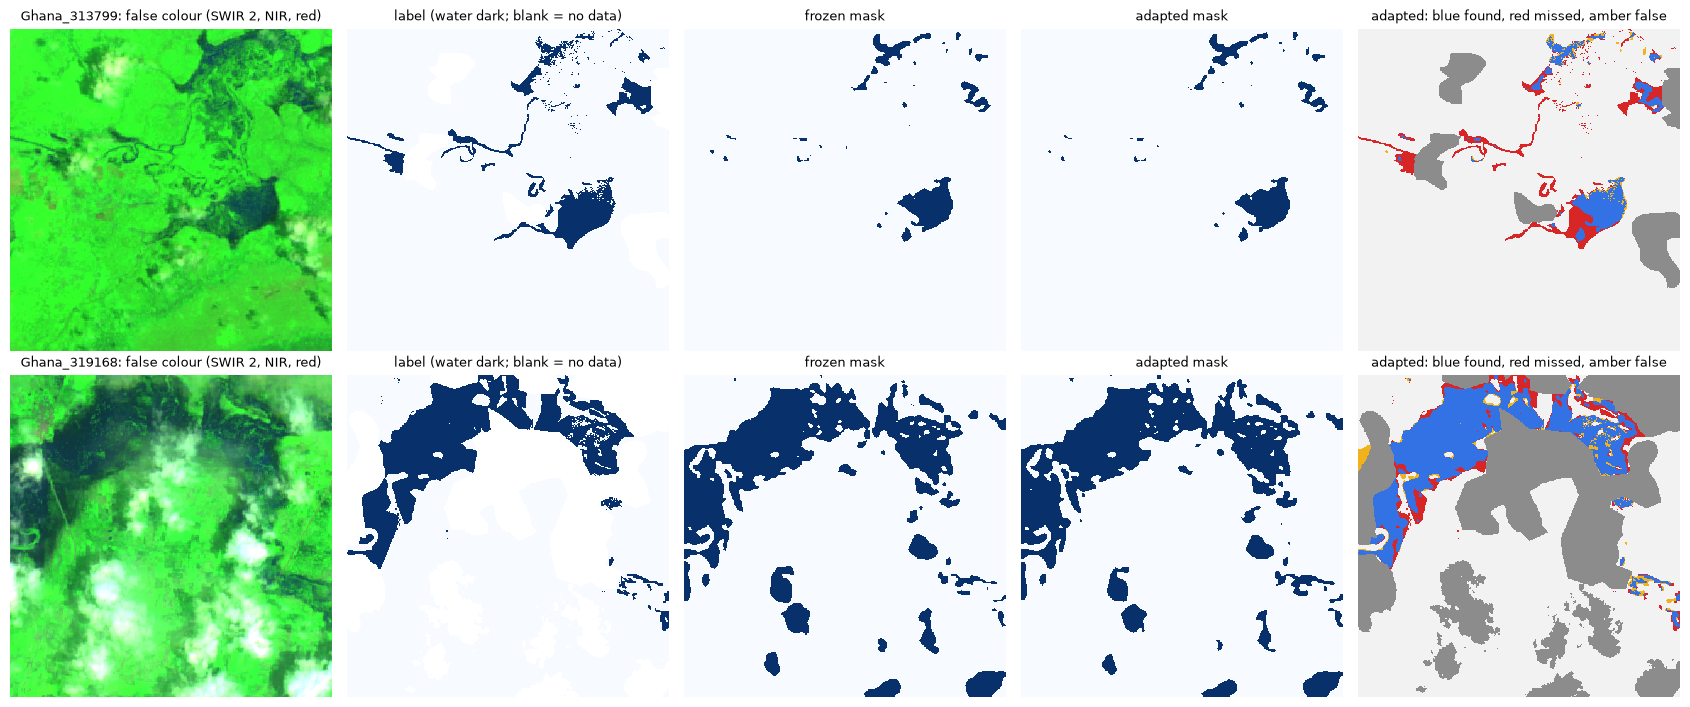

In [ ]:
adapted_test = pipe.evaluate(test_records)
adapted_val = pipe.evaluate(val_records)
comparison = {'split': 'exposed development test (12 chips; scored in every earlier run; descriptive only)'}
for key in ('mean_iou', 'accuracy', 'precision', 'recall', 'f1'):
    comparison[key] = {'baseline_no_water': frozen_test['baseline_no_water'][key], 'frozen': frozen_test['model'][key], 'adapted': adapted_test['model'][key]}
comparison['water_iou'] = {'baseline_no_water': frozen_test['baseline_no_water']['iou']['water'], 'frozen': frozen_test['model']['iou']['water'], 'adapted': adapted_test['model']['iou']['water']}
comparison['change_water_iou'] = round(adapted_test['model']['iou'][CLASS_NAMES[1]] - frozen_test['model']['iou'][CLASS_NAMES[1]], 4)
comparison['reading'] = 'descriptive: the exposed development test decides nothing; the endpoint is the fresh test (Section 8)'
for key, row in comparison.items():
    print({key: row})
print({'validation_water_iou': {'frozen': frozen_val['model']['iou']['water'], 'adapted': adapted_val['model']['iou']['water']}, 'validation_loss': {'frozen': adapt_result['history'][0]['val_loss'], 'kept_epoch': adapt_result['history'][adapt_result['best_epoch']]['val_loss']}})
evaluation_report = {
    'model': {'id': MODEL_ID, 'revision': MODEL_REVISION, 'key': MODEL_KEY},
    'data_source': data_source,
    'dataset': dataset_report,
    'frozen': {'exposed_development_test': frozen_test, 'validation': frozen_val},
    'adapted': {'exposed_development_test': adapted_test, 'validation': adapted_val},
    'comparison': comparison,
    'grid': {'on': grid_on, 'rows': grid_rows, 'selection': selection, 'grid_hash': GRID_HASH},
    'determinism': determinism,
    'adaptation': {k: v for k, v in adapt_result.items() if k not in ('history', 'trainable_names')},
    'history': adapt_result['history'],
    'adaptation_seconds': adapt_seconds,
}
atomic_write_json('outputs/prithvi_flood_segmentation_evaluation_report.json', evaluation_report)
# Contract integrity (not model quality): epoch 0 is a selection candidate, and re-scoring reproduces the kept epoch.
if adapt_result['history'][adapt_result['best_epoch']]['val_loss'] > adapt_result['history'][0]['val_loss']:
    raise RuntimeError('contract: the kept epoch has a higher validation loss than the frozen model, which epoch selection cannot produce')
if abs(adapted_val['model']['iou'][CLASS_NAMES[1]] - adapt_result['history'][adapt_result['best_epoch']]['val']['iou'][CLASS_NAMES[1]]) >= 1e-2:
    raise RuntimeError('contract: re-scoring the validation chips does not reproduce the kept epoch')
print({'report': 'outputs/prithvi_flood_segmentation_evaluation_report.json'})

# Two exposed development chips: false colour, label, frozen and adapted masks, and where the adapted model is right or wrong.
import matplotlib.pyplot as plt

shown = test_records[:2]
adapted_shown = pipe.predict(shown)['predictions']
fig, axes = plt.subplots(len(shown), 5, figsize=(17, 3.6 * len(shown)), squeeze=False)
for row, (record, frozen_pred, adapted_pred) in enumerate(zip(shown, frozen_predictions['predictions'], adapted_shown)):
    label, mask = record['label'], adapted_pred['mask']
    composite = np.clip(np.stack([record['image'][5], record['image'][3], record['image'][2]], axis=-1) / 0.4, 0.0, 1.0)
    errors = np.full(label.shape + (3,), 0.95)
    errors[(label == 1) & (mask == 1)] = (0.2, 0.45, 0.9)
    errors[(label == 1) & (mask == 0)] = (0.85, 0.15, 0.15)
    errors[(label == 0) & (mask == 1)] = (0.95, 0.7, 0.1)
    errors[label < 0] = (0.55, 0.55, 0.55)
    panels = (
        (composite, record.get('source_id', record['id']) + ': false colour (SWIR 2, NIR, red)'),
        (np.ma.masked_less(label, 0), 'label (water dark; blank = no data)'),
        (frozen_pred['mask'], 'frozen mask'),
        (mask, 'adapted mask'),
        (errors, 'adapted: blue found, red missed, amber false'),
    )
    for ax, (image, title) in zip(axes[row], panels):
        ax.imshow(image, cmap='Blues', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(title, fontsize=9)
        ax.axis('off')
fig.tight_layout()
plt.show()

**What to notice:** the `water_iou` row (baseline, frozen, adapted), `change_water_iou`, and the validation numbers beside it.

<details><summary>Check your reasoning</summary>No. In the evaluation of record the water IoU on these chips moved from 0.7301 to 0.7459 (+0.0158; F1 0.8440 → 0.8544, accuracy 0.9440 → 0.9468): recall rose from 0.776 to 0.8004 while precision fell from 0.9251 to 0.9164. These 12 chips were already read when the default learning rate was chosen, they come from events in the training split, and there is one seed and no interval; the change shows the contract ran and did no harm. The pre-registered fresh test in Section 8 is where a change is read, with an interval and a tolerance; in the evaluation of record this gain did not show up there.</details>

## 8. The pre-registered fresh test

The **fresh test** is 23 official Sen1Floods11 test chips that this notebook never scored: the test chips outside the sample that pass the same label filter (at least 60 % valid, 3 % water), minus the two upstream example chips shown in Section 9, pinned by size and SHA-256 (`FRESH_TEST_RECORDS`, digest `FRESH_POOL_DIGEST`). **Plainly:** they come from the same 8 flood events as the training data and 20 of the 23 lie within one chip width of a training or validation chip, so this measures *within-event generalisation to unseen chips*, not new events (the official Bolivia event, held out from everything, would be an out-of-event check; it is not used here).

**Reading rule (pre-registered).** One primary endpoint: the pooled water IoU of the selected system minus the frozen model on the fresh test, from unrounded per-chip confusion counts, with a paired bootstrap 95 % interval over chips (10 000 resamples, seed 0). The verdict is *improved* or *worse* only if the interval excludes 0 and the change is at least 0.02; otherwise *no detectable change*. With 23 correlated chips from 8 events the power is low: the expected verdict for a small fine-tuning effect is *no detectable change*, and the interval understates event-level uncertainty.

**Score-once.** The cell scores the fresh test only if every pre-registered setting holds — the pinned sample, epochs 4, batch 2, seed 0, the full grid and its selection, float16 on a **Tesla T4**, the determinism flags, the bootstrap — and re-checks, just before scoring, that the grid is complete and matches, that the model state is the selected system, and the fresh-pool digest. It resets to the pinned base to score the frozen model, then reloads the selected state and checks its fingerprint before scoring it. Any other run (CPU, another GPU, BYOD, a form edit, the optional activity, `DIMER_MASK_FRESH_TEST=1`) is **exploratory**: the fresh test is not fetched or scored, and a record of validation and the exposed development test goes to `outputs/score_once/prithvi_flood_segmentation_fresh_test_exploratory_<n>.json` with the settings that differ. The first completed scoring in a runtime is labelled *pre-registered evaluation (this runtime)*; a repeat is a *reproduction* (`_reproduction_<n>`). A runtime cannot know about other runtimes: the evaluation of record is the first hosted T4 run listed in `docs/release-verification.md`. It is recorded (19 October 2026), so every scoring here is a *reproduction*, and the cell prints `matches_record` with the fields that differ from it. A failed fetch, decode or check is not a look; once scoring completes it is a look, even if a later write fails. A look marker is kept beside the fresh-test cache (`weights/sen1floods11_fresh/score_once_look_marker.json`), so deleting `outputs/` or `outputs/score_once/` does **not** reset the look; the report and the ledger are written atomically. The cell prints `masked`, `preregistered` and `will_fetch_fresh_test` before anything is fetched, and `DIMER_MASK_FRESH_TEST` is re-read where the fresh test would be fetched and scored, so setting it in any cell before Section 8 masks the run.

**Predict before running:** will the interval exclude 0?

In [ ]:
MASKED = os.environ.get(MASK_ENV) == '1'  # re-read here; score_fresh_test and fetch_fresh_test re-read it again
device_name = torch.cuda.get_device_name(0) if pipe.device.startswith('cuda') else 'cpu'
run_settings = {
    'data_source': data_source,
    'splits': {'train': len(train_records), 'validation': len(val_records), 'exposed_development_test': len(test_records), 'fresh_test': len(FRESH_TEST_RECORDS)},
    'dataset_digest': dataset_manifest({'train': train_records, 'validation': val_records, 'test': test_records})['digest'],  # recomputed from the live records
    'fresh_pool_digest': fresh_pool_digest(),
    'epochs': adapt_result['epochs'],
    'batch_size': adapt_result['batch_size'],
    'seed': adapt_result['seed'],
    'grid': [{'name': n, 'lr': r[0]['lr'], 'trainable': r[0]['trainable']} for n, r in grid_runs.items()],
    'selection_margin': SELECTION_MARGIN,
    'precision': adapt_result['precision'],
    'device': device_name,
    'determinism': determinism_state(),
    'n_boot': N_BOOT,
    'boot_seed': BOOT_SEED,
    'masked': MASKED,
}
checks = {
    'grid_complete_and_matching': grid_on and [r['name'] for r in grid_rows] == [c['name'] for c in GRID] and select_config(grid_rows)['selected'] == selected_name and grid_hash(grid_rows, selected_name) == GRID_HASH,
    'model_is_selected_system': pipe.adapter is not None and state_fingerprint(pipe.model, adapt_result['trainable_names']) == SELECTED_FINGERPRINT,
    'fresh_pool_digest': fresh_pool_digest() == FRESH_POOL_DIGEST,
}

def score_fresh():
    fresh_records = fetch_fresh_test(cache_dir='weights/sen1floods11_fresh')  # a failure here is not a look
    try:
        restore_pinned_base(pipe)  # reset: the frozen model is recomputed, never taken from memory
        frozen = chip_confusions(pipe, fresh_records)
    finally:
        current = pipe.model.state_dict()
        pipe.model.load_state_dict({**current, **{k: v.to(current[k].device) for k, v in selected_state.items()}}, strict=True)
        pipe.model.eval()
        pipe.adapter = dict(adapt_result)
    if state_fingerprint(pipe.model, adapt_result['trainable_names']) != SELECTED_FINGERPRINT:
        raise RuntimeError('the reloaded state is not the selected system')
    selected = chip_confusions(pipe, fresh_records)
    return {'chips': [r['source_id'] for r in fresh_records], 'frozen': frozen, 'selected': selected}

exploratory_payload = {'validation_water_iou': {'frozen': frozen_val['model']['iou']['water'], 'adapted': adapted_val['model']['iou']['water']}, 'exposed_development_test': comparison, 'grid': grid_rows, 'selection': selection, 'grid_hash': GRID_HASH, 'determinism': run_settings['determinism'], 'device': device_name}
pre_check = preregistration_check(run_settings)
print({'masked': MASKED, 'preregistered': pre_check['preregistered'], 'will_fetch_fresh_test': pre_check['preregistered'] and all(checks.values()), 'settings_differing': pre_check['settings_differing']})  # before any fetch
try:
    fresh_result = score_fresh_test(settings=run_settings, checks=checks, score=score_fresh, score_dir='outputs/score_once', stem='prithvi_flood_segmentation', exploratory_payload=exploratory_payload, marker=LOOK_MARKER)
except Exception as exc:  # a failed fetch, decode or check BEFORE scoring completed: not a look; the rest of the notebook still runs
    fresh_result = {'test_look': 'not scored (failed before scoring completed; not a look)', 'error': str(exc)[:200]}
if fresh_result['test_look'] == LABEL_EXPLORATORY:
    print({'fresh_test': 'not scored (exploratory)', 'masked': MASKED, 'settings_differing': fresh_result['settings_differing'], 'record': fresh_result['file']})
elif 'bootstrap' in fresh_result:
    boot = fresh_result['bootstrap']
    print({'test_look': fresh_result['test_look'], 'chips': boot['n_chips'], 'frozen_water_iou': round(boot['frozen_water_iou'], 4), 'selected_water_iou': round(boot['selected_water_iou'], 4), 'change': round(boot['delta'], 4), 'ci95': [round(v, 4) for v in boot['ci95']], 'verdict': fresh_result['verdict'], 'report': fresh_result['file'], 'write_errors': fresh_result.get('write_errors', [])})
    comparison_to_record = compare_with_record(fresh_result, GRID_HASH, selected_name)  # None without a record
    if comparison_to_record is not None:
        print({'reproduction_of': comparison_to_record['record'], 'matches_record': comparison_to_record['matches_record'], 'differs': comparison_to_record['differs']})
else:
    print(fresh_result)

{'masked': False, 'preregistered': True, 'will_fetch_fresh_test': True, 'settings_differing': []}


{'test_look': 'reproduction', 'chips': 23, 'frozen_water_iou': 0.8815, 'selected_water_iou': 0.8816, 'change': 0.0, 'ci95': [-0.0024, 0.0021], 'verdict': 'no detectable change', 'report': 'outputs/score_once/prithvi_flood_segmentation_fresh_test_reproduction_1.json', 'write_errors': []}
{'reproduction_of': '2026-10-19 hosted Tesla T4, commit 9fd2b76', 'matches_record': True, 'differs': []}


**What to notice:** `test_look` (or why the fresh test was not scored and which settings differ), the `change` with its `ci95`, and the `verdict`.

<details><summary>Check your reasoning</summary>Probably not. On 23 within-event chips a fine-tuning effect of the size seen on the exposed development test (about 0.015) is below the 0.02 tolerance, so the pre-registered reading is *no detectable change* unless the interval is narrow and the change large. The evaluation of record (hosted T4, 19 October 2026, commit `9fd2b76`) read exactly that: frozen 0.8815, selected C0 0.8816, change 0.0, 95 % interval [−0.0024, 0.0021], *no detectable change*. The +0.0158 on the exposed development test did not show up on the 23 fresh chips: the frozen model is already strong on these in-distribution events (0.88), and 12 already-read chips overstated the gain. Your T4 run with the defaults is a *reproduction*; `matches_record: True` means the deterministic settings reproduced it, and `differs` names any field that did not. `docs/release-verification.md` lists the record and its reproductions. On CPU the cell reports *not scored (exploratory)* and names the settings that differ (`grid`, `precision`, `device`; and `masked` when `DIMER_MASK_FRESH_TEST=1` is set).</details>

## 9. Upstream example chips, artifact export and fresh reload

The selected system segments the three example chips that ship with the upstream repository (`India_900498`, `Spain_7370579`, `USA_430764` — 13-band Sentinel-2 L1C files reduced to the six bands). All three come from the upstream hand-labelled **test** split, so the packaged model never trained on them, but they are not new here: `USA_430764` is one of the 12 exposed development chips (the cell prints `also_a_sample_chip: 'test'` for it), and `India_900498` and `Spain_7370579` are excluded from the fresh test because they are shown here. Their upstream labels are not fetched, so the predicted water fraction and the written mask are a sanity check, not an evaluation.

`pipe.save_artifact` writes the trained tensors as `adapter.safetensors` into a temporary directory with a `manifest.json` (artifact format, base model id and revision, the digest of the converted base file, the adaptation scope, the tensor names, file size and SHA-256, training configuration and epoch history; OUT8) and renames it into place only when complete. `PrithviFloodPipeline.from_artifact` re-verifies the base file, checks the artifact manifest, scope and digest **before** deserialising, rebuilds the model and overlays the tensors — a fresh object from files, not the in-memory model (VER2). The cell asserts the same exposed-development positive-class IoU within 0.001 and score maps within 0.01 (VER4: float16 tolerances; on one device they are usually identical).

In [ ]:
import importlib.metadata
import io
import platform

import tifffile

example_dir = WEIGHTS_DIR / 'examples'
new_records = [{'id': path.stem, 'image': read_chip(path, band_indices=S2_L1C_BAND_INDICES), 'source': str(path.name)} for path in sorted(example_dir.glob('*.tif'))]
new_predictions = pipe.predict(new_records)
sample_role = {name: role for name, role, *_ in SAMPLE_RECORDS}  # the 44 sample chips by scene
for record, pred in zip(new_records, new_predictions['predictions']):
    buffer = io.BytesIO()
    tifffile.imwrite(buffer, pred['mask'])
    atomic_write_bytes(f'outputs/prithvi_flood_segmentation_mask_' + record['id'] + '.tif', buffer.getvalue())
    print({'chip': record['id'], 'water_fraction': pred['class_fraction']['water'], 'also_a_sample_chip': sample_role.get(record['id'].removesuffix('_S2Hand')), 'note': 'upstream test-split chip; no label fetched here'})
atomic_write_json('outputs/prithvi_flood_segmentation_predictions.json', {'model': new_predictions['model'], 'classes': new_predictions['classes'], 'decision_rule': new_predictions['decision_rule'], 'predictions': [{'id': p['id'], 'class_fraction': p['class_fraction']} for p in new_predictions['predictions']]})

artifact_dir = Path('outputs/prithvi_flood_segmentation_adapter')
pipe.save_artifact(artifact_dir, metadata={'tutorial': 'prithvi_flood_segmentation', 'data_source': data_source, 'selected_config': selected_name, 'grid_hash': GRID_HASH})
artifact_manifest = json.loads((artifact_dir / 'manifest.json').read_text(encoding='utf-8'))
print({'artifact': str(artifact_dir), 'format': artifact_manifest['format'], 'trainable': artifact_manifest['adapter']['trainable'], 'tensors': len(artifact_manifest['tensors']), 'bytes': artifact_manifest['files'][0]['bytes'], 'sha256': artifact_manifest['files'][0]['sha256'][:16] + '...'})

reloaded = PrithviFloodPipeline.from_artifact(artifact_dir, weights_dir=WEIGHTS_DIR, device=pipe.device)
reloaded_test = reloaded.evaluate(test_records)  # the exposed development test, never the fresh test
before = pipe.predict(test_records[:2])['predictions']
after = reloaded.predict(test_records[:2])['predictions']
parity = {'positive_iou_diff': round(abs(reloaded_test['model']['iou'][CLASS_NAMES[1]] - adapted_test['model']['iou'][CLASS_NAMES[1]]), 6), 'metrics_identical': reloaded_test['model'] == adapted_test['model'], 'max_abs_score_diff': max(float(np.abs(a['scores'] - b['scores']).max()) for a, b in zip(before, after))}
print({'reload_parity': parity, 'reloaded_best_epoch': reloaded.adapter['best_epoch']})
assert parity['positive_iou_diff'] < 1e-3 and parity['max_abs_score_diff'] < 1e-2

result_payload = {
    'notebook_source': NOTEBOOK_SOURCE,
    'repository_revision': NOTEBOOK_SOURCE['repository_revision'],
    'model': {**evaluation_report['model'], 'model_license': MODEL_LICENSE, 'device': pipe.device, 'device_name': device_name, 'source': pipe.source},
    'provenance': {
        'source_asset': [e for e in MANIFEST['files'] if e['path'] == SOURCE_CKPT_NAME],
        'pickle_audit_sha256': PICKLE_AUDIT_SHA256,
        'converted': verify_converted(WEIGHTS_DIR)['files'],
        'pickle_unpickled_once_for_conversion': True,
        'served_from_pickle': False,
        'remote_code_executed': False,
        'deterministic_patches': list(getattr(pipe.model, 'deterministic_patches', [])),
        'data_objects': 2 * len(SAMPLE_RECORDS),
        'fresh_test_objects': 2 * len(FRESH_TEST_RECORDS),
        'data_base_url': CORPUS_BASE_URL,
        'data_license': CORPUS_LICENSE,
    },
    'runtime': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': lightning.__version__, 'tifffile': tifffile.__version__, 'terratorch': importlib.metadata.version('terratorch')},
    'data_source': data_source,
    'determinism': run_settings['determinism'],
    'grid': {'on': grid_on, 'rows': grid_rows, 'selection': selection, 'grid_hash': GRID_HASH},
    'exposed_development_test': comparison,
    'fresh_test': {k: fresh_result.get(k) for k in ('test_look', 'settings_differing', 'bootstrap', 'verdict', 'file', 'error')},
    'artifact': {'dir': str(artifact_dir), 'sha256': artifact_manifest['files'][0]['sha256'], 'bytes': artifact_manifest['files'][0]['bytes']},
    'reload_parity': parity,
}
atomic_write_json('outputs/prithvi_flood_segmentation_result.json', result_payload)

print('outputs/:')
for path in sorted(Path('outputs').rglob('*')):
    if path.is_file():
        print(f'  - {path.as_posix()} ({path.stat().st_size / 1024:.1f} KB)')

{'chip': 'India_900498_S2Hand', 'water_fraction': 0.477, 'also_a_sample_chip': None, 'note': 'upstream test-split chip; no label fetched here'}
{'chip': 'Spain_7370579_S2Hand', 'water_fraction': 0.2823, 'also_a_sample_chip': None, 'note': 'upstream test-split chip; no label fetched here'}
{'chip': 'USA_430764_S2Hand', 'water_fraction': 0.0519, 'also_a_sample_chip': 'test', 'note': 'upstream test-split chip; no label fetched here'}


{'artifact': 'outputs/prithvi_flood_segmentation_adapter', 'format': 'org.valcorza.prithvi-flood-segmentation.adapter.v1', 'trainable': 'decoder', 'tensors': 46, 'bytes': 60333632, 'sha256': '9c85f77f263bbb66...'}


{'reload_parity': {'positive_iou_diff': 0.0, 'metrics_identical': True, 'max_abs_score_diff': 0.0}, 'reloaded_best_epoch': 2}


outputs/:
  - outputs/prithvi_flood_segmentation_adapter/adapter.safetensors (58919.6 KB)
  - outputs/prithvi_flood_segmentation_adapter/manifest.json (6.1 KB)
  - outputs/prithvi_flood_segmentation_evaluation_report.json (12.8 KB)
  - outputs/prithvi_flood_segmentation_mask_India_900498_S2Hand.tif (256.2 KB)
  - outputs/prithvi_flood_segmentation_mask_Spain_7370579_S2Hand.tif (256.2 KB)
  - outputs/prithvi_flood_segmentation_mask_USA_430764_S2Hand.tif (256.2 KB)
  - outputs/prithvi_flood_segmentation_predictions.json (0.7 KB)
  - outputs/prithvi_flood_segmentation_result.json (5.9 KB)
  - outputs/prithvi_flood_segmentation_sample_chip.tif (6144.4 KB)
  - outputs/prithvi_flood_segmentation_sample_label.tif (512.3 KB)
  - outputs/prithvi_flood_segmentation_sample_pairs.csv (2.2 KB)
  - outputs/score_once/prithvi_flood_segmentation_fresh_test_ledger.json (0.2 KB)
  - outputs/score_once/prithvi_flood_segmentation_fresh_test_reproduction_1.json (3.3 KB)


**What to notice:** the water fraction of the three example chips (and which one is an exposed development chip), the artifact's size and tensor count, and `reload_parity`.

<details><summary>Check your reasoning</summary>No labels are fetched for the example chips, so their water fractions are a sanity check only; `USA_430764` repeats an exposed development chip. In the recorded run the 46-tensor, about 60 MB adapter reloaded into a fresh pipeline with identical metrics (`positive_iou_diff` 0.0, `metrics_identical` True, `max_abs_score_diff` 0.0); identity was observed there, and the check itself is the float16 tolerance.</details>

## Interpretation and limits

**On the exposed development test**, 12 chips from the official test split, the packaged flood model finds water with an IoU near 0.73 (F1 0.84 in the recorded run) against a no-water baseline that scores 0, and its precision (0.93) is well above its recall (0.78): it misses some water rather than inventing it. The selected fine-tuning moved that IoU from 0.7301 to 0.7459 in the evaluation of record: recall rose from 0.776 to 0.8004 while precision fell from 0.9251 to 0.9164. Those chips are held out only at chip level and were read when the defaults were chosen, so they describe, they do not decide. **The fresh test** (Section 8) is the one pre-registered reading: 23 unseen chips from the same 8 events, a paired bootstrap interval and a 0.02 tolerance, scored only on a T4 under the pre-registered settings; it measures within-event generalisation, not new events, and its power is low. In the evaluation of record (hosted T4, 19 October 2026) it read *no detectable change* (frozen 0.8815, selected 0.8816, 95 % interval [−0.0024, 0.0021]): the exposed-test gain did not show up on fresh chips. **If you ran your own chips (BYOD),** the run is exploratory, the numbers describe your chips under the split printed as `split_rule` in Section 4, and the frozen numbers are the packaged model's. That is the claim: the adaptation contract runs end to end on real labelled multispectral chips with deterministic training, the pickle is audited and converted rather than served, and the 60 MB artifact reloads with outputs equal within the float16 tolerances (identical in the recorded run). It is not a claim that this sample improves the model — the model already trained on this dataset — nor that these chips measure its skill.

The numbers are sample-sanity evidence: pixel-pooled metrics that let large chips dominate, hand labels that carry their own uncertainty at water edges and under thin cloud, and validation chips that also steered the upstream early stopping. Nothing here measures the model on Sentinel-1, on scenes larger than a chip, or on regions, events and seasons outside Sen1Floods11.

Three things to carry to real data. **The input is Sentinel-2 L1C top-of-atmosphere reflectance in six bands:** blue, green, red, narrow NIR, SWIR 1, SWIR 2 in that order, reflectance in [0, 1], with the post-2022 +1000 DN offset removed and the 20 m bands on the 10 m grid. An L2A (surface reflectance) or HLS product, a different band order or a left-in offset is segmented without complaint and silently shifted from what the model learned. **Split by scene or event, not by chip:** neighbouring chips are near-duplicates, and a random split makes memorisation look like skill — which is why the exposed development and fresh tests here are labelled within-event. **Read the baseline first:** on a chip with 5 % water the no-water baseline is 95 % accurate; only the water IoU, precision and recall say whether the model did anything.

Successful execution proves that the recorded repository revision's pipeline modules, carried in this standalone notebook, can acquire and digest-verify a pickled upstream checkpoint, audit and convert it into safetensors without executing anything outside the audited allow-list, rebuild the model from the installed package, fetch and validate digest-pinned real labelled chips, run a pre-registered validation grid with deterministic kernels, evaluate against a baseline and the frozen model, apply fail-closed score-once rules to a fresh test, and emit the shown machine-readable artifacts — without the repository being reachable. It does **not** establish benchmark superiority, production fitness, or flood-mapping skill beyond the checks shown.

## Optional activity: Predict → Change → Run → Observe → Explain

This does not affect the default path. **Any change here makes the run exploratory:** Section 8 then does not fetch or score the fresh test and records validation and the exposed development test only, with the settings that differ.

1. **Predict:** with `TRAINABLE = 'decoder+last_block'` the last encoder block (27.7 M more parameters) is trained too. Will the kept epoch's validation loss be lower than with `'decoder'`? Write your guess down.
2. **Change** `RUN_GRID = False` and `TRAINABLE` in Section 6; keep `EPOCHS`, `LEARNING_RATE` and `BATCH_SIZE`.
3. **Run** Sections 6, 7, 8 and 9 in that order. Section 6 first restores the pinned base, so this is a fresh experiment rather than continued training, and epoch 0 is still the frozen model.
4. **Observe** `best_epoch`, the validation loss per epoch, the exposed-development `water_iou`, `precision` and `recall` rows, the Section 8 line *not scored (exploratory)*, and the figure.
5. **Explain** whether a larger trainable share helped on 24 chips whose distribution the model has already seen, and why an exploratory run must not look at the fresh test.

**Scope of a re-run:** every variation here is Sections 6 → 9; to return to the pre-registered settings, restore the defaults and run the same sections (on a T4 a second scoring in the same runtime is labelled a *reproduction*). Other variations to predict before running: raise `EPOCHS` (does the validation loss keep falling?) or set `LEARNING_RATE = 1e-4` (which epoch does validation selection keep, when the frozen epoch 0 is a candidate?). For your own chips set `USE_BYOD = True` and run from Section 4 onwards.

## Troubleshooting

- **Section 1 stops with "This notebook needs a Linux x86_64 runtime"** — you are on Windows, macOS or an ARM machine. Use Google Colab, Kaggle or a Linux x86_64 Jupyter server.
- **The uv wheel fails its size/SHA-256 check, or a download in Section 1 times out** — run Section 1 again; a complete environment built from the same lock is reused, an incomplete one is finished. If it repeats, the network is blocking or altering `files.pythonhosted.org` or `pypi.org`.
- **"The isolated environment's Python process exited"** — usually out of memory. Restart the session and choose **Run all**.
- **You re-ran Section 1 on its own** — nothing is lost: it keeps the running worker and every variable, so the cells after it keep working. After a session restart, run from the top.
- **Environment variables the notebook reads** — `DIMER_ISOLATED_ENV` (Section 1: where the isolated environment is built or reused; default `dimer_isolated_env_<lock digest>` in the working directory), `DIMER_NOTEBOOK_CI_PREINSTALLED=1` (Section 1: skip building it, for CI images that already have the pins) and `DIMER_MASK_FRESH_TEST=1` (Section 8: do not fetch or score the fresh test; the run is exploratory).
- **Section 3 reports a size or SHA-256 mismatch, or cannot reach the Hub** — the message names the file. Delete it from the snapshot folder Section 3 prints and run Section 3 again.
- **Section 3 stops during the pickle audit or conversion** — the audit refuses any global outside the allow-list and names it; the downloaded checkpoint is not the pinned one. Delete the snapshot folder and run Section 3 again.
- **Section 4 reports a size or SHA-256 mismatch for a chip** — the message names the object; a download from `storage.googleapis.com/sen1floods11` was cut short or altered. Run Section 4 again.
- **CUDA out of memory in Section 6** — another notebook holds the GPU. Restart the session, keep `BATCH_SIZE = 2`, and choose **Run all**; a smaller batch makes the run exploratory.
- **Section 6 raises "… does not have a deterministic implementation"** — an operation without a deterministic CUDA kernel was reached; the run stops rather than training non-deterministically. Report it with the printed operation name.
- **Section 8 prints "not scored (exploratory)"** — at least one pre-registered setting differs (it lists them: on CPU `device` and `grid`). This is expected off a T4.
- **Section 8 prints "failed before completion; not a look"** — the fresh chips could not be fetched or verified, or a pre-scoring check failed; nothing was recorded. Run Section 8 again.
- **Section 5 prints `restored_pinned_base`** — you re-ran it after Section 6; the adapted tensors were put back to the base. Re-run Sections 6–9 in order.
- **BYOD: a band, shape or label refusal** — the message names the rule; chips must be six-band 512 × 512 GeoTIFFs in the documented band order (13-band Sentinel-2 L1C files are reduced automatically) with masks of 0 / 1 / −1, and the dataset needs some water.
- **BYOD: "bring at least 7 labelled chips"** — the per-chip split keeps four chips for training, one for validation and two for test; add chips, or give a `split` column.
- **BYOD: "pairs.csv row … is listed but not in …" or "… is not a readable GeoTIFF"** — the message names the row and the file: add the file, correct the row, or save the file again as a GeoTIFF.
- **BYOD: a group or split refusal** — a group split needs at least three groups and four training chips; a `split` column needs `train`, `validation` and `test` each at least once.
- **BYOD: "BYOD_PATH … does not exist"** — the path is relative to the working directory printed in the message.
- **BYOD: "the upload dialog exists only in Google Colab"** — on Kaggle or Jupyter, put the zip (or folder) in the runtime and set `BYOD_PATH` to its path.
- **BYOD: "Upload exactly one .zip file"** — the dialog was cancelled or several files were chosen; run the cell again.

## Glossary

- **Sentinel-2 L1C / Sen1Floods11:** ESA's optical satellites; L1C is top-of-atmosphere reflectance (not atmospherically corrected); Sen1Floods11 is a dataset of flood-event chips with hand-drawn water labels over eleven events.
- **Reflectance and the six bands:** the fraction of sunlight reflected in blue, green, red, narrow NIR, SWIR 1 and SWIR 2; water is dark in NIR and SWIR.
- **Segmentation mask / ignore class:** one class per pixel; −1 marks cloud or no-data pixels that are excluded from training and scoring.
- **No-water baseline:** predicting *land* for every pixel; its accuracy equals the land fraction and its water IoU is 0.
- **IoU, precision, recall, F1:** overlap of predicted and true water; the share of predicted water that is real; the share of real water found; their harmonic mean.
- **Encoder, neck, decoder, head:** the ViT-L backbone; the pyramid that rescales its features; the UPerNet that upsamples them to pixels; the final two-class layer.
- **Frozen / adapted / pinned base:** the packaged model; the model after Section 6; the verified packaged weights every adaptation starts from (`restore_pinned_base` in Sections 5 and 6).
- **BatchNorm statistics:** running means and variances in the decoder; kept fixed because two-chip batches would corrupt them.
- **Validation-loss selection:** keeping the epoch with the lowest validation loss, with the frozen model as epoch 0.
- **Exposed development test / fresh test:** chips that were already looked at while choosing settings, reported for continuity; chips never scored before, read once under settings fixed in advance.
- **Pre-registration / exploratory / reproduction:** fixing the settings, endpoint and reading rule before looking; any run that differs from them; a later run with identical settings.
- **Deterministic training:** the same inputs and seed give bit-identical results; here by flags plus matmul versions of three operations.
- **Pickle audit / safetensors:** the upstream checkpoint is a pickle that could run code when loaded; it is statically checked against an allow-list and converted once to safetensors, a format that stores only tensors.
- **Isolated environment:** the separate Python environment Section 1 builds from the hash lock; every later cell runs there.

## Conclusion (your notes)

Complete these in your own words; the recorded run's values are in the **Check your reasoning** answers above.

- The frozen model's water IoU on the exposed development test was ___ against the no-water baseline's ___.
- The grid selected ___; on the fresh test the change was ___ with interval ___, which the reading rule calls ___.
- The number I would not trust on its own is ___, because ___.
- Before adapting on my own chips I would check the product level, band order and offset, split by ___, and compare against ___.

## References

[1] D. Szwarcman, S. Roy, P. Fraccaro, et al., "Prithvi-EO-2.0: A versatile multi-temporal foundation model for Earth observation applications," arXiv:2412.02732, 2024. https://arxiv.org/abs/2412.02732

[2] D. Bonafilia, B. Tellman, T. Anderson, and E. Issenberg, "Sen1Floods11: A georeferenced dataset to train and test deep learning flood algorithms for Sentinel-1," in *Proc. IEEE/CVF CVPR Workshops*, 2020. https://github.com/cloudtostreet/Sen1Floods11

[3] IBM, "TerraTorch," GitHub repository. https://github.com/IBM/terratorch

[4] IBM and NASA, "Prithvi-EO-2.0-300M-TL-Sen1Floods11," Hugging Face model repository, revision `91ce9d38086a80b078a192b374df758b8855b732`. https://huggingface.co/ibm-nasa-geospatial/Prithvi-EO-2.0-300M-TL-Sen1Floods11

[5] European Space Agency, "Sentinel-2 processing baseline 04.00 (radiometric offset)," Sentinel Online. https://sentinels.copernicus.eu/web/sentinel/technical-guides/sentinel-2-msi/processing-baseline

[6] K. Valcorza, "prithvi-flood-segmentation-pipeline: README, model card, weights notes and pre-registration," GitHub. https://github.com/kurtvalcorza/prithvi-flood-segmentation-pipeline/blob/main/MODEL_CARD.md

[7] DIMER Notebook Specification 2.5 and Model Card Specification 1.1 (fleet specs in the ml-worker repository)